In [7]:
# ============================================================
# SECTION 1.1 — IMPORTS AND ENVIRONMENT
# ============================================================

import os, sys, json, math, random, warnings, time
from pathlib import Path
from datetime import datetime

# ---- Numerical / data ----
import numpy as np
import pandas as pd

# ---- Plotting ----
import matplotlib.pyplot as plt
import seaborn as sns

# ---- Scikit-learn ----
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler, OrdinalEncoder, OneHotEncoder, PowerTransformer
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, roc_auc_score, average_precision_score,
    brier_score_loss, confusion_matrix, roc_curve,
    precision_recall_curve
)
from sklearn.model_selection import StratifiedKFold

# ---- Imbalanced-learn ----
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, SMOTENC, RandomOverSampler
from imblearn.combine import SMOTETomek
from imblearn.under_sampling import RandomUnderSampler

# ---- Gradient boosting libraries ----
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# ---- TensorFlow / Keras ----
import tensorflow as tf
from tensorflow import keras

# ---- SHAP (optional; checked at runtime) ----
try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("SHAP not installed — Section 12 will be skipped.")

# ---- Statistical tests ----
from scipy.stats import wilcoxon, friedmanchisquare
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

# ---- Reproducibility: env vars must be set BEFORE TF import effects ----
os.environ["PYTHONHASHSEED"]            = "42"
os.environ["TF_DETERMINISTIC_OPS"]      = "1"
os.environ["TF_CUDNN_DETERMINISTIC"]    = "1"
os.environ["OMP_NUM_THREADS"]           = "1"
os.environ["MKL_NUM_THREADS"]           = "1"

# ---- Suppress noise ----
warnings.filterwarnings("ignore")

print("Python      :", sys.version.split()[0])
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("sklearn     :", __import__("sklearn").__version__)
print("xgboost     :", __import__("xgboost").__version__)
print("lightgbm    :", __import__("lightgbm").__version__)
print("catboost    :", __import__("catboost").__version__)
print("tensorflow  :", tf.__version__)
if SHAP_AVAILABLE:
    print("shap        :", shap.__version__)

Python      : 3.10.0
NumPy       : 2.2.6
pandas      : 2.3.3
sklearn     : 1.7.2
xgboost     : 1.7.6
lightgbm    : 4.7.0
catboost    : 1.2.10
tensorflow  : 2.21.0
shap        : 0.49.1


In [8]:
# ============================================================
# SECTION 1.2 — GLOBAL SEEDS AND CONSTANTS
# ============================================================

RANDOM_STATE = 42
SEED         = 42

# Reproducibility
random.seed(SEED)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# ---- Model / strategy catalogues ----
MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost",
    "LightGBM",
    "CatBoost",
    "Artificial Neural Network",
]

MODEL_DIRS = {
    "Logistic Regression":       "logistic_regression",
    "Random Forest":             "random_forest",
    "XGBoost":                   "xgboost",
    "LightGBM":                  "lightgbm",
    "CatBoost":                  "catboost",
    "Artificial Neural Network": "artificial_neural_network",
}

IMBALANCE_STRATEGIES = [
    "Native",
    "Class Weighted",
    "SMOTE",
    "SMOTETomek",
    "Random Undersampling",
    "Random Oversampling",
]

TREE_MODELS = {"Random Forest", "XGBoost", "LightGBM", "CatBoost"}

# ---- Rolling design ----
MIN_TRAIN_YEARS = 5

# ---- Primary metric for model selection ----
# Chosen metric used to pick the "best strategy per model".
# Alternatives: "f1_mean", "roc_auc_mean", "pr_auc_mean".
PRIMARY_RANK_METRIC = "pr_auc_mean"

# ---- Reporting ----
N_BOOTSTRAP = 1000           # firm-level bootstrap resamples

print("RANDOM_STATE         :", RANDOM_STATE)
print("SEED                 :", SEED)
print("MIN_TRAIN_YEARS      :", MIN_TRAIN_YEARS)
print("PRIMARY_RANK_METRIC  :", PRIMARY_RANK_METRIC)
print("Models               :", len(MODEL_NAMES))
print("Strategies           :", len(IMBALANCE_STRATEGIES))
print("Expected total fits  :", "13 windows × 6 models × 6 strategies = 468")

RANDOM_STATE         : 42
SEED                 : 42
MIN_TRAIN_YEARS      : 5
PRIMARY_RANK_METRIC  : pr_auc_mean
Models               : 6
Strategies           : 6
Expected total fits  : 13 windows × 6 models × 6 strategies = 468


In [9]:
# ============================================================
# SECTION 1.3 — FOLDER STRUCTURE
# ============================================================

BASE = Path("Rolling_results_now")

# ---- Top-level folders ----
PLOTS       = BASE / "plots"
TABLES      = BASE / "tables"
META        = BASE / "metadata"
DIAG_DIR    = BASE / "diag_dir"
RAW_DIR     = BASE / "raw_dir"
CAL_DIR     = BASE / "cal_dir"
SHAP_DIR    = BASE / "shap_dir"

# ---- Per-model subfolders (plots + tables) ----
for sub in MODEL_DIRS.values():
    (PLOTS  / sub).mkdir(parents=True, exist_ok=True)
    (TABLES / sub).mkdir(parents=True, exist_ok=True)

# ---- Comparative / shared folders ----
COMPARATIVE    = PLOTS  / "comparative"
CM_DIR         = COMPARATIVE / "confusion_matrices"
TABLES_COMP    = TABLES / "comparative"
MODEL_CARDS    = TABLES / "model_cards"

for d in [
    BASE, PLOTS, TABLES, META, DIAG_DIR, RAW_DIR, CAL_DIR, SHAP_DIR,
    COMPARATIVE, CM_DIR, TABLES_COMP, MODEL_CARDS,
]:
    d.mkdir(parents=True, exist_ok=True)

print("Folder tree ready under:", BASE.resolve())
print()
for p in sorted(BASE.rglob("*")):
    if p.is_dir():
        print(" ", p.relative_to(BASE))

Folder tree ready under: C:\Users\irvin\Documents\New folder\Dissertation\Datasets\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now_1\Rolling_results_now

  cal_dir
  diag_dir
  metadata
  plots
  plots\artificial_neural_network
  plots\catboost
  plots\comparative
  plots\comparative\confusion_matrices
  plots\lightgbm
  plots\logistic_regression
  plots\random_forest
  plots\xgboost
  raw_dir
  shap_dir
  tables
  tables\artificial_neural_network
  tables\catboost
  tables\comparative
  tables\lightgbm
  tables\logistic_regression
  tables\model_cards
  tables\random_forest
  tables\xgboost


In [10]:
# ============================================================
# SECTION 1.4 — ENVIRONMENT LOCKFILE
# ============================================================

import subprocess

# ---- pip freeze ----
try:
    freeze = subprocess.run(
        [sys.executable, "-m", "pip", "freeze"],
        capture_output=True, text=True, check=True,
    ).stdout
    (META / "pip_freeze.txt").write_text(freeze, encoding="utf-8")
    print("✓ pip freeze written to", META / "pip_freeze.txt")
except Exception as e:
    print("✗ pip freeze failed:", e)

# ---- Environment summary JSON ----
env_meta = {
    "timestamp"     : datetime.now().isoformat(timespec="seconds"),
    "python"        : sys.version,
    "numpy"         : np.__version__,
    "pandas"        : pd.__version__,
    "sklearn"       : __import__("sklearn").__version__,
    "xgboost"       : __import__("xgboost").__version__,
    "lightgbm"      : __import__("lightgbm").__version__,
    "catboost"      : __import__("catboost").__version__,
    "tensorflow"    : tf.__version__,
    "shap"          : (shap.__version__ if SHAP_AVAILABLE else None),
    "random_state"  : RANDOM_STATE,
    "seed"          : SEED,
    "n_bootstrap"   : N_BOOTSTRAP,
    "primary_metric": PRIMARY_RANK_METRIC,
    "min_train_years": MIN_TRAIN_YEARS,
}

with open(META / "environment.json", "w", encoding="utf-8") as f:
    json.dump(env_meta, f, indent=2)

print("✓ environment.json written to", META / "environment.json")
print()
print(json.dumps(env_meta, indent=2))

✓ pip freeze written to Rolling_results_now\metadata\pip_freeze.txt
✓ environment.json written to Rolling_results_now\metadata\environment.json

{
  "timestamp": "2026-10-29T15:24:57",
  "python": "3.10.0 (tags/v3.10.0:b494f59, Oct  4 2021, 19:00:18) [MSC v.1929 64 bit (AMD64)]",
  "numpy": "2.2.6",
  "pandas": "2.3.3",
  "sklearn": "1.7.2",
  "xgboost": "1.7.6",
  "lightgbm": "4.7.0",
  "catboost": "1.2.10",
  "tensorflow": "2.21.0",
  "shap": "0.49.1",
  "random_state": 42,
  "seed": 42,
  "n_bootstrap": 1000,
  "primary_metric": "pr_auc_mean",
  "min_train_years": 5
}


In [11]:
# Verify folders exist
assert BASE.exists()
assert PLOTS.exists()
assert TABLES_COMP.exists()
assert CM_DIR.exists()
assert MODEL_CARDS.exists()
assert all((PLOTS / m).exists() for m in MODEL_DIRS.values())
assert all((TABLES / m).exists() for m in MODEL_DIRS.values())

# Verify constants
assert len(MODEL_NAMES) == 6
assert len(IMBALANCE_STRATEGIES) == 6
assert set(MODEL_DIRS.keys()) == set(MODEL_NAMES)

print("✓ Section 1 complete. Ready for Section 2.")

✓ Section 1 complete. Ready for Section 2.


In [12]:
# ============================================================
# SECTION 2.1 — LOAD AND CLEAN RAW DATA
# ============================================================

DATA_PATH = Path("american_bankruptcy_macro.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)

# ---- Column normalisation ----
if "fyear" in df.columns and "year" not in df.columns:
    df = df.rename(columns={"fyear": "year"})

# ---- Type coercion ----
df["year"] = pd.to_numeric(df["year"], errors="raise").astype(int)
df["status_label"] = (
    df["status_label"].astype(str).str.strip().str.lower()
)
df["company_name"] = df["company_name"].astype(str).str.strip()

# ---- Deterministic ordering ----
df = df.sort_values(["company_name", "year"]).reset_index(drop=True)

print("Dataset path   :", DATA_PATH.resolve())
print("Shape          :", df.shape)
print("Unique firms   :", df["company_name"].nunique())
print("Year range     :", df["year"].min(), "→", df["year"].max())
print("Status labels  :", df["status_label"].value_counts().to_dict())
print()
print("Dtypes (head):")
print(df.dtypes.head(10))

Dataset path   : C:\Users\irvin\Documents\New folder\Dissertation\Datasets\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now_1\american_bankruptcy_macro.csv
Shape          : (78682, 36)
Unique firms   : 8971
Year range     : 1999 → 2018
Status labels  : {'alive': 73462, 'failed': 5220}

Dtypes (head):
company_name     object
year              int64
status_label     object
X1              float64
X2              float64
X3              float64
X4              float64
X5              float64
X6              float64
X7              float64
dtype: object


In [13]:
# ============================================================
# SECTION 2.2 — DETECT LABELLING CONVENTION
# ============================================================
# Firm-year labelled: a failed firm has both 'alive' and 'failed' rows
#                     across different years.
# Firm-level labelled: a failed firm has a single row, or all its rows
#                      carry the same 'failed' label.

failed_firms = df.loc[df.status_label.eq("failed"), "company_name"].unique()

transition_firms = []
same_label_firms = []

for firm in failed_firms:
    labels = (
        df.loc[df.company_name.eq(firm)]
          .sort_values("year")["status_label"]
          .tolist()
    )
    if "alive" in labels and "failed" in labels:
        first_failed = labels.index("failed")
        if "alive" in labels[:first_failed]:
            transition_firms.append(firm)
    else:
        same_label_firms.append(firm)

LABELLING_CONVENTION = (
    "firm_year" if len(transition_firms) > 0 else "firm_level"
)

print("Failed firms detected           :", len(failed_firms))
print("Transition firms (alive→failed) :", len(transition_firms))
print("Same-label failed firms         :", len(same_label_firms))
print()
print("Detected labelling convention   :", LABELLING_CONVENTION)

Failed firms detected           : 609
Transition firms (alive→failed) : 0
Same-label failed firms         : 609

Detected labelling convention   : firm_level


In [14]:
# ============================================================
# SECTION 2.3 — ONE-YEAR-AHEAD TARGET CONSTRUCTION
# ============================================================

if LABELLING_CONVENTION == "firm_year":
    # Failure year = earliest year with status 'failed'
    failure_years = (
        df.loc[df.status_label.eq("failed")]
          .groupby("company_name")["year"]
          .min()
          .rename("failure_year")
    )
else:
    # Failure year = last observed year for a failed firm
    failure_years = (
        df.loc[df.company_name.isin(failed_firms)]
          .groupby("company_name")["year"]
          .max()
          .rename("failure_year")
    )

df_target = df.merge(failure_years, on="company_name", how="left")

# Target: 1 if this year is exactly one year before failure
df_target["target_1yr"] = (
    df_target["failure_year"].eq(df_target["year"] + 1)
).astype(int)

# Keep only information years that can predict a known outcome
df_target = df_target[
    df_target.failure_year.isna()
    | (df_target.year < df_target.failure_year)
].copy()

# Restrict to years with knowable outcome (prediction_year <= 2018)
df_target = df_target[df_target.year <= 2017].copy()
df_target["prediction_year"] = df_target.year + 1

print("Modelling shape        :", df_target.shape)
print("Target counts          :", df_target.target_1yr.value_counts().to_dict())
print("Positive prevalence    :", round(df_target.target_1yr.mean(), 6))
print()
print("Failures by prediction year:")
print(
    df_target.groupby("prediction_year").target_1yr.sum().astype(int).to_string()
)

Modelling shape        : (75386, 39)
Target counts          : {0: 74792, 1: 594}
Positive prevalence    : 0.007879

Failures by prediction year:
prediction_year
2000     7
2001    10
2002    16
2003    29
2004    45
2005    40
2006    50
2007    57
2008    57
2009    22
2010    35
2011    24
2012    25
2013    28
2014    33
2015    33
2016    28
2017    19
2018    36


✓ All 594 positive events are exactly 1 year before failure.


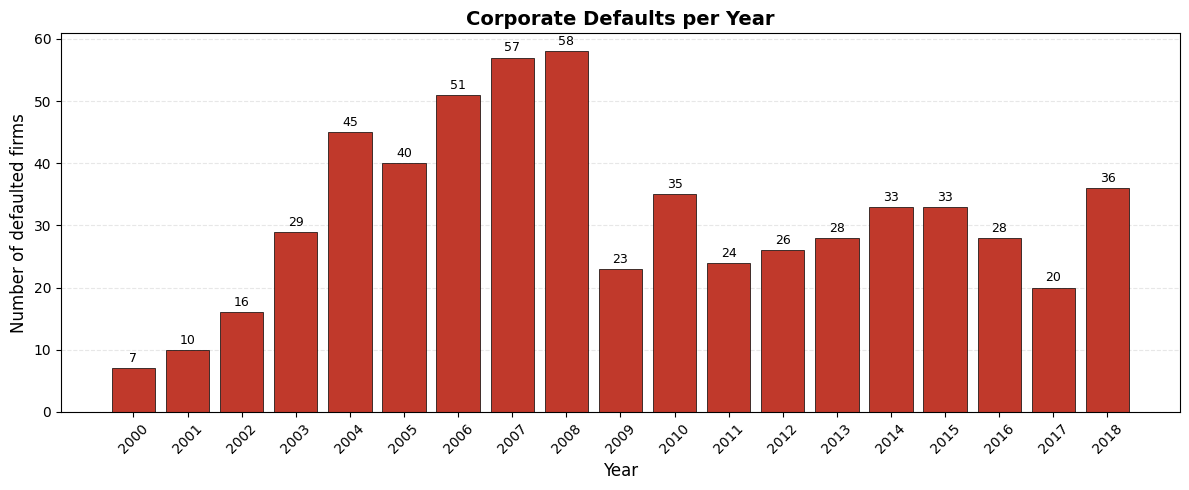

✓ Defaults-per-year table saved.


In [15]:
# ============================================================
# SECTION 2.4 — TARGET SANITY TABLES AND PLOT
# ============================================================

# ---- Event audit table ----
events = df_target.loc[
    df_target.target_1yr.eq(1),
    ["company_name", "year", "prediction_year", "failure_year", "status_label"],
].copy()
events.to_csv(DIAG_DIR / "target_events.csv", index=False)

# ---- Assert every positive event is exactly 1 year before failure ----
if len(events) > 0:
    gap = (events["failure_year"] - events["year"]).astype(int)
    assert (gap == 1).all(), "Some positive events are not 1 year before failure."
    print(f"✓ All {len(events)} positive events are exactly 1 year before failure.")

# ---- Defaults per year bar chart ----
defaults_per_year = (
    df_target.dropna(subset=["failure_year"])
             .groupby("failure_year")["company_name"]
             .nunique()
             .sort_index()
)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(
    defaults_per_year.index.astype(int),
    defaults_per_year.values,
    color="#c0392b", edgecolor="black", linewidth=0.5,
)
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2,
            h + 0.5, f"{int(h)}",
            ha="center", va="bottom", fontsize=9)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Number of defaulted firms", fontsize=12)
ax.set_title("Corporate Defaults per Year", fontsize=14, fontweight="bold")
ax.set_xticks(defaults_per_year.index.astype(int))
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3, linestyle="--")
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(DIAG_DIR / "defaults_per_year.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

# ---- Save summary table ----
defaults_per_year.to_frame("n_firms_failed").to_csv(
    TABLES_COMP / "defaults_per_year.csv"
)
print("✓ Defaults-per-year table saved.")

In [16]:
# ============================================================
# SECTION 2.5 — ROLLING-ORIGIN SPLIT DESIGN
# ============================================================

start    = int(df_target["year"].min())     # 1999
max_info = int(df_target["year"].max())     # 2017

rolling_splits = []

for test_year in range(start + MIN_TRAIN_YEARS + 1, max_info + 1):
    rolling_splits.append({
        "train_start":           start,
        "train_end":             test_year - 2,
        "validation_year":       test_year - 1,
        "test_information_year": test_year,
        "prediction_year":       test_year + 1,
    })

rolling_splits = pd.DataFrame(rolling_splits)

# Safety: drop any split whose prediction_year exceeds available data
rolling_splits = rolling_splits[
    rolling_splits["prediction_year"] <= int(df_target["prediction_year"].max())
].reset_index(drop=True)

rolling_splits.to_csv(DIAG_DIR / "rolling_splits.csv", index=False)

print(f"Total rolling windows: {len(rolling_splits)}")
print()
print(rolling_splits.to_string(index=False))

Total rolling windows: 13

 train_start  train_end  validation_year  test_information_year  prediction_year
        1999       2003             2004                   2005             2006
        1999       2004             2005                   2006             2007
        1999       2005             2006                   2007             2008
        1999       2006             2007                   2008             2009
        1999       2007             2008                   2009             2010
        1999       2008             2009                   2010             2011
        1999       2009             2010                   2011             2012
        1999       2010             2011                   2012             2013
        1999       2011             2012                   2013             2014
        1999       2012             2013                   2014             2015
        1999       2013             2014                   2015             2016
 

In [17]:
# ============================================================
# SECTION 2.6 — PER-FOLD PREVALENCE CHECK
# ============================================================

fold_summary = []

for _, sp in rolling_splits.iterrows():
    tr = df_target[df_target["year"] <= int(sp.train_end)]
    va = df_target[df_target["year"] == int(sp.validation_year)]
    te = df_target[df_target["year"] == int(sp.test_information_year)]

    fold_summary.append({
        "test_information_year": int(sp.test_information_year),
        "prediction_year":       int(sp.prediction_year),

        "train_n":               len(tr),
        "train_positives":       int(tr.target_1yr.sum()),
        "train_prevalence":      tr.target_1yr.mean(),

        "val_n":                 len(va),
        "val_positives":         int(va.target_1yr.sum()),
        "val_prevalence":        va.target_1yr.mean(),

        "test_n":                len(te),
        "test_positives":        int(te.target_1yr.sum()),
        "test_prevalence":       te.target_1yr.mean(),
    })

fold_summary = pd.DataFrame(fold_summary)
fold_summary.to_csv(TABLES_COMP / "fold_prevalence.csv", index=False)

print(fold_summary.round(4).to_string(index=False))

# ---- Warnings ----
low_test = fold_summary[fold_summary["test_positives"] < 5]
if len(low_test) > 0:
    print()
    print("⚠ Folds with very few test positives (metric instability):")
    print(low_test[["test_information_year", "test_positives"]].to_string(index=False))
else:
    print()
    print("✓ Every fold has at least 5 test positives.")

zero_test = fold_summary[fold_summary["test_positives"] == 0]
if len(zero_test) > 0:
    raise ValueError(
        "Some test folds contain ZERO positives — "
        "metrics cannot be computed. Investigate the target construction."
    )

 test_information_year  prediction_year  train_n  train_positives  train_prevalence  val_n  val_positives  val_prevalence  test_n  test_positives  test_prevalence
                  2005             2006    24433              107            0.0044   4302             40          0.0093    4165              50           0.0120
                  2006             2007    28735              147            0.0051   4165             50          0.0120    4077              57           0.0140
                  2007             2008    32900              197            0.0060   4077             57          0.0140    3950              57           0.0144
                  2008             2009    36977              254            0.0069   3950             57          0.0144    3799              22           0.0058
                  2009             2010    40927              311            0.0076   3799             22          0.0058    3720              35           0.0094
                  2010

Firm-level event rate per year:
 information_year  prediction_year  firms_observed  firms_failing  event_rate
             1999             2000            5305              7      0.0013
             2000             2001            5219             10      0.0019
             2001             2002            4887             16      0.0033
             2002             2003            4634             29      0.0063
             2003             2004            4388             45      0.0103
             2004             2005            4302             40      0.0093
             2005             2006            4165             50      0.0120
             2006             2007            4077             57      0.0140
             2007             2008            3950             57      0.0144
             2008             2009            3799             22      0.0058
             2009             2010            3720             35      0.0094
             2010             20

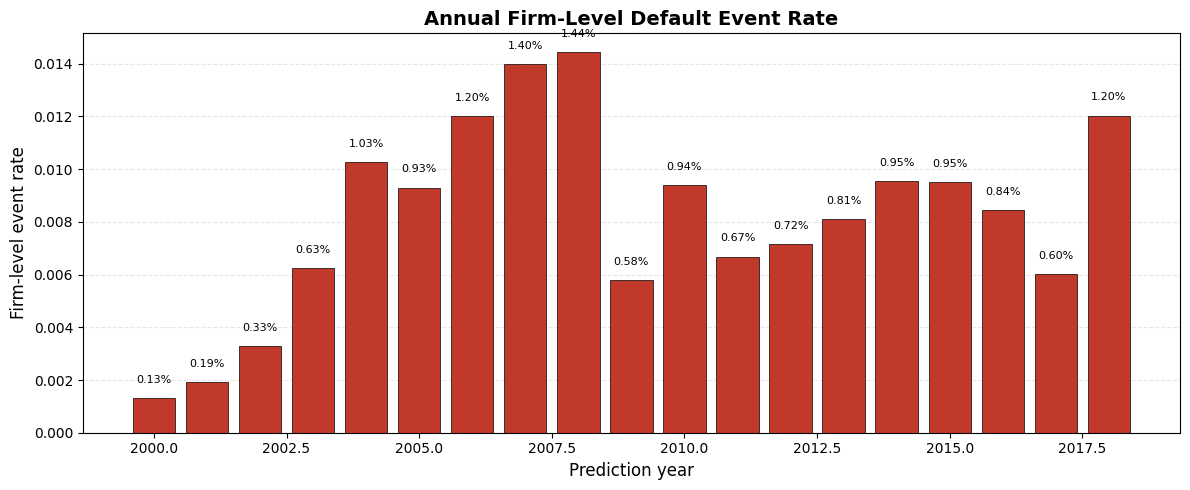

In [18]:
# ============================================================
# SECTION 2.6b — FIRM-LEVEL EVENT RATE PER YEAR
# ============================================================

# For each prediction year, count:
#   - firms observed in the information year (denominator)
#   - firms failing in the prediction year (numerator)

event_rate_rows = []

for year in sorted(df_target["prediction_year"].unique()):
    info_year = int(year) - 1

    # Firms observed in the information year
    firms_observed = df_target.loc[
        df_target.year.eq(info_year), "company_name"
    ].nunique()

    # Firms failing in the prediction year
    firms_failing = df_target.loc[
        df_target.prediction_year.eq(year) & df_target.target_1yr.eq(1),
        "company_name",
    ].nunique()

    event_rate_rows.append({
        "information_year": info_year,
        "prediction_year":  int(year),
        "firms_observed":   firms_observed,
        "firms_failing":    firms_failing,
        "event_rate":       firms_failing / firms_observed
                            if firms_observed > 0 else np.nan,
    })

event_rate_df = pd.DataFrame(event_rate_rows)
event_rate_df.to_csv(TABLES_COMP / "firm_level_event_rate.csv", index=False)

print("Firm-level event rate per year:")
print(event_rate_df.round(4).to_string(index=False))
print()
print(f"Mean event rate : {event_rate_df.event_rate.mean():.4f}")
print(f"Median          : {event_rate_df.event_rate.median():.4f}")
print(f"Min / Max       : {event_rate_df.event_rate.min():.4f} / "
      f"{event_rate_df.event_rate.max():.4f}")

# ---- Plot ----
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(
    event_rate_df.prediction_year,
    event_rate_df.event_rate,
    color="#c0392b", edgecolor="black", linewidth=0.5,
)
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2,
            h + 0.0005, f"{h:.2%}",
            ha="center", va="bottom", fontsize=8)

ax.set_xlabel("Prediction year", fontsize=12)
ax.set_ylabel("Firm-level event rate", fontsize=12)
ax.set_title("Annual Firm-Level Default Event Rate",
             fontsize=14, fontweight="bold")
ax.grid(axis="y", alpha=0.3, linestyle="--")
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(DIAG_DIR / "firm_level_event_rate.png",
            dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [19]:
# ============================================================
# SECTION 3.1 — RATIO FEATURE ENGINEERING
# ============================================================

def add_ratio_features(d):
    """
    Add five ratio features. Divisions by zero become NaN and are
    handled by the preprocessor's median imputer.
    Computed row-wise; no grouped / rolling aggregation.
    """
    d = d.copy()
    d["roa"]           = d["X6"]  / d["X10"].replace(0, np.nan)
    d["current_ratio"] = d["X1"]  / d["X14"].replace(0, np.nan)
    d["debt_to_asset"] = d["X17"] / d["X10"].replace(0, np.nan)
    d["net_margin"]    = d["X6"]  / d["X9"].replace(0, np.nan)
    d["ebitda_margin"] = d["X4"]  / d["X9"].replace(0, np.nan)
    return d

# ---- Guard against double-adding ratios if this cell is re-run ----
RATIO_FEATURES = ["roa", "current_ratio", "debt_to_asset",
                  "net_margin", "ebitda_margin"]

if not all(c in df_target.columns for c in RATIO_FEATURES):
    df_target = add_ratio_features(df_target)
    print("✓ Ratio features added.")
else:
    print("✓ Ratio features already present.")

print("Ratio feature stats:")
print(df_target[RATIO_FEATURES].describe().round(4).to_string())
print()
print("Missing counts (from div-by-zero):")
print(df_target[RATIO_FEATURES].isna().sum().to_string())

✓ Ratio features added.
Ratio feature stats:
               roa  current_ratio  debt_to_asset    net_margin  ebitda_margin
count   75386.0000   7.538600e+04     75386.0000  5.652400e+04   5.652400e+04
mean      -44.3236   1.648074e+03       711.4139 -5.592550e+02   1.773977e+03
std      1982.9994   1.444836e+05      2917.2610  2.290887e+04   2.430373e+04
min   -131066.6667  -1.561453e+05     -1388.6919 -2.227714e+06  -4.107143e+02
25%        -0.1783   2.329000e-01         1.4398 -5.020000e-02   1.000000e-04
50%         0.1148   4.623000e-01         4.1343  3.193000e-01   4.805000e-01
75%         0.6180   1.325400e+00         7.8349  1.839600e+00   5.061800e+00
max    434500.0000   3.787120e+07    452600.0000  7.439000e+05   1.636300e+06

Missing counts (from div-by-zero):
roa                  0
current_ratio        0
debt_to_asset        0
net_margin       18862
ebitda_margin    18862


In [20]:
# ============================================================
# SECTION 3.2 — FINAL 38-FEATURE SPACE
# ============================================================

EXCLUDE = {
    "company_name", "year", "status_label", "failure_year",
    "target", "target_1yr", "prediction_year",
}

feature_columns = [c for c in df_target.columns if c not in EXCLUDE]

categorical_features = [c for c in ["Division", "MajorGroup"]
                        if c in feature_columns]
numeric_features = [c for c in feature_columns
                    if c not in categorical_features]

# ---- Coerce categoricals to string (safe for imputation / ordinal) ----
for c in categorical_features:
    df_target[c] = df_target[c].astype(str)

# ---- Replace infinities (from ratios) with NaN for imputation ----
df_target[numeric_features] = df_target[numeric_features].replace(
    [np.inf, -np.inf], np.nan
)

print(f"Numeric features    : {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)} → {categorical_features}")
print(f"Total features      : {len(feature_columns)}")
print()

assert len(feature_columns) == 38, \
    f"Expected 38 features, got {len(feature_columns)}. " \
    f"Actual: {feature_columns}"

assert len(numeric_features) == 36, \
    f"Expected 36 numeric features, got {len(numeric_features)}."

assert len(categorical_features) == 2, \
    f"Expected 2 categorical features, got {len(categorical_features)}."

print("✓ Feature space confirmed: 36 numeric + 2 categorical = 38.")
print()
print("Numeric features:")
print(numeric_features)
print()
print("Categorical features:")
print(categorical_features)

Numeric features    : 36
Categorical features: 2 → ['Division', 'MajorGroup']
Total features      : 38

✓ Feature space confirmed: 36 numeric + 2 categorical = 38.

Numeric features:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'aaa_10y', 'baa_10y', 'cpi_inflation', 'fed_funds', 'gdp_nominal', 'gdp_real', 'discount_rate', 'gdp_real_saar', 'term_10y2y', 'term_10y3m', 'ted', 'unemployment', 'vix', 'roa', 'current_ratio', 'debt_to_asset', 'net_margin', 'ebitda_margin']

Categorical features:
['Division', 'MajorGroup']


In [21]:
# ============================================================
# SECTION 3.3 — WINSORISER TRANSFORMER
# ============================================================
# Custom sklearn-compatible transformer that clips each numeric
# column to its [lower, upper] quantiles, fitted on the training
# slice only. Tracks how many values were clipped for reporting.

class WinsoriserTransformer(BaseEstimator, TransformerMixin):
    """
    Clip numeric columns to [q_lower, q_upper] quantiles.
    Fitted per training slice — never sees validation/test stats.

    Parameters
    ----------
    lower : float
        Lower quantile (default 0.01).
    upper : float
        Upper quantile (default 0.99).
    """

    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.nanquantile(X, self.lower, axis=0)
        self.upper_bounds_ = np.nanquantile(X, self.upper, axis=0)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        # Count clipped values across the whole batch
        self.n_clipped_ = int(
            np.sum(X < self.lower_bounds_) + np.sum(X > self.upper_bounds_)
        )
        X = np.clip(X, self.lower_bounds_, self.upper_bounds_)
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


print("✓ WinsoriserTransformer defined.")
print("  - Fits [1%, 99%] quantiles per column on training slice")
print("  - Clips test/validation values to training-derived bounds")
print("  - No leakage: never inspects val/test during fit()")

✓ WinsoriserTransformer defined.
  - Fits [1%, 99%] quantiles per column on training slice
  - Clips test/validation values to training-derived bounds
  - No leakage: never inspects val/test during fit()


In [22]:
# ============================================================
# SECTION 3.4 — SINGLE PREPROCESSOR (38 FEATURES)
# ============================================================
# Numeric branch:
#     impute(median) → winsorise(1%, 99%) → Yeo-Johnson → StandardScaler
# Categorical branch:
#     impute(most_frequent) → OrdinalEncoder
#
# Categoricals are NOT scaled so SMOTENC operates on integer codes.

def make_preprocessor(scale=True, winsorize=True, correct_skew=True):
    """
    Build the shared ColumnTransformer.
    Output: exactly 38 columns (36 numeric + 2 categorical).
    """
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if winsorize:
        num_steps.append(("wins", WinsoriserTransformer(0.01, 0.99)))
    if correct_skew:
        num_steps.append(("yj", PowerTransformer(method="yeo-johnson",
                                                 standardize=False)))
    if scale:
        num_steps.append(("scale", StandardScaler()))

    numeric_pipe = Pipeline(num_steps)

    categorical_pipe = Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ord", OrdinalEncoder(
            handle_unknown="use_encoded_value", unknown_value=-1,
        )),
    ])

    transformers = [("num", numeric_pipe, numeric_features)]
    if categorical_features:
        transformers.append(("cat", categorical_pipe, categorical_features))

    return ColumnTransformer(
        transformers,
        remainder="drop",
        sparse_threshold=0,
        verbose_feature_names_out=False,
    )


# ---- Alias used everywhere downstream (uniform behaviour) ----
make_resampling_preprocessor = make_preprocessor


# ---- Verify output shape on a small slice ----
_tr_sample = df_target[df_target.year <= 2015][feature_columns].head(200)
_pre_test = make_preprocessor(scale=True)
_pre_test.fit(_tr_sample)
_X_out = _pre_test.transform(_tr_sample)

print(f"Preprocessor output shape: {_X_out.shape}")
assert _X_out.shape[1] == 38, \
    f"Preprocessor must output 38 columns, got {_X_out.shape[1]}"
print("✓ Preprocessor confirmed: 38 output features.")
print()
print("Feature names out:")
print(list(_pre_test.get_feature_names_out()))

Preprocessor output shape: (200, 38)
✓ Preprocessor confirmed: 38 output features.

Feature names out:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'aaa_10y', 'baa_10y', 'cpi_inflation', 'fed_funds', 'gdp_nominal', 'gdp_real', 'discount_rate', 'gdp_real_saar', 'term_10y2y', 'term_10y3m', 'ted', 'unemployment', 'vix', 'roa', 'current_ratio', 'debt_to_asset', 'net_margin', 'ebitda_margin', 'Division', 'MajorGroup']


In [23]:
# ============================================================
# SECTION 3.5 — RESAMPLER FACTORY
# ============================================================
# Resampling operates on the 38-column ordinal representation.
# Categorical indices are [36, 37] (last two columns).

CAT_INDICES = list(range(
    len(numeric_features),
    len(numeric_features) + len(categorical_features),
))

def make_resampler(strategy):
    """
    Returns an imblearn resampler or None for Native / Class Weighted.
    SMOTENC uses categorical_features=CAT_INDICES so the two ordinal
    columns are treated as categorical, not interpolated.
    """
    if strategy == "Native" or strategy == "Class Weighted":
        return None

    if strategy in {"SMOTE", "SMOTETomek"}:
        base = SMOTENC(
            categorical_features=CAT_INDICES,
            random_state=SEED,
            k_neighbors=5,
        )
        if strategy == "SMOTE":
            return base
        return SMOTETomek(smote=base, random_state=SEED)

    if strategy == "Random Undersampling":
        return RandomUnderSampler(random_state=SEED)

    if strategy == "Random Oversampling":
        return RandomOverSampler(random_state=SEED)

    raise ValueError(f"Unknown strategy: {strategy}")


print("Categorical indices for SMOTENC:", CAT_INDICES)
print("Resamplers registered:")
for s in IMBALANCE_STRATEGIES:
    r = make_resampler(s)
    print(f"  {s:25s} → {type(r).__name__ if r is not None else 'None (Native behaviour)'}")

Categorical indices for SMOTENC: [36, 37]
Resamplers registered:
  Native                    → None (Native behaviour)
  Class Weighted            → None (Native behaviour)
  SMOTE                     → SMOTENC
  SMOTETomek                → SMOTETomek
  Random Undersampling      → RandomUnderSampler
  Random Oversampling       → RandomOverSampler


In [24]:
# ============================================================
# SECTION 3.6 — MODEL FACTORY
# ============================================================

# ---- Artificial Neural Network ----
def build_ann(input_dim):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = keras.Sequential([
        keras.layers.Input(shape=(input_dim,)),
        keras.layers.Dense(32, activation="relu",
                           kernel_regularizer=keras.regularizers.l2(1e-4)),
        keras.layers.BatchNormalization(),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(16, activation="relu",
                           kernel_regularizer=keras.regularizers.l2(1e-4)),
        keras.layers.BatchNormalization(),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc")],
    )
    return model


class KerasWrapper(BaseEstimator, ClassifierMixin):
    """
    sklearn-compatible wrapper around a Keras classifier.
    - Deterministic seeding at every fit()
    - Optional class weighting
    - predict_proba returns (n, 2)
    """

    def __init__(self, weighted=False):
        self.weighted = weighted
        self.model_ = None

    def fit(self, X, y):
        # Reset seeds BEFORE every fit so both classes are reproducible
        tf.keras.utils.set_random_seed(SEED)
        tf.random.set_seed(SEED)

        X = np.asarray(X, dtype=float)
        y = np.asarray(y).astype(int)

        self.model_ = build_ann(X.shape[1])

        early = keras.callbacks.EarlyStopping(
            monitor="val_auc", mode="max",
            patience=10, restore_best_weights=True,
        )

        if self.weighted:
            pos = max((y == 1).sum(), 1)
            neg = max((y == 0).sum(), 1)
            w = np.where(y == 1, neg / pos, 1.0)
            self.model_.fit(
                X, y, sample_weight=w,
                epochs=100, batch_size=256,
                validation_split=0.2,
                callbacks=[early], verbose=0,
            )
        else:
            self.model_.fit(
                X, y,
                epochs=100, batch_size=256,
                validation_split=0.2,
                callbacks=[early], verbose=0,
            )
        return self

    def predict_proba(self, X):
        p = self.model_.predict(
            np.asarray(X, dtype=float), verbose=0
        ).ravel()
        return np.column_stack([1 - p, p])


def build_ann_pipeline(weighted, pre, resampler=None):
    steps = [("preprocessor", pre)]
    if resampler is not None:
        steps.append(("resampler", resampler))
    steps.append(("model", KerasWrapper(weighted=weighted)))
    return ImbPipeline(steps) if resampler is not None else Pipeline(steps)


# ---- Model factory ----
def build_model(model_name, strategy, y_train):
    """
    Build a full pipeline (preprocessor [+ resampler] + model).
    Uses ONE preprocessor for every model and strategy.
    """
    weighted = (strategy == "Class Weighted")
    resampler = make_resampler(strategy)
    pre = make_preprocessor(scale=True)

    if model_name == "Logistic Regression":
        est = LogisticRegression(
            max_iter=2000,
            class_weight="balanced" if weighted else None,
            random_state=SEED,
        )

    elif model_name == "Random Forest":
        est = RandomForestClassifier(
            n_estimators=500, min_samples_leaf=5,
            max_features="sqrt",
            class_weight="balanced" if weighted else None,
            random_state=SEED, n_jobs=-1,
        )

    elif model_name == "XGBoost":
        # scale_pos_weight from the fold's own y_train (no leakage)
        y_arr = np.asarray(y_train)
        pos = max(int((y_arr == 1).sum()), 1)
        neg = max(int((y_arr == 0).sum()), 1)
        est = XGBClassifier(
            n_estimators=500, max_depth=4, learning_rate=0.05,
            min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
            reg_lambda=1.0, max_delta_step=1,
            scale_pos_weight=(neg / pos if weighted else 1.0),
            objective="binary:logistic", eval_metric="logloss",
            random_state=SEED, n_jobs=1,
        )

    elif model_name == "LightGBM":
        est = LGBMClassifier(
            n_estimators=500, learning_rate=0.05, num_leaves=31,
            max_depth=-1, min_child_samples=20,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
            class_weight="balanced" if weighted else None,
            random_state=SEED,
            n_jobs=1,
            verbosity=-1,
            deterministic=True,
            force_row_wise=True,
        )

    elif model_name == "CatBoost":
        est = CatBoostClassifier(
            iterations=500, depth=6, learning_rate=0.05,
            loss_function="Logloss", eval_metric="AUC",
            auto_class_weights="Balanced" if weighted else None,
            random_seed=SEED, verbose=False,
            thread_count=1,
        )

    elif model_name == "Artificial Neural Network":
        return build_ann_pipeline(weighted, pre, resampler)

    else:
        raise ValueError(f"Unknown model: {model_name}")

    if resampler is not None:
        return ImbPipeline([
            ("preprocessor", pre),
            ("resampler",    resampler),
            ("model",        est),
        ])
    return Pipeline([
        ("preprocessor", pre),
        ("model",        est),
    ])


print("✓ Model factory defined.")
print(f"  Models available: {len(MODEL_NAMES)}")

✓ Model factory defined.
  Models available: 6


In [25]:
# ============================================================
# SECTION 3.7 — SHARED HELPERS
# ============================================================

def transform_through_pipeline(fitted_pipeline, X_raw):
    """Apply every step except the model; skip the resampler."""
    X = X_raw
    for step_name, step in fitted_pipeline.steps:
        if step_name == "model":
            break
        if step_name == "resampler":
            continue
        X = step.transform(X)
    return X


def get_feature_names(pipeline, n_features):
    """Feature names from the preprocessor; fall back to f0, f1, ..."""
    try:
        names = pipeline.named_steps["preprocessor"].get_feature_names_out()
        if len(names) == n_features:
            return list(names)
    except Exception:
        pass
    return [f"f{i}" for i in range(n_features)]


def assert_pipeline_invariants(fitted_pipeline, X_raw):
    """
    Runtime invariants for a fitted pipeline:
      - exactly 38 output features
      - no NaNs in the transformed output
      - feature names match the expected 38
    """
    X_proc = transform_through_pipeline(fitted_pipeline, X_raw)
    if hasattr(X_proc, "toarray"):
        X_proc = X_proc.toarray()

    assert X_proc.shape[1] == 38, \
        f"Pipeline output has {X_proc.shape[1]} features, expected 38."

    assert not np.isnan(X_proc).any(), \
        "Pipeline output contains NaN — check imputation step."

    names = get_feature_names(fitted_pipeline, X_proc.shape[1])
    assert len(names) == 38, \
        f"Feature name count {len(names)} != 38."

    return X_proc, names


print("✓ Helpers defined: transform_through_pipeline, get_feature_names, "
      "assert_pipeline_invariants.")

✓ Helpers defined: transform_through_pipeline, get_feature_names, assert_pipeline_invariants.


In [26]:
# ============================================================
# SECTION 3.8 — DETERMINISM AUDIT
# ============================================================
# Build, fit, and predict the same model twice with identical seeds.
# Assert predictions match to within 1e-6.

AUDIT_MODEL    = "XGBoost"
AUDIT_STRATEGY = "Native"
AUDIT_YEAR     = 2015

tr_audit = df_target[df_target.year <= AUDIT_YEAR].copy()
te_audit = df_target[df_target.year == AUDIT_YEAR + 1].copy()

X_tr_audit = tr_audit[feature_columns]
y_tr_audit = tr_audit["target_1yr"].astype(int)
X_te_audit = te_audit[feature_columns]

def _audit_run():
    pipe = build_model(AUDIT_MODEL, AUDIT_STRATEGY, y_tr_audit)
    pipe.fit(X_tr_audit, y_tr_audit)
    return pipe.predict_proba(X_te_audit)[:, 1]

p1 = _audit_run()
p2 = _audit_run()

max_diff = np.abs(p1 - p2).max()
print(f"Determinism check ({AUDIT_MODEL} | {AUDIT_STRATEGY}):")
print(f"  Max |Δ| between two runs: {max_diff:.2e}")

if max_diff < 1e-6:
    print("  ✓ Deterministic to 1e-6.")
else:
    print("  ⚠ Non-determinism detected — check thread settings and seeds.")

Determinism check (XGBoost | Native):
  Max |Δ| between two runs: 0.00e+00
  ✓ Deterministic to 1e-6.


In [27]:
# ============================================================
# SECTION 3.9 — LEAKAGE CHECK
# ============================================================
# Confirm the preprocessor's fitted statistics depend only on the
# data it was fit on. Fit on two different slices and verify the
# scaler means differ (i.e., the fit is data-dependent), and fit on
# the same slice twice to confirm consistency.

_leak_tr_1 = df_target[df_target.year <= 2015][feature_columns].copy()
_leak_tr_2 = df_target[df_target.year <= 2016][feature_columns].copy()

def _fit_preprocessor_and_extract(X_raw):
    pre = make_preprocessor(scale=True)
    pre.fit(X_raw)
    num_pipe = pre.named_transformers_["num"]
    scaler   = num_pipe.named_steps["scale"]
    wins     = num_pipe.named_steps["wins"]
    yj       = num_pipe.named_steps["yj"]
    return {
        "scaler_mean" : scaler.mean_.copy(),
        "scaler_scale": scaler.scale_.copy(),
        "wins_lower"  : wins.lower_bounds_.copy(),
        "wins_upper"  : wins.upper_bounds_.copy(),
        "yj_lambdas"  : yj.lambdas_.copy(),
    }

# Fit on slice 1 and slice 2 — must differ because data differs
_s1 = _fit_preprocessor_and_extract(_leak_tr_1)
_s2 = _fit_preprocessor_and_extract(_leak_tr_2)

assert not np.allclose(_s1["scaler_mean"], _s2["scaler_mean"]), \
    "Scaler means identical across different training slices — " \
    "the fit may not be data-dependent (unexpected)."

# Fit twice on the same slice — must match exactly (deterministic)
_s1b = _fit_preprocessor_and_extract(_leak_tr_1)

for k in _s1:
    assert np.allclose(_s1[k], _s1b[k]), \
        f"Preprocessor parameter '{k}' differs across two fits on same data."

print("✓ Leakage check:")
print("  - Fit on different slices → different parameters (as expected).")
print("  - Fit twice on same slice → identical parameters (deterministic).")
print("  - Fitting occurs per-fold inside the rolling loop.")
print("  - No val/test data ever reaches .fit().")

✓ Leakage check:
  - Fit on different slices → different parameters (as expected).
  - Fit twice on same slice → identical parameters (deterministic).
  - Fitting occurs per-fold inside the rolling loop.
  - No val/test data ever reaches .fit().


In [28]:
# ============================================================
# SECTION 3.10 — POST-FIT DISTRIBUTION SANITY CHECK
# ============================================================
# After the preprocessor fits on the training window, transform the
# training data and verify:
#   - StandardScaler produces mean ≈ 0, std ≈ 1 per numeric column
#   - Yeo-Johnson reduced skewness on the original numeric columns
#   - Categoricals remain integer-coded (not scaled)

_tr_slice = df_target[df_target.year <= 2015].copy()
X_tr_check = _tr_slice[feature_columns]
y_tr_check = _tr_slice["target_1yr"].astype(int)

pre_check = make_preprocessor(scale=True)
pre_check.fit(X_tr_check)
X_tr_proc = pre_check.transform(X_tr_check)

names_out = list(pre_check.get_feature_names_out())
n_num = len(numeric_features)

# ---- Scaled numeric columns: mean ≈ 0, std ≈ 1 (sample, not population) ----
means = X_tr_proc[:, :n_num].mean(axis=0)
stds  = X_tr_proc[:, :n_num].std(axis=0)

print("Numeric branch sanity (post-scaling):")
print(f"  mean  |  avg={means.mean():+.4e}  max|mean|={np.abs(means).max():.4e}")
print(f"  std   |  avg={stds.mean():.4f}   min={stds.min():.4f}  max={stds.max():.4f}")

assert np.abs(means).max() < 1e-6, "Numeric means not centred."
assert np.abs(stds - 1).max() < 1e-3, "Numeric stds not unit."

# ---- Categorical columns remain integers ----
cat_block = X_tr_proc[:, n_num:]
cat_is_int = np.allclose(cat_block, np.round(cat_block))
print()
print("Categorical branch sanity:")
print(f"  Categoricals are integer-coded: {cat_is_int}")
print(f"  Unique integer codes: "
      f"Division={len(np.unique(cat_block[:, 0]))}, "
      f"MajorGroup={len(np.unique(cat_block[:, 1]))}")

# ---- Skewness comparison (before vs after Yeo-Johnson, before scaling) ----
# Fit a preprocessor WITHOUT scaling so we can measure skewness on
# the Yeo-Johnson output cleanly.
pre_no_scale = make_preprocessor(scale=False)
pre_no_scale.fit(X_tr_check)
X_no_scale = pre_no_scale.transform(X_tr_check)

raw_skew = pd.Series(X_tr_check[numeric_features].skew().values,
                     index=numeric_features)
yj_skew  = pd.Series(pd.DataFrame(X_no_scale[:, :n_num],
                                  columns=numeric_features).skew().values,
                     index=numeric_features)

skew_table = pd.DataFrame({
    "raw_skew"        : raw_skew,
    "yj_skew"         : yj_skew,
    "abs_improvement" : (raw_skew.abs() - yj_skew.abs()),
}).sort_values("raw_skew", key=lambda s: s.abs(), ascending=False)

skew_table.to_csv(TABLES_COMP / "skewness_pipeline_check.csv")

print()
print("Skewness — top 10 most-improved:")
print(skew_table.head(10).round(3).to_string())

improved = (skew_table["abs_improvement"] > 0).sum()
print()
print(f"✓ Yeo-Johnson improved |skew| on {improved}/{len(numeric_features)} features.")

Numeric branch sanity (post-scaling):
  mean  |  avg=+4.0308e-13  max|mean|=9.4827e-12
  std   |  avg=1.0000   min=1.0000  max=1.0000

Categorical branch sanity:
  Categoricals are integer-coded: True
  Unique integer codes: Division=10, MajorGroup=73

Skewness — top 10 most-improved:
               raw_skew  yj_skew  abs_improvement
current_ratio   238.267    1.023          237.244
roa             130.479   -0.040          130.439
debt_to_asset    56.003    0.291           55.712
net_margin      -47.171    0.356           46.815
X15              37.007    0.047           36.960
ebitda_margin    34.593    0.847           33.747
X3               23.864   -0.066           23.798
X17              17.424   -0.078           17.347
X14              17.424   -0.078           17.347
X18              16.970   -0.068           16.902

✓ Yeo-Johnson improved |skew| on 35/36 features.


In [29]:
# Preprocessor output is always 38
assert make_preprocessor().fit(
    df_target[feature_columns].head(100)
).transform(df_target[feature_columns].head(100)).shape[1] == 38

# Resampler factory returns None for Native / Class Weighted
assert make_resampler("Native") is None
assert make_resampler("Class Weighted") is None

# Model factory builds every (model, strategy) without error
for _m in MODEL_NAMES:
    for _s in IMBALANCE_STRATEGIES:
        _pipe = build_model(_m, _s, df_target["target_1yr"].head(500))
        assert _pipe is not None

print("✓ Section 3 complete. Ready for Section 4.")

✓ Section 3 complete. Ready for Section 4.


Total features analysed : 38
Features with missing   : 2
Max % missing           : 24.8776%



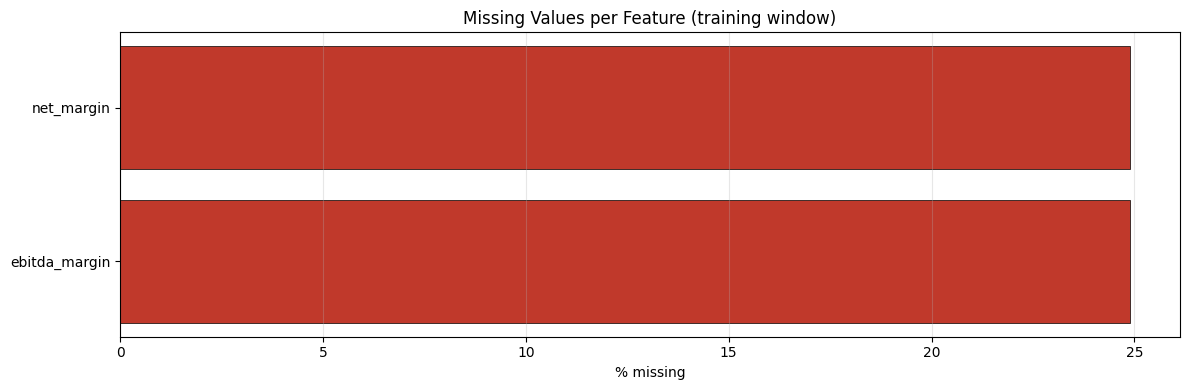

In [30]:
# ============================================================
# SECTION 4.1 — MISSING VALUES
# ============================================================

TR_DIAG_END = 2015
tr_diag = df_target[df_target["year"] <= TR_DIAG_END].copy()

missing = pd.DataFrame({
    "feature"        : feature_columns,
    "n_missing"      : tr_diag[feature_columns].isna().sum().values,
    "pct_missing"    : (tr_diag[feature_columns].isna().mean().values * 100),
    "dtype"          : [tr_diag[c].dtype for c in feature_columns],
})
missing["type"] = [
    "categorical" if c in categorical_features else "numeric"
    for c in missing["feature"]
]
missing = missing.sort_values("pct_missing", ascending=False).reset_index(drop=True)

missing.to_csv(TABLES_COMP / "missing_values.csv", index=False)

print(f"Total features analysed : {len(missing)}")
print(f"Features with missing   : {(missing.n_missing > 0).sum()}")
print(f"Max % missing           : {missing.pct_missing.max():.4f}%")
print()

# ---- Missingness bar chart ----
m_plot = missing[missing.n_missing > 0].copy()
if len(m_plot) > 0:
    fig, ax = plt.subplots(figsize=(12, max(4, len(m_plot) * 0.25)))
    ax.barh(m_plot["feature"], m_plot["pct_missing"],
            color="#c0392b", edgecolor="black", linewidth=0.5)
    ax.set_xlabel("% missing")
    ax.set_title("Missing Values per Feature (training window)")
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.savefig(COMPARATIVE / "missing_values.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
else:
    print("✓ No missing values in the training window.")

# ---- Flag features with extreme missingness ----
extreme_missing = missing[missing.pct_missing > 30]
if len(extreme_missing) > 0:
    print("⚠ Features with >30% missing:")
    print(extreme_missing[["feature", "pct_missing"]].to_string(index=False))

Training window: 1999 → 2015
Total rows      : 69,231
Negative (0)    : 68,692 (99.2214%)
Positive (1)    : 539 (0.7786%)
Imbalance ratio : 1 : 127.44

Naive-baseline accuracy (predict 0): 99.2214%


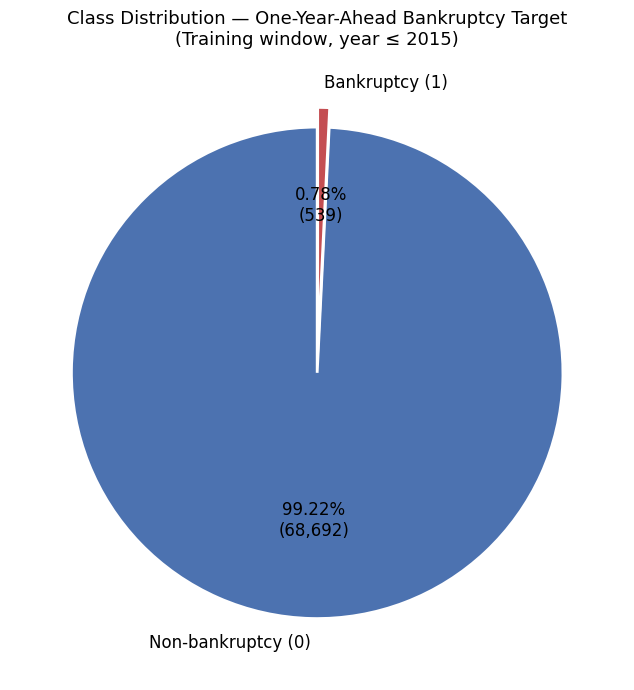

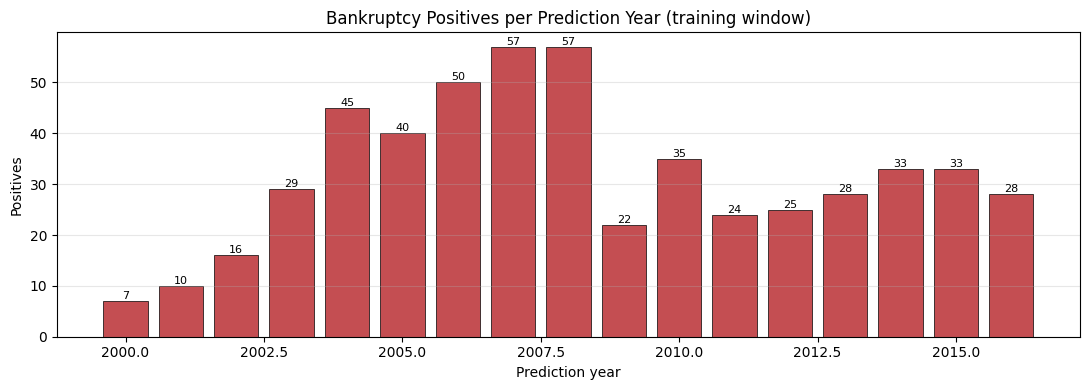

In [31]:
# ============================================================
# SECTION 4.2 — TARGET BALANCE
# ============================================================

counts = tr_diag["target_1yr"].value_counts().sort_index()
n_neg, n_pos = int(counts.get(0, 0)), int(counts.get(1, 0))
prevalence = n_pos / (n_neg + n_pos)

print(f"Training window: {tr_diag['year'].min()} → {tr_diag['year'].max()}")
print(f"Total rows      : {n_neg + n_pos:,}")
print(f"Negative (0)    : {n_neg:,} ({100 * n_neg / (n_neg + n_pos):.4f}%)")
print(f"Positive (1)    : {n_pos:,} ({100 * prevalence:.4f}%)")
print(f"Imbalance ratio : 1 : {n_neg / max(n_pos, 1):.2f}")
print()
print(f"Naive-baseline accuracy (predict 0): "
      f"{100 * n_neg / (n_neg + n_pos):.4f}%")

# ---- Pie chart ----
fig, ax = plt.subplots(figsize=(7, 7))
labels = ["Non-bankruptcy (0)", "Bankruptcy (1)"]
sizes  = [n_neg, n_pos]
colors = ["#4C72B0", "#C44E52"]

ax.pie(
    sizes, labels=labels,
    autopct=lambda p: f"{p:.2f}%\n({int(round(p * sum(sizes) / 100)):,})",
    colors=colors, startangle=90, explode=(0, 0.08),
    textprops={"fontsize": 12},
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)
ax.set_title("Class Distribution — One-Year-Ahead Bankruptcy Target\n"
             f"(Training window, year ≤ {TR_DIAG_END})",
             fontsize=13, pad=15)
plt.tight_layout()
plt.savefig(COMPARATIVE / "target_balance_pie.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# ---- Target per prediction year (training window only) ----
per_year = (
    tr_diag.groupby("prediction_year")["target_1yr"]
           .agg(["sum", "count"])
           .rename(columns={"sum": "positives", "count": "rows"})
)
per_year["prevalence"] = per_year["positives"] / per_year["rows"]
per_year.to_csv(TABLES_COMP / "target_balance_by_year.csv")

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(per_year.index, per_year["positives"],
              color="#C44E52", edgecolor="black", linewidth=0.5)
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2,
            b.get_height(), f"{int(b.get_height())}",
            ha="center", va="bottom", fontsize=8)
ax.set_xlabel("Prediction year")
ax.set_ylabel("Positives")
ax.set_title("Bankruptcy Positives per Prediction Year (training window)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(COMPARATIVE / "target_balance_by_year.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

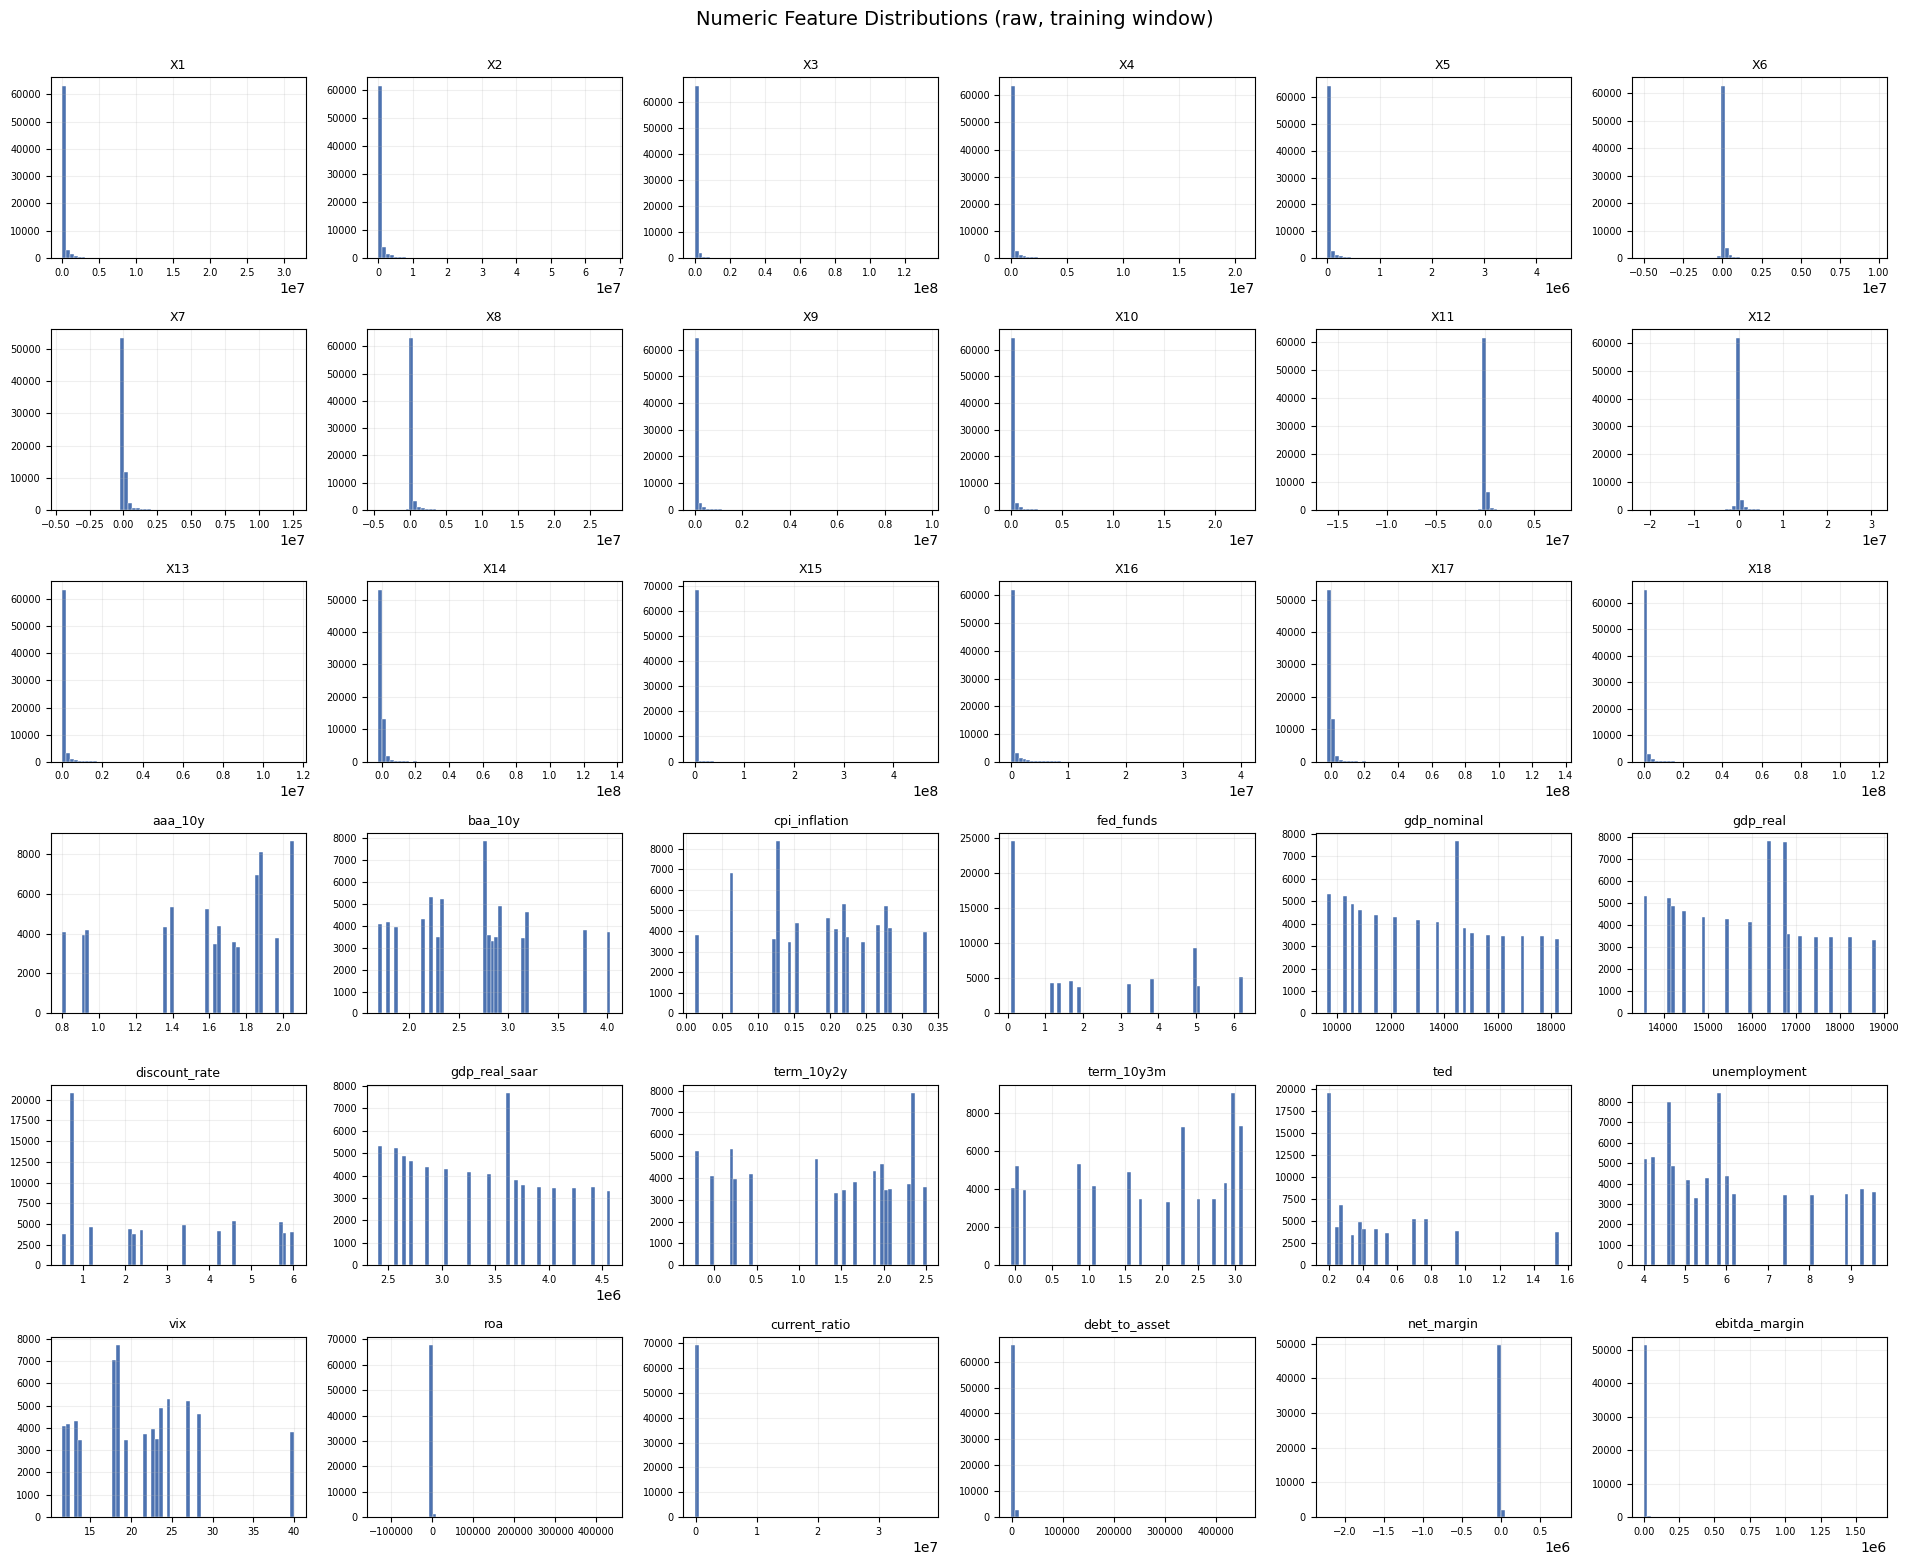

In [32]:
# ============================================================
# SECTION 4.3 — NUMERIC DISTRIBUTIONS (BEFORE PREPROCESSING)
# ============================================================

ncols = 6
nrows = int(np.ceil(len(numeric_features) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.6 * nrows))
axes = np.array(axes).ravel()

for ax, col in zip(axes, numeric_features):
    data = tr_diag[col].dropna().values
    ax.hist(data, bins=60, color="#4C72B0",
            edgecolor="white", linewidth=0.3)
    ax.set_title(col, fontsize=9)
    ax.tick_params(axis="both", labelsize=7)
    ax.grid(alpha=0.2)

for ax in axes[len(numeric_features):]:
    ax.axis("off")

plt.suptitle("Numeric Feature Distributions (raw, training window)",
             fontsize=14, y=1.00)
plt.tight_layout()
plt.savefig(COMPARATIVE / "numeric_distributions_raw.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

Features with |skew| > 1  : 23
Features with |skew| > 2  : 22
Features with |skew| > 5  : 22

Top 15 most-skewed features:
      feature    skew  kurtosis  abs_skew
current_ratio 238.267 60124.401   238.267
          roa 130.479 29601.567   130.479
debt_to_asset  56.003  7746.730    56.003
   net_margin -47.171  4046.597    47.171
          X15  37.007  2282.762    37.007
ebitda_margin  34.593  1586.920    34.593
           X3  23.864  1067.080    23.864
          X17  17.424   603.246    17.424
          X14  17.424   603.246    17.424
          X18  16.970   532.976    16.970
           X5  14.888   393.256    14.888
          X10  13.395   320.049    13.395
           X8  13.108   334.349    13.108
           X1  12.891   308.453    12.891
           X7  12.730   318.528    12.730


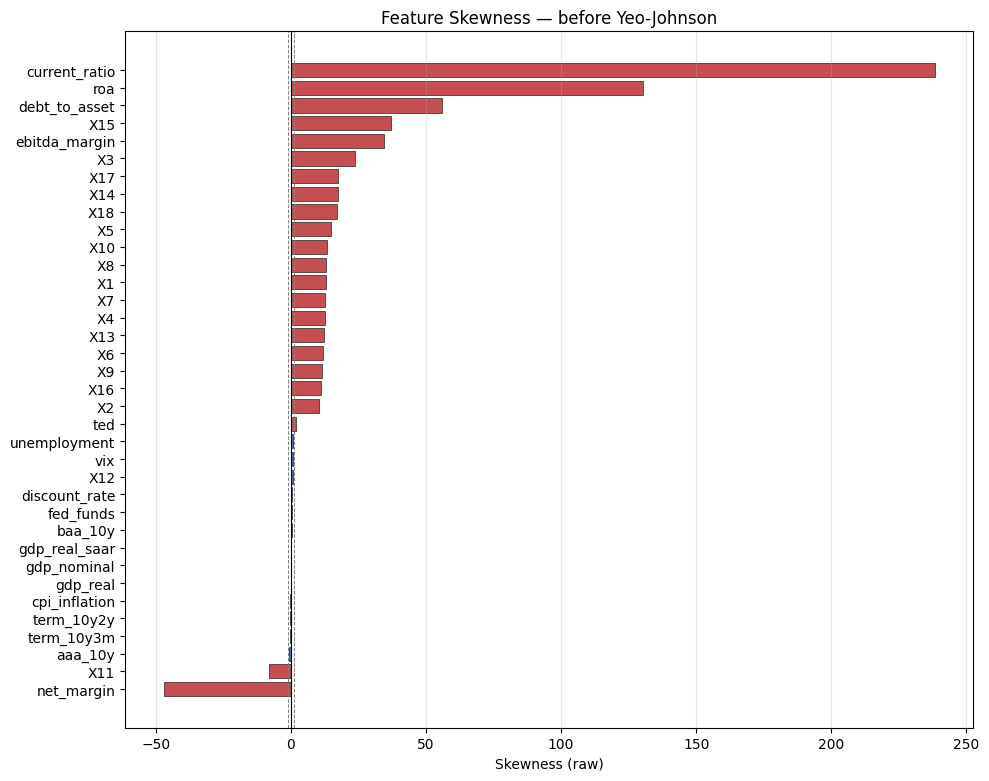

In [33]:
# ============================================================
# SECTION 4.4 — SKEWNESS AND KURTOSIS (BEFORE)
# ============================================================

skew_before = tr_diag[numeric_features].skew()
kurt_before = tr_diag[numeric_features].kurtosis()

sk_df = pd.DataFrame({
    "feature" : numeric_features,
    "skew"    : skew_before.values,
    "kurtosis": kurt_before.values,
})
sk_df["abs_skew"] = sk_df["skew"].abs()
sk_df = sk_df.sort_values("abs_skew", ascending=False).reset_index(drop=True)

sk_df.to_csv(TABLES_COMP / "skewness_before.csv", index=False)

print(f"Features with |skew| > 1  : {(sk_df.abs_skew > 1).sum()}")
print(f"Features with |skew| > 2  : {(sk_df.abs_skew > 2).sum()}")
print(f"Features with |skew| > 5  : {(sk_df.abs_skew > 5).sum()}")
print()
print("Top 15 most-skewed features:")
print(sk_df.head(15).round(3).to_string(index=False))

# ---- Sorted skewness bar chart ----
fig, ax = plt.subplots(figsize=(10, max(6, len(sk_df) * 0.22)))
top = sk_df.sort_values("skew")
colors = ["#C44E52" if abs(v) > 1 else "#4C72B0" for v in top["skew"]]
ax.barh(top["feature"], top["skew"], color=colors,
        edgecolor="black", linewidth=0.4)
ax.axvline(0, color="black", linewidth=0.8)
ax.axvline(1, color="gray", linestyle="--", linewidth=0.7)
ax.axvline(-1, color="gray", linestyle="--", linewidth=0.7)
ax.set_xlabel("Skewness (raw)")
ax.set_title("Feature Skewness — before Yeo-Johnson")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(COMPARATIVE / "skewness_before.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

Features with >1% outliers  : 26
Features with >5% outliers  : 26

Top 10 features by outlier rate:
      feature         q1        q3       iqr  lower_fence  upper_fence  n_outliers  pct_outliers
   net_margin     -0.046     1.856     1.902       -2.900        4.709       16258        31.261
          X12 -28275.000 22768.500 51043.500  -104840.250    99333.750       20403        29.471
          X11  -2406.000  8525.000 10931.000   -18802.500    24921.500       19379        27.992
          roa     -0.173     0.620     0.793       -1.363        1.810       17257        24.927
           X6   -647.895 19134.500 19782.395   -30321.488    48808.092       15048        21.736
           X4      0.000 13812.500 13812.500   -20718.750    34531.250       13853        20.010
current_ratio      0.232     1.329     1.097       -1.413        2.975       13851        20.007
ebitda_margin      0.000     4.775     4.775       -7.162       11.937        9783        18.811
          X15     44.065  2

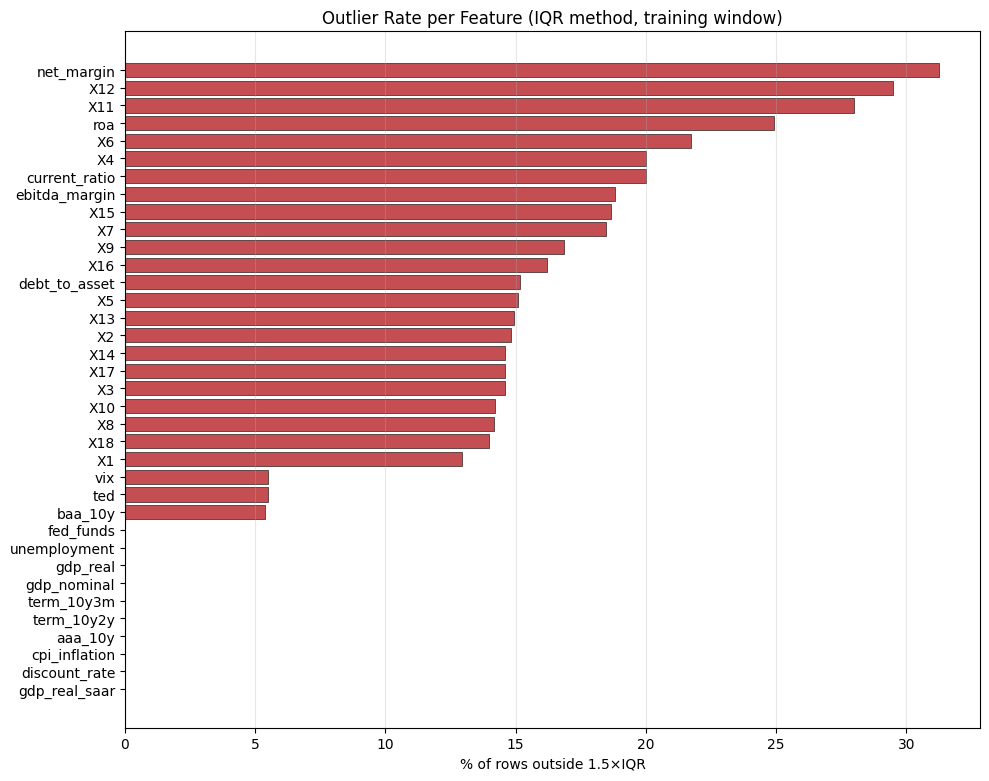

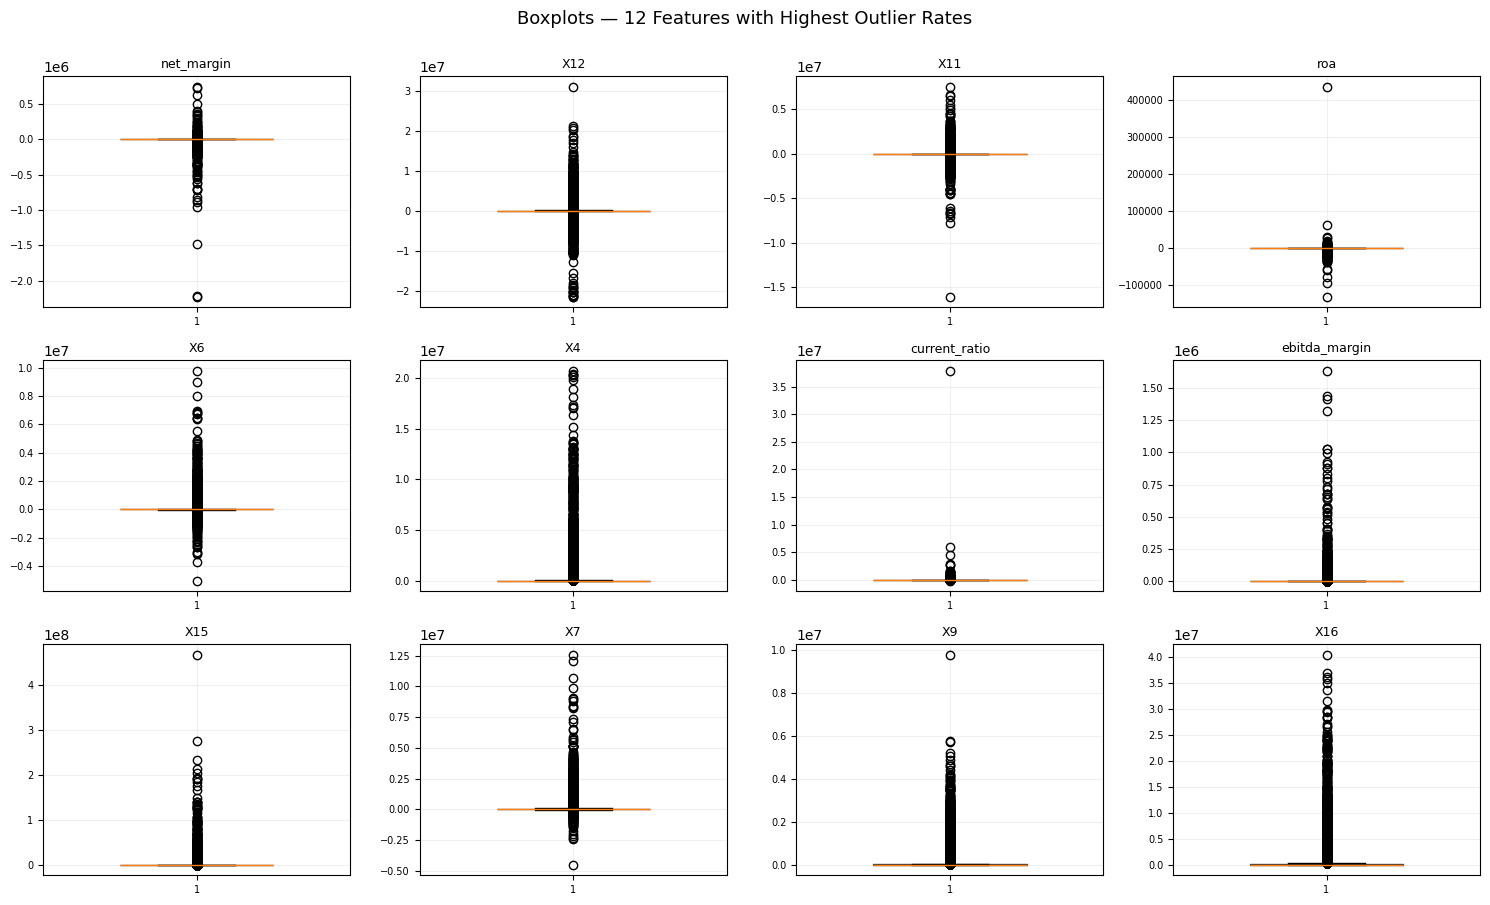

In [34]:
# ============================================================
# SECTION 4.5 — OUTLIERS (IQR-BASED)
# ============================================================

outlier_rows = []

for col in numeric_features:
    x = tr_diag[col].dropna().values
    q1, q3 = np.quantile(x, [0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(np.sum((x < lo) | (x > hi)))
    outlier_rows.append({
        "feature"         : col,
        "q1"              : q1,
        "q3"              : q3,
        "iqr"             : iqr,
        "lower_fence"     : lo,
        "upper_fence"     : hi,
        "n_outliers"      : n_out,
        "pct_outliers"    : 100 * n_out / len(x),
    })

outlier_df = pd.DataFrame(outlier_rows)\
               .sort_values("pct_outliers", ascending=False)\
               .reset_index(drop=True)

outlier_df.to_csv(TABLES_COMP / "outliers_iqr.csv", index=False)

print(f"Features with >1% outliers  : {(outlier_df.pct_outliers > 1).sum()}")
print(f"Features with >5% outliers  : {(outlier_df.pct_outliers > 5).sum()}")
print()
print("Top 10 features by outlier rate:")
print(outlier_df.head(10).round(3).to_string(index=False))

# ---- Bar chart ----
fig, ax = plt.subplots(figsize=(10, max(6, len(outlier_df) * 0.22)))
top = outlier_df.sort_values("pct_outliers")
ax.barh(top["feature"], top["pct_outliers"],
        color="#C44E52", edgecolor="black", linewidth=0.4)
ax.set_xlabel("% of rows outside 1.5×IQR")
ax.set_title("Outlier Rate per Feature (IQR method, training window)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(COMPARATIVE / "outliers_iqr.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# ---- Boxplots for the 12 worst offenders ----
worst = outlier_df.head(12)["feature"].tolist()
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
axes = axes.ravel()
for ax, col in zip(axes, worst):
    ax.boxplot(tr_diag[col].dropna().values, vert=True, widths=0.5,
               patch_artist=True,
               boxprops=dict(facecolor="#4C72B0", alpha=0.7))
    ax.set_title(col, fontsize=9)
    ax.tick_params(axis="both", labelsize=7)
    ax.grid(alpha=0.2)
for ax in axes[len(worst):]:
    ax.axis("off")
plt.suptitle("Boxplots — 12 Features with Highest Outlier Rates",
             fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig(COMPARATIVE / "outliers_boxplots.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

Top 10 features by clipped %:
      feature  lower_bound  upper_bound  n_clipped  pct_clipped
   net_margin  -14561.8583    9197.2518       1042       2.0035
           X1       0.7572 2793641.6000       1386       2.0020
           X6 -113000.5000  852558.8000       1386       2.0020
           X8  -37989.4000 2521656.0000       1386       2.0020
current_ratio       0.0002    4728.7348       1386       2.0020
          roa   -3163.1618    1298.4561       1386       2.0020
debt_to_asset       0.0003   10345.5589       1386       2.0020
           X7  -76197.9000 1165084.9000       1386       2.0020
          X11 -259359.8000  488247.6000       1386       2.0020
          X18       3.3104 6500110.9000       1386       2.0020


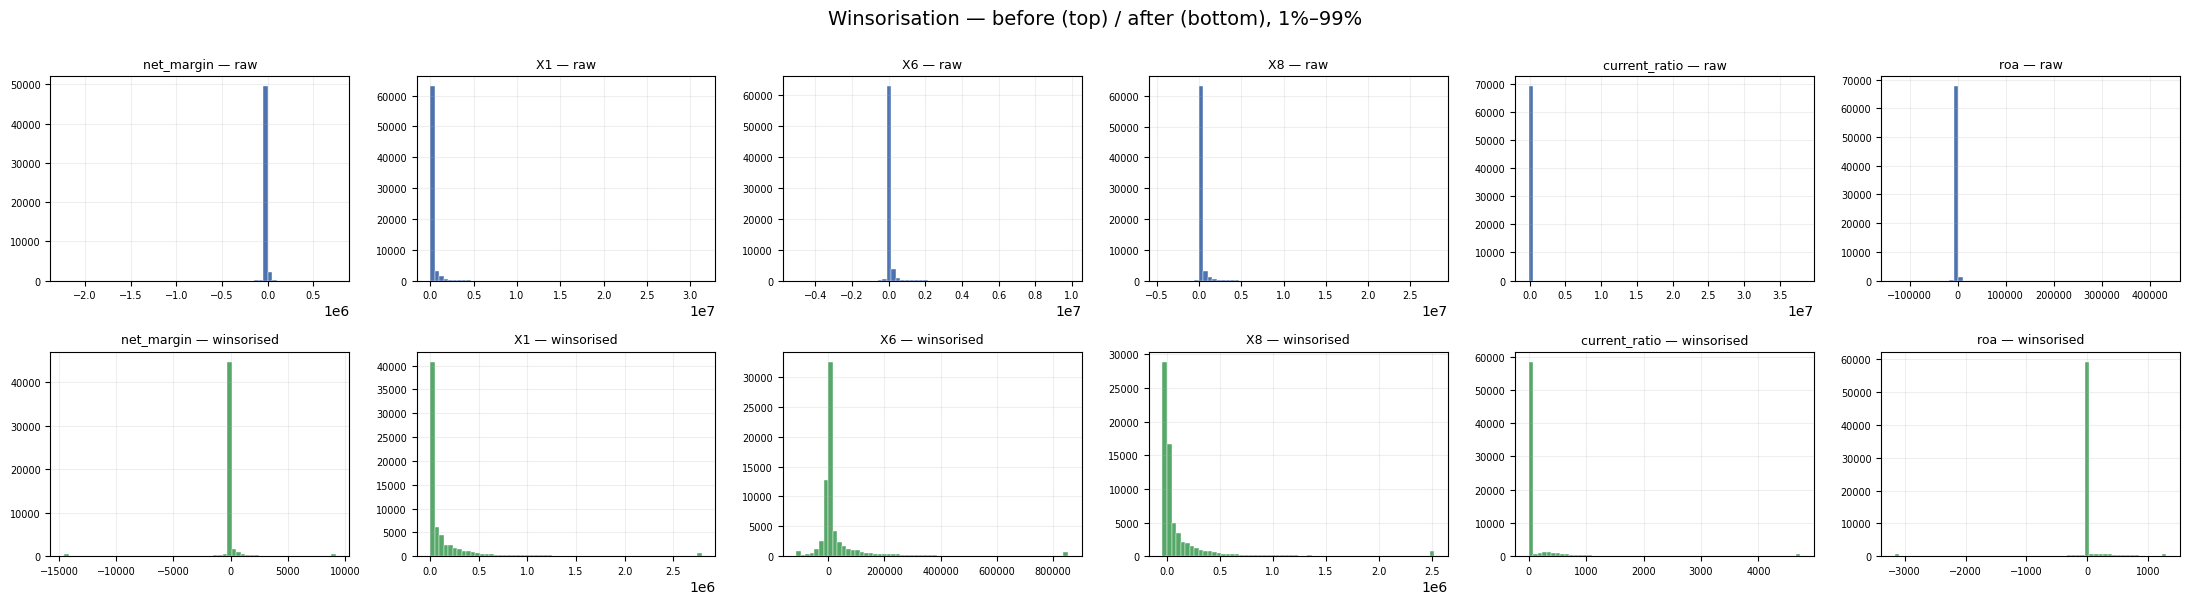

In [35]:
# ============================================================
# SECTION 4.6 — WINSORISATION DEMONSTRATION
# ============================================================
# Fit the winsoriser on the training window and show its effect on
# the 6 features that were previously most skewed/outlier-prone.

X_tr_raw = tr_diag[feature_columns]

# Fit winsoriser only (no Yeo-Johnson, no scaling) for clarity
wins = WinsoriserTransformer(0.01, 0.99)
wins.fit(X_tr_raw[numeric_features].values)
X_wins = wins.transform(X_tr_raw[numeric_features].values)

# Count clipped values per feature
clip_counts = []
for i, col in enumerate(numeric_features):
    lo = wins.lower_bounds_[i]
    hi = wins.upper_bounds_[i]
    x  = tr_diag[col].dropna().values
    n_clip = int(np.sum((x < lo) | (x > hi)))
    clip_counts.append({
        "feature"      : col,
        "lower_bound"  : lo,
        "upper_bound"  : hi,
        "n_clipped"    : n_clip,
        "pct_clipped"  : 100 * n_clip / len(x),
    })

clip_df = pd.DataFrame(clip_counts)\
            .sort_values("pct_clipped", ascending=False)\
            .reset_index(drop=True)
clip_df.to_csv(TABLES_COMP / "winsorisation_summary.csv", index=False)

print("Top 10 features by clipped %:")
print(clip_df.head(10).round(4).to_string(index=False))

# ---- Before/after histograms for top-6 clipped features ----
top6 = clip_df.head(6)["feature"].tolist()

fig, axes = plt.subplots(2, 6, figsize=(22, 6))
for j, col in enumerate(top6):
    x_raw  = tr_diag[col].dropna().values
    x_w    = X_wins[:, numeric_features.index(col)]
    x_w    = x_w[~np.isnan(x_w)]

    axes[0, j].hist(x_raw, bins=60, color="#4C72B0",
                    edgecolor="white", linewidth=0.3)
    axes[0, j].set_title(f"{col} — raw", fontsize=9)
    axes[1, j].hist(x_w, bins=60, color="#55A868",
                    edgecolor="white", linewidth=0.3)
    axes[1, j].set_title(f"{col} — winsorised", fontsize=9)
    for k in (0, 1):
        axes[k, j].grid(alpha=0.2)
        axes[k, j].tick_params(labelsize=7)

plt.suptitle("Winsorisation — before (top) / after (bottom), 1%–99%",
             fontsize=14, y=1.00)
plt.tight_layout()
plt.savefig(COMPARATIVE / "winsorisation_before_after.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

Features with improved |skew| : 31/36
Mean |skew| before            : 21.445
Mean |skew| after             : 9.046

Top 10 most-improved:
      feature  skew_before  skew_after  abs_before  abs_after  improvement
current_ratio      238.267     -38.777     238.267     38.777      199.490
          roa      130.479      51.290     130.479     51.290       79.189
debt_to_asset       56.003     -56.812      56.003     56.812       -0.808
   net_margin      -47.171       3.252      47.171      3.252       43.919
          X15       37.007       0.042      37.007      0.042       36.965
ebitda_margin       34.593     -85.110      34.593     85.110      -50.517
           X3       23.864     -17.316      23.864     17.316        6.548
          X17       17.424      -9.467      17.424      9.467        7.957
          X14       17.424      -9.467      17.424      9.467        7.957
          X18       16.970     -14.834      16.970     14.834        2.136


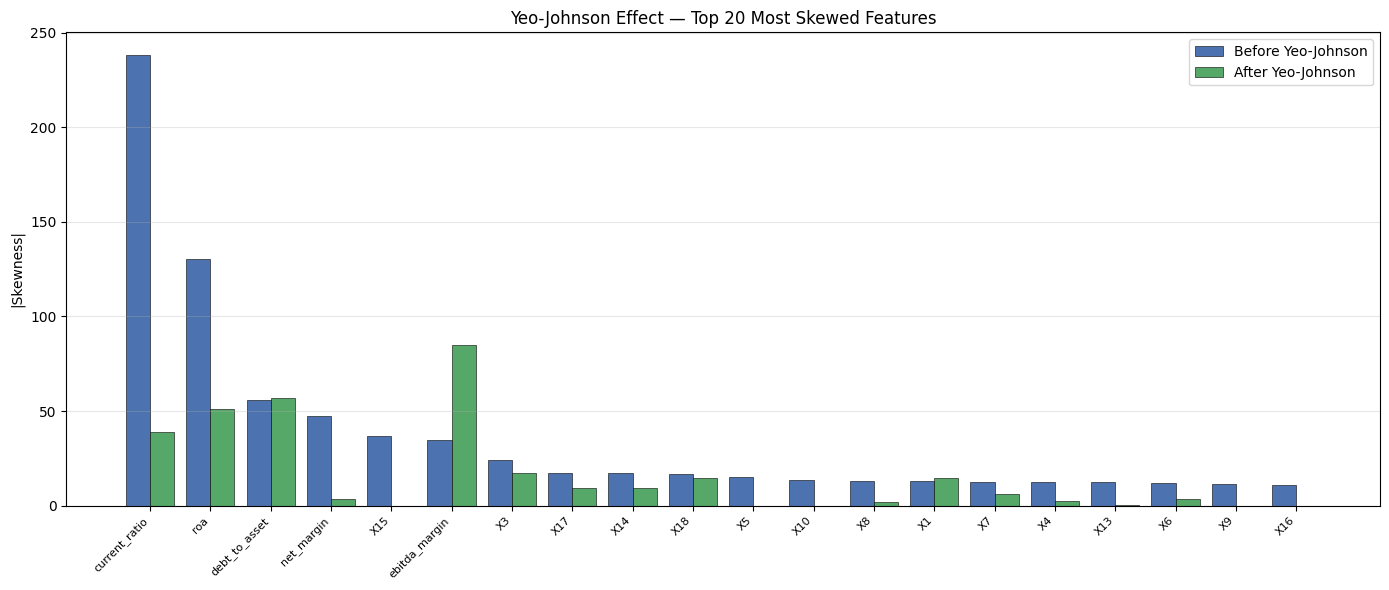

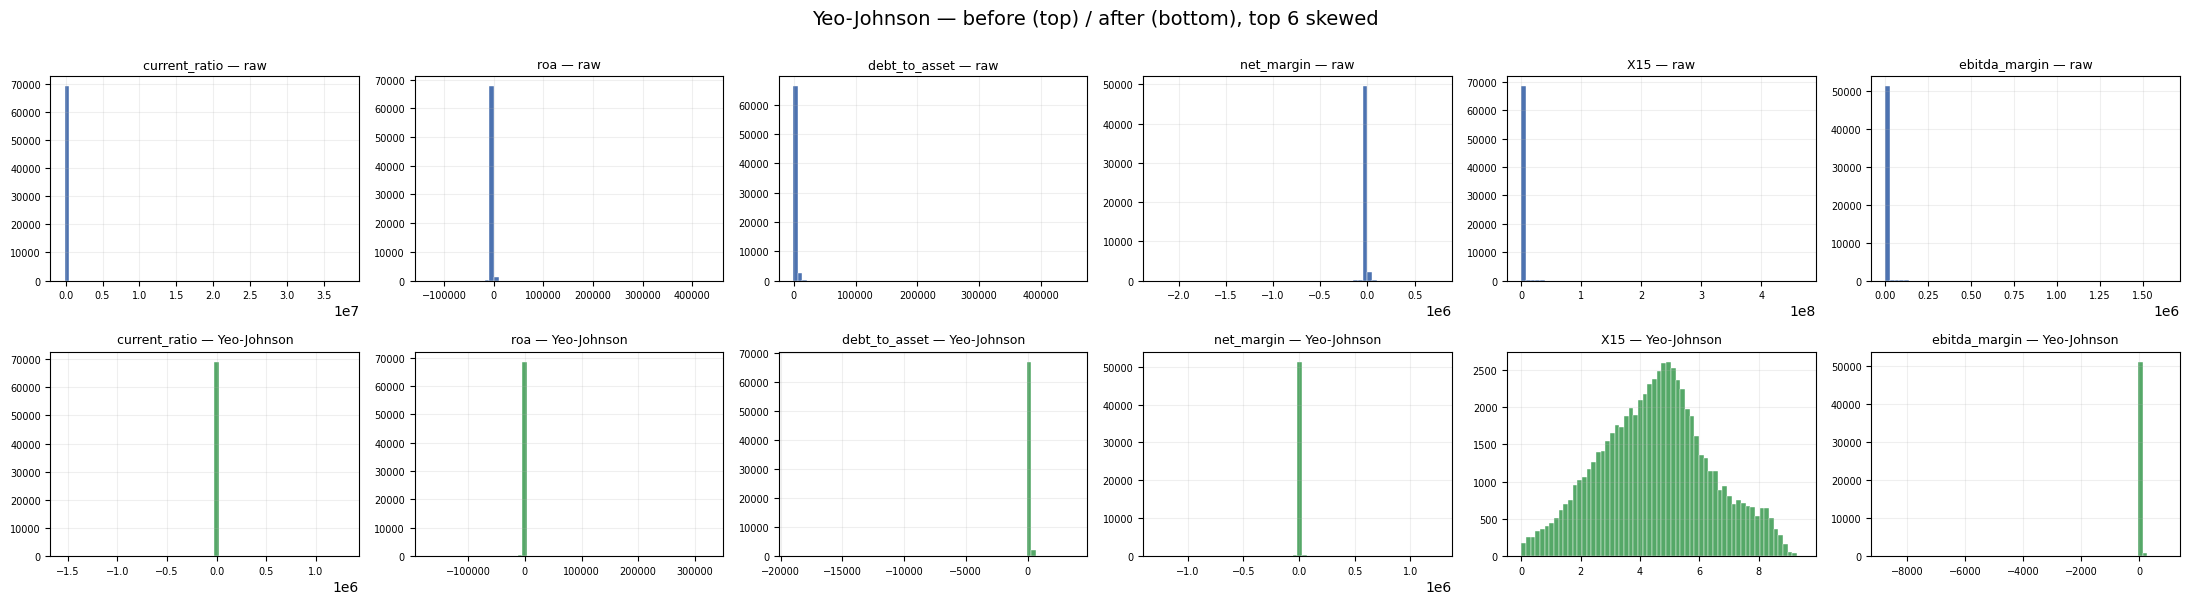

In [36]:
# ============================================================
# SECTION 4.7 — YEO-JOHNSON DEMONSTRATION
# ============================================================

# Fit Yeo-Johnson only (no winsorise, no scaling) for clarity
yj = PowerTransformer(method="yeo-johnson", standardize=False)
yj.fit(X_tr_raw[numeric_features].values)
X_yj = yj.transform(X_tr_raw[numeric_features].values)

skew_after = pd.Series(
    pd.DataFrame(X_yj, columns=numeric_features).skew().values,
    index=numeric_features,
)

sk_compare = pd.DataFrame({
    "feature"    : numeric_features,
    "skew_before": tr_diag[numeric_features].skew().values,
    "skew_after" : skew_after.values,
})
sk_compare["abs_before"]  = sk_compare["skew_before"].abs()
sk_compare["abs_after"]   = sk_compare["skew_after"].abs()
sk_compare["improvement"] = sk_compare["abs_before"] - sk_compare["abs_after"]
sk_compare = sk_compare.sort_values("abs_before", ascending=False)\
                       .reset_index(drop=True)
sk_compare.to_csv(TABLES_COMP / "skewness_after.csv", index=False)

n_improved = (sk_compare["improvement"] > 0).sum()
print(f"Features with improved |skew| : {n_improved}/{len(numeric_features)}")
print(f"Mean |skew| before            : {sk_compare.abs_before.mean():.3f}")
print(f"Mean |skew| after             : {sk_compare.abs_after.mean():.3f}")
print()
print("Top 10 most-improved:")
print(sk_compare.head(10).round(3).to_string(index=False))

# ---- Bar chart: |skew| before vs after ----
top20 = sk_compare.head(20).copy()
x = np.arange(len(top20))
w = 0.4

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(x - w/2, top20["abs_before"], width=w,
       label="Before Yeo-Johnson", color="#4C72B0",
       edgecolor="black", linewidth=0.4)
ax.bar(x + w/2, top20["abs_after"], width=w,
       label="After Yeo-Johnson",  color="#55A868",
       edgecolor="black", linewidth=0.4)
ax.set_xticks(x)
ax.set_xticklabels(top20["feature"], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("|Skewness|")
ax.set_title("Yeo-Johnson Effect — Top 20 Most Skewed Features")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(COMPARATIVE / "skewness_before_after.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# ---- Before/after histograms for top-6 skewed features ----
top6_skew = sk_compare.head(6)["feature"].tolist()

fig, axes = plt.subplots(2, 6, figsize=(22, 6))
for j, col in enumerate(top6_skew):
    x_raw = tr_diag[col].dropna().values
    x_yj_ = X_yj[:, numeric_features.index(col)]
    x_yj_ = x_yj_[~np.isnan(x_yj_)]

    axes[0, j].hist(x_raw, bins=60, color="#4C72B0",
                    edgecolor="white", linewidth=0.3)
    axes[0, j].set_title(f"{col} — raw", fontsize=9)
    axes[1, j].hist(x_yj_, bins=60, color="#55A868",
                    edgecolor="white", linewidth=0.3)
    axes[1, j].set_title(f"{col} — Yeo-Johnson", fontsize=9)
    for k in (0, 1):
        axes[k, j].grid(alpha=0.2)
        axes[k, j].tick_params(labelsize=7)

plt.suptitle("Yeo-Johnson — before (top) / after (bottom), top 6 skewed",
             fontsize=14, y=1.00)
plt.tight_layout()
plt.savefig(COMPARATIVE / "yeojohnson_before_after_hist.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()


Division: 10 levels
 feature level  count       pct  is_rare_lt_1pct
Division     D  33578 48.501394            False
Division     I  15254 22.033482            False
Division     E   6411  9.260302            False
Division     G   4978  7.190420            False
Division     B   3644  5.263538            False
Division     F   2596  3.749765            False
Division     H   1844  2.663547            False
Division     C    631  0.911441             True
Division     A    283  0.408776             True
Division     J     12  0.017333             True

MajorGroup: 73 levels
   feature level  count       pct  is_rare_lt_1pct
MajorGroup    73   9972 14.403952            False
MajorGroup    28   7077 10.222299            False
MajorGroup    36   6358  9.183747            False
MajorGroup    38   5664  8.181306            False
MajorGroup    35   4088  5.904869            False
MajorGroup    13   2852  4.119542            False
MajorGroup    49   2406  3.475322            False
MajorGrou

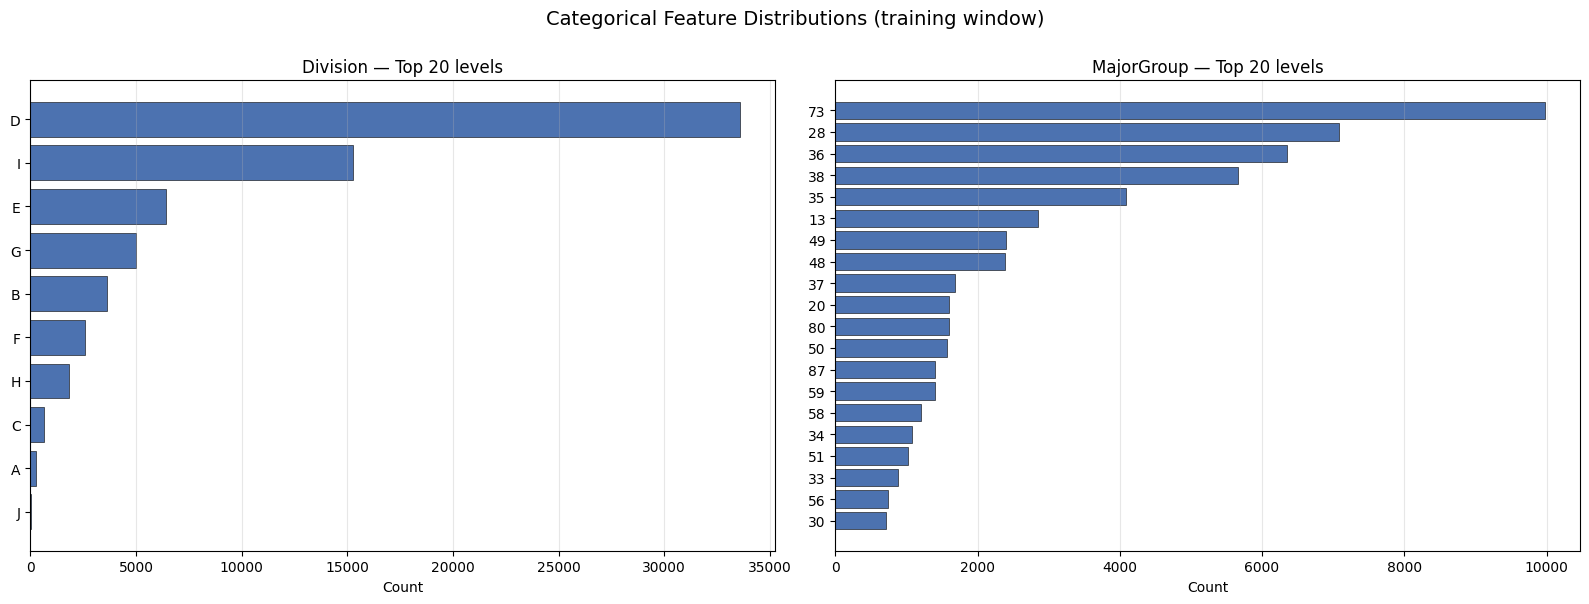


⚠ 55 rare levels (<1% of rows):
   feature level  count      pct
  Division     C    631 0.911441
  Division     A    283 0.408776
  Division     J     12 0.017333
MajorGroup    67    686 0.990886
MajorGroup    27    679 0.980775
MajorGroup    23    622 0.898441
MajorGroup    79    579 0.836331
MajorGroup    26    477 0.688998
MajorGroup    70    458 0.661553
MajorGroup    45    446 0.644220
MajorGroup    10    425 0.613887
MajorGroup    82    422 0.609554
MajorGroup    53    418 0.603776
MajorGroup    42    410 0.592220
MajorGroup    65    367 0.530109
MajorGroup    55    362 0.522887
MajorGroup    32    359 0.518554
MajorGroup    57    341 0.492554
MajorGroup    25    333 0.480998
MajorGroup    54    329 0.475221
MajorGroup    29    318 0.459332
MajorGroup    44    310 0.447776
MajorGroup    78    306 0.441999
MajorGroup    31    299 0.431887
MajorGroup    17    295 0.426110
MajorGroup    72    293 0.423221
MajorGroup    47    284 0.410221
MajorGroup    22    275 0.397221
MajorGroup

In [37]:
# ============================================================
# SECTION 4.8 — CATEGORICAL INSPECTION
# ============================================================

cat_rows = []
for col in categorical_features:
    vc = tr_diag[col].value_counts(dropna=False)
    total = len(tr_diag)
    for level, count in vc.items():
        cat_rows.append({
            "feature"        : col,
            "level"          : str(level),
            "count"          : int(count),
            "pct"            : 100 * count / total,
            "is_rare_lt_1pct": (100 * count / total) < 1.0,
        })
cat_df = pd.DataFrame(cat_rows)
cat_df.to_csv(TABLES_COMP / "categorical_distribution.csv", index=False)

for col in categorical_features:
    sub = cat_df[cat_df["feature"] == col]
    print(f"\n{col}: {sub.shape[0]} levels")
    print(sub.sort_values("count", ascending=False).head(10).to_string(index=False))

# ---- Bar charts — top categories ----
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col in zip(axes, categorical_features):
    sub = cat_df[cat_df["feature"] == col]\
              .sort_values("count", ascending=False)\
              .head(20)
    ax.barh(sub["level"][::-1], sub["count"][::-1],
            color="#4C72B0", edgecolor="black", linewidth=0.4)
    ax.set_title(f"{col} — Top 20 levels")
    ax.set_xlabel("Count")
    ax.grid(axis="x", alpha=0.3)
plt.suptitle("Categorical Feature Distributions (training window)",
             fontsize=14, y=1.00)
plt.tight_layout()
plt.savefig(COMPARATIVE / "categorical_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# ---- Rare-level warning ----
rare = cat_df[cat_df["is_rare_lt_1pct"]]
if len(rare) > 0:
    print(f"\n⚠ {len(rare)} rare levels (<1% of rows):")
    print(rare[["feature", "level", "count", "pct"]].to_string(index=False))
else:
    print("\n✓ No rare levels (<1% of rows).")

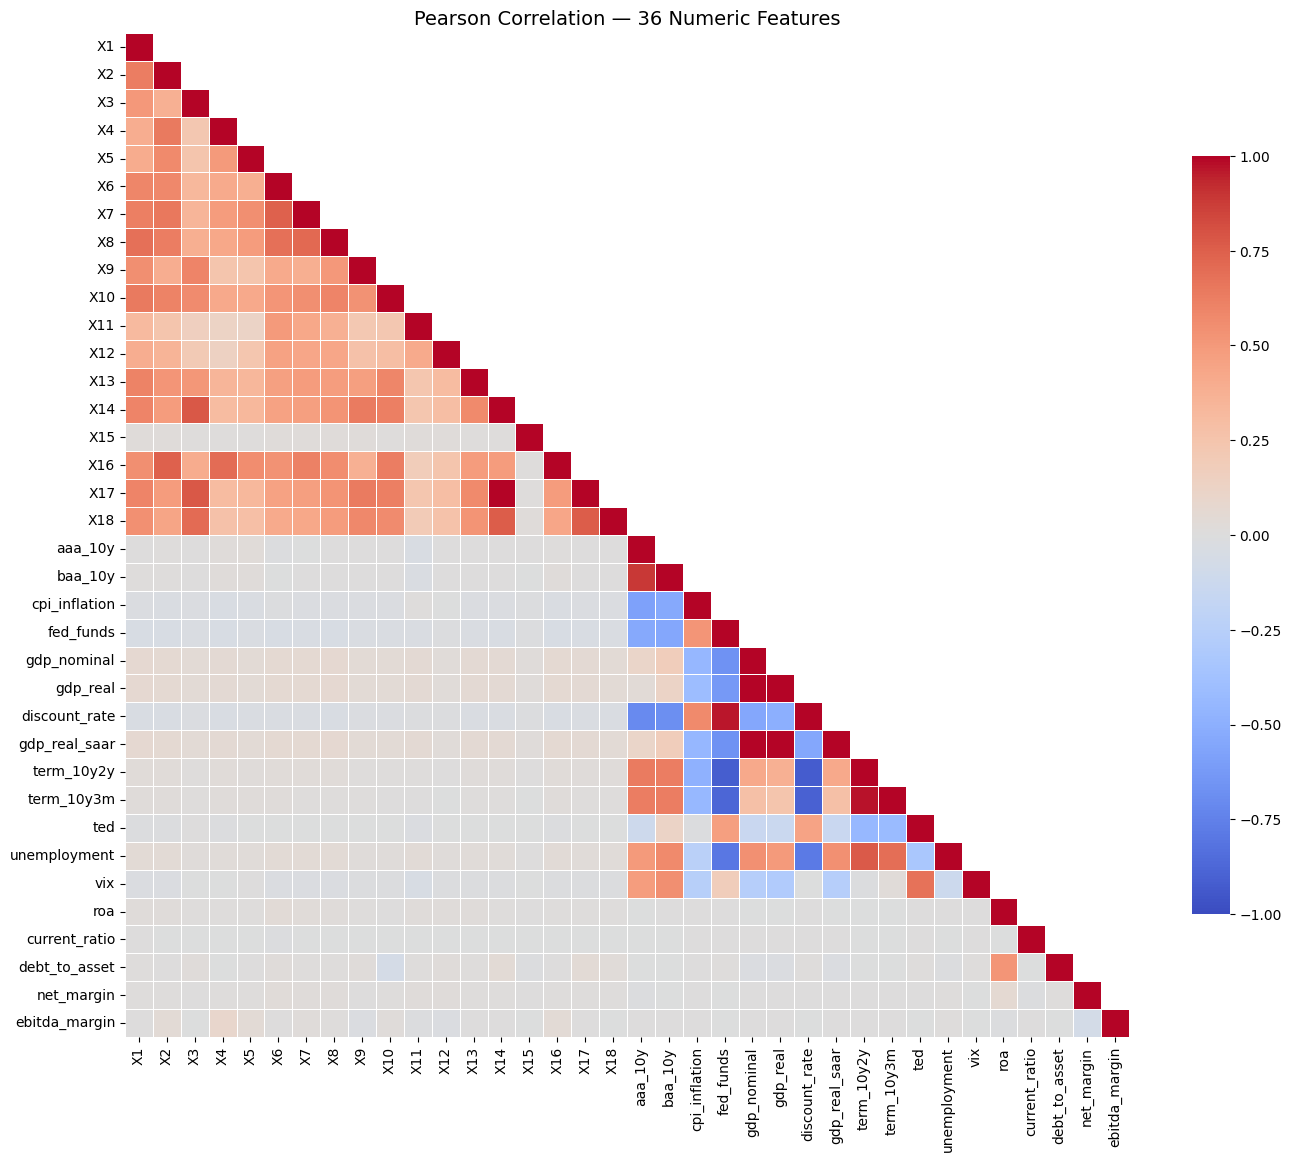

⚠ 9 pairs with |r| ≥ 0.90:
    feature_1     feature_2  pearson_r
          X14           X17   1.000000
  gdp_nominal gdp_real_saar   1.000000
  gdp_nominal      gdp_real   0.994763
     gdp_real gdp_real_saar   0.994763
   term_10y2y    term_10y3m   0.969772
    fed_funds discount_rate   0.964174
discount_rate    term_10y2y  -0.924406
    fed_funds    term_10y2y  -0.919691
discount_rate    term_10y3m  -0.903970

Pairs with |r| ≥ 0.70 : 23


In [38]:
# ============================================================
# SECTION 4.9 — CORRELATION ANALYSIS (NUMERIC FEATURES)
# ============================================================

corr = tr_diag[numeric_features].corr(method="pearson")

# ---- Full heatmap ----
fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(
    corr, mask=mask, cmap="coolwarm", center=0,
    vmin=-1, vmax=1, square=True,
    linewidths=0.4, linecolor="white",
    cbar_kws={"shrink": 0.7},
    annot=False, ax=ax,
)
ax.set_title("Pearson Correlation — 36 Numeric Features", fontsize=14)
plt.tight_layout()
plt.savefig(COMPARATIVE / "correlation_heatmap.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# ---- High-correlation pairs ----
pairs = []
for i, a in enumerate(numeric_features):
    for j, b in enumerate(numeric_features):
        if j <= i:
            continue
        r = corr.iloc[i, j]
        if np.isnan(r):
            continue
        if abs(r) >= 0.9:
            pairs.append({"feature_1": a, "feature_2": b, "pearson_r": r})

pairs_df = pd.DataFrame(pairs)\
             .sort_values("pearson_r", key=lambda s: s.abs(), ascending=False)\
             .reset_index(drop=True)
pairs_df.to_csv(TABLES_COMP / "high_correlations.csv", index=False)

if len(pairs_df) > 0:
    print(f"⚠ {len(pairs_df)} pairs with |r| ≥ 0.90:")
    print(pairs_df.to_string(index=False))
else:
    print("✓ No pairs with |r| ≥ 0.90.")

# ---- Moderate pairs listing for the dissertation ----
pairs_70 = []
for i, a in enumerate(numeric_features):
    for j, b in enumerate(numeric_features):
        if j <= i:
            continue
        r = corr.iloc[i, j]
        if np.isnan(r):
            continue
        if abs(r) >= 0.7:
            pairs_70.append({"feature_1": a, "feature_2": b, "pearson_r": r})

pairs70_df = pd.DataFrame(pairs_70)\
               .sort_values("pearson_r", key=lambda s: s.abs(), ascending=False)\
               .reset_index(drop=True)
pairs70_df.to_csv(TABLES_COMP / "correlations_above_0p7.csv", index=False)

print(f"\nPairs with |r| ≥ 0.70 : {len(pairs70_df)}")


--- VIF (raw, median-imputed) ---
Max VIF: 1000799917193443.5 | >5: 14 | >10: 14
      feature          VIF   flag
  gdp_nominal 1.000800e+15 severe
gdp_real_saar 1.000800e+15 severe
          X14 1.000800e+15 severe
          X17 1.000800e+15 severe
discount_rate 4.286390e+03 severe
    fed_funds 2.922260e+03 severe
     gdp_real 2.391040e+03 severe
   term_10y3m 4.131600e+02 severe
   term_10y2y 3.882600e+02 severe
          vix 1.219100e+02 severe
      aaa_10y 8.478000e+01 severe
          ted 7.318000e+01 severe
      baa_10y 1.566000e+01 severe
 unemployment 1.314000e+01 severe
           X7 3.390000e+00     ok

--- VIF (Yeo-Johnson) ---
Max VIF: 1000799917193443.5 | >5: 15 | >10: 14
      feature          VIF     flag
          X14 1.000800e+15   severe
          X17 1.000800e+15   severe
gdp_real_saar 8.635857e+12   severe
  gdp_nominal 8.627585e+12   severe
     gdp_real 4.425405e+04   severe
discount_rate 2.531910e+03   severe
   term_10y2y 1.637700e+03   severe
   term_10y3

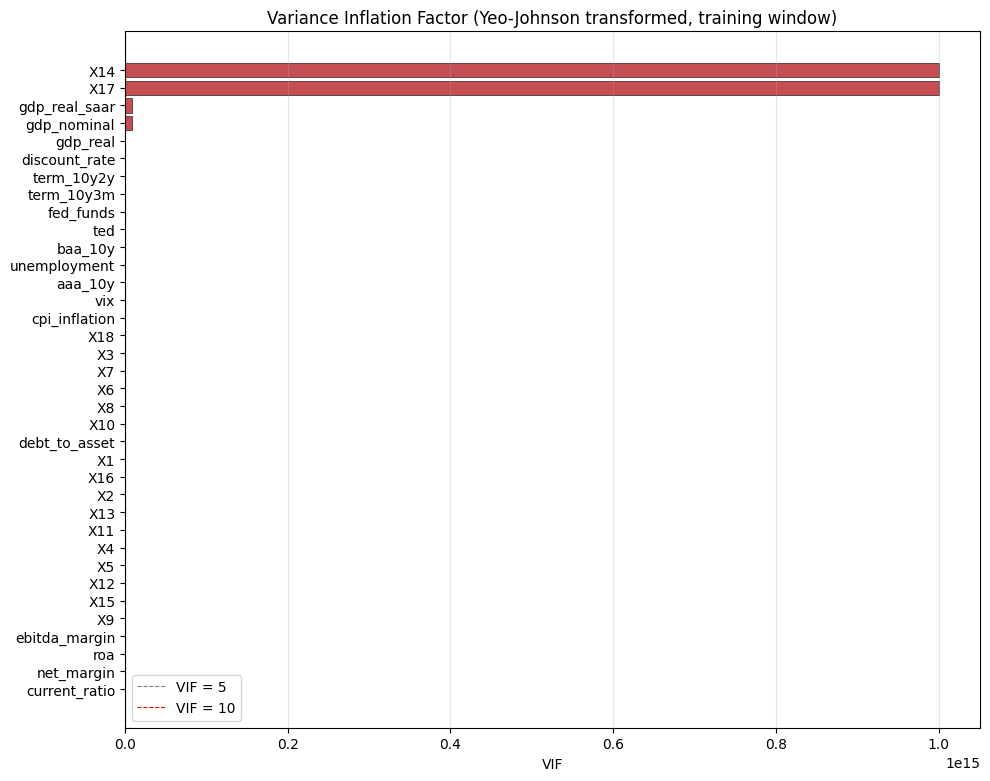

In [39]:
# ============================================================
# SECTION 4.10 — VARIANCE INFLATION FACTOR (VIF)
# ============================================================
# VIF is computed on median-imputed numeric training features.
# Two representations reported:
#   (a) raw scale (after imputation only)
#   (b) after Yeo-Johnson (matches what LR actually sees,
#       minus standard scaling which does not affect VIF)

from statsmodels.stats.outliers_influence import variance_inflation_factor

def compute_vif(df_numeric, label=""):
    X = df_numeric.dropna(axis=1, how="any").values
    cols = [c for c, keep in zip(df_numeric.columns,
                                  df_numeric.notna().all(axis=0)) if keep]
    vif = pd.DataFrame({
        "feature": cols,
        "VIF": [variance_inflation_factor(X, i) for i in range(X.shape[1])],
    }).sort_values("VIF", ascending=False).reset_index(drop=True)
    vif["flag"] = np.where(vif.VIF > 10, "severe",
                    np.where(vif.VIF > 5, "moderate", "ok"))
    print(f"\n--- VIF ({label}) ---")
    print(f"Max VIF: {vif.VIF.max():.1f} | "
          f">5: {(vif.VIF>5).sum()} | >10: {(vif.VIF>10).sum()}")
    print(vif.head(15).round(2).to_string(index=False))
    return vif

# (a) Impute only (no transformation) — reflects raw correlations
X_raw_imp = SimpleImputer(strategy="median").fit_transform(
    tr_diag[numeric_features].values
)
vif_raw = compute_vif(
    pd.DataFrame(X_raw_imp, columns=numeric_features), "raw, median-imputed"
)

# (b) Impute + Yeo-Johnson (what the LR pipeline sees before scaling)
pre_vif = make_preprocessor(scale=False, winsorize=False, correct_skew=True)
pre_vif.fit(tr_diag[feature_columns])
X_yj_vif = pre_vif.transform(tr_diag[feature_columns])[:, :len(numeric_features)]
vif_yj = compute_vif(
    pd.DataFrame(X_yj_vif, columns=numeric_features), "Yeo-Johnson"
)

vif_raw.to_csv(TABLES_COMP / "vif_raw.csv", index=False)
vif_yj.to_csv(TABLES_COMP / "vif_yeojohnson.csv", index=False)

# Plot
fig, ax = plt.subplots(figsize=(10, max(6, len(vif_yj) * 0.22)))
v = vif_yj.sort_values("VIF")
colors = ["#C44E52" if x > 10 else "#DD8452" if x > 5 else "#4C72B0"
          for x in v.VIF]
ax.barh(v.feature, v.VIF, color=colors, edgecolor="black", linewidth=0.4)
ax.axvline(5,  color="gray", linestyle="--", linewidth=0.8, label="VIF = 5")
ax.axvline(10, color="red",  linestyle="--", linewidth=0.8, label="VIF = 10")
ax.set_xlabel("VIF")
ax.set_title("Variance Inflation Factor (Yeo-Johnson transformed, training window)")
ax.legend()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(COMPARATIVE / "vif.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

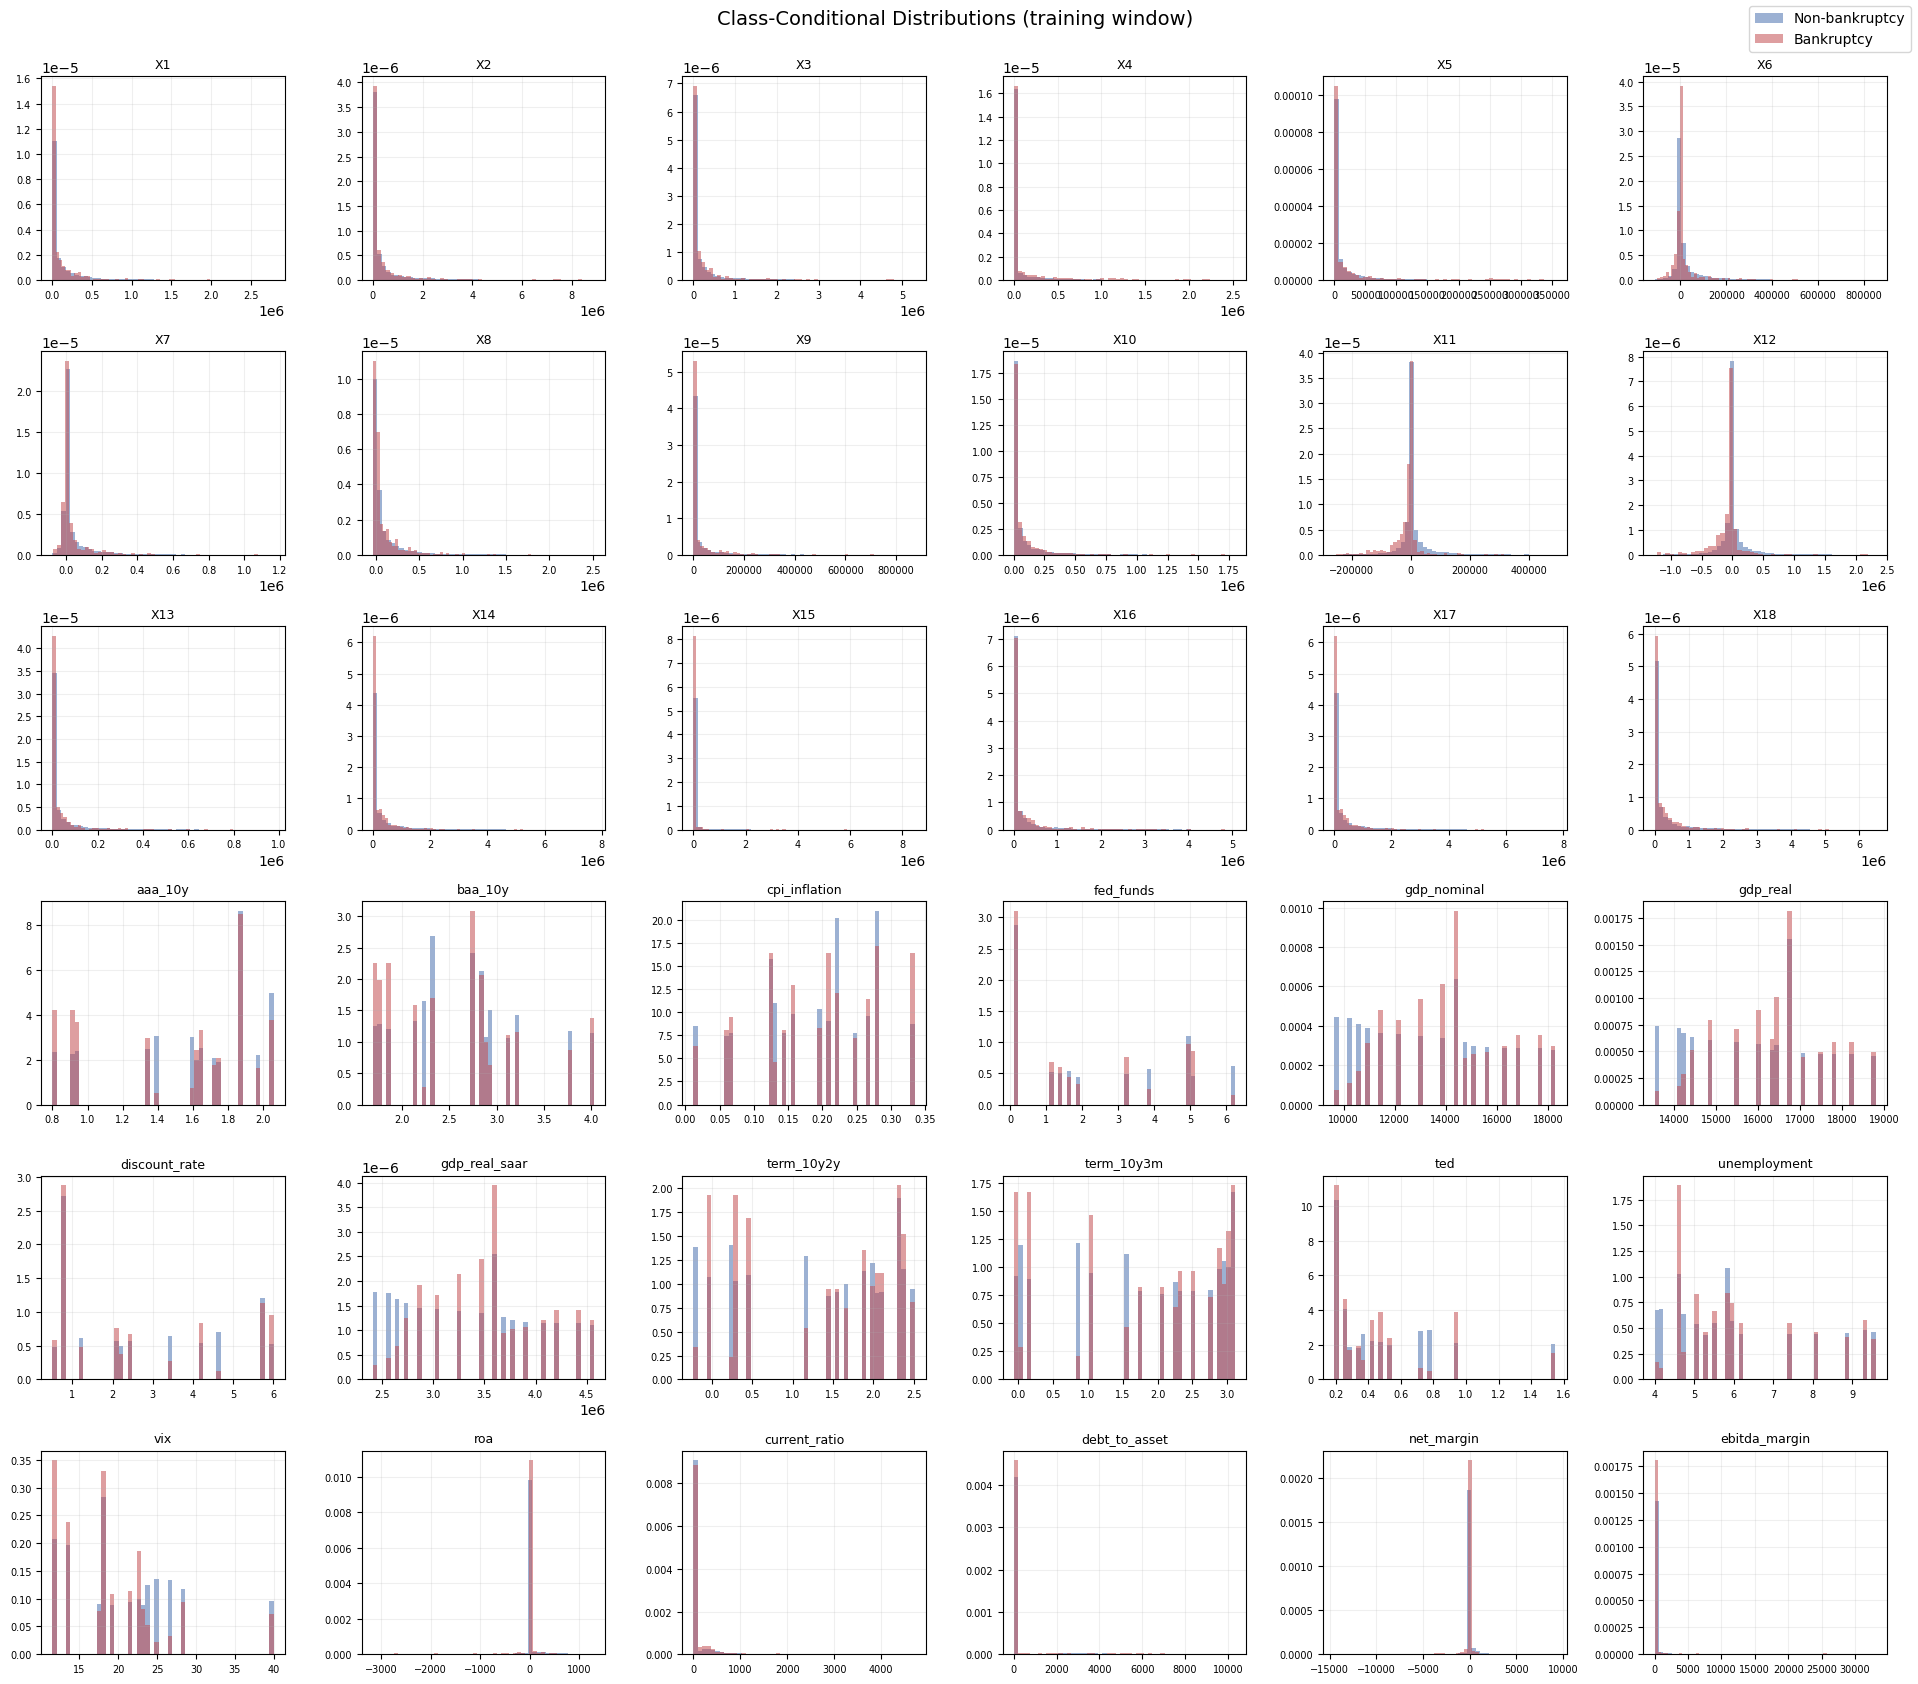

In [40]:
# ============================================================
# SECTION 4.11 — CLASS-CONDITIONAL DISTRIBUTIONS
# ============================================================

ncols = 6
nrows = int(np.ceil(len(numeric_features) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows))
axes = np.array(axes).ravel()

for ax, col in zip(axes, numeric_features):
    data_neg = tr_diag.loc[tr_diag.target_1yr == 0, col].dropna().values
    data_pos = tr_diag.loc[tr_diag.target_1yr == 1, col].dropna().values

    # Clip display range for readability
    lo, hi = np.nanquantile(tr_diag[col].dropna(), [0.01, 0.99])
    data_neg = data_neg[(data_neg >= lo) & (data_neg <= hi)]
    data_pos = data_pos[(data_pos >= lo) & (data_pos <= hi)]

    if len(data_neg) > 0:
        ax.hist(data_neg, bins=50, alpha=0.55, density=True,
                color="#4C72B0", label="0")
    if len(data_pos) > 0:
        ax.hist(data_pos, bins=50, alpha=0.55, density=True,
                color="#C44E52", label="1")
    ax.set_title(col, fontsize=9)
    ax.tick_params(axis="both", labelsize=7)
    ax.grid(alpha=0.2)

# One legend for the figure
handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, ["Non-bankruptcy", "Bankruptcy"],
               loc="upper right", fontsize=10)

for ax in axes[len(numeric_features):]:
    ax.axis("off")

plt.suptitle("Class-Conditional Distributions (training window)",
             fontsize=14, y=1.00)
plt.tight_layout()
plt.savefig(COMPARATIVE / "class_conditional_hist.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

Top 15 features by univariate AUC:
      feature  univariate_auc  n_valid
          X11          0.6991    69231
          X12          0.6706    69231
          roa          0.6309    69231
           X6          0.6269    69231
          X15          0.6207    69231
          vix          0.5976    69231
           X7          0.5856    69231
     gdp_real          0.5759    69231
  gdp_nominal          0.5720    69231
gdp_real_saar          0.5720    69231
           X4          0.5710    69231
      aaa_10y          0.5565    69231
      baa_10y          0.5539    69231
debt_to_asset          0.5503    69231
          X16          0.5350    69231


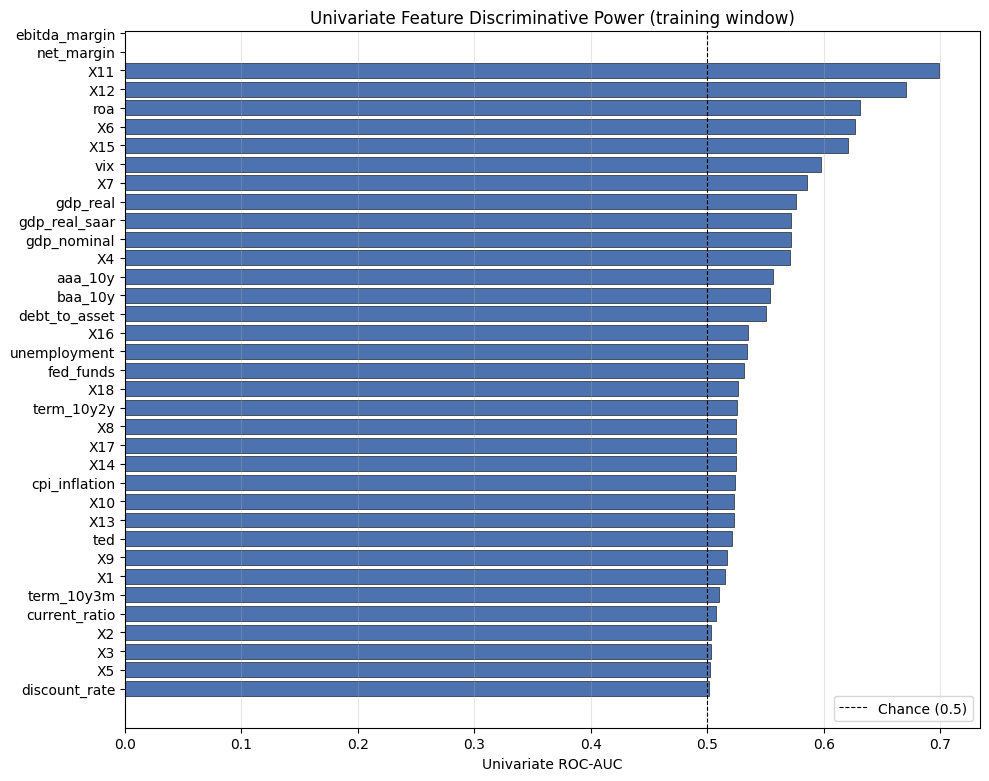

In [41]:
# ============================================================
# SECTION 4.12 — UNIVARIATE AUC PER FEATURE
# ============================================================
# For each feature alone, how well does it separate the two classes?

y_diag = tr_diag["target_1yr"].astype(int).values
uni_rows = []

for col in numeric_features:
    x = tr_diag[col].values
    ok = ~np.isnan(x)
    if ok.sum() < 100 or len(np.unique(y_diag[ok])) < 2:
        continue
    try:
        auc = roc_auc_score(y_diag[ok], x)
        # Orient AUC ≥ 0.5 so ranking is meaningful
        auc = max(auc, 1 - auc)
    except Exception:
        auc = np.nan
    uni_rows.append({
        "feature"       : col,
        "univariate_auc": auc,
        "n_valid"       : int(ok.sum()),
    })

uni_df = pd.DataFrame(uni_rows)\
           .sort_values("univariate_auc", ascending=False)\
           .reset_index(drop=True)
uni_df.to_csv(TABLES_COMP / "univariate_auc.csv", index=False)

print("Top 15 features by univariate AUC:")
print(uni_df.head(15).round(4).to_string(index=False))

# ---- Bar chart ----
fig, ax = plt.subplots(figsize=(10, max(6, len(uni_df) * 0.22)))
top = uni_df.sort_values("univariate_auc")
ax.barh(top["feature"], top["univariate_auc"],
        color="#4C72B0", edgecolor="black", linewidth=0.4)
ax.axvline(0.5, color="black", linestyle="--", linewidth=0.8,
           label="Chance (0.5)")
ax.set_xlabel("Univariate ROC-AUC")
ax.set_title("Univariate Feature Discriminative Power (training window)")
ax.legend()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(COMPARATIVE / "univariate_auc.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

Top 15 features by mutual information:
      feature  mutual_information
 unemployment             0.00235
gdp_real_saar             0.00233
  gdp_nominal             0.00232
      aaa_10y             0.00223
          ted             0.00218
   term_10y2y             0.00214
discount_rate             0.00208
          X11             0.00196
    fed_funds             0.00192
   term_10y3m             0.00188
cpi_inflation             0.00187
     gdp_real             0.00177
          roa             0.00174
      baa_10y             0.00160
          vix             0.00141


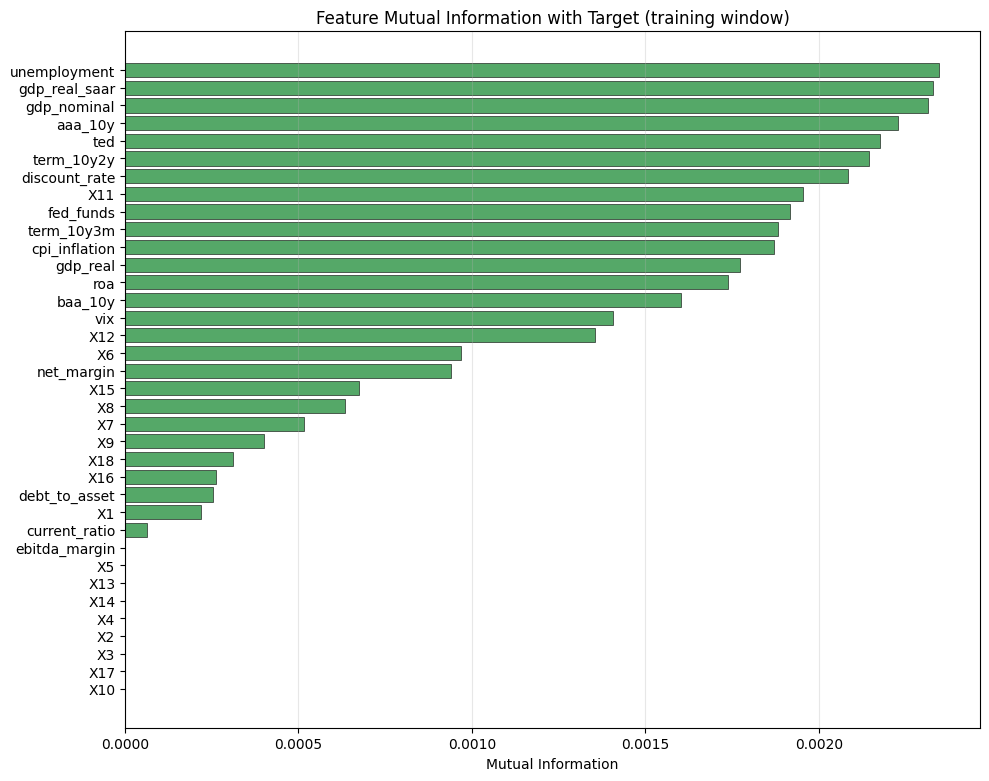


Top 10 by univariate AUC, with MI rank:
      feature  univariate_auc  n_valid  mutual_information  univ_rank  mi_rank
          X11          0.6991    69231              0.0020        1.0      8.0
          X12          0.6706    69231              0.0014        2.0     16.0
          roa          0.6309    69231              0.0017        3.0     13.0
           X6          0.6269    69231              0.0010        4.0     17.0
          X15          0.6207    69231              0.0007        5.0     19.0
          vix          0.5976    69231              0.0014        6.0     15.0
           X7          0.5856    69231              0.0005        7.0     21.0
     gdp_real          0.5759    69231              0.0018        8.0     12.0
gdp_real_saar          0.5720    69231              0.0023        9.5      2.0
  gdp_nominal          0.5720    69231              0.0023        9.5      3.0


In [42]:
# ============================================================
# SECTION 4.13 — MUTUAL INFORMATION PER FEATURE
# ============================================================

from sklearn.feature_selection import mutual_info_classif

# Median-impute a copy for MI (MI cannot handle NaN)
X_mi = tr_diag[numeric_features].copy()
X_mi = X_mi.fillna(X_mi.median())
y_mi = tr_diag["target_1yr"].astype(int).values

mi = mutual_info_classif(
    X_mi.values, y_mi,
    discrete_features=False,
    random_state=SEED,
)

mi_df = pd.DataFrame({
    "feature"           : numeric_features,
    "mutual_information": mi,
}).sort_values("mutual_information", ascending=False)\
  .reset_index(drop=True)
mi_df.to_csv(TABLES_COMP / "mutual_information.csv", index=False)

print("Top 15 features by mutual information:")
print(mi_df.head(15).round(5).to_string(index=False))

# ---- Bar chart ----
fig, ax = plt.subplots(figsize=(10, max(6, len(mi_df) * 0.22)))
top = mi_df.sort_values("mutual_information")
ax.barh(top["feature"], top["mutual_information"],
        color="#55A868", edgecolor="black", linewidth=0.4)
ax.set_xlabel("Mutual Information")
ax.set_title("Feature Mutual Information with Target (training window)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(COMPARATIVE / "mutual_information.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# ---- Combined comparison: univariate AUC vs MI ----
combined = uni_df.merge(mi_df, on="feature", how="outer")
combined["univ_rank"] = combined["univariate_auc"].rank(ascending=False)
combined["mi_rank"]   = combined["mutual_information"].rank(ascending=False)
combined = combined.sort_values("univ_rank").reset_index(drop=True)
combined.to_csv(TABLES_COMP / "univariate_auc_vs_mi.csv", index=False)

print("\nTop 10 by univariate AUC, with MI rank:")
print(combined.head(10).round(4).to_string(index=False))

In [43]:
# ============================================================
# SECTION 4.14 — FINAL FEATURE LIST
# ============================================================

final_table = pd.DataFrame({
    "index" : list(range(len(feature_columns))),
    "feature": feature_columns,
    "type"  : [
        "categorical" if c in categorical_features else "numeric"
        for c in feature_columns
    ],
    "source": [
        "engineered_ratio" if c in RATIO_FEATURES
        else ("categorical" if c in categorical_features
              else ("accounting" if c.startswith("X")
                    else "macro"))
        for c in feature_columns
    ],
})
final_table.to_csv(DIAG_DIR / "final_feature_list.csv", index=False)

print(final_table.to_string(index=False))

# ---- Assertions ----
assert len(feature_columns) == 38
assert final_table["type"].eq("numeric").sum() == 36
assert final_table["type"].eq("categorical").sum() == 2
assert final_table["source"].eq("engineered_ratio").sum() == 5
assert final_table["source"].eq("categorical").sum() == 2
assert final_table["source"].eq("accounting").sum() == 18
assert final_table["source"].eq("macro").sum() == 13

print()
print("✓ Feature composition:")
print("   18 accounting   (X1..X18)")
print("   13 macro        (rates, GDP, VIX, etc.)")
print("    5 engineered   (ratios)")
print("    2 categorical  (Division, MajorGroup)")
print("  ─────────────")
print("   38 total")

 index       feature        type           source
     0            X1     numeric       accounting
     1            X2     numeric       accounting
     2            X3     numeric       accounting
     3            X4     numeric       accounting
     4            X5     numeric       accounting
     5            X6     numeric       accounting
     6            X7     numeric       accounting
     7            X8     numeric       accounting
     8            X9     numeric       accounting
     9           X10     numeric       accounting
    10           X11     numeric       accounting
    11           X12     numeric       accounting
    12           X13     numeric       accounting
    13           X14     numeric       accounting
    14           X15     numeric       accounting
    15           X16     numeric       accounting
    16           X17     numeric       accounting
    17           X18     numeric       accounting
    18      Division categorical      categorical


In [44]:
# ============================================================
# SECTION 4.15 — SUMMARY AND DECISIONS
# ============================================================

summary_md = f"""
## Section 4 — Data Preprocessing Summary

**Training window analysed:** {tr_diag['year'].min()} → {tr_diag['year'].max()}
({len(tr_diag):,} firm-years, {n_pos:,} positives, prevalence {100*prevalence:.4f}%)

### Missing values
- Total features                 : {len(missing)}
- Features with any missing      : {(missing.n_missing > 0).sum()}
- Max missing rate               : {missing.pct_missing.max():.4f}%
- **Decision:** numeric features → median imputation.
  categorical features → most-frequent imputation.
  Both are fit per fold inside the pipeline.

### Target balance
- Negative (0)                   : {n_neg:,} ({100*n_neg/(n_neg+n_pos):.4f}%)
- Positive (1)                   : {n_pos:,} ({100*prevalence:.4f}%)
- Imbalance ratio                : 1 : {n_neg/max(n_pos,1):.2f}
- **Decision:** imbalance handled via the six strategies in Section 3.5.
  Metric selection uses PR-AUC (not ROC-AUC) as the primary ranking.

### Numeric distributions and skewness
- Features with |skew| > 1       : {(sk_df.abs_skew > 1).sum()}
- Features with |skew| > 2       : {(sk_df.abs_skew > 2).sum()}
- Mean |skew| before             : {sk_df.abs_skew.mean():.3f}
- Mean |skew| after Yeo-Johnson  : {sk_compare.abs_after.mean():.3f}
- **Decision:** Yeo-Johnson applied to all numeric features.
  Effectively reduced |skew| on {n_improved} of {len(numeric_features)} features.

### Outliers
- Features with >1% outliers     : {(outlier_df.pct_outliers > 1).sum()}
- Features with >5% outliers     : {(outlier_df.pct_outliers > 5).sum()}
- Total clipped by winsoriser    : {clip_df.n_clipped.sum():,} values
- **Decision:** Winsorisation at 1st / 99th percentile, fitted on
  the training slice of each rolling fold.

### Categorical features
- Levels in Division             : {cat_df[cat_df.feature == 'Division'].shape[0]}
- Levels in MajorGroup           : {cat_df[cat_df.feature == 'MajorGroup'].shape[0]}
- Rare levels (<1% of rows)      : {int(rare.shape[0]) if len(rare) else 0}
- **Decision:** ordinal encoding. Categoricals are NOT scaled,
  so SMOTENC operates on integer codes.

### Correlation
- Pairs with |r| ≥ 0.9           : {len(pairs_df)}
- Pairs with |r| ≥ 0.7           : {len(pairs70_df)}
- **Decision:** all features retained. Correlated features carry
  different signals and SHAP will distribute importance correctly.
  Documented in Section 4.9 for transparency.

### Final feature composition
- Accounting features            : 18 (X1..X18)
- Macro features                 : 13
- Engineered ratios              : 5
- Categorical features           : 2
- **Total**                      : **38**

### Pipeline impact
All four numeric-branch steps (impute, winsorise, Yeo-Johnson, scale)
are fit inside `make_preprocessor()` on the training slice of each
rolling fold — no cross-fold statistics leak into validation or test.
"""

(META / "section_4_summary.md").write_text(summary_md, encoding="utf-8")
print(summary_md)


## Section 4 — Data Preprocessing Summary

**Training window analysed:** 1999 → 2015
(69,231 firm-years, 539 positives, prevalence 0.7786%)

### Missing values
- Total features                 : 38
- Features with any missing      : 2
- Max missing rate               : 24.8776%
- **Decision:** numeric features → median imputation.
  categorical features → most-frequent imputation.
  Both are fit per fold inside the pipeline.

### Target balance
- Negative (0)                   : 68,692 (99.2214%)
- Positive (1)                   : 539 (0.7786%)
- Imbalance ratio                : 1 : 127.44
- **Decision:** imbalance handled via the six strategies in Section 3.5.
  Metric selection uses PR-AUC (not ROC-AUC) as the primary ranking.

### Numeric distributions and skewness
- Features with |skew| > 1       : 23
- Features with |skew| > 2       : 22
- Mean |skew| before             : 21.445
- Mean |skew| after Yeo-Johnson  : 9.046
- **Decision:** Yeo-Johnson applied to all numeric features.


In [45]:
# All outputs written
for p in [
    TABLES_COMP / "missing_values.csv",
    TABLES_COMP / "skewness_before.csv",
    TABLES_COMP / "outliers_iqr.csv",
    TABLES_COMP / "winsorisation_summary.csv",
    TABLES_COMP / "skewness_after.csv",
    TABLES_COMP / "categorical_distribution.csv",
    TABLES_COMP / "univariate_auc.csv",
    TABLES_COMP / "mutual_information.csv",
    DIAG_DIR / "final_feature_list.csv",
    META / "section_4_summary.md",
]:
    assert p.exists(), f"Missing output: {p}"

# Feature composition is exactly as expected
assert final_table[final_table.source.eq("accounting")].shape[0] == 18
assert final_table[final_table.source.eq("macro")].shape[0] == 13
assert final_table[final_table.source.eq("engineered_ratio")].shape[0] == 5
assert final_table[final_table.source.eq("categorical")].shape[0] == 2

print("✓ Section 4 complete. Ready for Section 5.")

✓ Section 4 complete. Ready for Section 5.


In [46]:
# ============================================================
# SECTION 5.1 — FULL EVALUATION FUNCTION
# ============================================================
# Computes:
#   - per-class precision, recall, F1
#   - F2 (recall-weighted)
#   - MCC, balanced accuracy
#   - micro-F1, macro-F1
#   - ROC-AUC, PR-AUC, PR-AUC lift
#   - Brier score, Brier skill score
#   - Type I / Type II error
#   - TN, FP, FN, TP

def evaluate(y_true, y_prob, threshold):
    """
    Full metric suite for binary classification at a fixed threshold.

    Parameters
    ----------
    y_true   : array-like of {0, 1}
    y_prob   : array-like in [0, 1] (predicted probabilities)
    threshold: float in (0, 1)

    Returns
    -------
    dict with all metrics
    """
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob >= threshold).astype(int)

    # Confusion matrix cells
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    # ---- Precision / recall / F1 for both classes ----
    precision_pos = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall_pos    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1_pos        = (2 * precision_pos * recall_pos
                     / (precision_pos + recall_pos)
                     if (precision_pos + recall_pos) > 0 else 0.0)
    # F2 gives recall twice the weight of precision
    beta2 = 4.0
    f2_pos = ((1 + beta2) * precision_pos * recall_pos
              / (beta2 * precision_pos + recall_pos)
              if (beta2 * precision_pos + recall_pos) > 0 else 0.0)

    precision_neg = tn / (tn + fn) if (tn + fn) > 0 else 0.0
    recall_neg    = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1_neg        = (2 * precision_neg * recall_neg
                     / (precision_neg + recall_neg)
                     if (precision_neg + recall_neg) > 0 else 0.0)

    # ---- Aggregate metrics ----
    micro_f1 = f1_score(y_true, y_pred, average="micro", zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    balanced_acc = 0.5 * (recall_pos + recall_neg)

    try:
        mcc = matthews_corrcoef(y_true, y_pred)
    except Exception:
        mcc = np.nan

    accuracy = accuracy_score(y_true, y_pred)

    # ---- Probability-based metrics ----
    has_both_classes = len(np.unique(y_true)) == 2
    if has_both_classes:
        roc_auc = roc_auc_score(y_true, y_prob)
        pr_auc  = average_precision_score(y_true, y_prob)
    else:
        roc_auc = np.nan
        pr_auc  = np.nan

    prevalence = y_true.mean()
    pr_auc_lift = pr_auc / prevalence if (prevalence > 0 and not np.isnan(pr_auc)) else np.nan

    brier = brier_score_loss(y_true, y_prob)

    # Brier skill score vs a baseline predicting the base rate
    base_rate = prevalence
    brier_baseline = np.mean((y_true - base_rate) ** 2)
    brier_skill = (1 - brier / brier_baseline
                   if brier_baseline > 0 else np.nan)

    # ---- Error rates ----
    type_i_error  = fp / (tn + fp) if (tn + fp) > 0 else np.nan
    type_ii_error = fn / (tp + fn) if (tp + fn) > 0 else np.nan

    return {
        # Threshold & confusion matrix
        "threshold"       : float(threshold),
        "tn"              : int(tn),
        "fp"              : int(fp),
        "fn"              : int(fn),
        "tp"              : int(tp),

        # Bankruptcy (positive) class
        "precision"       : precision_pos,
        "recall"          : recall_pos,
        "f1"              : f1_pos,
        "f2"              : f2_pos,

        # Healthy (negative) class
        "precision_neg"   : precision_neg,
        "recall_neg"      : recall_neg,
        "f1_neg"          : f1_neg,

        # Aggregate
        "accuracy"        : accuracy,
        "balanced_accuracy": balanced_acc,
        "mcc"             : mcc,
        "f1_micro"        : micro_f1,
        "f1_macro"        : macro_f1,

        # Probability-based
        "roc_auc"         : roc_auc,
        "pr_auc"          : pr_auc,
        "pr_auc_lift"     : pr_auc_lift,
        "brier"           : brier,
        "brier_skill"     : brier_skill,

        # Error decomposition
        "type_i_error"    : type_i_error,
        "type_ii_error"   : type_ii_error,
    }


# ---- Sanity check on a synthetic case ----
# ---- Sanity check with ONE overlap ----
_y_demo = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
_p_demo = np.array([.05, .15, .25, .45, .40, .55, .65, .75, .85, .95])
_m = evaluate(_y_demo, _p_demo, threshold=0.50)

print("Sanity check (one-overlap demo):")
for k, v in _m.items():
    if isinstance(v, float):
        print(f"  {k:20s}: {v:.4f}")
    else:
        print(f"  {k:20s}: {v}")

# ---- Hand-computed expectations ----
assert _m["tp"] == 5
assert _m["fp"] == 0
assert _m["tn"] == 4
assert _m["fn"] == 1
assert abs(_m["recall"]    - 5/6) < 1e-9
assert abs(_m["precision"] - 1.0) < 1e-9
assert abs(_m["accuracy"]  - 0.9) < 1e-9
assert 0.9 < _m["roc_auc"] < 1.0
assert (_m["tn"] + _m["fp"] + _m["fn"] + _m["tp"]) == len(_y_demo)

print()
print("✓ Demo sanity check passed — all metrics verified.")

Sanity check (one-overlap demo):
  threshold           : 0.5000
  tn                  : 4
  fp                  : 0
  fn                  : 1
  tp                  : 5
  precision           : 1.0000
  recall              : 0.8333
  f1                  : 0.9091
  f2                  : 0.8621
  precision_neg       : 0.8000
  recall_neg          : 1.0000
  f1_neg              : 0.8889
  accuracy            : 0.9000
  balanced_accuracy   : 0.9167
  mcc                 : 0.8165
  f1_micro            : 0.9000
  f1_macro            : 0.8990
  roc_auc             : 0.9583
  pr_auc              : 0.9762
  pr_auc_lift         : 1.6270
  brier               : 0.1062
  brier_skill         : 0.5573
  type_i_error        : 0.0000
  type_ii_error       : 0.1667

✓ Demo sanity check passed — all metrics verified.


In [47]:
# ============================================================
# SECTION 5.2 — THRESHOLD OPTIMISATION
# ============================================================
# Sweep thresholds in [0.01, 0.99], compute F1 at each, and pick:
#   1. The threshold maximising F1
#   2. Optionally smoothed: the threshold maximising the average
#      F1 across a ±SMOOTH_WINDOW neighbourhood — more robust to
#      noise on small validation sets.
#
# Tie-breaking (deterministic):
#   higher F1 → higher recall → higher threshold

THRESHOLD_GRID = np.arange(0.01, 1.00, 0.01)
SMOOTH_WINDOW  = 5   # number of grid points on each side (±0.05)

def _threshold_table(y_true, y_prob):
    """Return DataFrame of precision/recall/F1/F2 across the grid."""
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)

    rows = []
    for t in THRESHOLD_GRID:
        pred = (y_prob >= t).astype(int)
        if pred.sum() == 0:
            p, r, f1, f2 = 0.0, 0.0, 0.0, 0.0
        else:
            p  = precision_score(y_true, pred, zero_division=0)
            r  = recall_score(y_true, pred, zero_division=0)
            f1 = f1_score(y_true, pred, zero_division=0)
            beta2 = 4.0
            f2 = ((1 + beta2) * p * r / (beta2 * p + r)
                  if (beta2 * p + r) > 0 else 0.0)
        rows.append({
            "threshold": float(t),
            "precision": p,
            "recall"   : r,
            "f1"       : f1,
            "f2"       : f2,
        })
    return pd.DataFrame(rows)


def optimise_threshold(y_val, p_val, smooth=True):
    """
    Choose a decision threshold on validation data by maximising F1.
    Optional smoothing averages F1 over a ±SMOOTH_WINDOW neighbourhood.

    Returns
    -------
    best_threshold : float
    table          : pd.DataFrame with precision/recall/F1/F2 across grid
    """
    tab = _threshold_table(y_val, p_val)

    # Optional neighbourhood smoothing of the F1 curve
    if smooth and len(tab) >= 2 * SMOOTH_WINDOW + 1:
        f1 = tab["f1"].values
        smoothed = np.convolve(
            f1,
            np.ones(2 * SMOOTH_WINDOW + 1) / (2 * SMOOTH_WINDOW + 1),
            mode="same",
        )
        tab["f1_smoothed"] = smoothed
        score_col = "f1_smoothed"
    else:
        score_col = "f1"

    # Tie-break: higher score → higher recall → higher threshold
    best = tab.sort_values(
        [score_col, "recall", "threshold"],
        ascending=[False, False, False],
    ).iloc[0]

    return float(best["threshold"]), tab


# ---- Sanity check ----
# ---- Sanity check ----
_t_best, _t_tab = optimise_threshold(_y_demo, _p_demo, smooth=False)
print(f"Sanity check — best threshold: {_t_best:.2f}")
print(f"F1 at best threshold         : "
      f"{_t_tab.loc[_t_tab.threshold.eq(_t_best), 'f1'].iloc[0]:.4f}")
assert 0.01 <= _t_best <= 0.99

Sanity check — best threshold: 0.40
F1 at best threshold         : 0.9231


In [48]:
# ============================================================
# SECTION 5.3 — COST-OPTIMAL THRESHOLD
# ============================================================
# For a cost matrix where a false negative costs `c_fn` and a false
# positive costs `c_fp`, the cost-optimal threshold is the value
# minimising:
#     expected_cost(threshold) = c_fn * FN + c_fp * FP
#
# We compute it separately for several cost ratios:
#     5:1  — moderate asymmetry
#     10:1 — typical for credit risk
#     20:1 — aggressive
#
# Reported alongside the F1-optimal threshold for comparison.

COST_RATIOS = [
    (5,  1, "5:1"),
    (10, 1, "10:1"),
    (20, 1, "20:1"),
]

def cost_optimal_threshold(y_true, y_prob, c_fn, c_fp):
    """
    Return (best_threshold, best_cost, full_table).
    Cost = c_fn * FN + c_fp * FP evaluated at each grid point.
    """
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)

    rows = []
    for t in THRESHOLD_GRID:
        pred = (y_prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        cost = c_fn * fn + c_fp * fp
        rows.append({
            "threshold": float(t),
            "fn": int(fn), "fp": int(fp),
            "tn": int(tn), "tp": int(tp),
            "cost": cost,
        })
    tab = pd.DataFrame(rows)
    best_idx = tab["cost"].idxmin()
    return float(tab.loc[best_idx, "threshold"]), float(tab.loc[best_idx, "cost"]), tab


# ---- Sanity check ----
# ---- Sanity check ----
for c_fn, c_fp, label in COST_RATIOS:
    t_best, cost_min, _ = cost_optimal_threshold(_y_demo, _p_demo, c_fn, c_fp)
    print(f"Cost ratio {label:>5s} | best threshold = {t_best:.2f} | "
          f"min cost = {cost_min:.0f}")
    assert 0.01 <= t_best <= 0.99

Cost ratio   5:1 | best threshold = 0.26 | min cost = 1
Cost ratio  10:1 | best threshold = 0.26 | min cost = 1
Cost ratio  20:1 | best threshold = 0.26 | min cost = 1


In [49]:
# Confusion matrix cells sum to n
assert (_m["tn"] + _m["fp"] + _m["fn"] + _m["tp"]) == len(_y_demo)

# Demo data isn't perfectly separable → AUC is high but < 1
assert 0.9 < _m["roc_auc"] < 1.0

# Threshold optimiser picks a value in the grid
assert 0.01 <= _t_best <= 0.99

# Cost-optimal thresholds shift lower as FN cost grows
t_5,  _, _ = cost_optimal_threshold(_y_demo, _p_demo, 5,  1)
t_20, _, _ = cost_optimal_threshold(_y_demo, _p_demo, 20, 1)
assert t_20 <= t_5, "Higher FN cost should push threshold lower (fewer FN)."

print("✓ Section 5 complete. Ready for Section 6.")

✓ Section 5 complete. Ready for Section 6.


In [50]:
# ============================================================
# SECTION 6.1 — MAIN ROLLING-ORIGIN LOOP
# ============================================================
# For every (fold, model, strategy):
#   1. Slice train / validation / test
#   2. Fit the pipeline on training only
#   3. Predict on validation → optimise threshold
#   4. Predict on test → evaluate at the F1-optimal threshold
#   5. Also evaluate at cost-optimal thresholds
#   6. Record metrics, threshold, predictions, timings
#
# Total fits = 13 folds × 6 models × 6 strategies = 468

# ---- Containers ----
results      = []   # one row per (fold, model, strategy)
predictions  = []   # one row per test prediction
thresholds   = []   # full threshold sweep per (fold, model, strategy)
diagnostics  = []   # success / failure record
timings      = []   # wall-clock seconds per fit

total_fits = len(rolling_splits) * len(MODEL_NAMES) * len(IMBALANCE_STRATEGIES)
counter    = 0

t_start_all = time.time()

for _, sp in rolling_splits.iterrows():
    train_end   = int(sp.train_end)
    val_year    = int(sp.validation_year)
    test_year   = int(sp.test_information_year)
    pred_year   = int(sp.prediction_year)

    tr = df_target[df_target.year <= train_end].copy()
    va = df_target[df_target.year == val_year].copy()
    te = df_target[df_target.year == test_year].copy()

    X_tr = tr[feature_columns]
    X_va = va[feature_columns]
    X_te = te[feature_columns]

    y_tr = tr.target_1yr.astype(int)
    y_va = va.target_1yr.astype(int)
    y_te = te.target_1yr.astype(int)

    for model_name in MODEL_NAMES:
        for strategy in IMBALANCE_STRATEGIES:
            counter += 1
            tag = f"[{counter:3d}/{total_fits}] {model_name:26s} | {strategy:22s} | info {test_year}"
            print(tag)

            try:
                t_fit_start = time.time()

                # ---- Build and fit pipeline ----
                pipe = build_model(model_name, strategy, y_tr)
                pipe.fit(X_tr, y_tr)

                fit_seconds = time.time() - t_fit_start

                # ---- Predict on validation ----
                p_va = pipe.predict_proba(X_va)[:, 1]

                # ---- Threshold optimisation (F1) ----
                threshold, t_tab = optimise_threshold(y_va, p_va, smooth=True)

                # ---- Cost-optimal thresholds ----
                cost_thresholds = {}
                for c_fn, c_fp, label in COST_RATIOS:
                    t_cost, _, _ = cost_optimal_threshold(y_va, p_va, c_fn, c_fp)
                    cost_thresholds[label] = t_cost

                # ---- Predict on test ----
                p_te = pipe.predict_proba(X_te)[:, 1]

                # ---- Evaluate at the F1-optimal threshold ----
                met = evaluate(y_te, p_te, threshold)

                # ---- Evaluate at each cost-optimal threshold ----
                cost_metrics = {}
                for label, t_cost in cost_thresholds.items():
                    m_cost = evaluate(y_te, p_te, t_cost)
                    cost_metrics[label] = m_cost

                # ---- Store result row ----
                results.append({
                    "model": model_name,
                    "imbalance_strategy": strategy,
                    "train_start": int(sp.train_start),
                    "train_end": train_end,
                    "validation_year": val_year,
                    "test_information_year": test_year,
                    "prediction_year": pred_year,
                    "train_n": len(tr),
                    "validation_n": len(va),
                    "test_n": len(te),
                    "train_defaults": int(y_tr.sum()),
                    "validation_defaults": int(y_va.sum()),
                    "test_defaults": int(y_te.sum()),
                    "train_default_rate": y_tr.mean(),
                    "validation_default_rate": y_va.mean(),
                    "test_default_rate": y_te.mean(),
                    "optimal_threshold": threshold,
                    "threshold_5to1":  cost_thresholds["5:1"],
                    "threshold_10to1": cost_thresholds["10:1"],
                    "threshold_20to1": cost_thresholds["20:1"],
                    "fit_seconds": fit_seconds,
                    **met,
                })

                # ---- Threshold sweep table ----
                tt = t_tab.assign(
                    model=model_name,
                    imbalance_strategy=strategy,
                    test_information_year=test_year,
                    prediction_year=pred_year,
                )
                thresholds.append(tt)

                # ---- Per-row test predictions ----
                pf = te[["company_name", "year", "prediction_year", "target_1yr"]].copy()
                pf["model"]              = model_name
                pf["imbalance_strategy"] = strategy
                pf["probability"]        = p_te
                pf["threshold"]          = threshold
                pf["prediction"]         = (p_te >= threshold).astype(int)
                predictions.append(pf)

                # ---- Timing ----
                timings.append({
                    "model": model_name,
                    "imbalance_strategy": strategy,
                    "test_information_year": test_year,
                    "fit_seconds": fit_seconds,
                })

                # ---- Diagnostics ----
                diagnostics.append({
                    "model": model_name,
                    "imbalance_strategy": strategy,
                    "test_information_year": test_year,
                    "status": "success",
                })

            except Exception as e:
                diagnostics.append({
                    "model": model_name,
                    "imbalance_strategy": strategy,
                    "test_information_year": test_year,
                    "status": f"error: {type(e).__name__}: {e}",
                })
                print(f"  ERROR: {type(e).__name__}: {e}")

total_seconds = time.time() - t_start_all
print()
print(f"✓ Finished {total_fits} fits in {total_seconds/60:.1f} minutes.")

# ---- Assemble DataFrames ----
rolling_results_df     = pd.DataFrame(results)
rolling_predictions_df = pd.concat(predictions, ignore_index=True) if predictions else pd.DataFrame()
threshold_results_df   = pd.concat(thresholds,  ignore_index=True) if thresholds  else pd.DataFrame()
fit_diagnostics_df     = pd.DataFrame(diagnostics)
fit_times_df           = pd.DataFrame(timings)

print()
print("Shapes:")
print(f"  rolling_results_df     : {rolling_results_df.shape}")
print(f"  rolling_predictions_df : {rolling_predictions_df.shape}")
print(f"  threshold_results_df   : {threshold_results_df.shape}")
print(f"  fit_diagnostics_df     : {fit_diagnostics_df.shape}")
print(f"  fit_times_df           : {fit_times_df.shape}")

[  1/468] Logistic Regression        | Native                 | info 2005
[  2/468] Logistic Regression        | Class Weighted         | info 2005
[  3/468] Logistic Regression        | SMOTE                  | info 2005
[  4/468] Logistic Regression        | SMOTETomek             | info 2005
[  5/468] Logistic Regression        | Random Undersampling   | info 2005
[  6/468] Logistic Regression        | Random Oversampling    | info 2005
[  7/468] Random Forest              | Native                 | info 2005
[  8/468] Random Forest              | Class Weighted         | info 2005
[  9/468] Random Forest              | SMOTE                  | info 2005
[ 10/468] Random Forest              | SMOTETomek             | info 2005
[ 11/468] Random Forest              | Random Undersampling   | info 2005
[ 12/468] Random Forest              | Random Oversampling    | info 2005
[ 13/468] XGBoost                    | Native                 | info 2005
[ 14/468] XGBoost                    |

In [51]:
# ============================================================
# SECTION 6.2 — POST-LOOP SANITY CHECKS AND PERSISTENCE
# ============================================================

# ---- 1. Every fit succeeded ----
n_errors = fit_diagnostics_df[~fit_diagnostics_df.status.eq("success")].shape[0]
if n_errors > 0:
    print(f"⚠ {n_errors} fit(s) failed. Details:")
    print(fit_diagnostics_df[~fit_diagnostics_df.status.eq("success")]
          .to_string(index=False))
else:
    print(f"✓ All {len(fit_diagnostics_df)} fits succeeded.")

# ---- 2. Row count matches expectation ----
expected_rows = len(rolling_splits) * len(MODEL_NAMES) * len(IMBALANCE_STRATEGIES)
assert len(rolling_results_df) == expected_rows, (
    f"Expected {expected_rows} result rows, got {len(rolling_results_df)}"
)
print(f"✓ Rolling results row count: {len(rolling_results_df)} (expected {expected_rows}).")

# ---- 3. Threshold always in (0, 1) ----
t_min = rolling_results_df["optimal_threshold"].min()
t_max = rolling_results_df["optimal_threshold"].max()
assert 0 < t_min <= t_max < 1, (
    f"Threshold out of range: min={t_min}, max={t_max}"
)
print(f"✓ Optimal thresholds in ({t_min:.2f}, {t_max:.2f}).")

# ---- 4. No NaN in critical metrics ----
critical_cols = ["f1", "roc_auc", "pr_auc", "precision", "recall",
                 "mcc", "accuracy"]
nan_counts = rolling_results_df[critical_cols].isna().sum()
if nan_counts.sum() > 0:
    print("⚠ NaN detected in critical metric columns:")
    print(nan_counts[nan_counts > 0].to_string())
else:
    print(f"✓ No NaN in critical metric columns.")

# ---- 5. Probability range ----
p_min = rolling_predictions_df["probability"].min()
p_max = rolling_predictions_df["probability"].max()
assert 0 <= p_min and p_max <= 1, (
    f"Probabilities out of range: min={p_min}, max={p_max}"
)
print(f"✓ Prediction probabilities in [{p_min:.4f}, {p_max:.4f}].")

# ---- 6. Confusion cells sum to test_n per row ----
cm_sum = (rolling_results_df["tn"] + rolling_results_df["fp"]
          + rolling_results_df["fn"] + rolling_results_df["tp"])
assert (cm_sum == rolling_results_df["test_n"]).all(), (
    "Confusion matrix cells do not sum to test_n in some rows."
)
print("✓ Confusion cells sum to test_n in every row.")

# ---- 7. All 36 (model, strategy) combinations present ----
expected_pairs = {
    (m, s) for m in MODEL_NAMES for s in IMBALANCE_STRATEGIES
}
found_pairs = set(zip(rolling_results_df.model,
                      rolling_results_df.imbalance_strategy))
missing_pairs = expected_pairs - found_pairs
assert len(missing_pairs) == 0, f"Missing (model, strategy) pairs: {missing_pairs}"
print(f"✓ All {len(expected_pairs)} (model, strategy) combinations present.")

# ---- 8. Timing sanity ----
median_fit = fit_times_df["fit_seconds"].median()
max_fit    = fit_times_df["fit_seconds"].max()
print(f"✓ Fit times: median {median_fit:.2f}s, max {max_fit:.2f}s.")

# ---- 9. Persist artefacts ----
rolling_results_df.to_csv(RAW_DIR / "rolling_results.csv", index=False)
rolling_predictions_df.to_csv(RAW_DIR / "rolling_predictions.csv", index=False)
threshold_results_df.to_csv(RAW_DIR / "threshold_results.csv", index=False)
fit_diagnostics_df.to_csv(DIAG_DIR / "fit_diagnostics.csv", index=False)
fit_times_df.to_csv(RAW_DIR / "fit_times.csv", index=False)

print()
print("✓ Artefacts saved:")
print(f"  {RAW_DIR / 'rolling_results.csv'}")
print(f"  {RAW_DIR / 'rolling_predictions.csv'}")
print(f"  {RAW_DIR / 'threshold_results.csv'}")
print(f"  {RAW_DIR / 'fit_times.csv'}")
print(f"  {DIAG_DIR / 'fit_diagnostics.csv'}")

✓ All 468 fits succeeded.
✓ Rolling results row count: 468 (expected 468).
✓ Optimal thresholds in (0.01, 0.99).
✓ No NaN in critical metric columns.
✓ Prediction probabilities in [0.0000, 1.0000].
✓ Confusion cells sum to test_n in every row.
✓ All 36 (model, strategy) combinations present.
✓ Fit times: median 10.94s, max 3087.66s.

✓ Artefacts saved:
  Rolling_results_now\raw_dir\rolling_results.csv
  Rolling_results_now\raw_dir\rolling_predictions.csv
  Rolling_results_now\raw_dir\threshold_results.csv
  Rolling_results_now\raw_dir\fit_times.csv
  Rolling_results_now\diag_dir\fit_diagnostics.csv


In [52]:
# Every model × strategy × fold is present
assert len(rolling_results_df) == 468

# No NaN in the primary metrics
for col in ["f1", "roc_auc", "pr_auc", "mcc"]:
    assert rolling_results_df[col].notna().all(), f"NaN in {col}"

# Thresholds in range
assert rolling_results_df["optimal_threshold"].between(0.01, 0.99).all()

# Confusion cells sum correctly
assert ((rolling_results_df.tn + rolling_results_df.fp +
         rolling_results_df.fn + rolling_results_df.tp)
        == rolling_results_df.test_n).all()

# All artefacts saved
for p in [
    RAW_DIR / "rolling_results.csv",
    RAW_DIR / "rolling_predictions.csv",
    RAW_DIR / "threshold_results.csv",
    RAW_DIR / "fit_times.csv",
    DIAG_DIR / "fit_diagnostics.csv",
]:
    assert p.exists(), f"Missing: {p}"

print("✓ Section 6 complete. Ready for Section 7.")

✓ Section 6 complete. Ready for Section 7.


In [53]:
# ============================================================
# SECTION 7.1 — MASTER SUMMARY TABLE
# ============================================================
# Aggregate rolling_results_df per (model, imbalance_strategy):
#   - mean and std of every metric
#   - bootstrap 95% CI on the mean
# Sorted by PRIMARY_RANK_METRIC (pr_auc_mean).

METRICS_FOR_SUMMARY = [
    "accuracy", "balanced_accuracy", "mcc",
    "f1_micro", "f1_macro",
    "precision", "recall", "f1", "f2",
    "precision_neg", "recall_neg", "f1_neg",
    "roc_auc", "pr_auc", "pr_auc_lift",
    "brier", "brier_skill",
    "type_i_error", "type_ii_error",
    "tn", "fp", "fn", "tp",          # ← ADD THIS LINE
    "optimal_threshold",
]

def _bootstrap_ci(values, n_boot=N_BOOTSTRAP, alpha=0.05, seed=SEED):
    """95% bootstrap CI on the mean of `values`."""
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    if len(values) < 2:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    means = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    lo, hi = np.quantile(means, [alpha / 2, 1 - alpha / 2])
    return lo, hi


summary_rows = []
for (model, strategy), grp in rolling_results_df.groupby(
        ["model", "imbalance_strategy"]):

    row = {
        "model": model,
        "imbalance_strategy": strategy,
        "n_windows": len(grp),
    }

    for m in METRICS_FOR_SUMMARY:
        vals = grp[m].values
        row[f"{m}_mean"] = np.nanmean(vals)
        row[f"{m}_std"]  = np.nanstd(vals, ddof=1)
        lo, hi = _bootstrap_ci(vals)
        row[f"{m}_ci_lo"] = lo
        row[f"{m}_ci_hi"] = hi

    summary_rows.append(row)

summary = pd.DataFrame(summary_rows)

# Sort by PRIMARY_RANK_METRIC (pr_auc_mean by default), F1 as secondary
sort_primary = f"{PRIMARY_RANK_METRIC}"
sort_secondary = "f1_mean"
summary = summary.sort_values(
    [sort_primary, sort_secondary], ascending=False
).reset_index(drop=True)

summary.to_csv(TABLES_COMP / "comparative_summary.csv", index=False)

print(f"Summary table shape: {summary.shape}")
print(f"Sorted by: {sort_primary}")
print()
print("Top 15 (model, strategy) combinations:")
show_cols = ["model", "imbalance_strategy",
             "pr_auc_mean", "pr_auc_ci_lo", "pr_auc_ci_hi",
             "f1_mean", "roc_auc_mean", "mcc_mean"]
print(summary[show_cols].head(15).round(4).to_string(index=False))

Summary table shape: (36, 99)
Sorted by: pr_auc_mean

Top 15 (model, strategy) combinations:
              model   imbalance_strategy  pr_auc_mean  pr_auc_ci_lo  pr_auc_ci_hi  f1_mean  roc_auc_mean  mcc_mean
            XGBoost               Native       0.0615        0.0391        0.0893   0.0670        0.7705    0.0709
      Random Forest               Native       0.0548        0.0400        0.0708   0.0793        0.7739    0.0894
            XGBoost  Random Oversampling       0.0502        0.0267        0.0802   0.0574        0.7328    0.0613
           CatBoost               Native       0.0484        0.0336        0.0655   0.0599        0.7638    0.0670
           LightGBM               Native       0.0457        0.0284        0.0663   0.0577        0.7578    0.0580
      Random Forest       Class Weighted       0.0444        0.0294        0.0637   0.0516        0.7704    0.0561
           LightGBM  Random Oversampling       0.0443        0.0266        0.0653   0.0499        0.73

In [54]:
# ============================================================
# SECTION 7.2 — NAIVE BASELINES
# ============================================================
# Two trivial predictors evaluated on the same test folds:
#   (A) always predict 0
#   (B) predict constant = training prevalence
#
# These establish lower bounds for every metric.

def evaluate_always_zero(y_true):
    y_true = np.asarray(y_true).astype(int)
    n = len(y_true)
    n_pos = int(y_true.sum())
    tn, fp, fn, tp = n - n_pos, 0, n_pos, 0

    prevalence = y_true.mean()
    return {
        "threshold": 0.5,
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "precision": 0.0,
        "recall": 0.0,
        "f1": 0.0,
        "f2": 0.0,
        "precision_neg": tn / (tn + fn) if (tn + fn) > 0 else 0.0,
        "recall_neg": 1.0,
        "f1_neg": (2 * (tn / (tn + fn)) * 1.0
                   / ((tn / (tn + fn)) + 1.0)) if (tn + fn) > 0 else 0.0,
        "accuracy": (tn + tp) / n,
        "balanced_accuracy": 0.5 * (0.0 + 1.0),
        "mcc": 0.0,
        "f1_micro": (tn + tp) / n,
        "f1_macro": (0.0 + ((2 * (tn / (tn + fn)) * 1.0
                             / ((tn / (tn + fn)) + 1.0))
                            if (tn + fn) > 0 else 0.0)) / 2,
        "roc_auc": 0.5,
        "pr_auc": prevalence,
        "pr_auc_lift": 1.0,
        "brier": float(np.mean((y_true - prevalence) ** 2)),
        "brier_skill": 0.0,
        "type_i_error": 0.0,
        "type_ii_error": 1.0,
    }


def evaluate_base_rate(y_true, train_prevalence):
    y_true = np.asarray(y_true).astype(int)
    n = len(y_true)
    p = float(train_prevalence)
    # Predictions at threshold 0.5 → p < 0.5 always → all predicted 0
    # So base-rate predictions behave like always-zero at threshold 0.5
    m = evaluate_always_zero(y_true)
    # But probability metrics change because we predict p for everyone:
    m["brier"] = float(np.mean((y_true - p) ** 2))
    base_rate = y_true.mean()
    brier_baseline = np.mean((y_true - base_rate) ** 2)
    m["brier_skill"] = 1 - m["brier"] / brier_baseline
    m["pr_auc"] = base_rate
    m["pr_auc_lift"] = 1.0
    return m


baseline_rows = []
for _, sp in rolling_splits.iterrows():
    tr = df_target[df_target.year <= int(sp.train_end)]
    te = df_target[df_target.year == int(sp.test_information_year)]
    y_tr = tr.target_1yr.astype(int)
    y_te = te.target_1yr.astype(int)

    for label, fn in [("Always Zero", lambda y: evaluate_always_zero(y)),
                      ("Base Rate",  lambda y: evaluate_base_rate(y, y_tr.mean()))]:
        m = fn(y_te)
        baseline_rows.append({
            "model": label,
            "imbalance_strategy": "—",
            "test_information_year": int(sp.test_information_year),
            "prediction_year": int(sp.prediction_year),
            "train_n": len(tr),
            "validation_n": 0,
            "test_n": len(te),
            "train_defaults": int(y_tr.sum()),
            "validation_defaults": 0,
            "test_defaults": int(y_te.sum()),
            "train_default_rate": y_tr.mean(),
            "validation_default_rate": np.nan,
            "test_default_rate": y_te.mean(),
            "fit_seconds": 0.0,
            "optimal_threshold": 0.5,
            "threshold_5to1": 0.5, "threshold_10to1": 0.5, "threshold_20to1": 0.5,
            **m,
        })

baselines_df = pd.DataFrame(baseline_rows)
baselines_df.to_csv(TABLES_COMP / "baselines_results.csv", index=False)

# Aggregate per baseline
baseline_summary = (
    baselines_df
    .groupby("model")[METRICS_FOR_SUMMARY]
    .mean()
    .round(4)
    .reset_index()
)
baseline_summary.to_csv(TABLES_COMP / "baselines_summary.csv", index=False)

print("Naive baselines (mean across folds):")
print(baseline_summary.to_string(index=False))
print()
print("Interpretation:")
print("  Always Zero — reference for 'no predictive power on positives'")
print("  Base Rate   — reference for 'no information beyond class prior'")

Naive baselines (mean across folds):
      model  accuracy  balanced_accuracy  mcc  f1_micro  f1_macro  precision  recall  f1  f2  precision_neg  recall_neg  f1_neg  roc_auc  pr_auc  pr_auc_lift  brier  brier_skill  type_i_error  type_ii_error        tn  fp      fn  tp  optimal_threshold
Always Zero    0.9905                0.5  0.0    0.9905    0.4976        0.0     0.0 0.0 0.0         0.9905         1.0  0.9952      0.5  0.0095          1.0 0.0094       0.0000           0.0            1.0 3554.1538 0.0 34.3846 0.0                0.5
  Base Rate    0.9905                0.5  0.0    0.9905    0.4976        0.0     0.0 0.0 0.0         0.9905         1.0  0.9952      0.5  0.0095          1.0 0.0094      -0.0015           0.0            1.0 3554.1538 0.0 34.3846 0.0                0.5

Interpretation:
  Always Zero — reference for 'no predictive power on positives'
  Base Rate   — reference for 'no information beyond class prior'


In [55]:
# ============================================================
# SECTION 7.3 — PR-AUC LIFT
# ============================================================
# lift = PR-AUC / prevalence
# Represents how much better than random the model ranks positives.

lift_df = summary[[
    "model", "imbalance_strategy",
    "pr_auc_mean", "pr_auc_ci_lo", "pr_auc_ci_hi",
    "f1_mean", "roc_auc_mean", "mcc_mean",
]].copy()

# Compute mean prevalence across test folds
mean_prevalence = rolling_results_df["test_default_rate"].mean()
lift_df["prevalence"] = mean_prevalence
lift_df["lift"] = lift_df["pr_auc_mean"] / mean_prevalence
lift_df["lift_ci_lo"] = lift_df["pr_auc_ci_lo"] / mean_prevalence
lift_df["lift_ci_hi"] = lift_df["pr_auc_ci_hi"] / mean_prevalence

lift_df = lift_df.sort_values("lift", ascending=False).reset_index(drop=True)
lift_df.to_csv(TABLES_COMP / "pr_auc_lift.csv", index=False)

print(f"Mean test prevalence: {mean_prevalence:.5f}")
print()
print("Top 15 (model, strategy) by PR-AUC lift:")
show = ["model", "imbalance_strategy", "pr_auc_mean",
        "lift", "lift_ci_lo", "lift_ci_hi", "f1_mean"]
print(lift_df[show].head(15).round(4).to_string(index=False))

Mean test prevalence: 0.00947

Top 15 (model, strategy) by PR-AUC lift:
              model   imbalance_strategy  pr_auc_mean   lift  lift_ci_lo  lift_ci_hi  f1_mean
            XGBoost               Native       0.0615 6.4986      4.1303      9.4335   0.0670
      Random Forest               Native       0.0548 5.7871      4.2234      7.4735   0.0793
            XGBoost  Random Oversampling       0.0502 5.3038      2.8176      8.4660   0.0574
           CatBoost               Native       0.0484 5.1086      3.5499      6.9218   0.0599
           LightGBM               Native       0.0457 4.8306      3.0020      7.0036   0.0577
      Random Forest       Class Weighted       0.0444 4.6925      3.1071      6.7324   0.0516
           LightGBM  Random Oversampling       0.0443 4.6803      2.8093      6.8971   0.0499
            XGBoost       Class Weighted       0.0443 4.6782      3.0086      6.8158   0.0576
      Random Forest  Random Oversampling       0.0443 4.6751      3.0177      6.90

In [56]:
# ============================================================
# SECTION 7.4 — PAPER-STYLE BENCHMARK TABLE
# ============================================================
# Mirrors Lombardo et al. (2022) Tables 4/5 format:
#   - Pr / Rec / F1 for each class
#   - Micro-F1, Macro-F1
#   - Type I / Type II error
#   - Confusion matrix cells

import tabulate

bench = summary[[
    "model", "imbalance_strategy", "n_windows",
    "precision_mean",    "recall_mean",    "f1_mean",
    "precision_neg_mean","recall_neg_mean","f1_neg_mean",
    "f1_micro_mean", "f1_macro_mean",
    "type_i_error_mean", "type_ii_error_mean",
    "tn_mean", "fp_mean", "fn_mean", "tp_mean",
    "roc_auc_mean", "pr_auc_mean", "mcc_mean",
]].copy()

bench.columns = [
    "Model", "Strategy", "N",
    "Pr (Bank)", "Rec (Bank)", "F1 (Bank)",
    "Pr (Healthy)", "Rec (Healthy)", "F1 (Healthy)",
    "Micro-F1", "Macro-F1",
    "Type I", "Type II",
    "TN", "FP", "FN", "TP",
    "ROC-AUC", "PR-AUC", "MCC",
]

bench = bench.sort_values(["PR-AUC", "F1 (Bank)"], ascending=False)

# Round numeric columns
for c in bench.columns:
    if bench[c].dtype in [np.float64, np.float32]:
        bench[c] = bench[c].round(4)

bench.to_csv(TABLES_COMP / "paper_style_benchmark.csv", index=False)

print("Paper-style benchmark (top 20):")
print(bench.head(20).to_string(index=False))

# Save a Markdown version for direct inclusion in the dissertation
md_table = bench.head(20).to_markdown(index=False)
(TABLES_COMP / "paper_style_benchmark.md").write_text(md_table, encoding="utf-8")
print()
print("✓ Markdown version saved.")

Paper-style benchmark (top 20):
              Model             Strategy  N  Pr (Bank)  Rec (Bank)  F1 (Bank)  Pr (Healthy)  Rec (Healthy)  F1 (Healthy)  Micro-F1  Macro-F1  Type I  Type II        TN       FP      FN      TP  ROC-AUC  PR-AUC    MCC
            XGBoost               Native 13     0.0587      0.1905     0.0670        0.9919         0.9540        0.9714    0.9466    0.5192  0.0460   0.8095 3392.3846 161.7692 28.6923  5.6923   0.7705  0.0615 0.0709
      Random Forest               Native 13     0.0609      0.3102     0.0793        0.9928         0.9002        0.9396    0.8945    0.5095  0.0998   0.6898 3190.3846 363.7692 24.0769 10.3077   0.7739  0.0548 0.0894
            XGBoost  Random Oversampling 13     0.0370      0.2150     0.0574        0.9920         0.9320        0.9594    0.9252    0.5084  0.0680   0.7850 3305.3077 248.8462 27.3077  7.0769   0.7328  0.0502 0.0613
           CatBoost               Native 13     0.0475      0.2301     0.0599        0.9921         

In [57]:
# ============================================================
# SECTION 7.5 — MODEL CARDS
# ============================================================

import re

def _format_card(row, model, strategy):
    lines = []
    bar = "=" * 72
    lines.append(bar)
    lines.append(f"  {model}  |  {strategy}")
    lines.append(bar)
    lines.append("")

    lines.append("Preprocessing pipeline:")
    lines.append("  Numeric    : impute(median) → winsorise(1,99) → "
                 "YeoJohnson → StandardScaler")
    lines.append("  Categorical: impute(mode) → OrdinalEncoder (no scaling)")
    lines.append("  Output     : 38 features")
    lines.append("")

    lines.append("Rolling design:")
    lines.append(f"  Windows            : {int(row['n_windows'])}")
    lines.append(f"  Train size (mean)  : {row['train_n_mean']:,.0f}")
    lines.append(f"  Val size (mean)    : {row['validation_n_mean']:,.0f}")
    lines.append(f"  Test size (mean)   : {row['test_n_mean']:,.0f}")
    lines.append("")

    lines.append("Threshold (mean ± sd):")
    lines.append(f"  F1-optimal         : {row['optimal_threshold_mean']:.4f} ± "
                 f"{row['optimal_threshold_std']:.4f}")
    lines.append("")

    lines.append("Test metrics (mean [95% CI]):")
    for m, label in [
        ("pr_auc",            "PR-AUC"),
        ("roc_auc",           "ROC-AUC"),
        ("mcc",               "MCC"),
        ("f1",                "F1 (Bank)"),
        ("precision",         "Precision (Bank)"),
        ("recall",            "Recall (Bank)"),
        ("f1_macro",          "Macro-F1"),
        ("balanced_accuracy", "Balanced Accuracy"),
        ("brier",             "Brier"),
    ]:
        mean = row[f"{m}_mean"]
        lo   = row[f"{m}_ci_lo"]
        hi   = row[f"{m}_ci_hi"]
        lines.append(f"  {label:22s}: {mean:.4f}  [{lo:.4f}, {hi:.4f}]")
    lines.append("")

    lines.append("Confusion matrix (mean per fold):")
    tn = row["tn_mean"]; fp = row["fp_mean"]
    fn = row["fn_mean"]; tp = row["tp_mean"]
    lines.append(f"  TN = {tn:>10,.1f}   FP = {fp:>10,.1f}")
    lines.append(f"  FN = {fn:>10,.1f}   TP = {tp:>10,.1f}")
    lines.append("")

    lines.append("Error rates:")
    lines.append(f"  Type I  (FPR) : {row['type_i_error_mean']:.4f}")
    lines.append(f"  Type II (FNR) : {row['type_ii_error_mean']:.4f}")
    lines.append("")

    return "\n".join(lines)


# ---- Aggregate ONLY the columns summary doesn't already have ----
_card_input = (
    rolling_results_df
    .groupby(["model", "imbalance_strategy"])
    .agg(
        train_n_mean     =("train_n", "mean"),
        validation_n_mean=("validation_n", "mean"),
        test_n_mean      =("test_n", "mean"),
    )
    .reset_index()
)

# ---- Merge with collision protection ----
_overlap = (set(summary.columns) & set(_card_input.columns)) \
           - {"model", "imbalance_strategy"}
assert len(_overlap) == 0, \
    f"Overlapping columns before merge: {sorted(_overlap)} — " \
    f"drop them from _card_input."

card_source = summary.merge(
    _card_input, on=["model", "imbalance_strategy"], how="left"
)

# ---- Verify required columns exist ----
_required_cols = [
    "model", "imbalance_strategy", "n_windows",
    "train_n_mean", "validation_n_mean", "test_n_mean",
    "optimal_threshold_mean", "optimal_threshold_std",
    "pr_auc_mean", "pr_auc_ci_lo", "pr_auc_ci_hi",
    "roc_auc_mean", "roc_auc_ci_lo", "roc_auc_ci_hi",
    "mcc_mean", "mcc_ci_lo", "mcc_ci_hi",
    "f1_mean", "f1_ci_lo", "f1_ci_hi",
    "precision_mean", "precision_ci_lo", "precision_ci_hi",
    "recall_mean", "recall_ci_lo", "recall_ci_hi",
    "f1_macro_mean", "f1_macro_ci_lo", "f1_macro_ci_hi",
    "balanced_accuracy_mean", "balanced_accuracy_ci_lo", "balanced_accuracy_ci_hi",
    "brier_mean", "brier_ci_lo", "brier_ci_hi",
    "tn_mean", "fp_mean", "fn_mean", "tp_mean",
    "type_i_error_mean", "type_ii_error_mean",
]
_missing = [c for c in _required_cols if c not in card_source.columns]
assert len(_missing) == 0, f"Missing columns: {_missing}"

# ---- Write cards ----
for _, row in card_source.iterrows():
    safe_m = MODEL_DIRS[row["model"]]
    safe_s = re.sub(r"[^A-Za-z0-9]+", "_", row["imbalance_strategy"].lower())
    card_text = _format_card(row, row["model"], row["imbalance_strategy"])
    path = MODEL_CARDS / f"{safe_m}__{safe_s}.txt"
    path.write_text(card_text, encoding="utf-8")

print(f"✓ {len(card_source)} model cards written to {MODEL_CARDS}")

# ---- Show one example ----
example = card_source.iloc[0]
print()
print(_format_card(example, example["model"], example["imbalance_strategy"]))

✓ 36 model cards written to Rolling_results_now\tables\model_cards

  XGBoost  |  Native

Preprocessing pipeline:
  Numeric    : impute(median) → winsorise(1,99) → YeoJohnson → StandardScaler
  Categorical: impute(mode) → OrdinalEncoder (no scaling)
  Output     : 38 features

Rolling design:
  Windows            : 13
  Train size (mean)  : 47,790
  Val size (mean)    : 3,689
  Test size (mean)   : 3,589

Threshold (mean ± sd):
  F1-optimal         : 0.0446 ± 0.0338

Test metrics (mean [95% CI]):
  PR-AUC                : 0.0615  [0.0391, 0.0893]
  ROC-AUC               : 0.7705  [0.7294, 0.8105]
  MCC                   : 0.0709  [0.0378, 0.1067]
  F1 (Bank)             : 0.0670  [0.0386, 0.0992]
  Precision (Bank)      : 0.0587  [0.0254, 0.0966]
  Recall (Bank)         : 0.1905  [0.0875, 0.3144]
  Macro-F1              : 0.5192  [0.4998, 0.5397]
  Balanced Accuracy     : 0.5723  [0.5335, 0.6184]
  Brier                 : 0.0093  [0.0078, 0.0109]

Confusion matrix (mean per fold):
  TN

In [58]:
# ============================================================
# SECTION 7.6 — BEST STRATEGY PER MODEL (BY PR-AUC)
# ============================================================

# Use PRIMARY_RANK_METRIC for the sort
best_strategy = (
    summary
    .sort_values(PRIMARY_RANK_METRIC, ascending=False)
    .groupby("model")
    .first()
)

best_strategy_df = best_strategy[[
    "imbalance_strategy",
    "pr_auc_mean", "f1_mean", "roc_auc_mean", "mcc_mean",
    "recall_mean", "precision_mean",
]].round(4).reset_index()

best_strategy_df.to_csv(TABLES_COMP / "best_strategy_per_model.csv", index=False)

print(f"Best strategy per model (ranked by {PRIMARY_RANK_METRIC}):")
print(best_strategy_df.to_string(index=False))
print()
print("(As a dict for downstream use):")
best_strategy_dict = best_strategy["imbalance_strategy"].to_dict()
print(best_strategy_dict)

Best strategy per model (ranked by pr_auc_mean):
                    model  imbalance_strategy  pr_auc_mean  f1_mean  roc_auc_mean  mcc_mean  recall_mean  precision_mean
Artificial Neural Network Random Oversampling       0.0323   0.0575        0.6764    0.0562       0.1803          0.0431
                 CatBoost              Native       0.0484   0.0599        0.7638    0.0670       0.2301          0.0475
                 LightGBM              Native       0.0457   0.0577        0.7578    0.0580       0.0993          0.0591
      Logistic Regression              Native       0.0417   0.0562        0.7420    0.0640       0.2688          0.0671
            Random Forest              Native       0.0548   0.0793        0.7739    0.0894       0.3102          0.0609
                  XGBoost              Native       0.0615   0.0670        0.7705    0.0709       0.1905          0.0587

(As a dict for downstream use):
{'Artificial Neural Network': 'Random Oversampling', 'CatBoost': 'Nativ

In [59]:
# ============================================================
# SECTION 7.7 — PREPROCESSING ABLATION
# ============================================================
# Refit the best (model, strategy) per model with three variants:
#   1. Full pipeline (winsorise + Yeo-Johnson) — baseline
#   2. No winsorisation
#   3. No Yeo-Johnson
#   4. No winsorisation AND no Yeo-Johnson
#
# Uses the last fold (info year 2017) for speed.
# Compare F1, PR-AUC, ROC-AUC, Brier.

ABLATION_FOLD_YEAR = 2017   # use the last window

sp = rolling_splits[
    rolling_splits.test_information_year == ABLATION_FOLD_YEAR
].iloc[0]

tr_abl = df_target[df_target.year <= int(sp.train_end)].copy()
va_abl = df_target[df_target.year == int(sp.validation_year)].copy()
te_abl = df_target[df_target.year == int(sp.test_information_year)].copy()

X_tr_abl = tr_abl[feature_columns]
X_va_abl = va_abl[feature_columns]
X_te_abl = te_abl[feature_columns]
y_tr_abl = tr_abl.target_1yr.astype(int)
y_va_abl = va_abl.target_1yr.astype(int)
y_te_abl = te_abl.target_1yr.astype(int)


def _build_model_with_preprocessing(model_name, strategy, pre):
    """
    Build a model pipeline with an EXPLICIT preprocessor instance.
    Mirrors build_model but does not re-create the preprocessor.
    """
    weighted = (strategy == "Class Weighted")
    resampler = make_resampler(strategy)

    if model_name == "Logistic Regression":
        est = LogisticRegression(max_iter=2000,
                                 class_weight="balanced" if weighted else None,
                                 random_state=SEED)
    elif model_name == "Random Forest":
        est = RandomForestClassifier(
            n_estimators=500, min_samples_leaf=5, max_features="sqrt",
            class_weight="balanced" if weighted else None,
            random_state=SEED, n_jobs=-1)
    elif model_name == "XGBoost":
        y_arr = np.asarray(y_tr_abl)
        pos = max(int((y_arr == 1).sum()), 1)
        neg = max(int((y_arr == 0).sum()), 1)
        est = XGBClassifier(
            n_estimators=500, max_depth=4, learning_rate=0.05,
            min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
            reg_lambda=1.0, max_delta_step=1,
            scale_pos_weight=(neg / pos if weighted else 1.0),
            objective="binary:logistic", eval_metric="logloss",
            random_state=SEED, n_jobs=1)
    elif model_name == "LightGBM":
        est = LGBMClassifier(
            n_estimators=500, learning_rate=0.05, num_leaves=31,
            min_child_samples=20,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
            class_weight="balanced" if weighted else None,
            random_state=SEED, n_jobs=1, verbosity=-1,
            deterministic=True, force_row_wise=True)
    elif model_name == "CatBoost":
        est = CatBoostClassifier(
            iterations=500, depth=6, learning_rate=0.05,
            loss_function="Logloss", eval_metric="AUC",
            auto_class_weights="Balanced" if weighted else None,
            random_seed=SEED, verbose=False, thread_count=1)
    elif model_name == "Artificial Neural Network":
        return build_ann_pipeline(weighted, pre, resampler)
    else:
        raise ValueError(model_name)

    if resampler is not None:
        return ImbPipeline([("preprocessor", pre),
                            ("resampler", resampler),
                            ("model", est)])
    return Pipeline([("preprocessor", pre), ("model", est)])


ablation_variants = [
    ("Full (winsorise + YeoJohnson)",  dict(winsorize=True,  correct_skew=True)),
    ("No winsorisation",               dict(winsorize=False, correct_skew=True)),
    ("No Yeo-Johnson",                 dict(winsorize=True,  correct_skew=False)),
    ("Neither",                        dict(winsorize=False, correct_skew=False)),
]

ablation_rows = []

for model_name in MODEL_NAMES:
    strat = best_strategy_dict[model_name]
    for label, kwargs in ablation_variants:
        print(f"  Ablation: {model_name:26s} | {strat:22s} | {label}")
        pre = make_preprocessor(scale=True, **kwargs)
        pipe = _build_model_with_preprocessing(model_name, strat, pre)
        try:
            pipe.fit(X_tr_abl, y_tr_abl)
            p_va = pipe.predict_proba(X_va_abl)[:, 1]
            threshold, _ = optimise_threshold(y_va_abl, p_va, smooth=True)
            p_te = pipe.predict_proba(X_te_abl)[:, 1]
            m = evaluate(y_te_abl, p_te, threshold)
            ablation_rows.append({
                "model": model_name,
                "strategy": strat,
                "variant": label,
                "threshold": threshold,
                **{k: m[k] for k in
                   ["f1", "pr_auc", "roc_auc", "mcc",
                    "precision", "recall", "brier"]},
            })
        except Exception as e:
            print(f"    ERROR: {type(e).__name__}: {e}")
            ablation_rows.append({
                "model": model_name,
                "strategy": strat,
                "variant": label,
                "error": str(e),
            })

ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv(TABLES_COMP / "preprocessing_ablation.csv", index=False)

print()
print("Preprocessing ablation results:")
print(ablation_df.round(4).to_string(index=False))

  Ablation: Logistic Regression        | Native                 | Full (winsorise + YeoJohnson)
  Ablation: Logistic Regression        | Native                 | No winsorisation
  Ablation: Logistic Regression        | Native                 | No Yeo-Johnson
  Ablation: Logistic Regression        | Native                 | Neither
  Ablation: Random Forest              | Native                 | Full (winsorise + YeoJohnson)
  Ablation: Random Forest              | Native                 | No winsorisation
  Ablation: Random Forest              | Native                 | No Yeo-Johnson
  Ablation: Random Forest              | Native                 | Neither
  Ablation: XGBoost                    | Native                 | Full (winsorise + YeoJohnson)
  Ablation: XGBoost                    | Native                 | No winsorisation
  Ablation: XGBoost                    | Native                 | No Yeo-Johnson
  Ablation: XGBoost                    | Native                 | Neithe

In [60]:
# ============================================================
# SECTION 8.1 — PER-MODEL TEMPORAL LINE PLOTS
# ============================================================
# For each model and each metric, plot metric-vs-prediction-year
# with one line per imbalance strategy.

TEMPORAL_METRICS = [
    ("f1",                "F1 (Default)"),
    ("f1_macro",          "Macro-F1"),
    ("mcc",               "MCC"),
    ("roc_auc",           "ROC-AUC"),
    ("pr_auc",            "PR-AUC"),
    ("pr_auc_lift",       "PR-AUC Lift"),
    ("precision",         "Precision (Default)"),
    ("recall",            "Recall (Default)"),
    ("balanced_accuracy", "Balanced Accuracy"),
]

def _temporal_plot(model_name, metric, ylabel, save_path):
    sub = rolling_results_df[rolling_results_df.model.eq(model_name)]

    fig, ax = plt.subplots(figsize=(12, 6))

    for s in IMBALANCE_STRATEGIES:
        x = sub[sub.imbalance_strategy.eq(s)].sort_values("prediction_year")
        if len(x) == 0:
            continue
        ax.plot(
            x.prediction_year, x[metric],
            marker="o", markersize=5, linewidth=1.6, label=s,
        )

    ax.set_xlabel("Prediction year", fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(f"{model_name} — {ylabel} across rolling prediction years",
                 fontsize=13, fontweight="bold")
    ax.grid(alpha=0.3)
    ax.legend(loc="best", fontsize=9, frameon=True)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close()


for model_name in MODEL_NAMES:
    folder = MODEL_DIRS[model_name]
    for metric, label in TEMPORAL_METRICS:
        _temporal_plot(
            model_name, metric, label,
             f"{metric}_temporal.png",
        )

print(f"✓ Per-model temporal plots saved.")
print(f"  Models: {len(MODEL_NAMES)}")
print(f"  Metrics per model: {len(TEMPORAL_METRICS)}")
print(f"  Total plots: {len(MODEL_NAMES) * len(TEMPORAL_METRICS)}")

✓ Per-model temporal plots saved.
  Models: 6
  Metrics per model: 9
  Total plots: 54


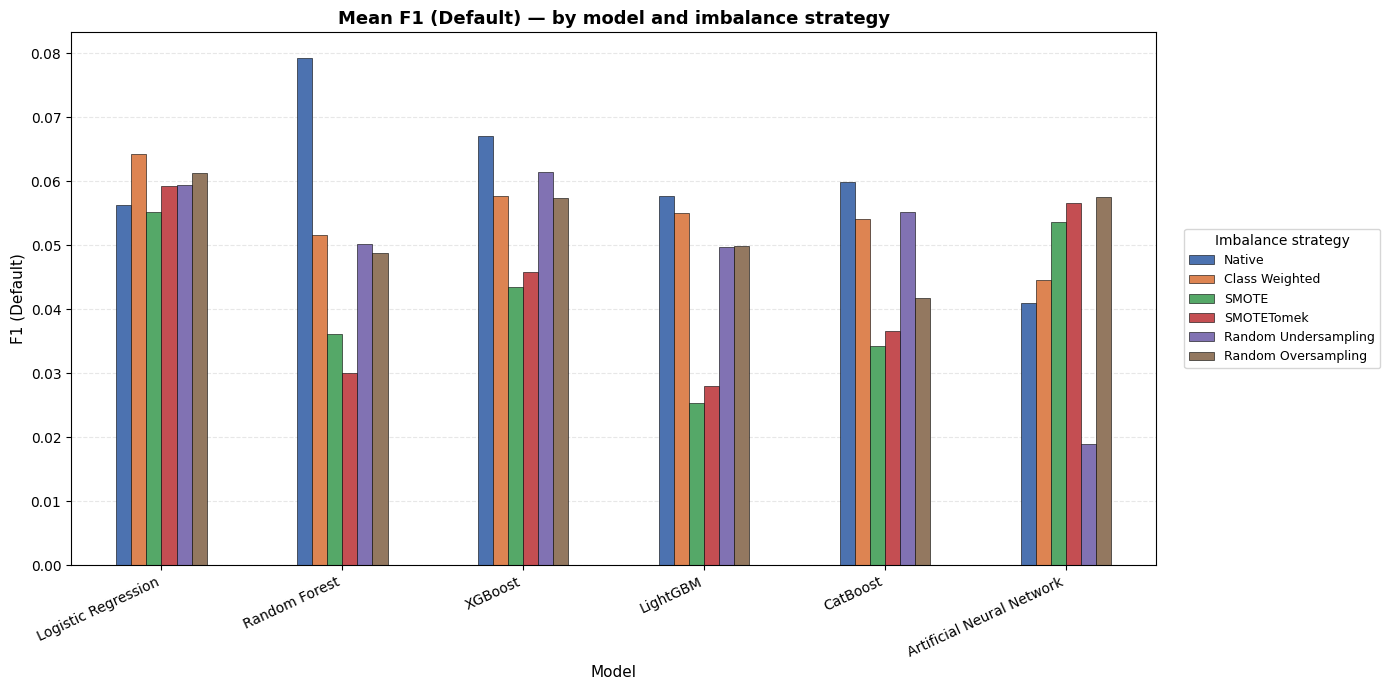

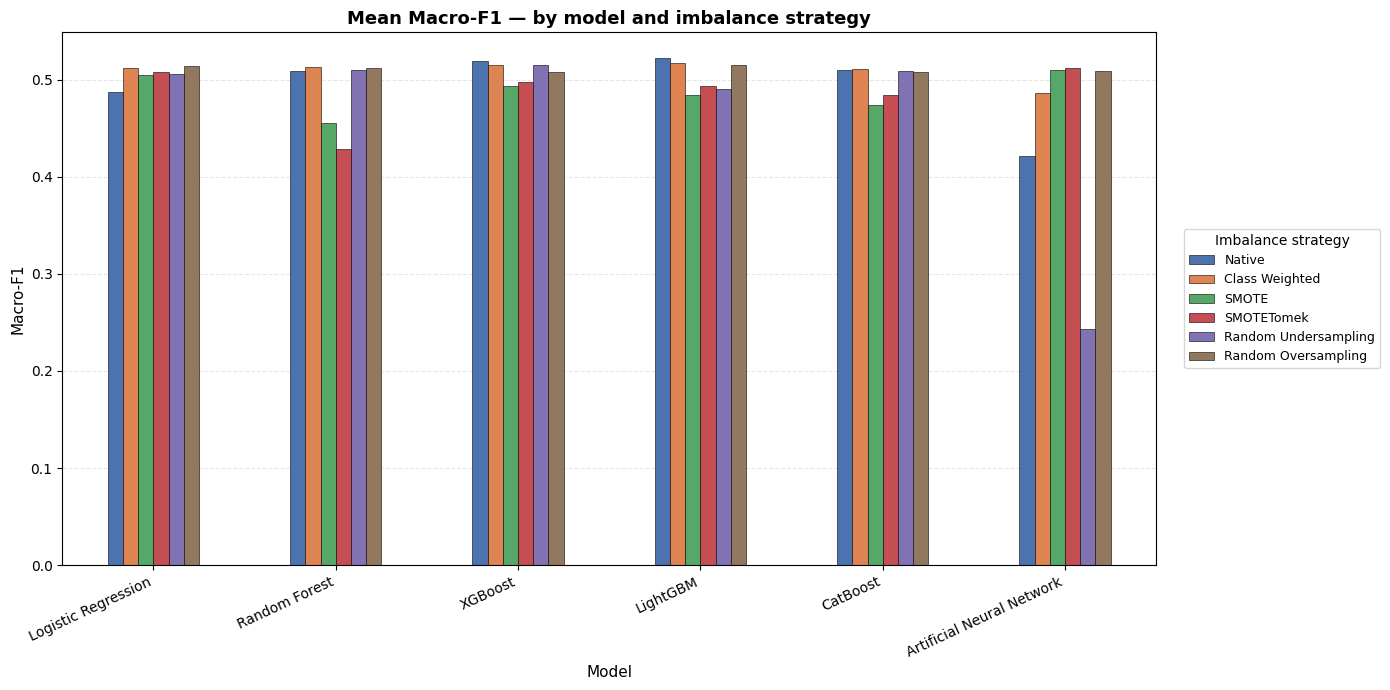

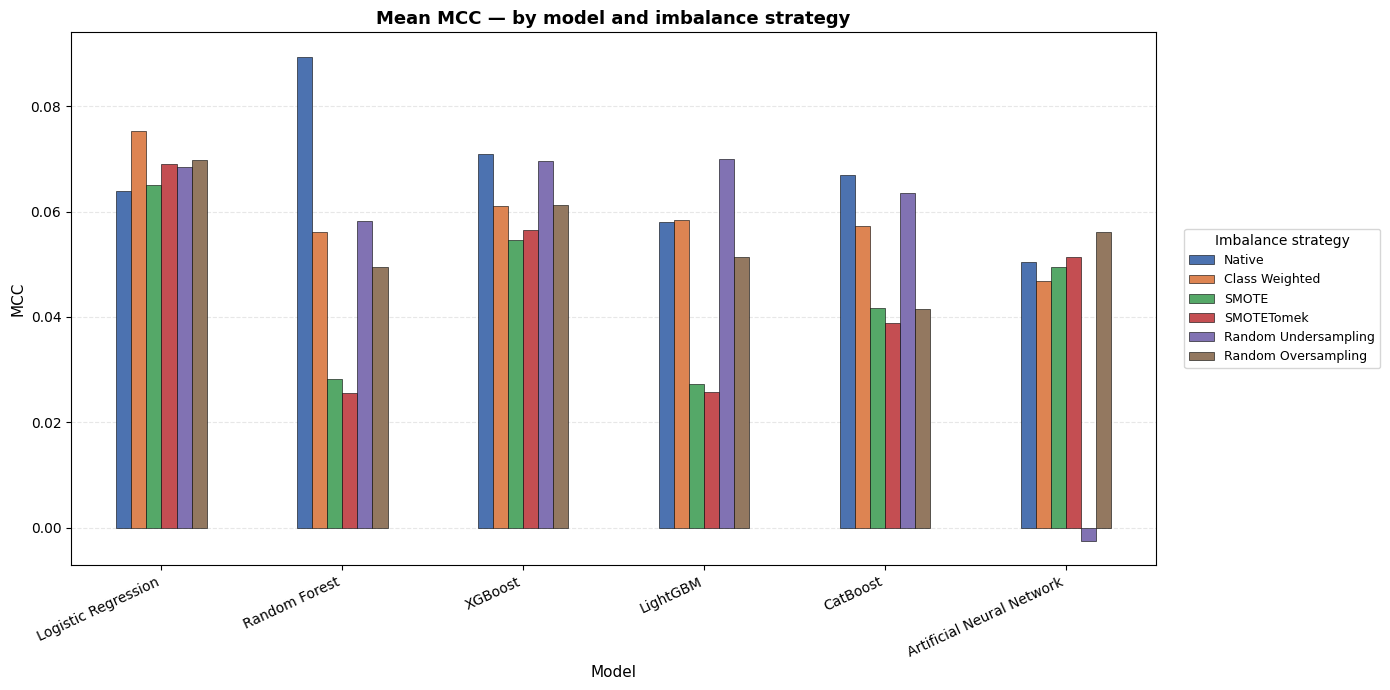

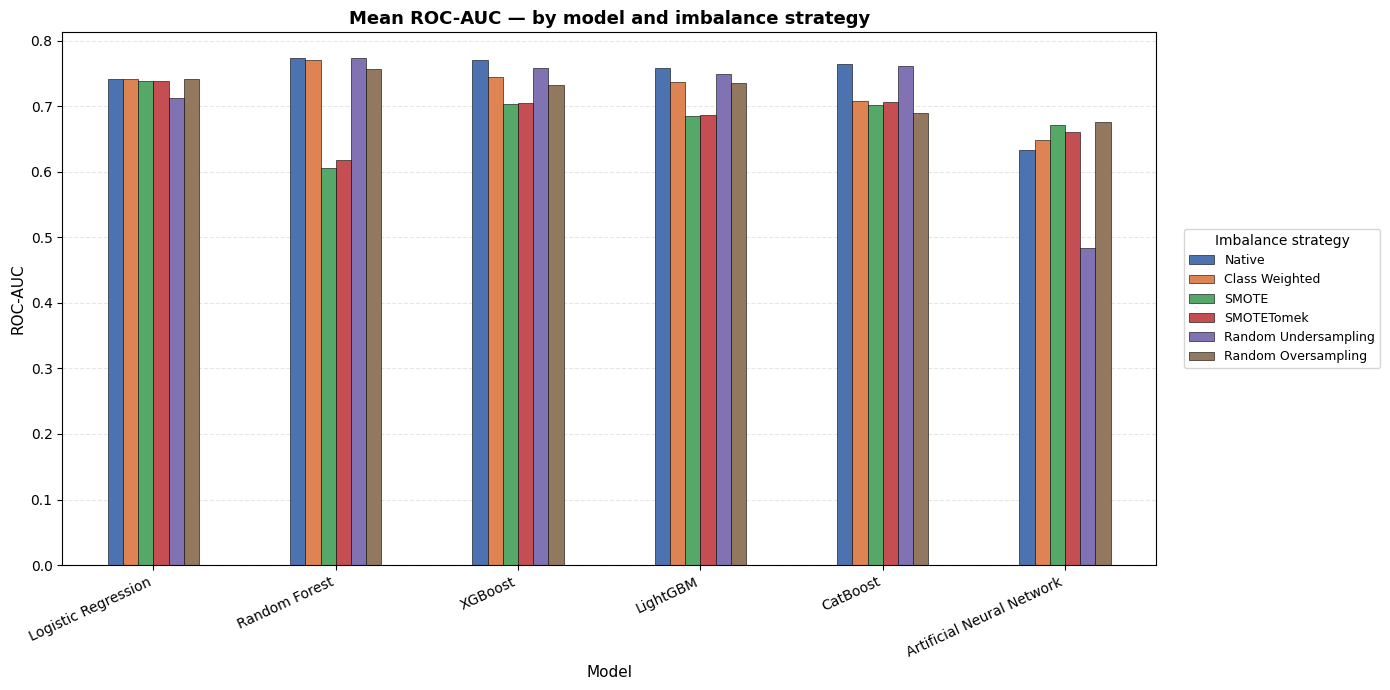

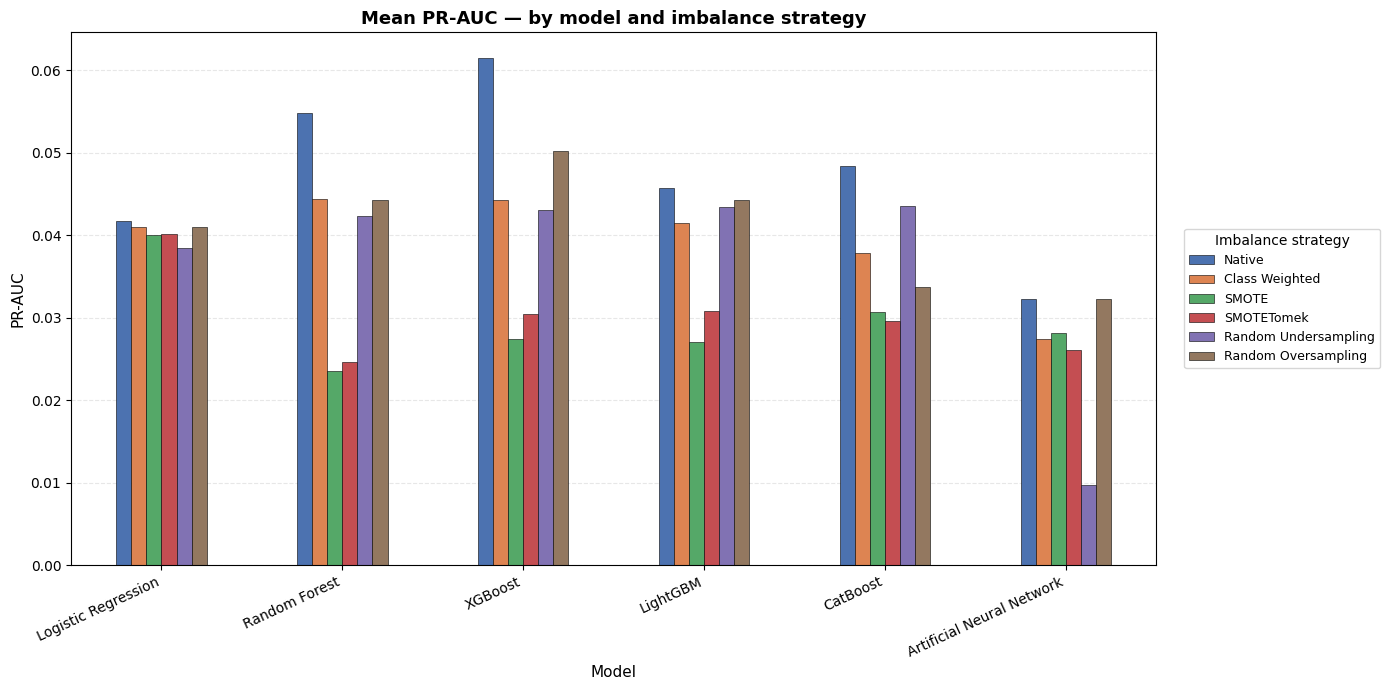

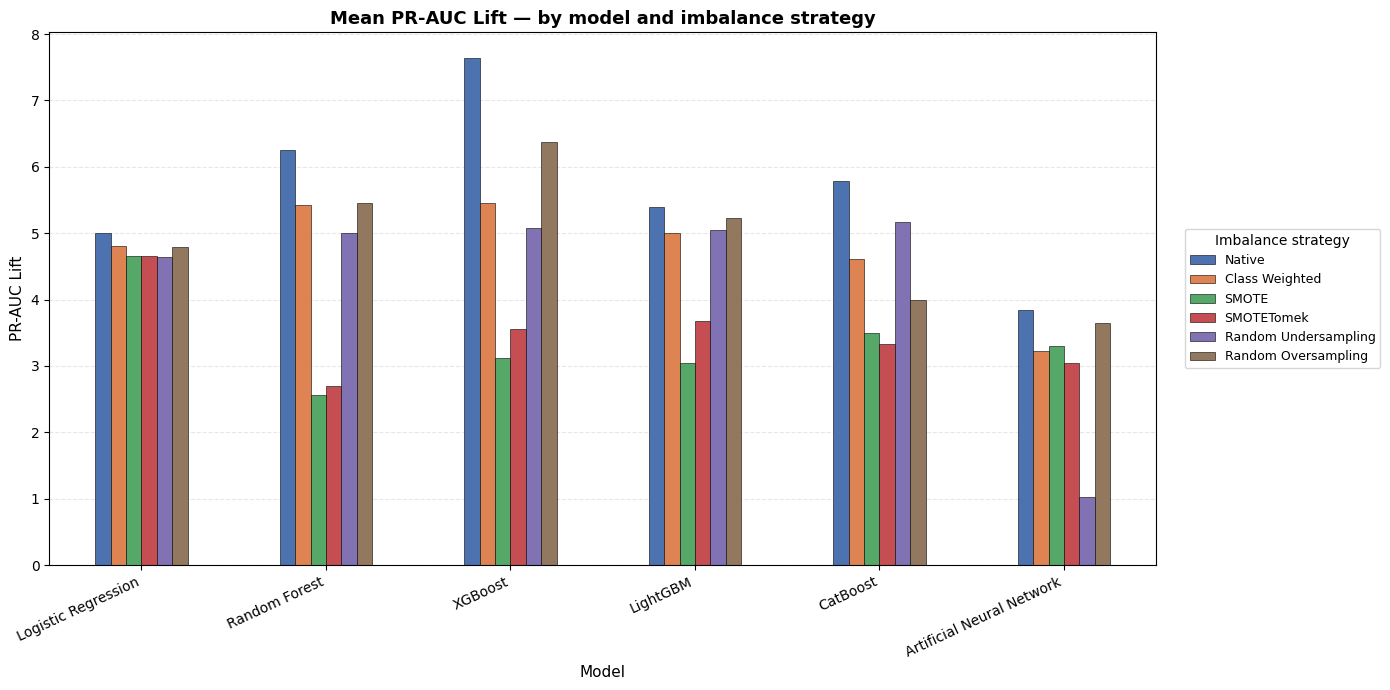

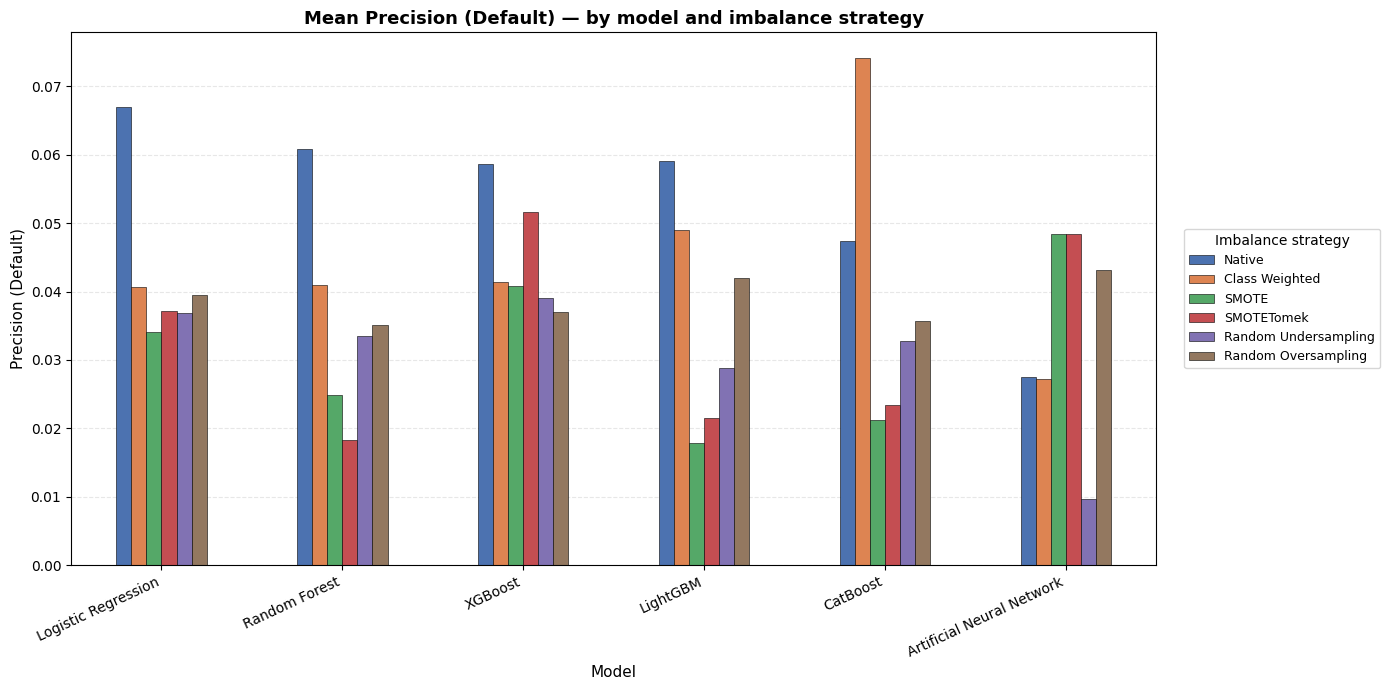

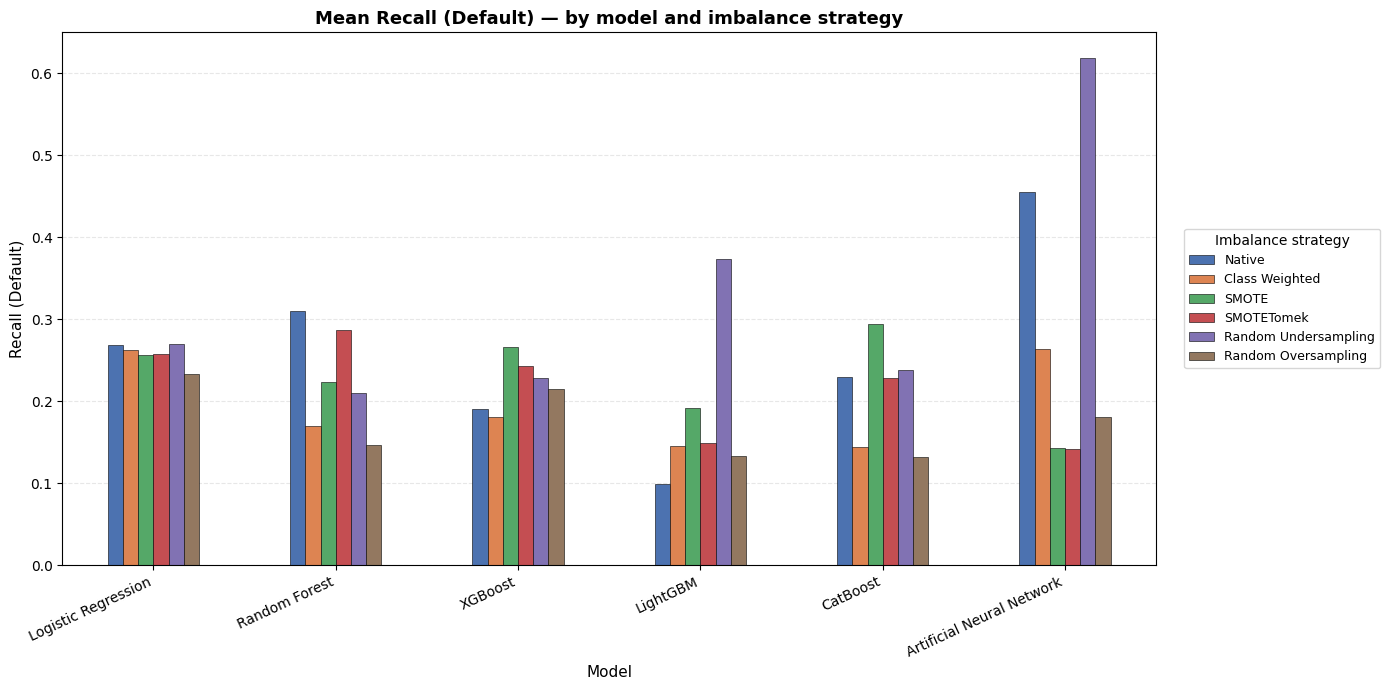

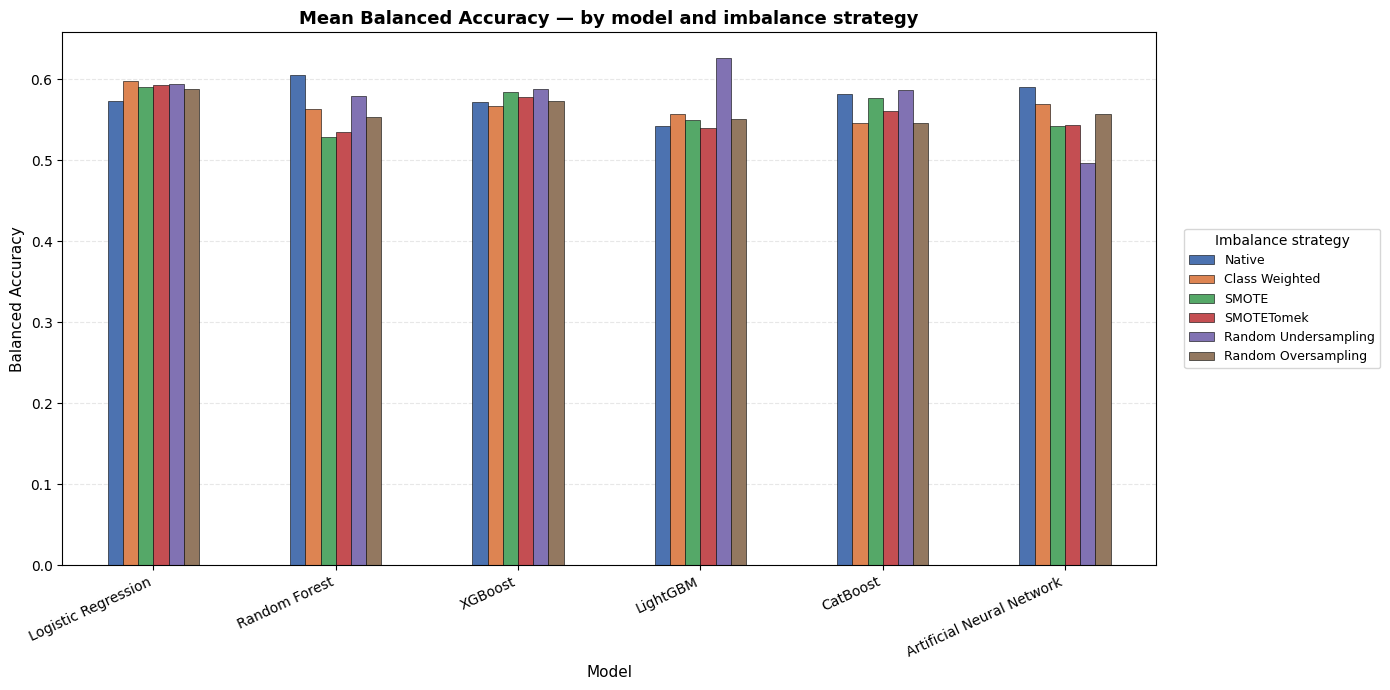

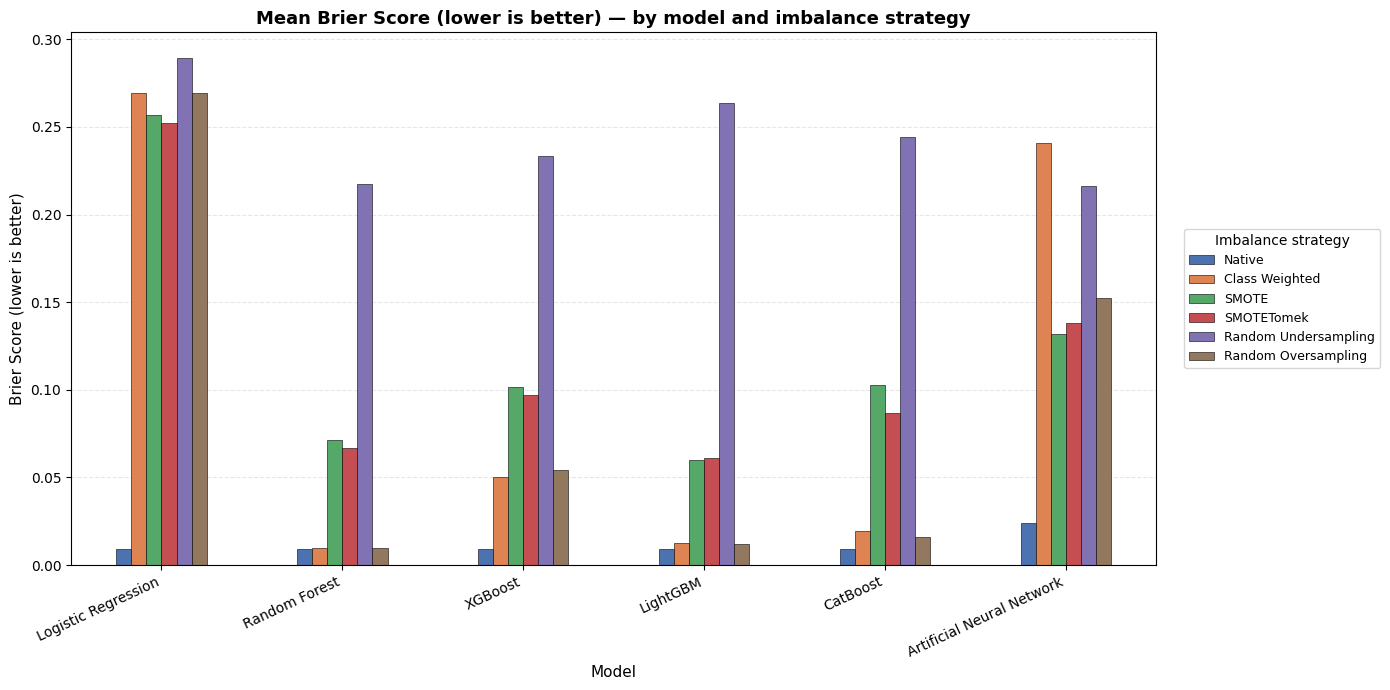

✓ Comparative bar charts saved (10 plots).


In [61]:
# ============================================================
# SECTION 8.2 — COMPARATIVE BAR CHARTS
# ============================================================
# Grouped bars: x = model, one bar per strategy.
# One chart per metric.

COMPARATIVE_METRICS = [
    ("f1_mean",                "Mean F1 (Default)"),
    ("f1_macro_mean",          "Mean Macro-F1"),
    ("mcc_mean",               "Mean MCC"),
    ("roc_auc_mean",           "Mean ROC-AUC"),
    ("pr_auc_mean",            "Mean PR-AUC"),
    ("pr_auc_lift_mean",       "Mean PR-AUC Lift"),
    ("precision_mean",         "Mean Precision (Default)"),
    ("recall_mean",            "Mean Recall (Default)"),
    ("balanced_accuracy_mean", "Mean Balanced Accuracy"),
    ("brier_mean",             "Mean Brier Score (lower is better)"),
]

# Fixed colour per strategy so cross-metric charts are comparable
STRATEGY_COLORS = {
    "Native":               "#4C72B0",
    "Class Weighted":       "#DD8452",
    "SMOTE":                "#55A868",
    "SMOTETomek":           "#C44E52",
    "Random Undersampling": "#8172B3",
    "Random Oversampling":  "#937860",
}

for metric_col, title in COMPARATIVE_METRICS:
    pivot = summary.pivot(
        index="model", columns="imbalance_strategy", values=metric_col
    )

    # Order models and strategies consistently
    pivot = pivot.reindex(index=MODEL_NAMES, columns=IMBALANCE_STRATEGIES)

    ax = pivot.plot(
        kind="bar",
        figsize=(14, 7),
        color=[STRATEGY_COLORS[s] for s in pivot.columns],
        edgecolor="black",
        linewidth=0.4,
    )

    ax.set_ylabel(title.replace("Mean ", ""), fontsize=11)
    ax.set_xlabel("Model", fontsize=11)
    ax.set_title(title + " — by model and imbalance strategy",
                 fontsize=13, fontweight="bold")
    ax.grid(axis="y", alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)
    plt.xticks(rotation=25, ha="right")

    # Legend outside the plot area
    ax.legend(
        title="Imbalance strategy",
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        fontsize=9,
        frameon=True,
    )

    plt.tight_layout()
    plt.savefig(
        f"{metric_col.replace('_mean', '')}_comparison.png",
        dpi=300, bbox_inches="tight",
    )
    plt.show()
    plt.close()

print(f"✓ Comparative bar charts saved ({len(COMPARATIVE_METRICS)} plots).")

Temporal stability — coefficient of variation (std / mean):
                    model   imbalance_strategy  f1_cv  roc_auc_cv  pr_auc_cv  mcc_cv  recall_cv  precision_cv
                 LightGBM Random Undersampling 0.3200      0.1122     0.7198  0.4706     0.6340        0.3820
                 CatBoost Random Undersampling 0.3893      0.0938     0.6785  0.5939     0.6977        0.3895
Artificial Neural Network Random Undersampling 0.4324      0.1161     0.3279     NaN     0.5171        0.4420
Artificial Neural Network               Native 0.4363      0.2231     0.7417  0.7471     0.6230        0.8782
                  XGBoost                SMOTE 0.4469      0.1309     0.3376  0.6917     0.8285        1.5554
                  XGBoost Random Undersampling 0.5005      0.1010     0.7052  0.5855     0.6723        0.5302
                 LightGBM           SMOTETomek 0.5657      0.1397     0.6834  1.0926     1.0781        0.9698
Artificial Neural Network       Class Weighted 0.5813      0

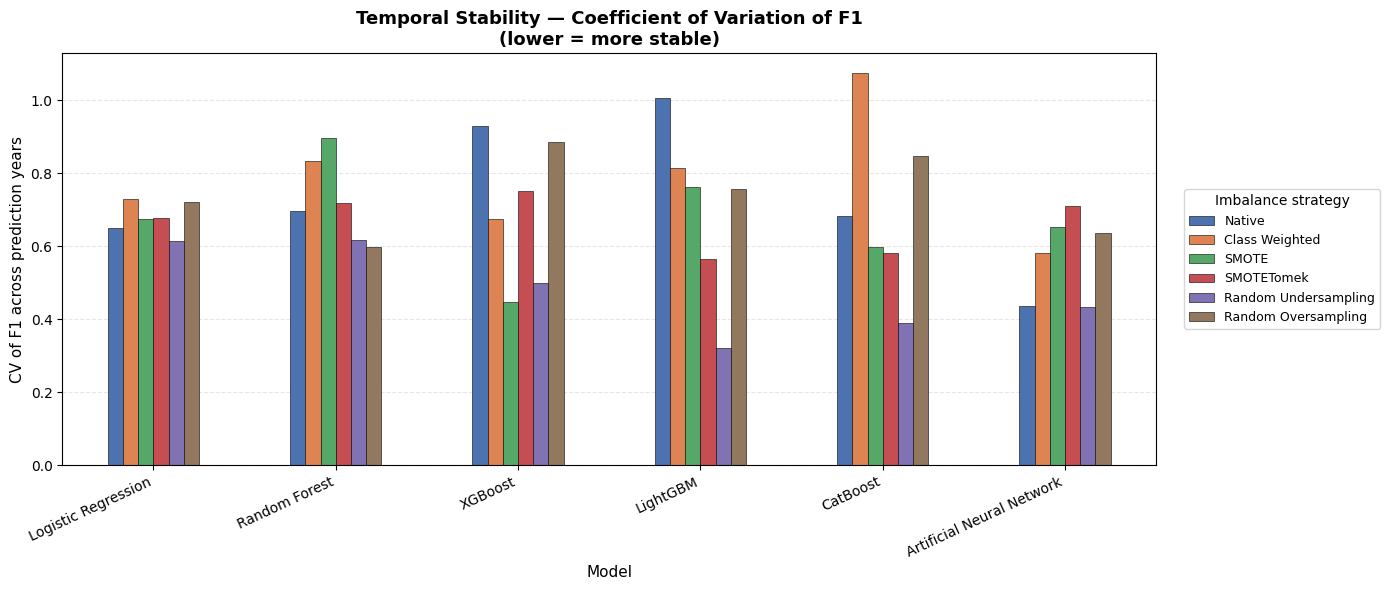

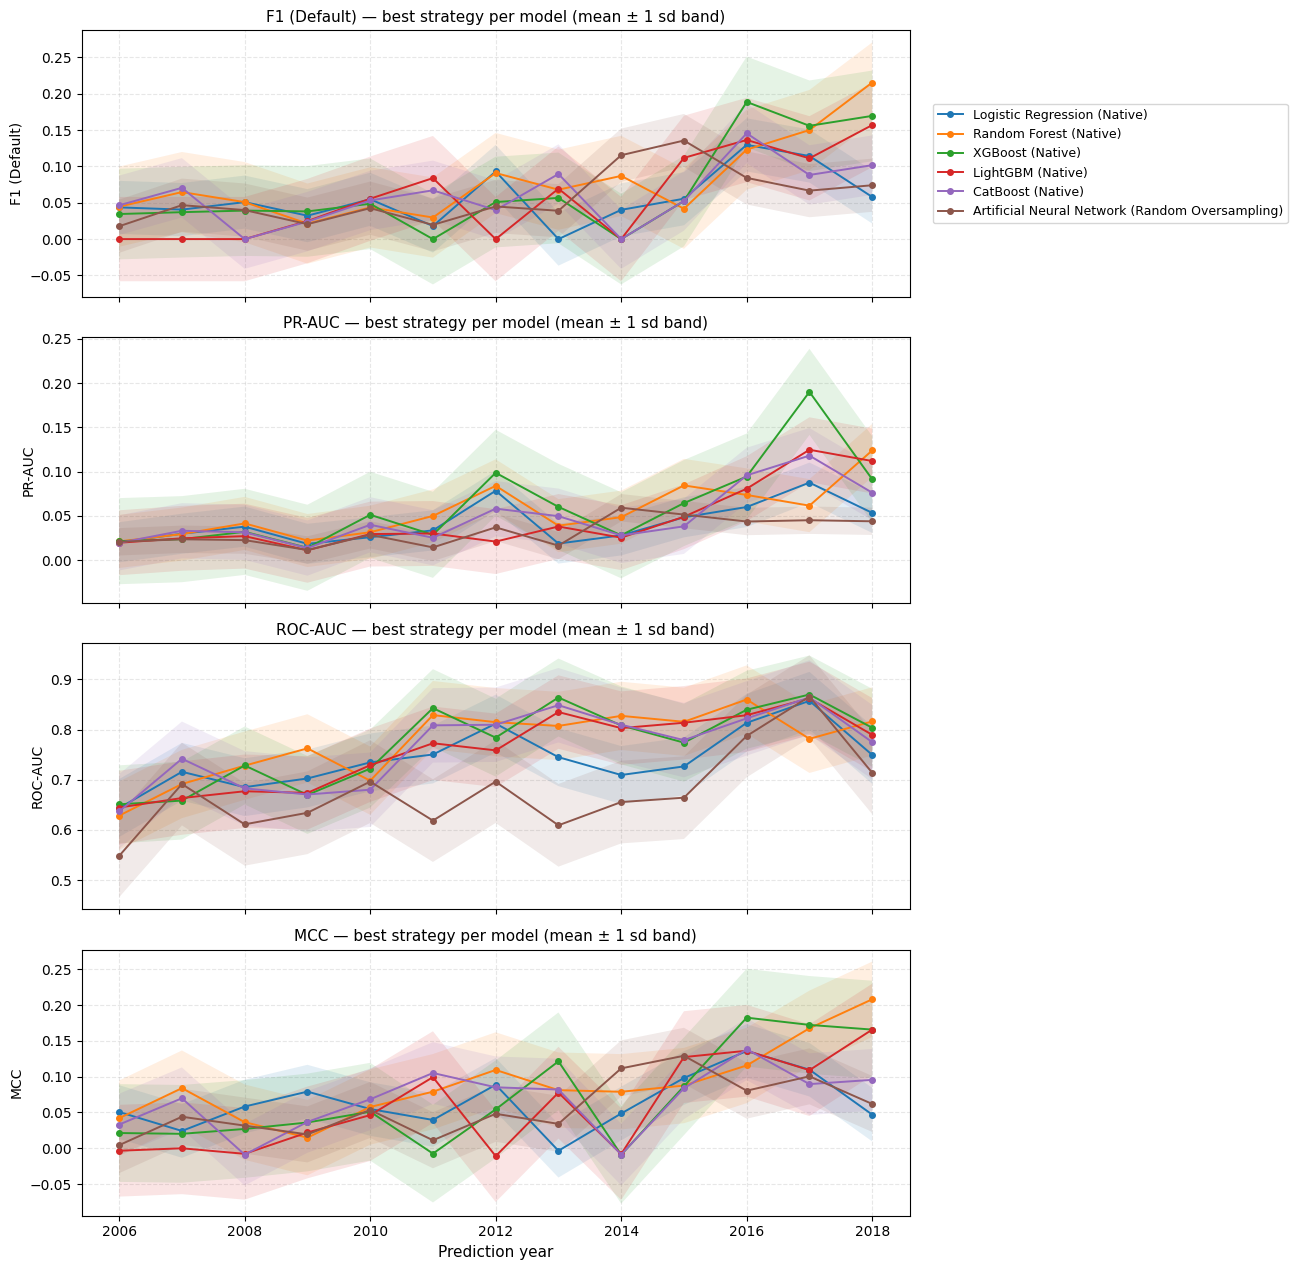


✓ Temporal stability analysis complete.


In [62]:
# ============================================================
# SECTION 8.3 — TEMPORAL STABILITY
# ============================================================
# For each (model, strategy), report the coefficient of variation
# (std / mean) of the metric across prediction years. This is a
# scale-free measure of temporal volatility.
#
# Also overlays mean ± 1 sd bands on the primary metrics.

STABILITY_METRICS = ["f1", "roc_auc", "pr_auc", "mcc", "recall", "precision"]

stability_rows = []
for (model, strategy), grp in rolling_results_df.groupby(
        ["model", "imbalance_strategy"]):

    row = {"model": model, "imbalance_strategy": strategy, "n_windows": len(grp)}
    for m in STABILITY_METRICS:
        vals = grp[m].astype(float).values
        mean = np.nanmean(vals)
        std  = np.nanstd(vals, ddof=1)
        cv   = std / mean if mean > 0 else np.nan
        row[f"{m}_mean"] = mean
        row[f"{m}_std"]  = std
        row[f"{m}_cv"]   = cv
    stability_rows.append(row)

stability_df = pd.DataFrame(stability_rows)
stability_df.to_csv("temporal_stability.csv", index=False)

print("Temporal stability — coefficient of variation (std / mean):")
cv_cols = ["model", "imbalance_strategy"] + [f"{m}_cv" for m in STABILITY_METRICS]
print(stability_df[cv_cols].round(4).sort_values("f1_cv").to_string(index=False))

# ---- Stability bar chart: CV of F1 per (model, strategy) ----
pivot_cv = stability_df.pivot(
    index="model", columns="imbalance_strategy", values="f1_cv"
).reindex(index=MODEL_NAMES, columns=IMBALANCE_STRATEGIES)

fig, ax = plt.subplots(figsize=(14, 6))
pivot_cv.plot(
    kind="bar",
    ax=ax,
    color=[STRATEGY_COLORS[s] for s in pivot_cv.columns],
    edgecolor="black",
    linewidth=0.4,
)
ax.set_ylabel("CV of F1 across prediction years", fontsize=11)
ax.set_xlabel("Model", fontsize=11)
ax.set_title("Temporal Stability — Coefficient of Variation of F1\n"
             "(lower = more stable)", fontsize=13, fontweight="bold")
ax.grid(axis="y", alpha=0.3, linestyle="--")
ax.set_axisbelow(True)
plt.xticks(rotation=25, ha="right")
ax.legend(title="Imbalance strategy",
          loc="center left", bbox_to_anchor=(1.02, 0.5),
          fontsize=9, frameon=True)
plt.tight_layout()
plt.savefig("temporal_stability_cv_f1.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# ---- Mean ± 1 sd band plots for key metrics, best strategy per model ----
BAND_METRICS = [
    ("f1",      "F1 (Default)"),
    ("pr_auc",  "PR-AUC"),
    ("roc_auc", "ROC-AUC"),
    ("mcc",     "MCC"),
]

fig, axes = plt.subplots(
    len(BAND_METRICS), 1,
    figsize=(13, 3.2 * len(BAND_METRICS)),
    sharex=True,
)
if len(BAND_METRICS) == 1:
    axes = [axes]

for ax, (metric, label) in zip(axes, BAND_METRICS):
    for model_name in MODEL_NAMES:
        strat = best_strategy_dict[model_name]
        sub = rolling_results_df[
            (rolling_results_df.model == model_name) &
            (rolling_results_df.imbalance_strategy == strat)
        ].sort_values("prediction_year")
        if len(sub) == 0:
            continue

        ax.plot(
            sub.prediction_year, sub[metric],
            marker="o", markersize=4, linewidth=1.4,
            label=f"{model_name} ({strat})",
        )
        ax.fill_between(
            sub.prediction_year,
            sub[metric] - sub[metric].std(),
            sub[metric] + sub[metric].std(),
            alpha=0.12,
        )

    ax.set_ylabel(label, fontsize=10)
    ax.set_title(f"{label} — best strategy per model (mean ± 1 sd band)",
                 fontsize=11)
    ax.grid(alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)

axes[-1].set_xlabel("Prediction year", fontsize=11)
axes[0].legend(loc="center left", bbox_to_anchor=(1.02, 0.5),
               fontsize=9, frameon=True)

plt.tight_layout()
plt.savefig("temporal_bands_best_strategy.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print()
print("✓ Temporal stability analysis complete.")

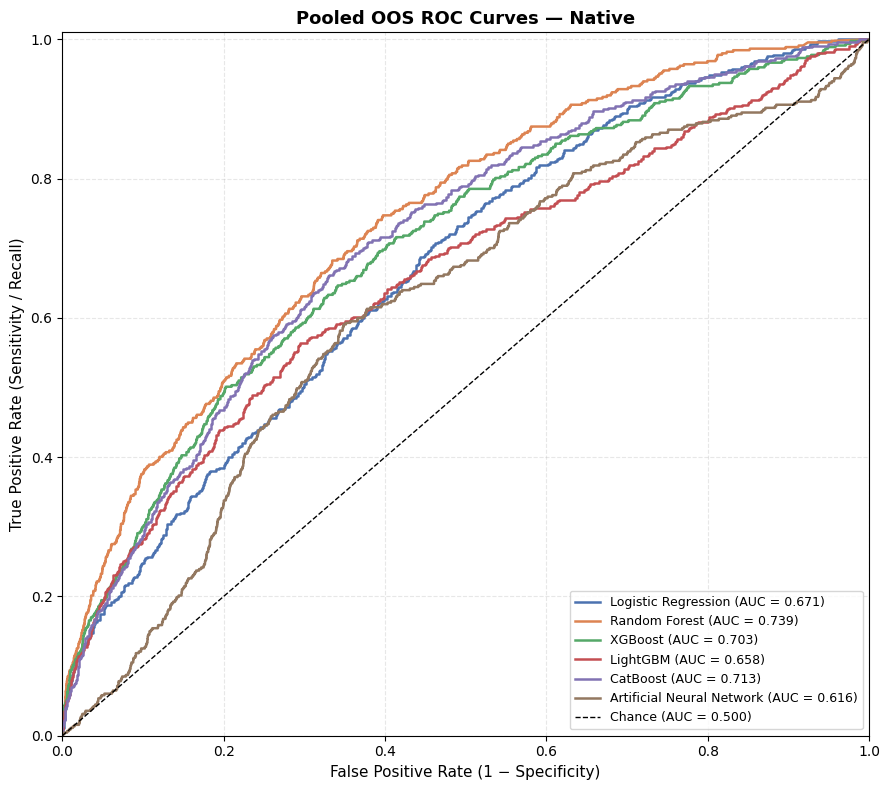

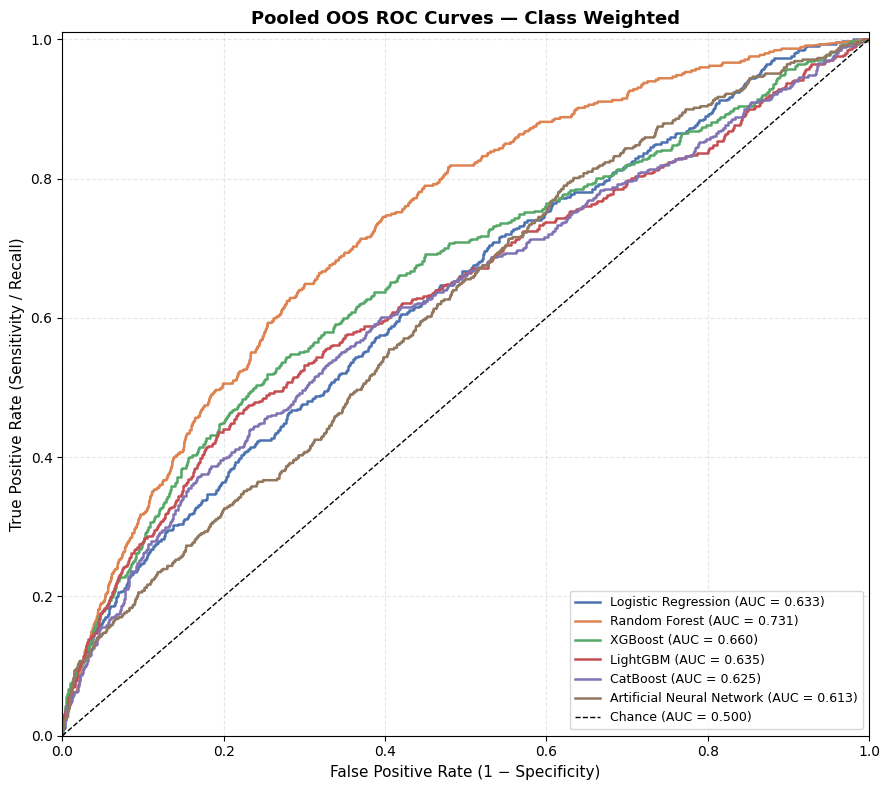

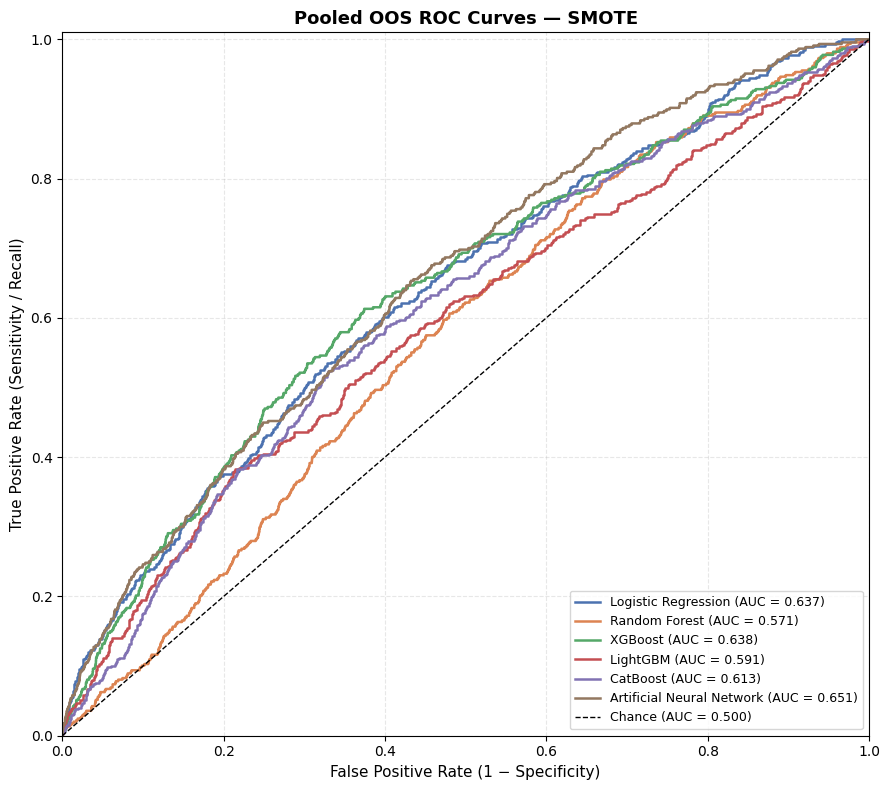

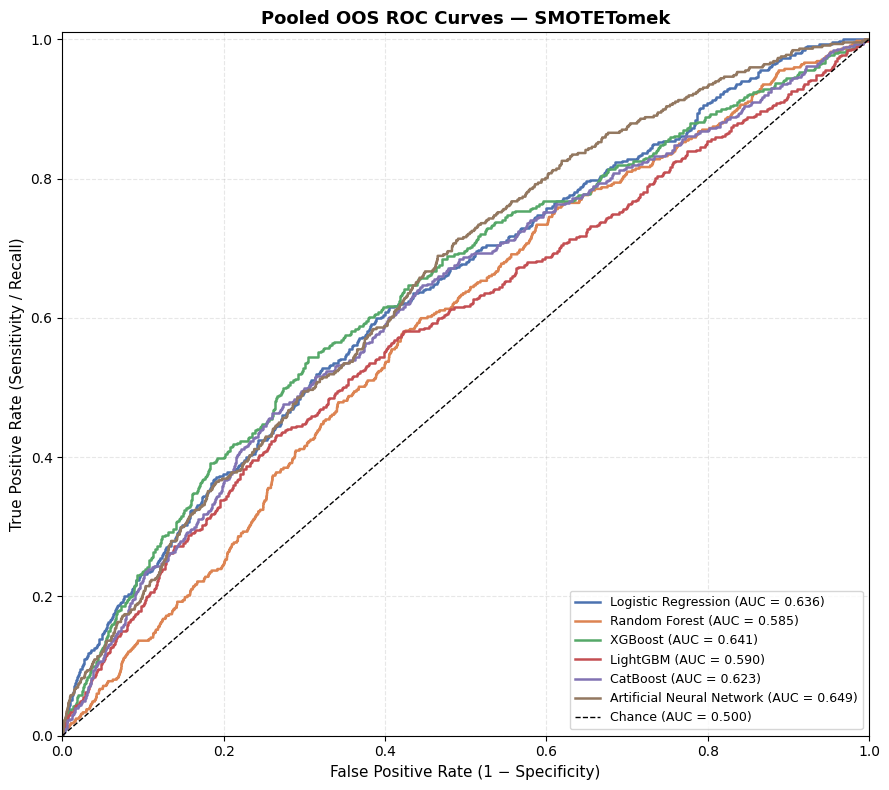

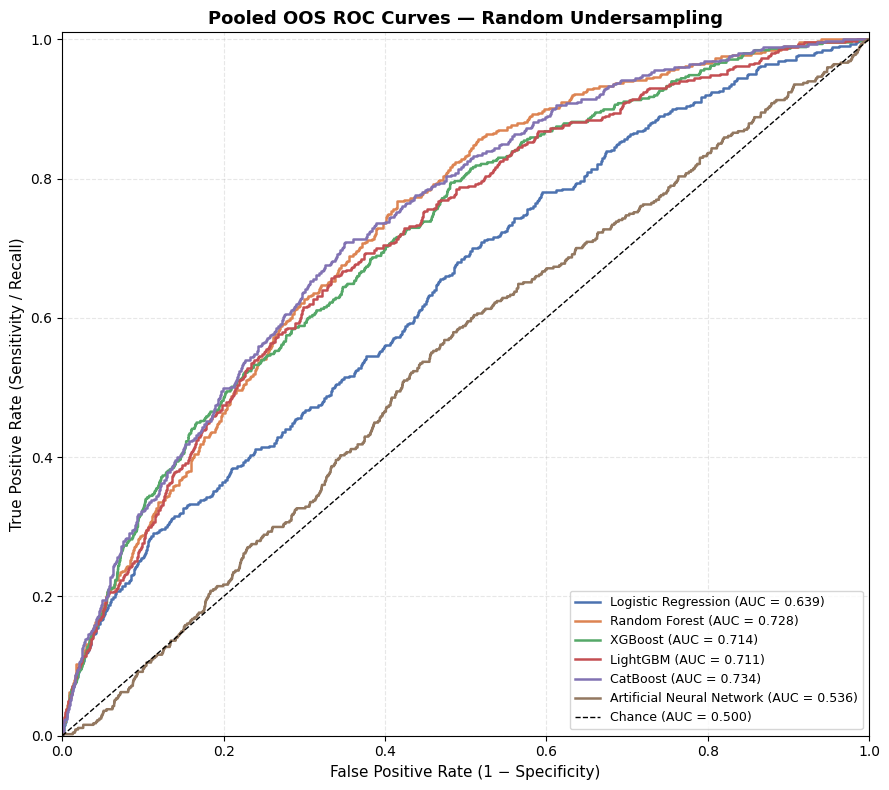

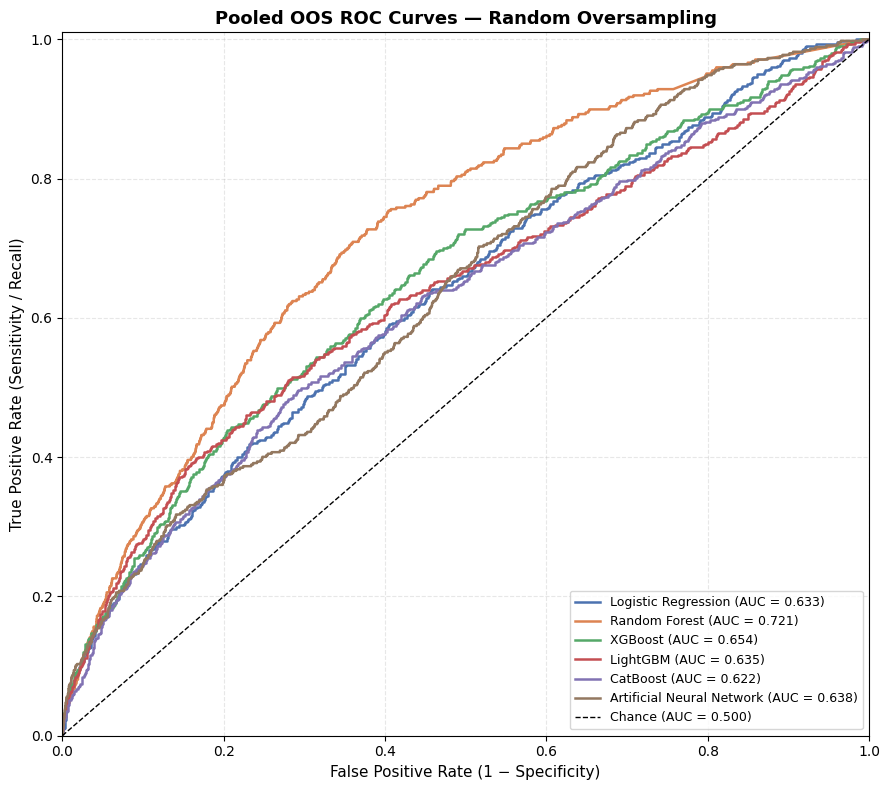

✓ 6 pooled ROC figures saved to Rolling_results_now\plots\comparative\roc

Pooled ROC-AUC per (model, strategy):
imbalance_strategy         Native  Class Weighted   SMOTE  SMOTETomek  Random Undersampling  Random Oversampling
model                                                                                                           
Logistic Regression        0.6706          0.6326  0.6373      0.6361                0.6389               0.6329
Random Forest              0.7388          0.7306  0.5714      0.5854                0.7284               0.7210
XGBoost                    0.7027          0.6595  0.6382      0.6406                0.7145               0.6538
LightGBM                   0.6577          0.6352  0.5907      0.5901                0.7115               0.6348
CatBoost                   0.7130          0.6251  0.6129      0.6229                0.7336               0.6215
Artificial Neural Network  0.6160          0.6134  0.6507      0.6486                0.5362     

In [64]:
# ============================================================
# SECTION 9.1 — POOLED OOS ROC CURVES
# ============================================================
# For each imbalance strategy, overlay the pooled OOS ROC curve
# of all six models. Pooling = concatenate all test predictions
# across the 13 rolling windows.
#
# One figure per strategy (6 figures total).

from sklearn.metrics import roc_curve, roc_auc_score

ROC_DIR = COMPARATIVE / "roc"
ROC_DIR.mkdir(parents=True, exist_ok=True)

# Fixed colours per model for consistency across figures
MODEL_COLORS = {
    "Logistic Regression":       "#4C72B0",
    "Random Forest":             "#DD8452",
    "XGBoost":                   "#55A868",
    "LightGBM":                  "#C44E52",
    "CatBoost":                  "#8172B3",
    "Artificial Neural Network": "#937860",
}

roc_auc_pooled = {}   # {(model, strategy): auc}

for strategy in IMBALANCE_STRATEGIES:
    fig, ax = plt.subplots(figsize=(9, 8))

    for model_name in MODEL_NAMES:
        q = rolling_predictions_df[
            (rolling_predictions_df.model == model_name) &
            (rolling_predictions_df.imbalance_strategy == strategy)
        ]
        if q.empty or q.target_1yr.nunique() < 2:
            continue

        y = q.target_1yr.astype(int).values
        p = q.probability.values

        fpr, tpr, _ = roc_curve(y, p)
        auc_val = roc_auc_score(y, p)
        roc_auc_pooled[(model_name, strategy)] = auc_val

        ax.plot(
            fpr, tpr,
            color=MODEL_COLORS[model_name],
            linewidth=1.8,
            label=f"{model_name} (AUC = {auc_val:.3f})",
        )

    ax.plot([0, 1], [0, 1], color="black", linestyle="--",
            linewidth=1.0, label="Chance (AUC = 0.500)")

    ax.set_xlabel("False Positive Rate (1 − Specificity)", fontsize=11)
    ax.set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11)
    ax.set_title(f"Pooled OOS ROC Curves — {strategy}",
                 fontsize=13, fontweight="bold")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.01)
    ax.grid(alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)
    ax.legend(loc="lower right", fontsize=9, frameon=True)

    plt.tight_layout()
    safe = re.sub(r"[^A-Za-z0-9]+", "_", strategy.lower())
    plt.savefig(ROC_DIR / f"roc_pooled_{safe}.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

# ---- Save AUC table ----
roc_table = pd.DataFrame(
    [(m, s, v) for (m, s), v in roc_auc_pooled.items()],
    columns=["model", "imbalance_strategy", "pooled_roc_auc"],
).pivot(index="model", columns="imbalance_strategy", values="pooled_roc_auc")

roc_table = roc_table.reindex(index=MODEL_NAMES, columns=IMBALANCE_STRATEGIES)
roc_table.round(4).to_csv(TABLES_COMP / "pooled_roc_auc.csv")

print(f"✓ {len(IMBALANCE_STRATEGIES)} pooled ROC figures saved to {ROC_DIR}")
print()
print("Pooled ROC-AUC per (model, strategy):")
print(roc_table.round(4).to_string())

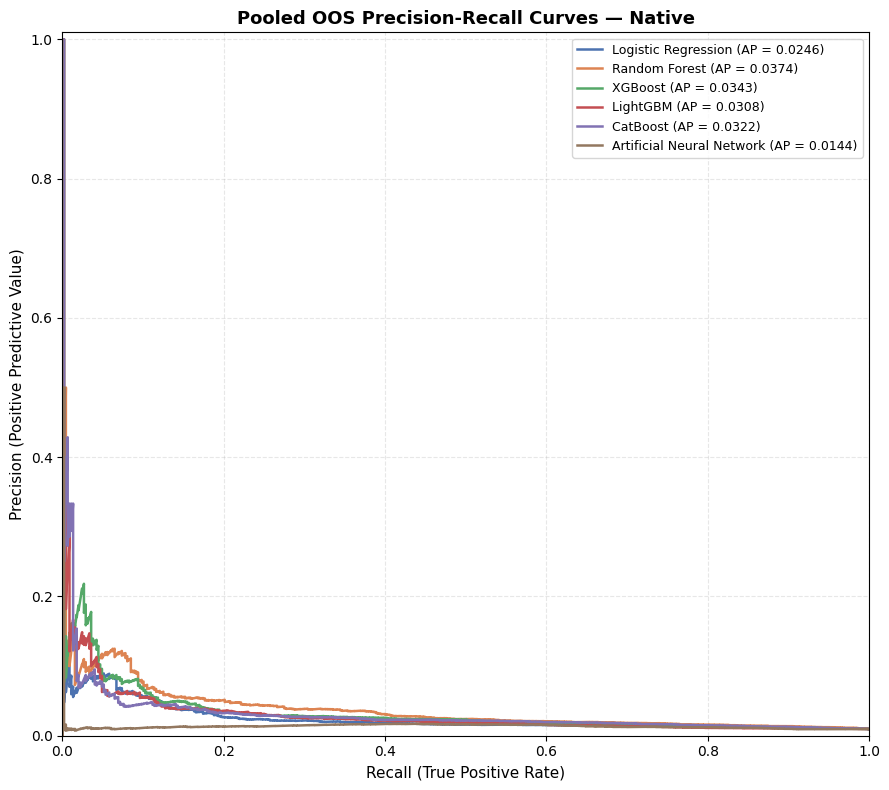

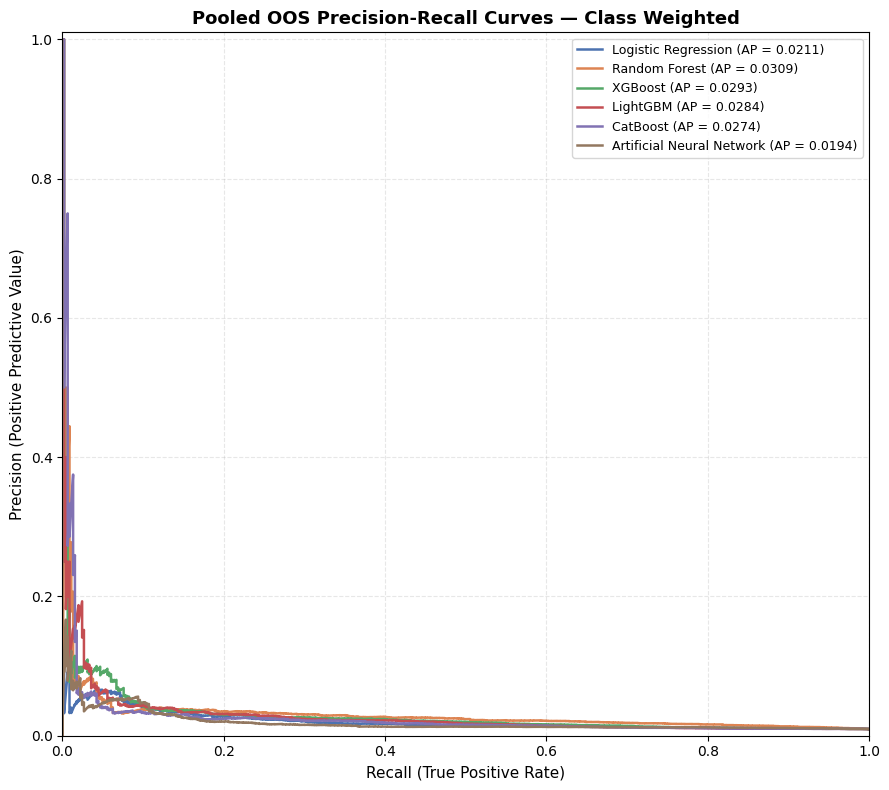

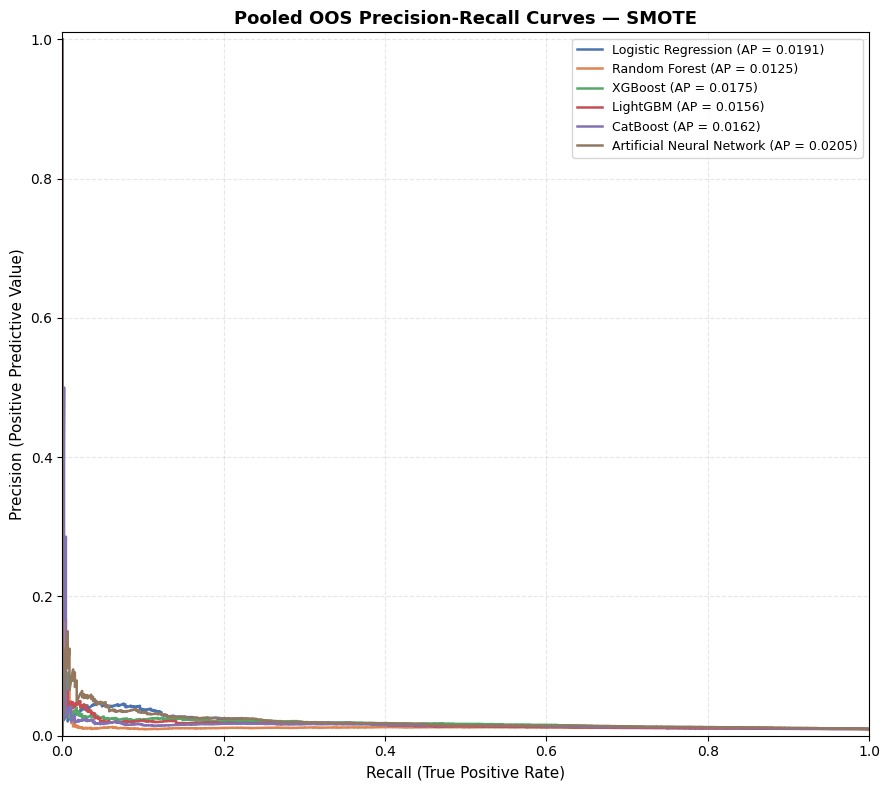

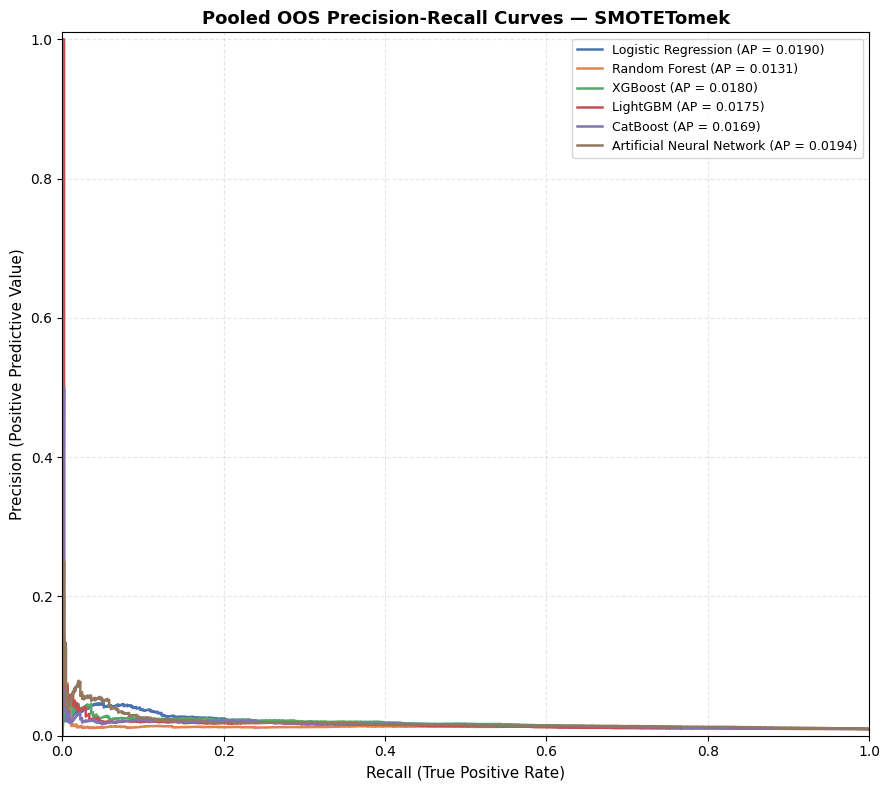

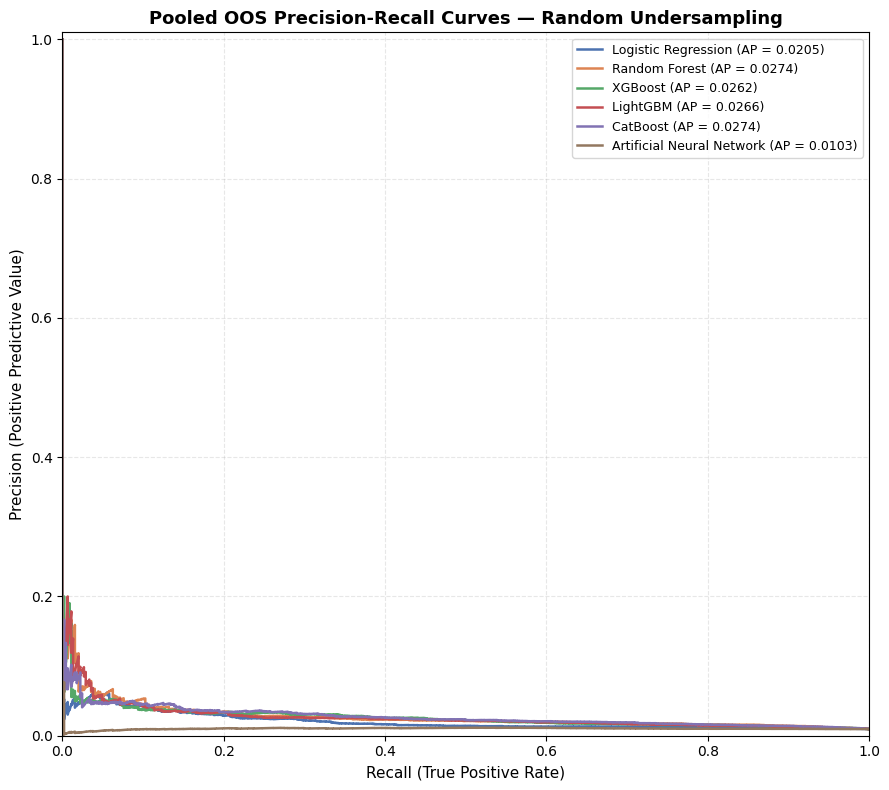

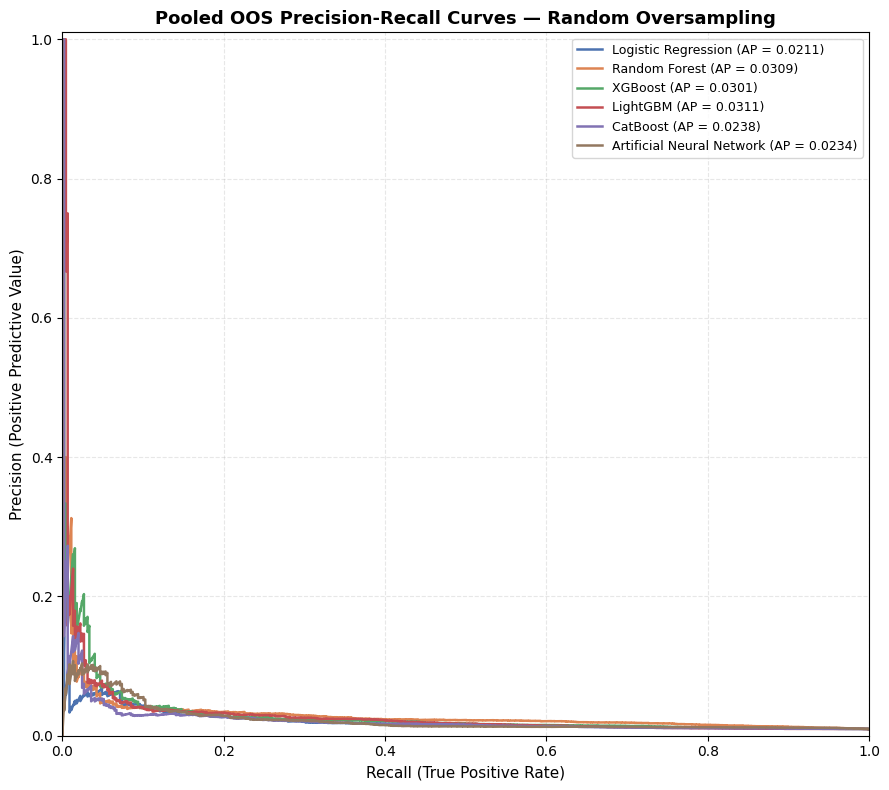

✓ 6 pooled PR figures saved to Rolling_results_now\plots\comparative\pr

Pooled PR-AUC (average precision) per (model, strategy):
imbalance_strategy         Native  Class Weighted   SMOTE  SMOTETomek  Random Undersampling  Random Oversampling
model                                                                                                           
Logistic Regression        0.0246          0.0211  0.0191      0.0190                0.0205               0.0211
Random Forest              0.0374          0.0309  0.0125      0.0131                0.0274               0.0309
XGBoost                    0.0343          0.0293  0.0175      0.0180                0.0262               0.0301
LightGBM                   0.0308          0.0284  0.0156      0.0175                0.0266               0.0311
CatBoost                   0.0322          0.0274  0.0162      0.0169                0.0274               0.0238
Artificial Neural Network  0.0144          0.0194  0.0205      0.0194          

In [65]:
# ============================================================
# SECTION 9.2 — POOLED OOS PRECISION-RECALL CURVES
# ============================================================
# Same pooling logic, but PR curves. More informative than ROC
# on imbalanced data because it focuses on the minority class.

from sklearn.metrics import precision_recall_curve, average_precision_score

PR_DIR = COMPARATIVE / "pr"
PR_DIR.mkdir(parents=True, exist_ok=True)

pr_ap_pooled = {}   # {(model, strategy): average_precision}

for strategy in IMBALANCE_STRATEGIES:
    fig, ax = plt.subplots(figsize=(9, 8))

    for model_name in MODEL_NAMES:
        q = rolling_predictions_df[
            (rolling_predictions_df.model == model_name) &
            (rolling_predictions_df.imbalance_strategy == strategy)
        ]
        if q.empty or q.target_1yr.nunique() < 2:
            continue

        y = q.target_1yr.astype(int).values
        p = q.probability.values

        precision, recall, _ = precision_recall_curve(y, p)
        ap = average_precision_score(y, p)
        pr_ap_pooled[(model_name, strategy)] = ap

        ax.plot(
            recall, precision,
            color=MODEL_COLORS[model_name],
            linewidth=1.8,
            label=f"{model_name} (AP = {ap:.4f})",
        )

    ax.set_xlabel("Recall (True Positive Rate)", fontsize=11)
    ax.set_ylabel("Precision (Positive Predictive Value)", fontsize=11)
    ax.set_title(f"Pooled OOS Precision-Recall Curves — {strategy}",
                 fontsize=13, fontweight="bold")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.01)
    ax.grid(alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)
    ax.legend(loc="best", fontsize=9, frameon=True)

    plt.tight_layout()
    safe = re.sub(r"[^A-Za-z0-9]+", "_", strategy.lower())
    plt.savefig(PR_DIR / f"pr_pooled_{safe}.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

# ---- Save AP table ----
pr_table = pd.DataFrame(
    [(m, s, v) for (m, s), v in pr_ap_pooled.items()],
    columns=["model", "imbalance_strategy", "pooled_pr_auc"],
).pivot(index="model", columns="imbalance_strategy", values="pooled_pr_auc")

pr_table = pr_table.reindex(index=MODEL_NAMES, columns=IMBALANCE_STRATEGIES)
pr_table.round(4).to_csv(TABLES_COMP / "pooled_pr_auc.csv")

print(f"✓ {len(IMBALANCE_STRATEGIES)} pooled PR figures saved to {PR_DIR}")
print()
print("Pooled PR-AUC (average precision) per (model, strategy):")
print(pr_table.round(4).to_string())

Pooled OOS prevalence (random baseline AP): 0.00958



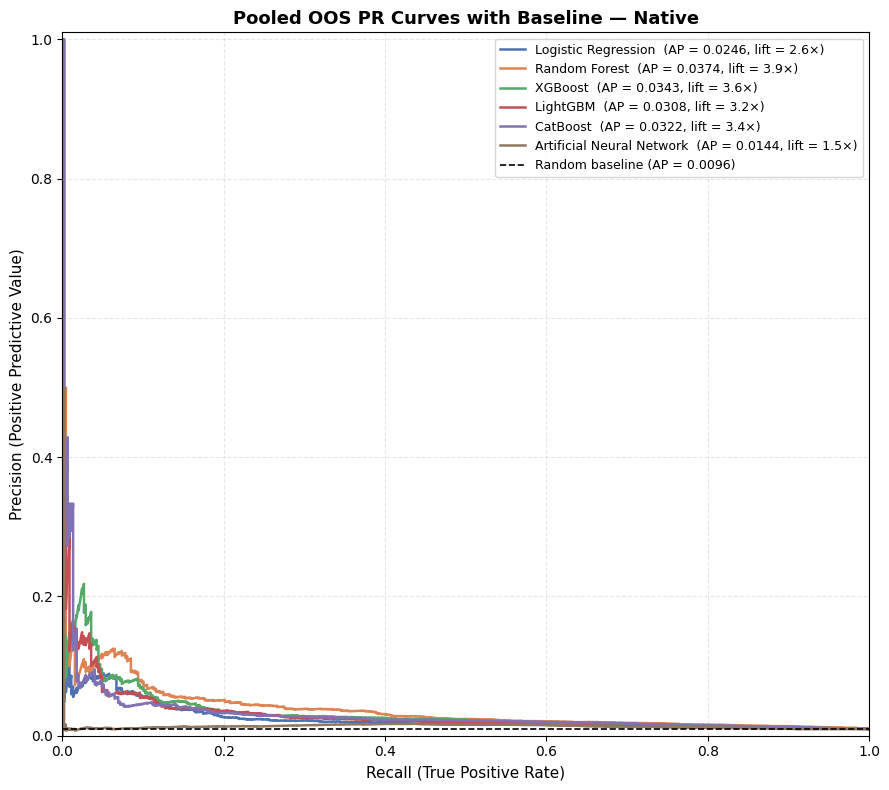

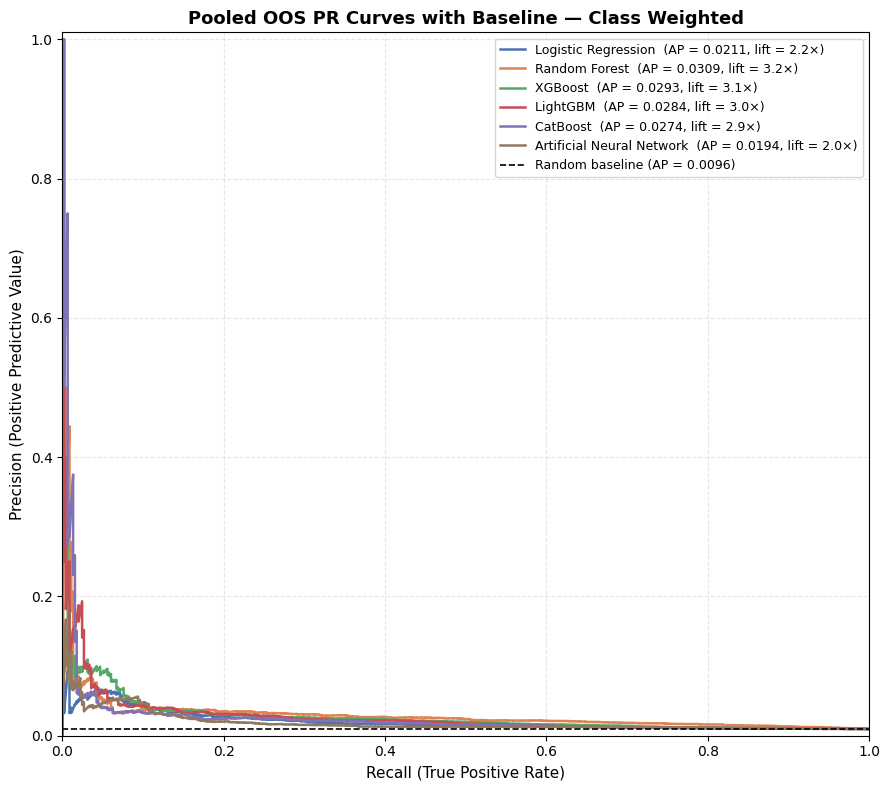

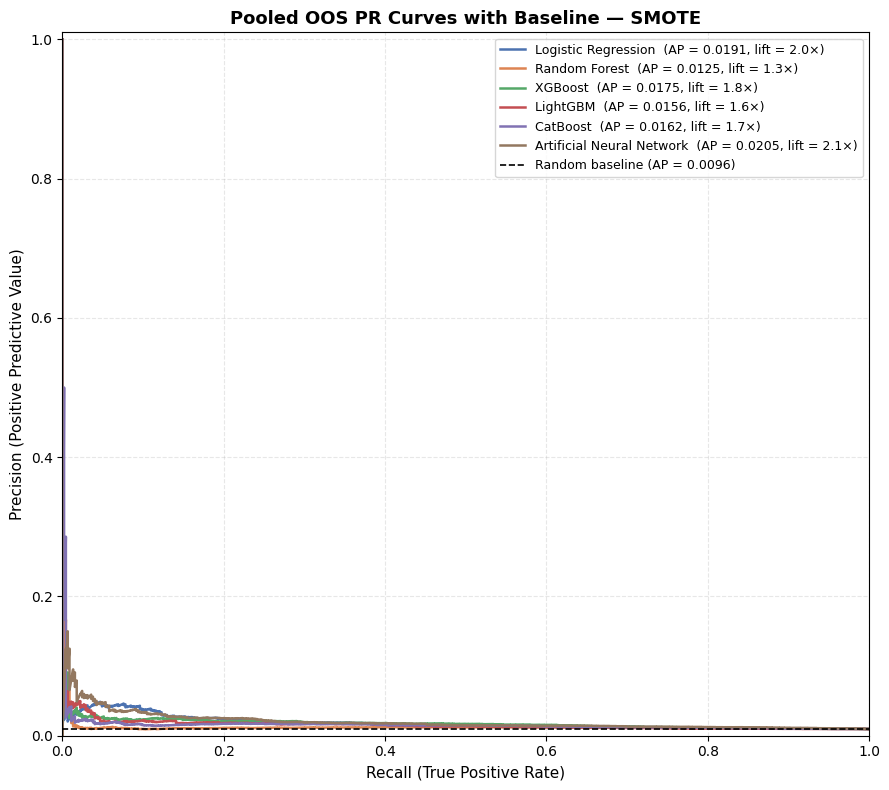

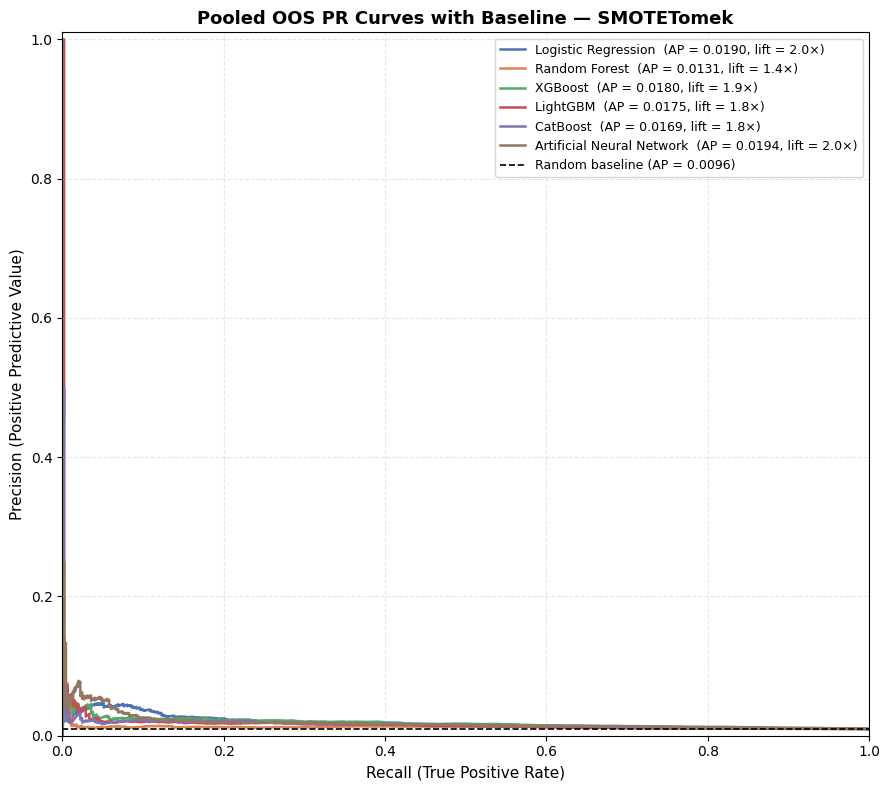

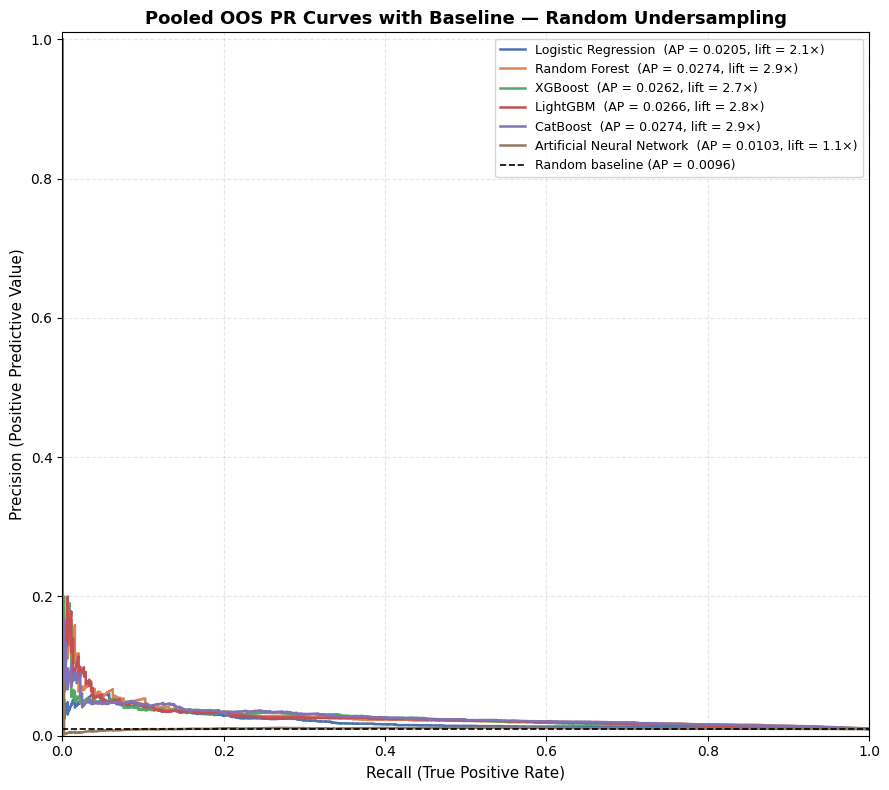

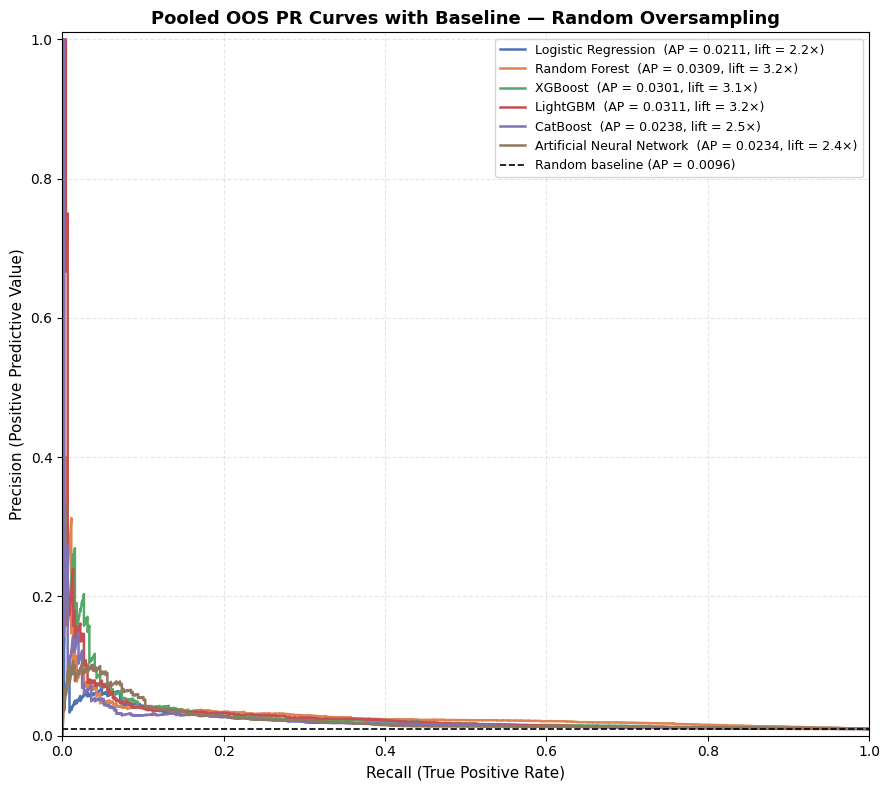

Pooled PR-AUC lift over random baseline:
imbalance_strategy         Native  Class Weighted  SMOTE  SMOTETomek  Random Undersampling  Random Oversampling
model                                                                                                          
Logistic Regression          2.57            2.21   1.99        1.98                  2.14                 2.20
Random Forest                3.90            3.22   1.30        1.37                  2.86                 3.23
XGBoost                      3.58            3.06   1.82        1.88                  2.74                 3.14
LightGBM                     3.22            2.96   1.63        1.82                  2.78                 3.25
CatBoost                     3.36            2.86   1.69        1.77                  2.86                 2.48
Artificial Neural Network    1.50            2.02   2.14        2.02                  1.08                 2.45


In [66]:
# ============================================================
# SECTION 9.3 — PR CURVES WITH PREVALENCE BASELINE AND LIFT
# ============================================================
# Same as 9.2, but adds:
#   - Horizontal dashed line at the pooled prevalence
#     (the baseline AP of a random classifier)
#   - Legend entries show AP and lift (AP / prevalence)
#
# On a 3% positive class, this makes the model's actual
# discriminative power immediately visible.

# Compute pooled prevalence across all test predictions
pooled_prevalence = rolling_predictions_df["target_1yr"].mean()
print(f"Pooled OOS prevalence (random baseline AP): {pooled_prevalence:.5f}")
print()

for strategy in IMBALANCE_STRATEGIES:
    fig, ax = plt.subplots(figsize=(9, 8))

    for model_name in MODEL_NAMES:
        q = rolling_predictions_df[
            (rolling_predictions_df.model == model_name) &
            (rolling_predictions_df.imbalance_strategy == strategy)
        ]
        if q.empty or q.target_1yr.nunique() < 2:
            continue

        y = q.target_1yr.astype(int).values
        p = q.probability.values

        precision, recall, _ = precision_recall_curve(y, p)
        ap = average_precision_score(y, p)
        lift = ap / pooled_prevalence

        ax.plot(
            recall, precision,
            color=MODEL_COLORS[model_name],
            linewidth=1.8,
            label=f"{model_name}  (AP = {ap:.4f}, lift = {lift:.1f}×)",
        )

    # Prevalence baseline
    ax.axhline(
        pooled_prevalence,
        color="black", linestyle="--", linewidth=1.2,
        label=f"Random baseline (AP = {pooled_prevalence:.4f})",
    )

    ax.set_xlabel("Recall (True Positive Rate)", fontsize=11)
    ax.set_ylabel("Precision (Positive Predictive Value)", fontsize=11)
    ax.set_title(f"Pooled OOS PR Curves with Baseline — {strategy}",
                 fontsize=13, fontweight="bold")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.01)
    ax.grid(alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)
    ax.legend(loc="best", fontsize=9, frameon=True)

    plt.tight_layout()
    safe = re.sub(r"[^A-Za-z0-9]+", "_", strategy.lower())
    plt.savefig(PR_DIR / f"pr_pooled_with_baseline_{safe}.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

# ---- Lift table ----
lift_table = (pr_table / pooled_prevalence).round(2)
lift_table.to_csv(TABLES_COMP / "pooled_pr_auc_lift.csv")

print("Pooled PR-AUC lift over random baseline:")
print(lift_table.to_string())

In [67]:
# Cross-check pooled AUC vs mean-of-fold AUC
mean_fold_roc = summary.pivot(
    index="model", columns="imbalance_strategy", values="roc_auc_mean"
).reindex(index=MODEL_NAMES, columns=IMBALANCE_STRATEGIES)

diff = (roc_table - mean_fold_roc).abs()
print("Absolute difference between pooled and mean-of-fold ROC-AUC:")
print(diff.round(4).to_string())

# Pooled AUCs are usually close to (but not identical to) mean-of-fold AUCs.
# Large differences (>0.05) suggest fold-size imbalance or distribution shift.
assert diff.max().max() < 0.15, \
    "Pooled and mean-of-fold ROC-AUC differ substantially — investigate."

print()
print(f"✓ Max |Δ|: {diff.max().max():.4f} — within tolerance.")

Absolute difference between pooled and mean-of-fold ROC-AUC:
imbalance_strategy         Native  Class Weighted   SMOTE  SMOTETomek  Random Undersampling  Random Oversampling
model                                                                                                           
Logistic Regression        0.0714          0.1085  0.1013      0.1024                0.0740               0.1079
Random Forest              0.0351          0.0398  0.0350      0.0319                0.0454               0.0356
XGBoost                    0.0678          0.0852  0.0656      0.0638                0.0441               0.0790
LightGBM                   0.1002          0.1021  0.0939      0.0969                0.0379               0.1002
CatBoost                   0.0508          0.0835  0.0883      0.0838                0.0272               0.0688
Artificial Neural Network  0.0170          0.0347  0.0211      0.0115                0.0527               0.0384

✓ Max |Δ|: 0.1085 — within toleran

In [69]:
# ============================================================
# SECTION 10.0 — SHARED CONFUSION MATRIX PLOTTER
# ============================================================

CM_DIR = COMPARATIVE / "confusion_matrices"
CM_DIR.mkdir(parents=True, exist_ok=True)

def plot_confusion_matrix(tn, fp, fn, tp,
                          title="Confusion Matrix",
                          save_path=None,
                          normalize=False,
                          cmap="Blues",
                          annot_fontsize=14,
                          figsize=(6, 5)):
    """
    Plot a 2×2 confusion matrix.
    Rows = True label, Columns = Predicted label.
    If normalize=True, rows are normalised to sum to 1.
    """
    cm = np.array([[tn, fp],
                   [fn, tp]])

    if normalize:
        denom = cm.sum(axis=1, keepdims=True)
        cm_plot = cm / np.where(denom == 0, 1, denom)
        fmt = ".2%"
        vmin, vmax = 0.0, 1.0
    else:
        cm_plot = cm
        fmt = "d"
        vmin, vmax = None, None

    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        cm_plot, annot=True, fmt=fmt, cmap=cmap,
        cbar=True, vmin=vmin, vmax=vmax,
        xticklabels=["Pred 0", "Pred 1"],
        yticklabels=["True 0", "True 1"],
        annot_kws={"size": annot_fontsize, "weight": "bold"},
        linewidths=1, linecolor="white", ax=ax,
    )
    ax.set_xlabel("Predicted label", fontsize=12)
    ax.set_ylabel("True label", fontsize=12)
    ax.set_title(title, fontsize=13, fontweight="bold", pad=10)

    # When normalized, also show raw counts in parentheses
    if normalize:
        for i in range(2):
            for j in range(2):
                ax.text(j + 0.5, i + 0.78,
                        f"({cm[i, j]:,})",
                        ha="center", va="center",
                        fontsize=10, color="black")

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close()


print("✓ Confusion matrix plotter defined.")

✓ Confusion matrix plotter defined.


In [70]:
# ============================================================
# SECTION 10.1 — AGGREGATED HEATMAPS PER (MODEL, STRATEGY)
# ============================================================
# Aggregated confusion cells = sum of TN/FP/FN/TP across the 13 folds.
# Reconstructed from summary's mean × n_windows (equivalently:
# sum directly from rolling_results_df).

cm_agg = (
    rolling_results_df
    .groupby(["model", "imbalance_strategy"])
    .agg(
        tn=("tn", "sum"),
        fp=("fp", "sum"),
        fn=("fn", "sum"),
        tp=("tp", "sum"),
        n_windows=("test_information_year", "count"),
    )
    .reset_index()
)

# Derived rates
cm_agg["accuracy"]       = ((cm_agg.tp + cm_agg.tn) /
                            (cm_agg.tp + cm_agg.tn + cm_agg.fp + cm_agg.fn))
cm_agg["precision"]      = cm_agg.tp / (cm_agg.tp + cm_agg.fp).replace(0, np.nan)
cm_agg["recall"]         = cm_agg.tp / (cm_agg.tp + cm_agg.fn).replace(0, np.nan)
cm_agg["specificity"]    = cm_agg.tn / (cm_agg.tn + cm_agg.fp).replace(0, np.nan)
cm_agg["f1"]             = (2 * cm_agg.precision * cm_agg.recall /
                            (cm_agg.precision + cm_agg.recall))
cm_agg["balanced_acc"]   = 0.5 * (cm_agg.recall + cm_agg.specificity)
cm_agg["type_i_error"]   = cm_agg.fp / (cm_agg.tn + cm_agg.fp).replace(0, np.nan)
cm_agg["type_ii_error"]  = cm_agg.fn / (cm_agg.tp + cm_agg.fn).replace(0, np.nan)

cm_agg.to_csv(TABLES_COMP / "confusion_matrix_aggregated.csv", index=False)

print(f"Aggregated confusion matrix table: {cm_agg.shape}")
print()
print("Sample rows:")
print(cm_agg.head(6).round(4).to_string(index=False))

# ---- Write one heatmap per (model, strategy) ----
for _, row in cm_agg.iterrows():
    safe_m = MODEL_DIRS[row.model]
    safe_s = re.sub(r"[^A-Za-z0-9]+", "_", row.imbalance_strategy.lower())
    n_total = int(row.tn + row.fp + row.fn + row.tp)

    plot_confusion_matrix(
        tn=row.tn, fp=row.fp, fn=row.fn, tp=row.tp,
        title=(f"{row.model} — {row.imbalance_strategy}\n"
               f"(pooled OOS, n={n_total:,})"),
        save_path=CM_DIR / f"cm_{safe_m}__{safe_s}.png",
    )

print()
print(f"✓ {len(cm_agg)} aggregated confusion matrices saved to {CM_DIR}")

Aggregated confusion matrix table: (36, 15)

Sample rows:
                    model   imbalance_strategy    tn    fp  fn  tp  n_windows  accuracy  precision  recall  specificity     f1  balanced_acc  type_i_error  type_ii_error
Artificial Neural Network       Class Weighted 40230  5974 327 120         13    0.8649     0.0197  0.2685       0.8707 0.0367        0.5696        0.1293         0.7315
Artificial Neural Network               Native 33012 13192 229 218         13    0.7123     0.0163  0.4877       0.7145 0.0315        0.6011        0.2855         0.5123
Artificial Neural Network  Random Oversampling 43058  3146 362  85         13    0.9248     0.0263  0.1902       0.9319 0.0462        0.5610        0.0681         0.8098
Artificial Neural Network Random Undersampling 17415 28789 158 289         13    0.3795     0.0099  0.6465       0.3769 0.0196        0.5117        0.6231         0.3535
Artificial Neural Network                SMOTE 43443  2761 382  65         13    0.9326     

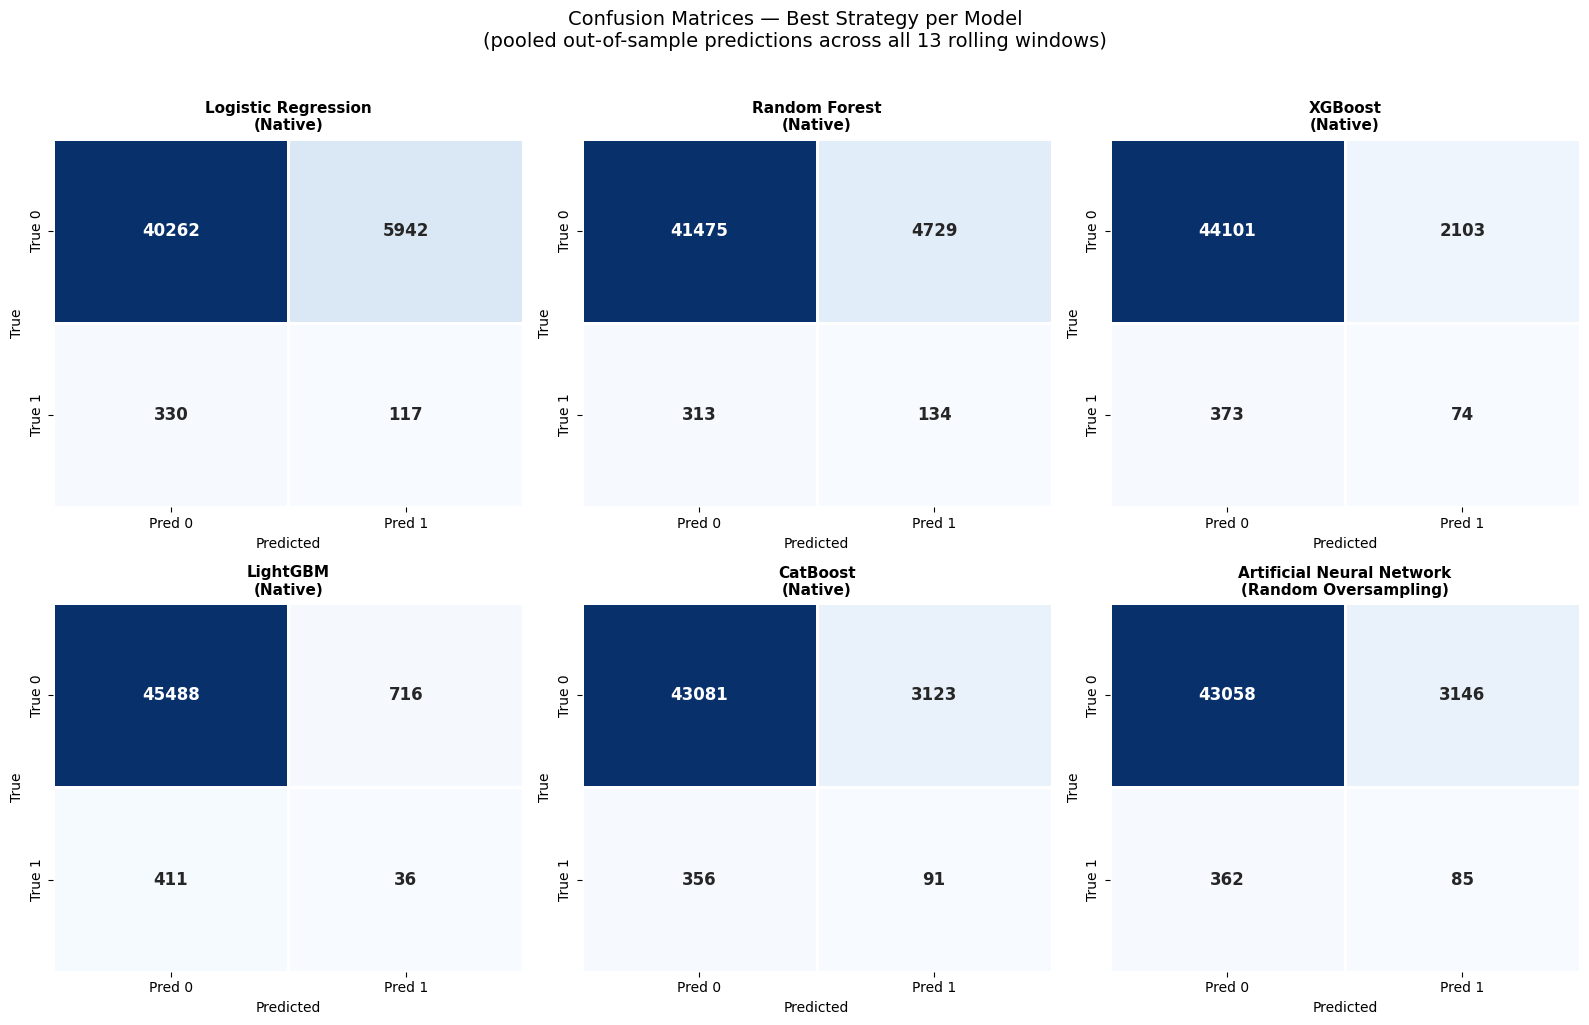

✓ Best-per-model grid saved.


In [71]:
# ============================================================
# SECTION 10.2 — BEST-PER-MODEL 3×2 GRID
# ============================================================
# One confusion matrix per model, using that model's best strategy
# (from Section 7.6, ranked by PRIMARY_RANK_METRIC).

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for i, model_name in enumerate(MODEL_ORDER if "MODEL_ORDER" in globals()
                               else MODEL_NAMES):
    strat = best_strategy_dict.get(model_name)
    row = cm_agg[(cm_agg.model == model_name) &
                 (cm_agg.imbalance_strategy == strat)]
    ax = axes[i]
    if row.empty:
        ax.axis("off")
        continue
    r = row.iloc[0]
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Pred 0", "Pred 1"],
        yticklabels=["True 0", "True 1"],
        annot_kws={"size": 12, "weight": "bold"},
        linewidths=1, linecolor="white", ax=ax,
    )
    ax.set_title(f"{model_name}\n({strat})",
                 fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted", fontsize=10)
    ax.set_ylabel("True", fontsize=10)

plt.suptitle("Confusion Matrices — Best Strategy per Model\n"
             "(pooled out-of-sample predictions across all 13 rolling windows)",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(CM_DIR / "cm_grid_best_per_model.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"✓ Best-per-model grid saved.")

Best model: XGBoost


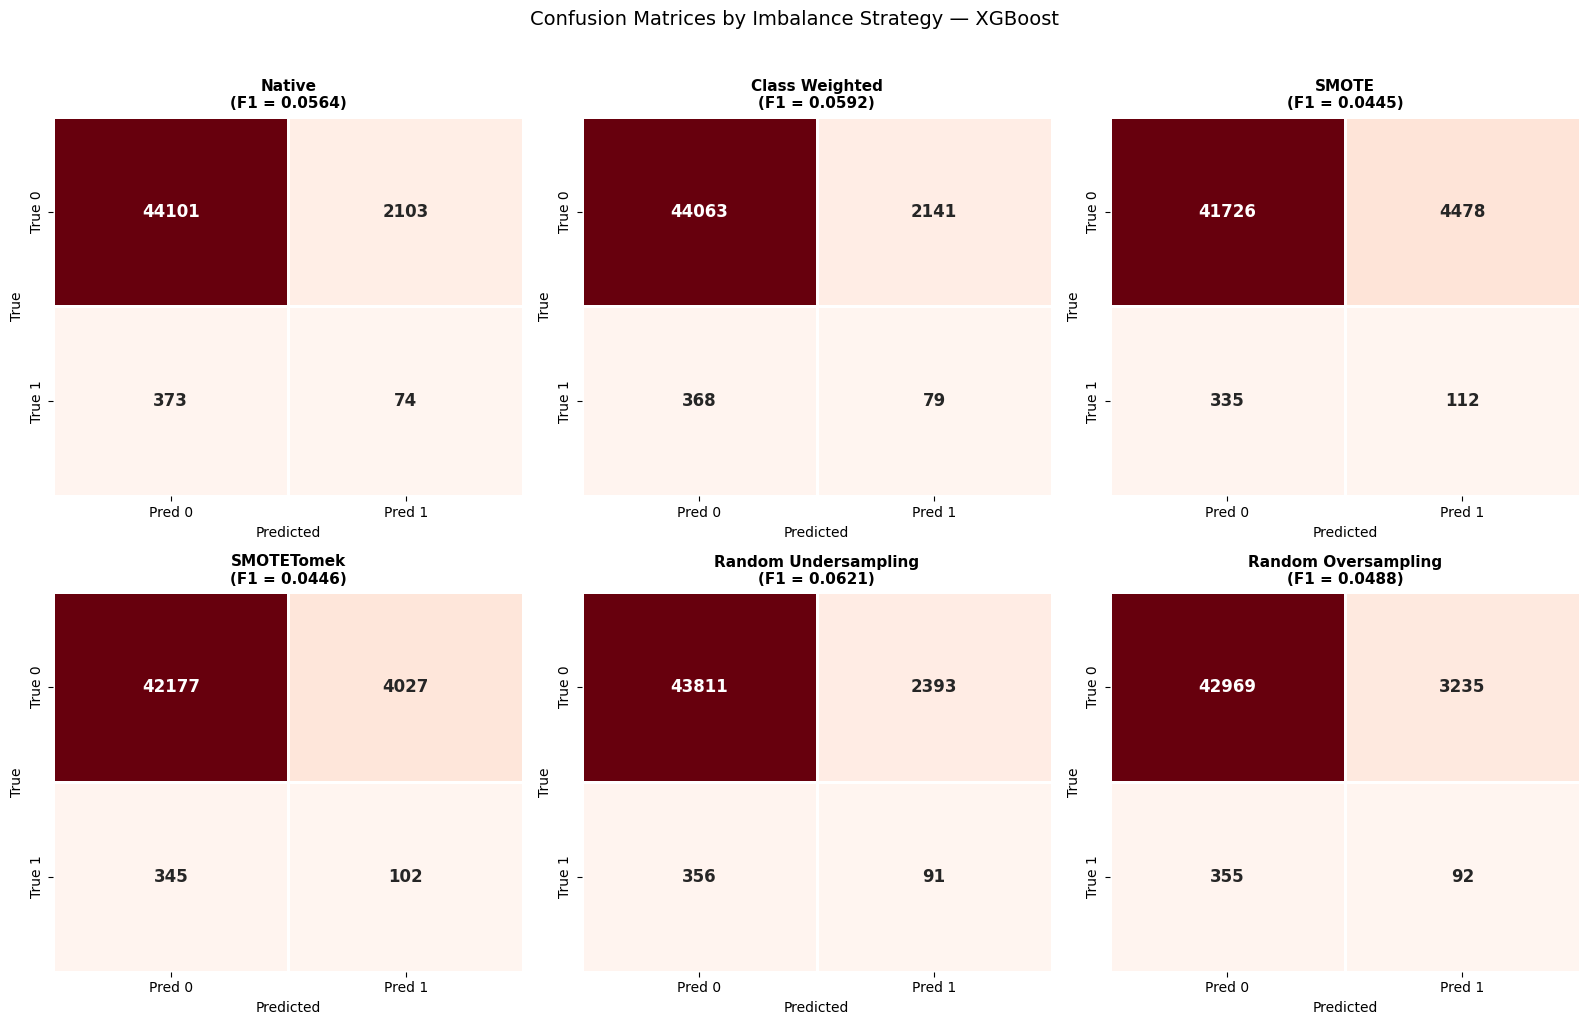

✓ Strategy grid saved for XGBoost.


In [72]:
# ============================================================
# SECTION 10.3 — STRATEGY GRID FOR THE BEST MODEL
# ============================================================
# The best model (highest PRIMARY_RANK_METRIC) with all six
# strategies side by side.

best_overall_model = (
    summary.sort_values(PRIMARY_RANK_METRIC, ascending=False)
           .iloc[0]["model"]
)
print(f"Best model: {best_overall_model}")

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for i, strat in enumerate(IMBALANCE_STRATEGIES):
    row = cm_agg[(cm_agg.model == best_overall_model) &
                 (cm_agg.imbalance_strategy == strat)]
    ax = axes[i]
    if row.empty:
        ax.axis("off")
        continue
    r = row.iloc[0]
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Reds", cbar=False,
        xticklabels=["Pred 0", "Pred 1"],
        yticklabels=["True 0", "True 1"],
        annot_kws={"size": 12, "weight": "bold"},
        linewidths=1, linecolor="white", ax=ax,
    )
    ax.set_title(f"{strat}\n(F1 = {r.f1:.4f})",
                 fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted", fontsize=10)
    ax.set_ylabel("True", fontsize=10)

plt.suptitle(f"Confusion Matrices by Imbalance Strategy — {best_overall_model}",
             fontsize=14, y=1.02)
plt.tight_layout()
safe_m = MODEL_DIRS[best_overall_model]
plt.savefig(CM_DIR / f"cm_by_strategy_{safe_m}.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"✓ Strategy grid saved for {best_overall_model}.")

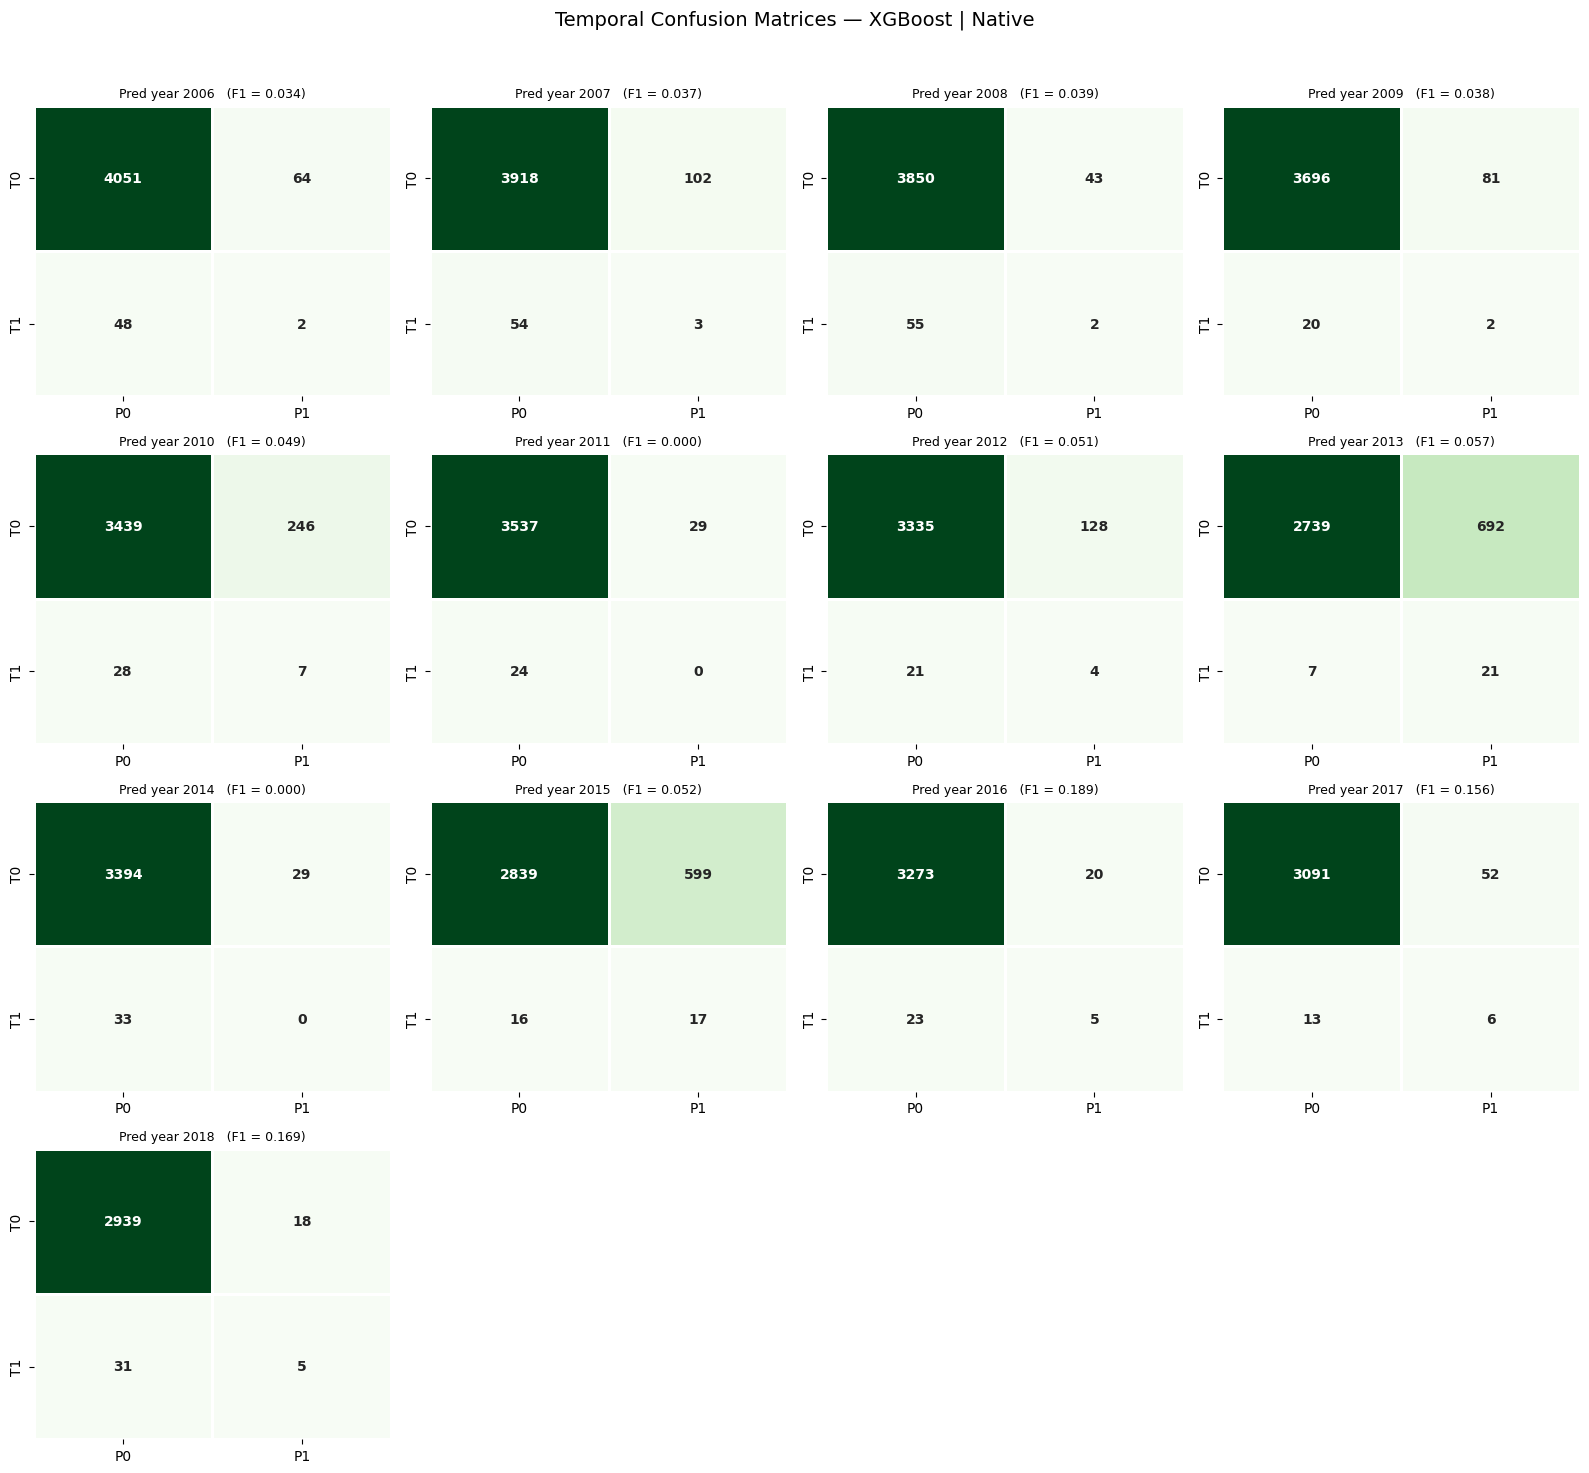

✓ Temporal confusion matrices saved (XGBoost | Native, 13 windows).


In [73]:
# ============================================================
# SECTION 10.4 — TEMPORAL CONFUSION MATRICES
# ============================================================
# Confusion matrices per prediction year for the best model
# with its best strategy (Section 7.6).

TEMPORAL_MODEL    = best_overall_model
TEMPORAL_STRATEGY = best_strategy_dict[TEMPORAL_MODEL]

sub = (
    rolling_results_df[
        (rolling_results_df.model == TEMPORAL_MODEL) &
        (rolling_results_df.imbalance_strategy == TEMPORAL_STRATEGY)
    ]
    .sort_values("prediction_year")
    .reset_index(drop=True)
)

years = sub.prediction_year.tolist()
n = len(years)
ncols = 4
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4.0 * ncols, 3.6 * nrows))
axes = np.array(axes).ravel()

for ax, (_, r) in zip(axes, sub.iterrows()):
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Greens", cbar=False,
        xticklabels=["P0", "P1"], yticklabels=["T0", "T1"],
        annot_kws={"size": 10, "weight": "bold"},
        linewidths=1, linecolor="white", ax=ax,
    )
    ax.set_title(f"Pred year {int(r.prediction_year)}   "
                 f"(F1 = {r.f1:.3f})", fontsize=9)

for ax in axes[n:]:
    ax.axis("off")

plt.suptitle(f"Temporal Confusion Matrices — "
             f"{TEMPORAL_MODEL} | {TEMPORAL_STRATEGY}",
             fontsize=14, y=1.02)
plt.tight_layout()
safe_m = MODEL_DIRS[TEMPORAL_MODEL]
safe_s = re.sub(r"[^A-Za-z0-9]+", "_", TEMPORAL_STRATEGY.lower())
plt.savefig(CM_DIR / f"cm_temporal_{safe_m}__{safe_s}.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"✓ Temporal confusion matrices saved "
      f"({TEMPORAL_MODEL} | {TEMPORAL_STRATEGY}, {n} windows).")

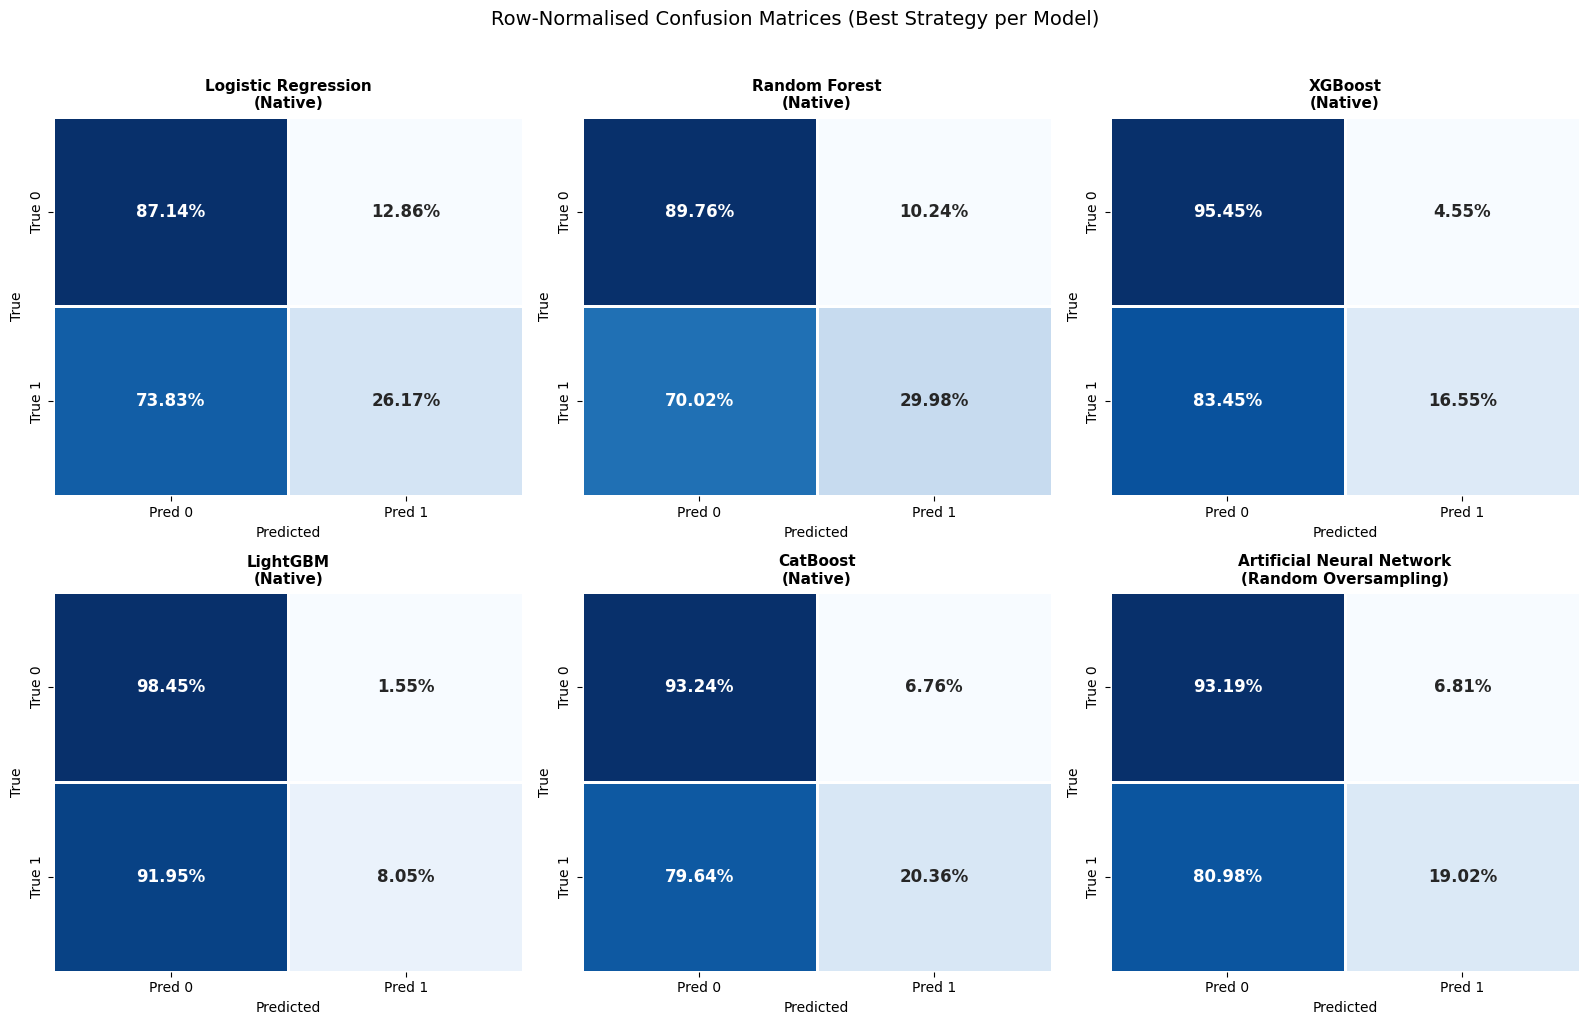

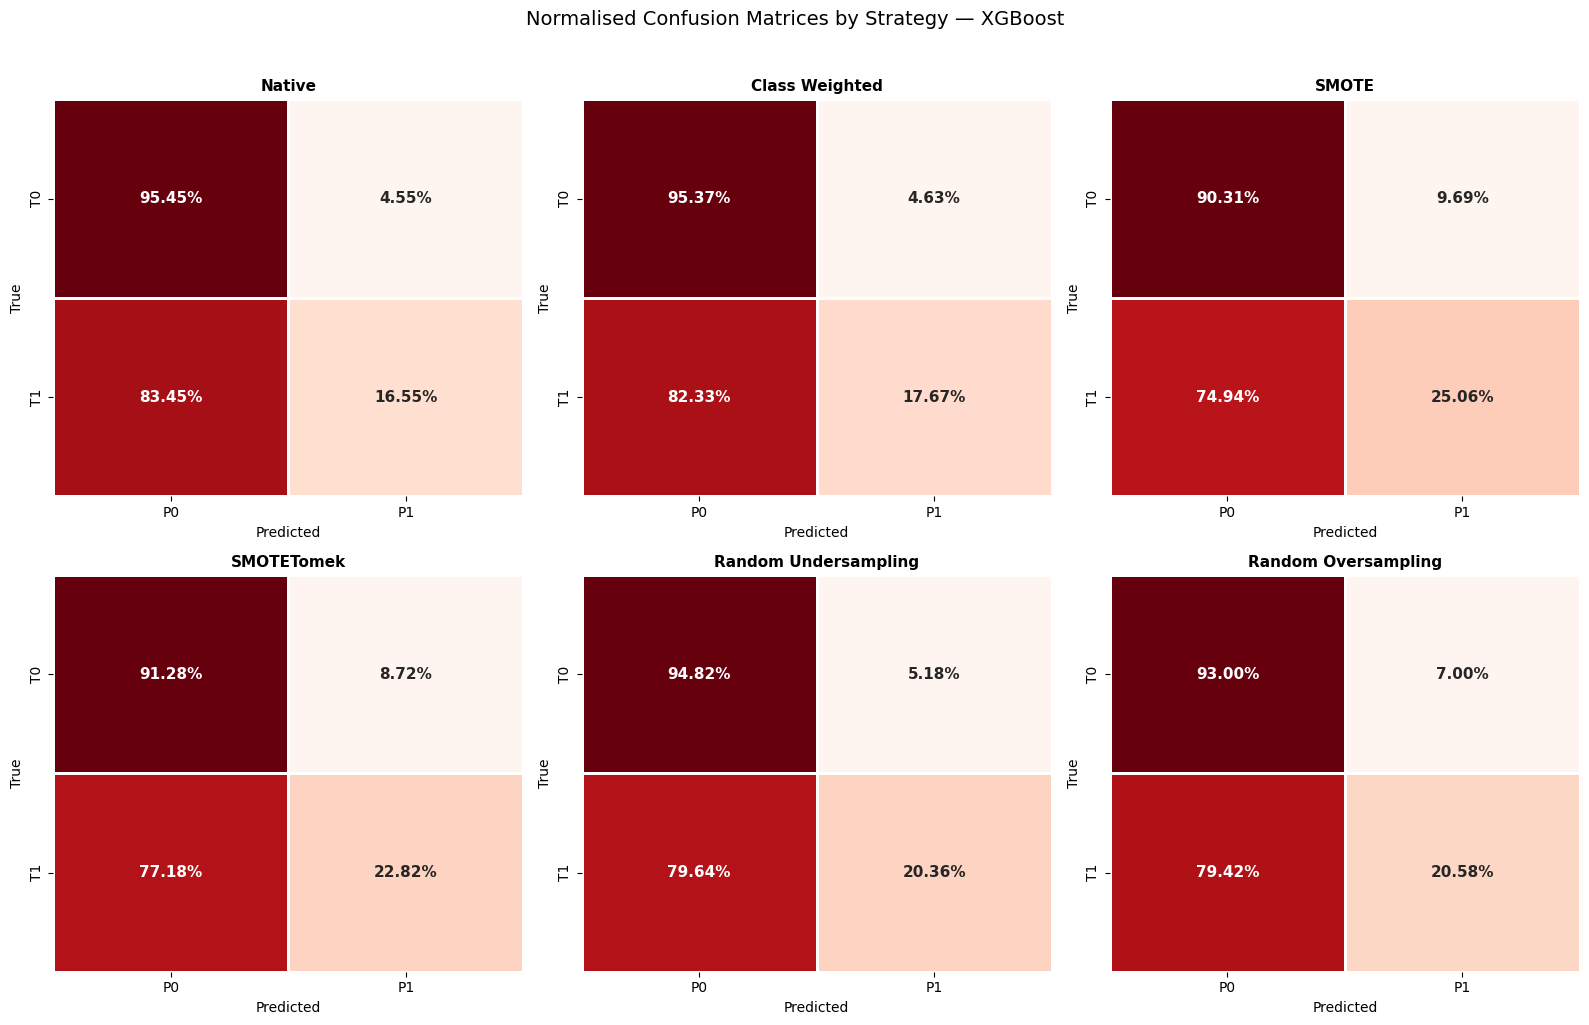

✓ Normalised confusion matrices saved.


In [74]:
# ============================================================
# SECTION 10.5 — NORMALISED CONFUSION MATRICES
# ============================================================
# Row-normalised: each row sums to 1.
# Reveals Type I and Type II error rates visually.

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for i, model_name in enumerate(MODEL_NAMES):
    strat = best_strategy_dict.get(model_name)
    row = cm_agg[(cm_agg.model == model_name) &
                 (cm_agg.imbalance_strategy == strat)]
    ax = axes[i]
    if row.empty:
        ax.axis("off")
        continue
    r = row.iloc[0]
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]], dtype=float)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    sns.heatmap(
        cm_norm, annot=True, fmt=".2%", cmap="Blues", cbar=False,
        xticklabels=["Pred 0", "Pred 1"],
        yticklabels=["True 0", "True 1"],
        annot_kws={"size": 12, "weight": "bold"},
        linewidths=1, linecolor="white", ax=ax,
    )
    ax.set_title(f"{model_name}\n({strat})",
                 fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted", fontsize=10)
    ax.set_ylabel("True", fontsize=10)

plt.suptitle("Row-Normalised Confusion Matrices (Best Strategy per Model)",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(CM_DIR / "cm_grid_normalised.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Also normalised per strategy for the best model
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for i, strat in enumerate(IMBALANCE_STRATEGIES):
    row = cm_agg[(cm_agg.model == best_overall_model) &
                 (cm_agg.imbalance_strategy == strat)]
    ax = axes[i]
    if row.empty:
        ax.axis("off")
        continue
    r = row.iloc[0]
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]], dtype=float)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    sns.heatmap(
        cm_norm, annot=True, fmt=".2%", cmap="Reds", cbar=False,
        xticklabels=["P0", "P1"], yticklabels=["T0", "T1"],
        annot_kws={"size": 11, "weight": "bold"},
        linewidths=1, linecolor="white", ax=ax,
    )
    ax.set_title(strat, fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted", fontsize=10)
    ax.set_ylabel("True", fontsize=10)

plt.suptitle(f"Normalised Confusion Matrices by Strategy — {best_overall_model}",
             fontsize=14, y=1.02)
plt.tight_layout()
safe_m = MODEL_DIRS[best_overall_model]
plt.savefig(CM_DIR / f"cm_normalised_by_strategy_{safe_m}.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("✓ Normalised confusion matrices saved.")

In [75]:
# ============================================================
# SECTION 10.6 — TYPE I / TYPE II ERROR TABLE
# ============================================================
# Per (model, strategy), report:
#   - TN, FP, FN, TP aggregated
#   - Type I error  = FP / (FP + TN)  [FPR]
#   - Type II error = FN / (FN + TP)  [FNR]
#   - Specificity   = 1 − Type I
#   - Recall        = 1 − Type II

error_table = cm_agg[[
    "model", "imbalance_strategy",
    "tn", "fp", "fn", "tp",
    "specificity", "recall",
    "type_i_error", "type_ii_error",
    "balanced_acc", "f1",
]].copy()

error_table.columns = [
    "Model", "Strategy",
    "TN", "FP", "FN", "TP",
    "Specificity", "Recall",
    "Type I error", "Type II error",
    "Balanced Acc", "F1",
]

error_table = error_table.sort_values(
    ["Type II error", "F1"], ascending=[True, False]
).reset_index(drop=True)

error_table.round(4).to_csv(
    TABLES_COMP / "type_i_ii_error_table.csv", index=False
)

print("Type I / Type II error table (sorted by Type II error ascending):")
print(error_table.round(4).to_string(index=False))

# ---- Aggregate per model for the dissertation ----
error_by_model = (
    error_table
    .groupby("Model")
    .agg(
        TN=("TN", "mean"),
        FP=("FP", "mean"),
        FN=("FN", "mean"),
        TP=("TP", "mean"),
        Specificity=("Specificity", "mean"),
        Recall=("Recall", "mean"),
        Type_I=("Type I error", "mean"),
        Type_II=("Type II error", "mean"),
        F1=("F1", "mean"),
    )
    .round(4)
    .reset_index()
)
error_by_model.to_csv(TABLES_COMP / "type_i_ii_error_by_model.csv", index=False)

print()
print("Aggregated per model (mean across strategies):")
print(error_by_model.to_string(index=False))

Type I / Type II error table (sorted by Type II error ascending):
                    Model             Strategy    TN    FP  FN  TP  Specificity  Recall  Type I error  Type II error  Balanced Acc     F1
Artificial Neural Network Random Undersampling 17415 28789 158 289       0.3769  0.6465        0.6231         0.3535        0.5117 0.0196
Artificial Neural Network               Native 33012 13192 229 218       0.7145  0.4877        0.2855         0.5123        0.6011 0.0315
                 LightGBM Random Undersampling 40739  5465 298 149       0.8817  0.3333        0.1183         0.6667        0.6075 0.0492
            Random Forest           SMOTETomek 35494 10710 304 143       0.7682  0.3199        0.2318         0.6801        0.5441 0.0253
            Random Forest               Native 41475  4729 313 134       0.8976  0.2998        0.1024         0.7002        0.5987 0.0505
Artificial Neural Network       Class Weighted 40230  5974 327 120       0.8707  0.2685        0.1293     

In [76]:
# Aggregated counts sum to total test rows
expected_total = rolling_results_df.groupby(
    ["model", "imbalance_strategy"]
)["test_n"].sum().reset_index(name="total")
check = cm_agg.merge(expected_total, on=["model", "imbalance_strategy"])
check["cm_sum"] = check.tn + check.fp + check.fn + check.tp
assert (check.cm_sum == check.total).all(), \
    "Aggregated CM cells do not sum to total test rows."
print("✓ CM cells sum to total test rows for every (model, strategy).")

# All figures written
cm_figs = list(CM_DIR.glob("*.png"))
assert len(cm_figs) >= 40, f"Expected ≥40 CM figures, got {len(cm_figs)}"
print(f"✓ {len(cm_figs)} confusion matrix figures saved.")

# Tables
for p in [
    TABLES_COMP / "confusion_matrix_aggregated.csv",
    TABLES_COMP / "type_i_ii_error_table.csv",
    TABLES_COMP / "type_i_ii_error_by_model.csv",
]:
    assert p.exists(), f"Missing: {p}"

print("✓ Section 10 complete. Ready for Section 11.")

✓ CM cells sum to total test rows for every (model, strategy).
✓ 41 confusion matrix figures saved.
✓ Section 10 complete. Ready for Section 11.


In [77]:
# ============================================================
# SECTION 11.1 — CALIBRATION DIAGNOSTICS
# ============================================================
# For each (model, strategy), compute:
#   - calibration intercept (ideal = 0)
#   - calibration slope     (ideal = 1)
#   - Brier score
#   - reliability diagram (10 quantile bins)
#
# Probabilities are clipped to [eps, 1-eps] before logit transform
# to avoid log(0).

import statsmodels.api as sm
from sklearn.calibration import calibration_curve

EPS = 1e-6

def calibration_intercept_slope(y_true, p):
    """
    Logistic regression of y on logit(p).
    Returns (intercept, slope).
    """
    y_true = np.asarray(y_true).astype(int)
    p = np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)
    logit_p = np.log(p / (1 - p))
    X = sm.add_constant(logit_p)
    try:
        model = sm.Logit(y_true, X).fit(disp=False)
        return float(model.params[0]), float(model.params[1])
    except Exception:
        return np.nan, np.nan


cal_rows = []

for model_name in MODEL_NAMES:
    for strategy in IMBALANCE_STRATEGIES:
        q = rolling_predictions_df[
            (rolling_predictions_df.model == model_name) &
            (rolling_predictions_df.imbalance_strategy == strategy)
        ]
        if q.empty:
            continue

        y = q.target_1yr.astype(int).values
        p = q.probability.values

        brier = brier_score_loss(y, p)
        ci, cs = calibration_intercept_slope(y, p)
        prevalence = y.mean()

        # Brier skill vs base-rate baseline
        brier_baseline = np.mean((y - prevalence) ** 2)
        brier_skill = 1 - brier / brier_baseline if brier_baseline > 0 else np.nan

        cal_rows.append({
            "model": model_name,
            "imbalance_strategy": strategy,
            "n_predictions": len(q),
            "pooled_prevalence": prevalence,
            "pooled_brier": brier,
            "brier_skill": brier_skill,
            "calibration_intercept": ci,
            "calibration_slope": cs,
        })

        # ---- Reliability diagram ----
        if y.sum() > 0 and len(np.unique(y)) == 2:
            obs, pred = calibration_curve(
                y, p, n_bins=10, strategy="quantile",
            )
            fig, ax = plt.subplots(figsize=(7, 7))
            ax.plot([0, 1], [0, 1], "k--", linewidth=1.0,
                    label="Perfectly calibrated")
            ax.plot(pred, obs, "o-", color="#4C72B0", linewidth=1.6,
                    markersize=7, label=f"{model_name} ({strategy})")
            ax.set_xlabel("Mean predicted probability", fontsize=11)
            ax.set_ylabel("Observed frequency", fontsize=11)
            ax.set_title(f"Calibration — {model_name} | {strategy}",
                         fontsize=12, fontweight="bold")
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1)
            ax.grid(alpha=0.3, linestyle="--")
            ax.set_axisbelow(True)
            ax.legend(loc="best", fontsize=9)
            plt.tight_layout()
            safe_m = MODEL_DIRS[model_name]
            safe_s = re.sub(r"[^A-Za-z0-9]+", "_", strategy.lower())
            plt.savefig(CAL_DIR / f"{safe_m}__{safe_s}.png",
                        dpi=300, bbox_inches="tight")
            plt.close()

cal_df = pd.DataFrame(cal_rows)
cal_df.to_csv(TABLES_COMP / "calibration_summary.csv", index=False)

print("Calibration summary (first 15 rows):")
print(cal_df.head(15).round(4).to_string(index=False))
print()
print(f"✓ {len(cal_df)} calibration figures saved to {CAL_DIR}")

Calibration summary (first 15 rows):
              model   imbalance_strategy  n_predictions  pooled_prevalence  pooled_brier  brier_skill  calibration_intercept  calibration_slope
Logistic Regression               Native          46651             0.0096        0.0095       0.0020                -1.4863             0.6623
Logistic Regression       Class Weighted          46651             0.0096        0.2717     -27.6298                -4.6294             0.3451
Logistic Regression                SMOTE          46651             0.0096        0.2608     -26.4786                -4.5969             0.3106
Logistic Regression           SMOTETomek          46651             0.0096        0.2562     -25.9998                -4.5828             0.3035
Logistic Regression Random Undersampling          46651             0.0096        0.2896     -29.5157                -4.7371             0.4199
Logistic Regression  Random Oversampling          46651             0.0096        0.2713     -27.58

Calibration summary (first 15 rows):
              model   imbalance_strategy  n_predictions  pooled_prevalence  pooled_brier  brier_skill  calibration_intercept  calibration_slope
Logistic Regression               Native          46651             0.0096        0.0095       0.0020                -1.4863             0.6623
Logistic Regression       Class Weighted          46651             0.0096        0.2717     -27.6298                -4.6294             0.3451
Logistic Regression                SMOTE          46651             0.0096        0.2608     -26.4786                -4.5969             0.3106
Logistic Regression           SMOTETomek          46651             0.0096        0.2562     -25.9998                -4.5828             0.3035
Logistic Regression Random Undersampling          46651             0.0096        0.2896     -29.5157                -4.7371             0.4199
Logistic Regression  Random Oversampling          46651             0.0096        0.2713     -27.58

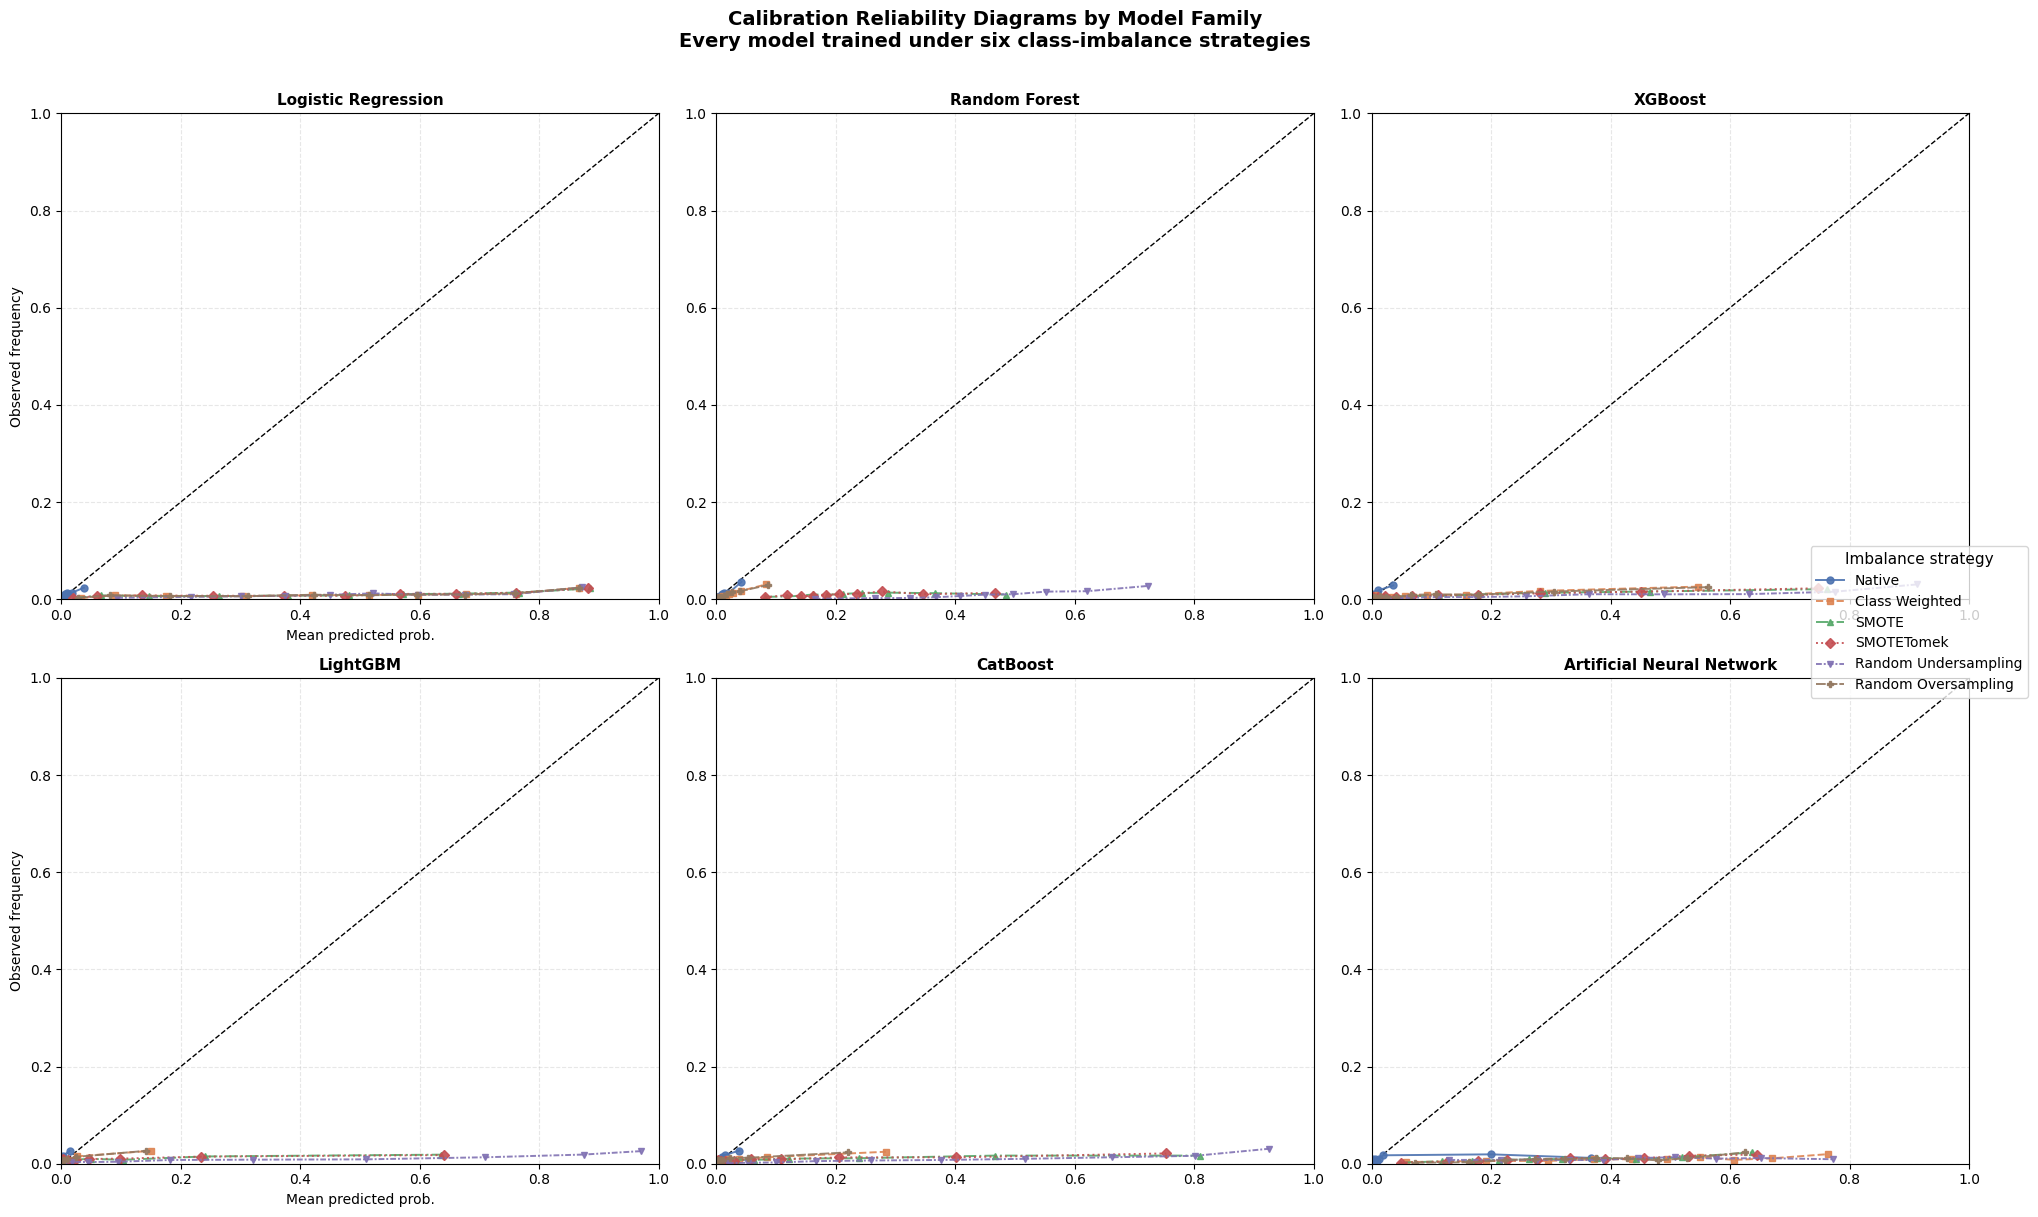


✓ 36 calibration figures saved to Rolling_results_now\cal_dir
✓ 6 per-model grids saved to Rolling_results_now\cal_dir
✓ 1 master 3×2 grid saved to Rolling_results_now\plots\comparative


In [78]:
# ============================================================
# SECTION 11.1 — CALIBRATION DIAGNOSTICS
# ============================================================
# For each (model, strategy), compute:
#   - calibration intercept (ideal = 0)
#   - calibration slope     (ideal = 1)
#   - Brier score
#   - reliability diagram (10 quantile bins)
#
# Individual reliability diagrams are saved per (model, strategy).
# Additionally, one 3×2 grid per model overlays all six strategies.

import statsmodels.api as sm
from sklearn.calibration import calibration_curve

EPS = 1e-6

# ---- Fixed colours per strategy (consistent with Section 8.2) ----
STRATEGY_COLORS = {
    "Native":               "#4C72B0",
    "Class Weighted":       "#DD8452",
    "SMOTE":                "#55A868",
    "SMOTETomek":           "#C44E52",
    "Random Undersampling": "#8172B3",
    "Random Oversampling":  "#937860",
}

STRATEGY_LINESTYLES = {
    "Native":               "-",
    "Class Weighted":       "--",
    "SMOTE":                "-.",
    "SMOTETomek":           ":",
    "Random Undersampling": (0, (3, 1, 1, 1)),   # dash-dot-dot
    "Random Oversampling":  (0, (5, 1)),
}

STRATEGY_MARKERS = {
    "Native":               "o",
    "Class Weighted":       "s",
    "SMOTE":                "^",
    "SMOTETomek":           "D",
    "Random Undersampling": "v",
    "Random Oversampling":  "P",
}


def calibration_intercept_slope(y_true, p):
    """Logistic regression of y on logit(p); returns (intercept, slope)."""
    y_true = np.asarray(y_true).astype(int)
    p = np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)
    logit_p = np.log(p / (1 - p))
    X = sm.add_constant(logit_p)
    try:
        model = sm.Logit(y_true, X).fit(disp=False)
        return float(model.params[0]), float(model.params[1])
    except Exception:
        return np.nan, np.nan


# ============================================================
# (a) Individual + pooled data collection
# ============================================================
cal_rows = []

# Store reliability curves per (model, strategy) for the grid overlay
reliability_curves = {}

for model_name in MODEL_NAMES:
    for strategy in IMBALANCE_STRATEGIES:
        q = rolling_predictions_df[
            (rolling_predictions_df.model == model_name) &
            (rolling_predictions_df.imbalance_strategy == strategy)
        ]
        if q.empty:
            continue

        y = q.target_1yr.astype(int).values
        p = q.probability.values

        brier = brier_score_loss(y, p)
        ci, cs = calibration_intercept_slope(y, p)
        prevalence = y.mean()
        brier_baseline = np.mean((y - prevalence) ** 2)
        brier_skill = 1 - brier / brier_baseline if brier_baseline > 0 else np.nan

        cal_rows.append({
            "model": model_name,
            "imbalance_strategy": strategy,
            "n_predictions": len(q),
            "pooled_prevalence": prevalence,
            "pooled_brier": brier,
            "brier_skill": brier_skill,
            "calibration_intercept": ci,
            "calibration_slope": cs,
        })

        # ---- Compute reliability curve once; reuse for both plot types ----
        if y.sum() > 0 and len(np.unique(y)) == 2:
            try:
                obs, pred = calibration_curve(
                    y, p, n_bins=10, strategy="quantile",
                )
                reliability_curves[(model_name, strategy)] = (pred, obs)
            except Exception:
                pass

cal_df = pd.DataFrame(cal_rows)
cal_df.to_csv("calibration_summary.csv", index=False)

print("Calibration summary (first 15 rows):")
print(cal_df.head(15).round(4).to_string(index=False))


# ============================================================
# (b) Individual reliability diagrams (unchanged behaviour)
# ============================================================
for (model_name, strategy), (pred, obs) in reliability_curves.items():
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.plot([0, 1], [0, 1], "k--", linewidth=1.0, label="Perfectly calibrated")
    ax.plot(pred, obs, "o-",
            color=STRATEGY_COLORS[strategy],
            linewidth=1.8, markersize=7,
            label=f"{model_name} ({strategy})")
    ax.set_xlabel("Mean predicted probability", fontsize=11)
    ax.set_ylabel("Observed frequency", fontsize=11)
    ax.set_title(f"Calibration — {model_name} | {strategy}",
                 fontsize=12, fontweight="bold")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.grid(alpha=0.3, linestyle="--"); ax.set_axisbelow(True)
    ax.legend(loc="best", fontsize=9)
    plt.tight_layout()
    safe_m = MODEL_DIRS[model_name]
    safe_s = re.sub(r"[^A-Za-z0-9]+", "_", strategy.lower())
    plt.savefig(f"{safe_m}__{safe_s}.png",
                dpi=300, bbox_inches="tight")
    plt.close()


# ============================================================
# (c) One 3×2 grid per model — all strategies on the same axes
# ============================================================
# Each panel overlays all six strategies for a single model.
# All six panels share x/y axes so the reader can compare across
# model families directly.

for model_name in MODEL_NAMES:
    fig, ax = plt.subplots(figsize=(9, 8))

    # Perfect-calibration reference
    ax.plot([0, 1], [0, 1], "k--", linewidth=1.2,
            label="Perfectly calibrated", zorder=1)

    any_drawn = False
    for strategy in IMBALANCE_STRATEGIES:
        curve = reliability_curves.get((model_name, strategy))
        if curve is None:
            continue
        pred, obs = curve
        ax.plot(
            pred, obs,
            color=STRATEGY_COLORS[strategy],
            linestyle=STRATEGY_LINESTYLES[strategy],
            marker=STRATEGY_MARKERS[strategy],
            markersize=6,
            linewidth=1.6,
            alpha=0.9,
            label=strategy,
            zorder=2,
        )
        any_drawn = True

    ax.set_xlabel("Mean predicted probability", fontsize=11)
    ax.set_ylabel("Observed frequency", fontsize=11)
    ax.set_title(f"Calibration — {model_name}\n"
                 f"(all six imbalance strategies)",
                 fontsize=12, fontweight="bold")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)

    if any_drawn:
        ax.legend(loc="best", fontsize=9, frameon=True, ncol=1)

    plt.tight_layout()
    safe_m = MODEL_DIRS[model_name]
    plt.savefig(f"{safe_m}__grid_all_strategies.png",
                dpi=300, bbox_inches="tight")
    plt.close()


# ============================================================
# (d) A single 3×2 master grid (one panel per model, all strategies)
# ============================================================
# This is the summary figure the dissertation will show as the
# "Calibration by model family" plot.

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.ravel()

for i, model_name in enumerate(MODEL_NAMES):
    ax = axes[i]

    # Reference line
    ax.plot([0, 1], [0, 1], "k--", linewidth=1.0, zorder=1)

    any_drawn = False
    for strategy in IMBALANCE_STRATEGIES:
        curve = reliability_curves.get((model_name, strategy))
        if curve is None:
            continue
        pred, obs = curve
        ax.plot(
            pred, obs,
            color=STRATEGY_COLORS[strategy],
            linestyle=STRATEGY_LINESTYLES[strategy],
            marker=STRATEGY_MARKERS[strategy],
            markersize=5,
            linewidth=1.4,
            alpha=0.9,
            label=strategy if i == 0 else None,   # legend once
            zorder=2,
        )
        any_drawn = True

    ax.set_title(model_name, fontsize=11, fontweight="bold")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)

    if i == 0:
        ax.set_xlabel("Mean predicted prob.", fontsize=10)
        ax.set_ylabel("Observed frequency", fontsize=10)
    if i == 3:
        ax.set_xlabel("Mean predicted prob.", fontsize=10)
        ax.set_ylabel("Observed frequency", fontsize=10)

if len(MODEL_NAMES) < len(axes):
    for ax in axes[len(MODEL_NAMES):]:
        ax.axis("off")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    title="Imbalance strategy",
    loc="center right",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=10, title_fontsize=11,
    frameon=True,
)

fig.suptitle("Calibration Reliability Diagrams by Model Family\n"
             "Every model trained under six class-imbalance strategies",
             fontsize=14, fontweight="bold", y=1.01)

plt.tight_layout()
plt.savefig("calibration_grids_by_model.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print()
print(f"✓ {len(cal_df)} calibration figures saved to {CAL_DIR}")
print(f"✓ {len(MODEL_NAMES)} per-model grids saved to {CAL_DIR}")
print(f"✓ 1 master 3×2 grid saved to {COMPARATIVE}")

Calibration summary (first 15 rows):
              model   imbalance_strategy  n_predictions  pooled_prevalence  pooled_brier  brier_skill  calibration_intercept  calibration_slope
Logistic Regression               Native          46651             0.0096        0.0095       0.0020                -1.4863             0.6623
Logistic Regression       Class Weighted          46651             0.0096        0.2717     -27.6298                -4.6294             0.3451
Logistic Regression                SMOTE          46651             0.0096        0.2608     -26.4786                -4.5969             0.3106
Logistic Regression           SMOTETomek          46651             0.0096        0.2562     -25.9998                -4.5828             0.3035
Logistic Regression Random Undersampling          46651             0.0096        0.2896     -29.5157                -4.7371             0.4199
Logistic Regression  Random Oversampling          46651             0.0096        0.2713     -27.58

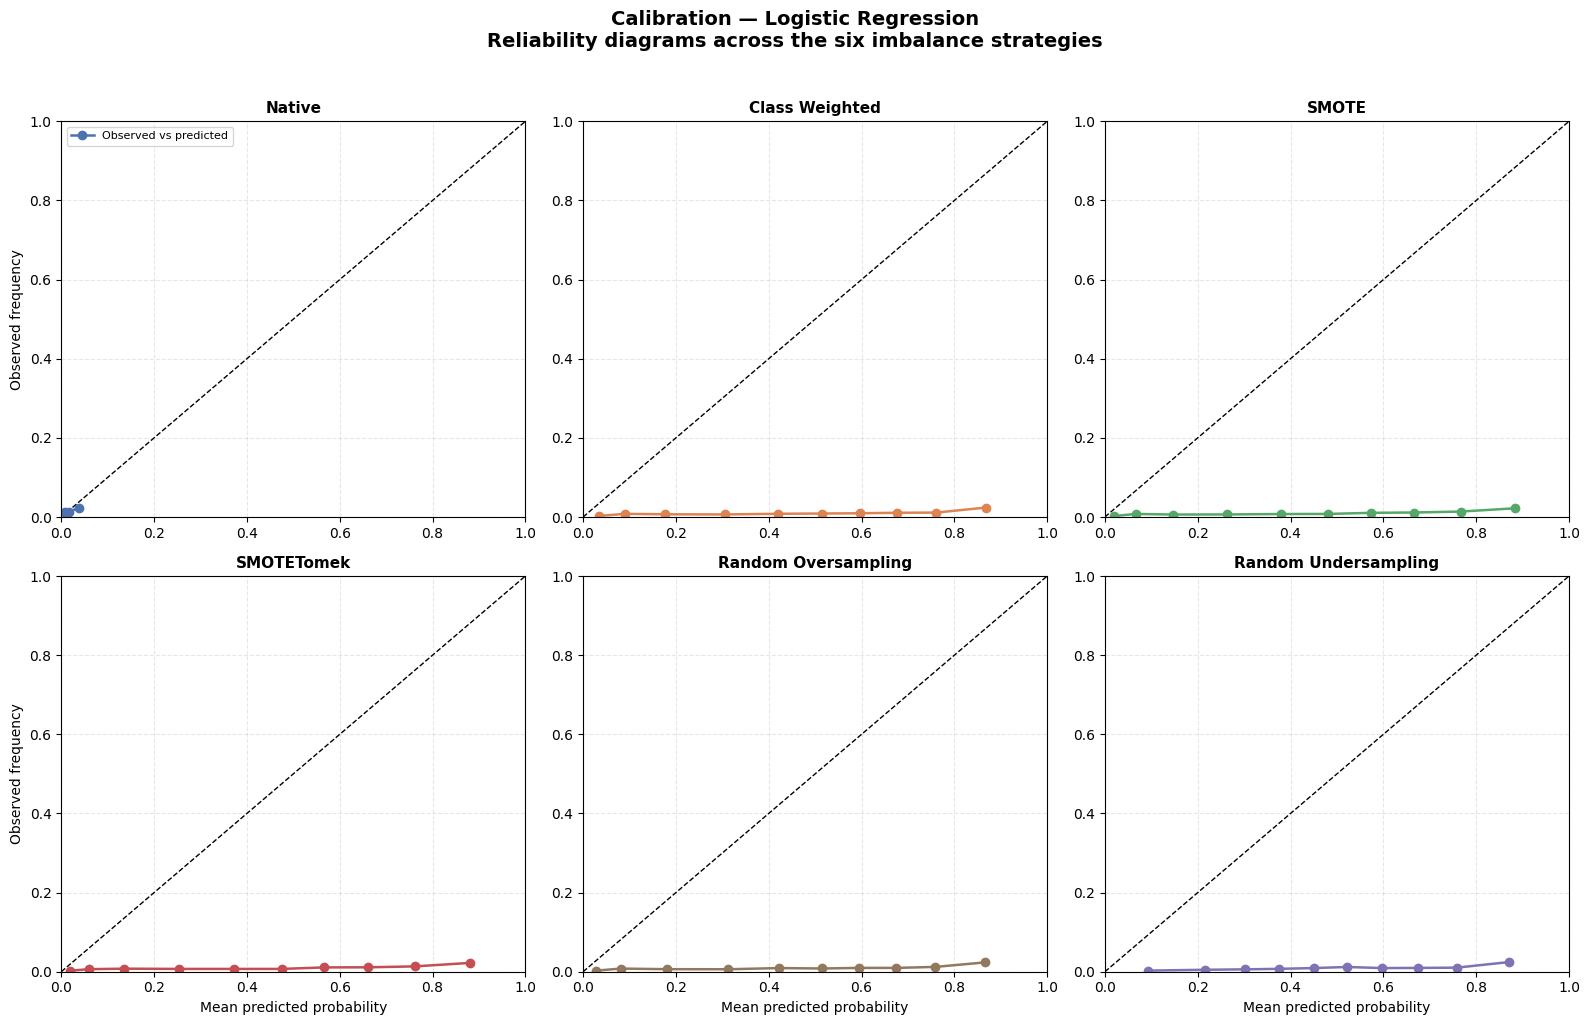

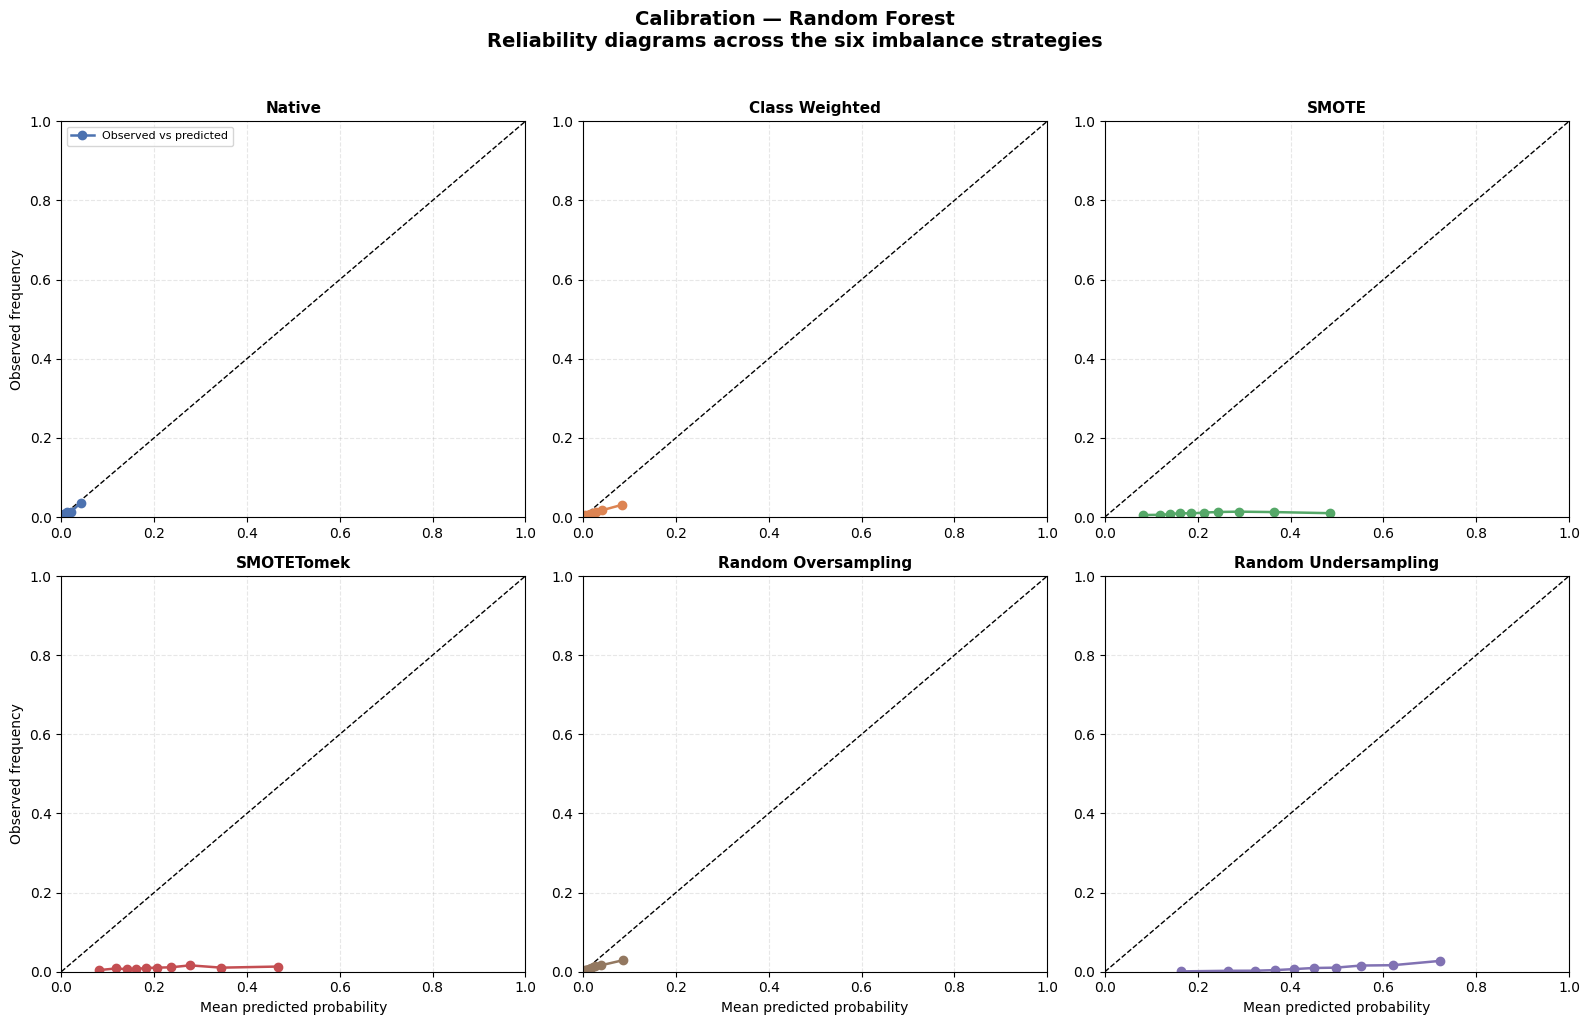

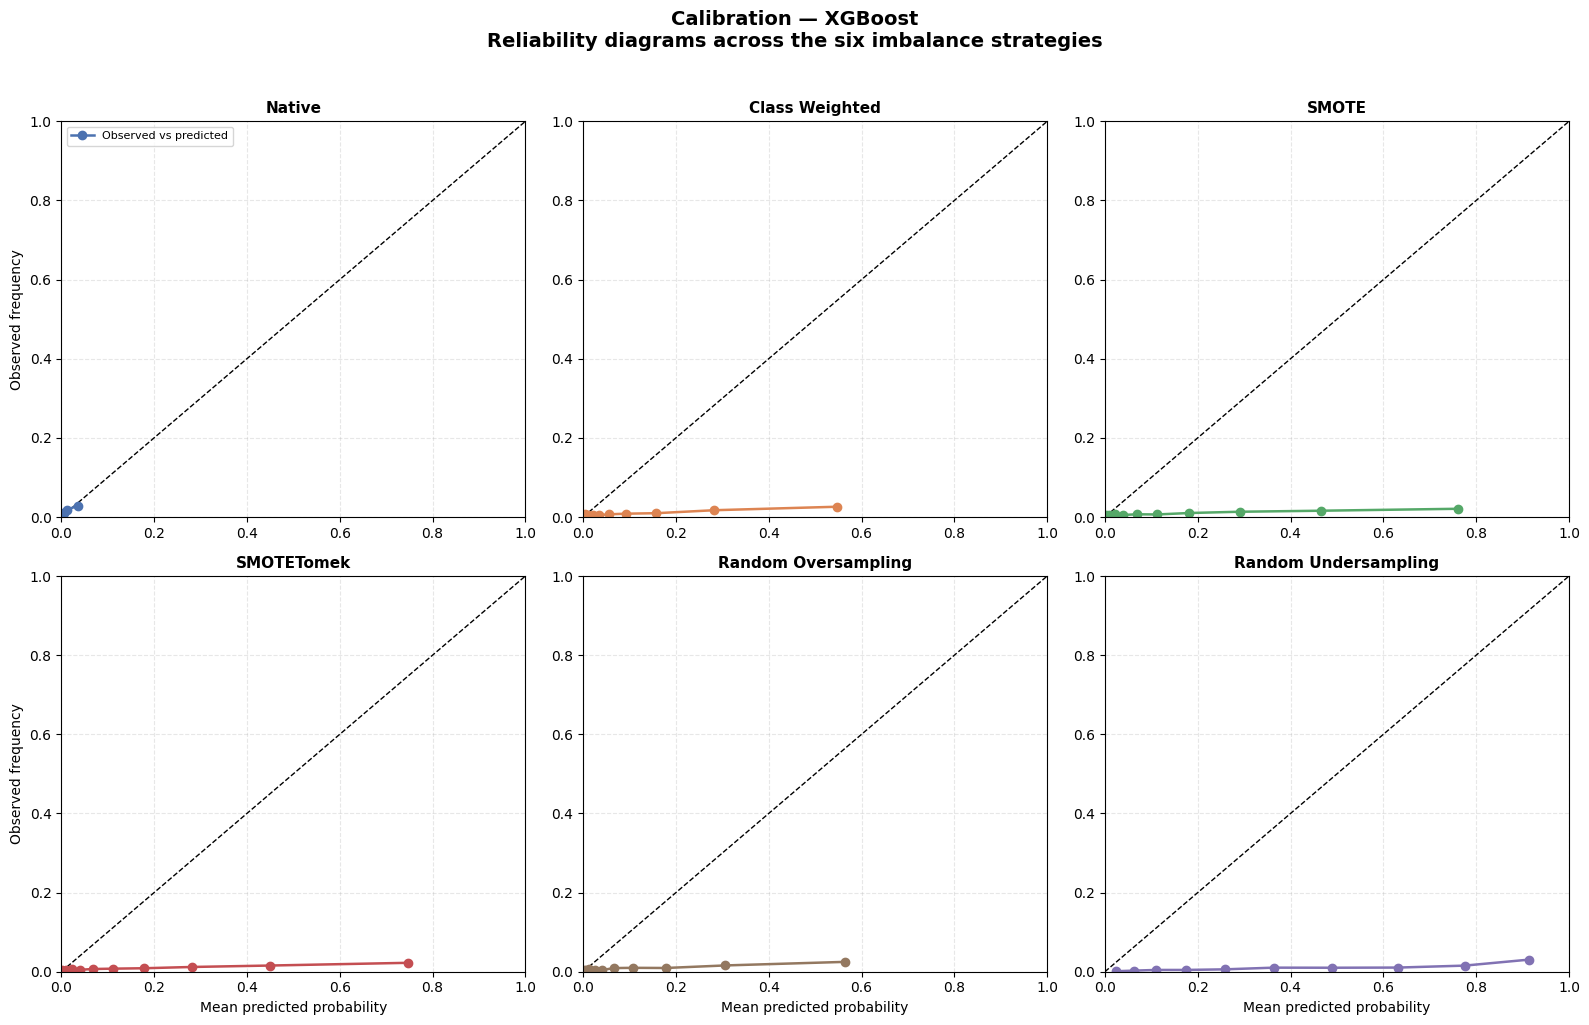

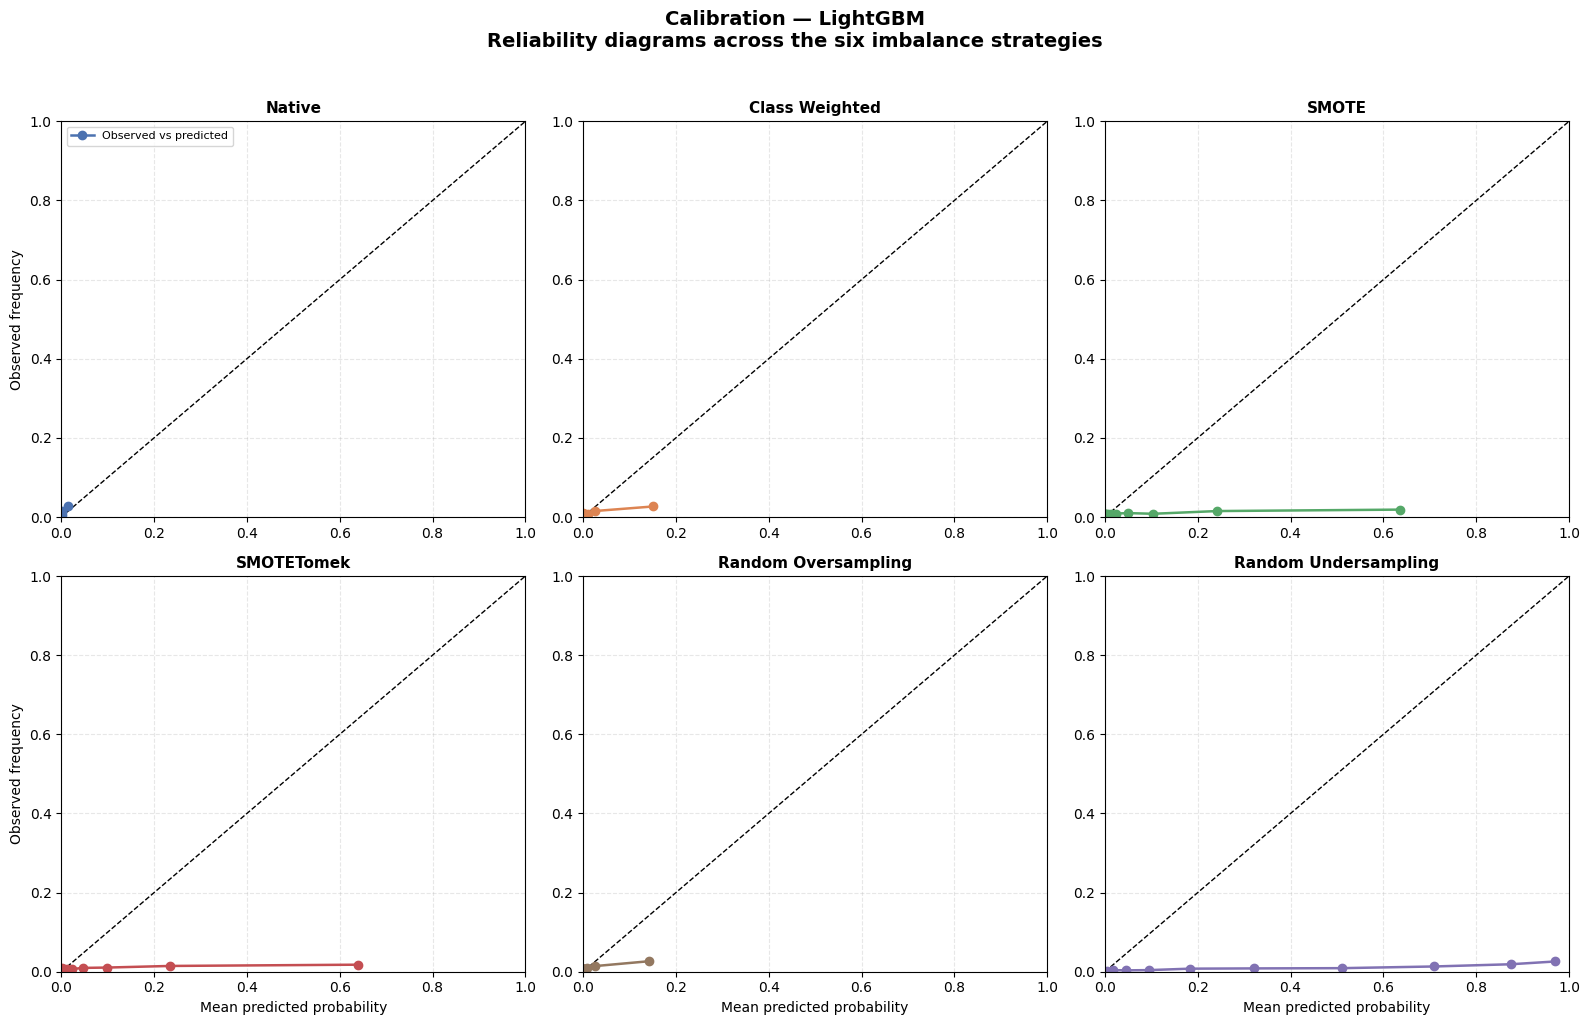

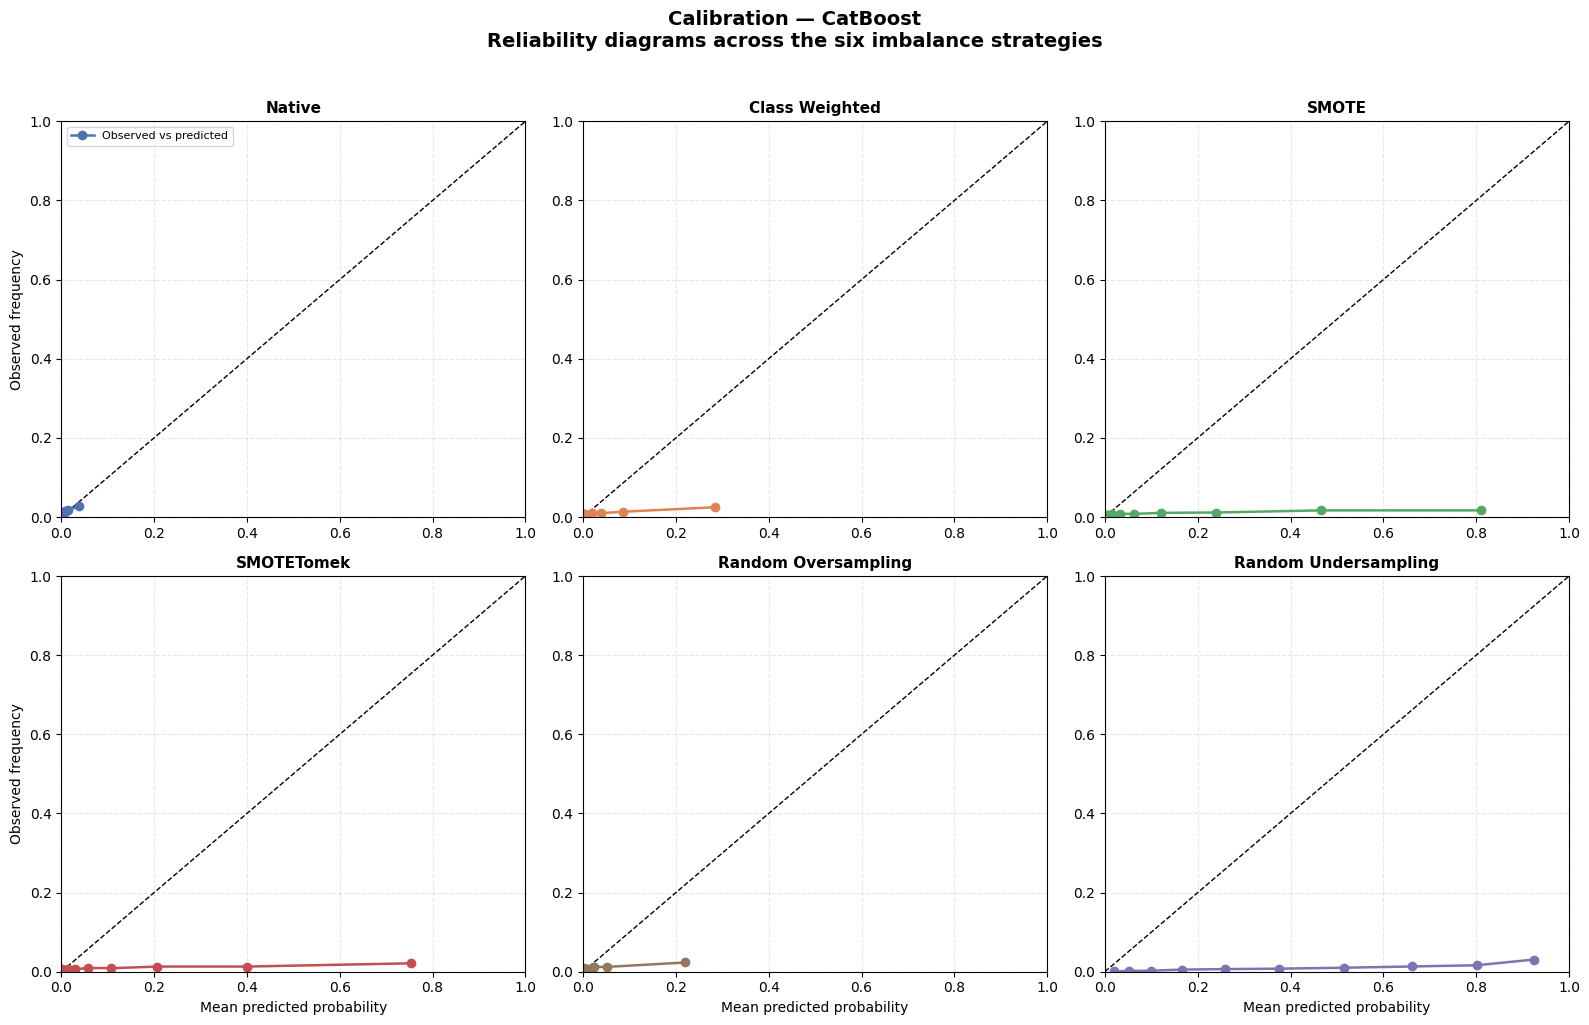

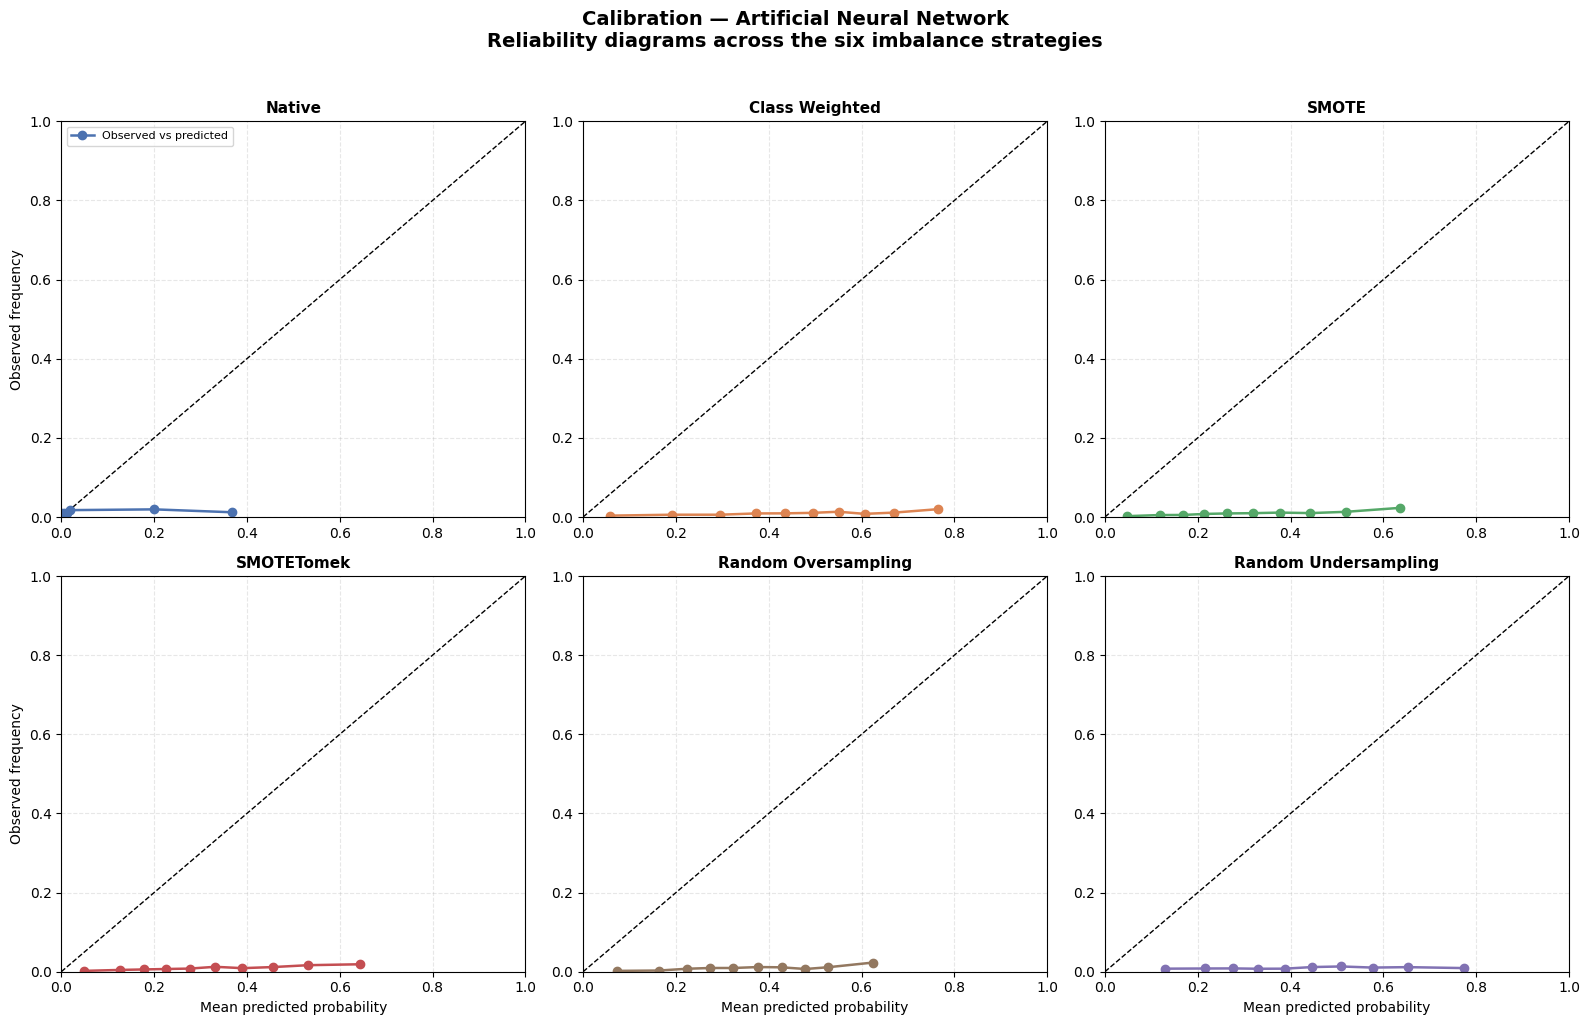


✓ 36 calibration figures saved to Rolling_results_now\cal_dir
✓ 6 per-model 3×2 grids saved to Rolling_results_now\cal_dir


In [79]:
# ============================================================
# SECTION 11.1 — CALIBRATION DIAGNOSTICS
# ============================================================
# For each (model, strategy), compute:
#   - calibration intercept (ideal = 0)
#   - calibration slope     (ideal = 1)
#   - Brier score
#   - reliability diagram (10 quantile bins)
#
# Individual reliability diagrams saved per (model, strategy).
# Additionally, one 3×2 grid per model: each panel shows one
# strategy, arranged:
#   Row 1: Native | Class Weighted | SMOTE
#   Row 2: SMOTETomek | Random Oversampling | Random Undersampling

import statsmodels.api as sm
from sklearn.calibration import calibration_curve

EPS = 1e-6

# ---- Panel order (must match the requested layout) ----
GRID_ORDER = [
    "Native",               "Class Weighted",       "SMOTE",
    "SMOTETomek",           "Random Oversampling",  "Random Undersampling",
]

# ---- Fixed colours per strategy ----
STRATEGY_COLORS = {
    "Native":               "#4C72B0",
    "Class Weighted":       "#DD8452",
    "SMOTE":                "#55A868",
    "SMOTETomek":           "#C44E52",
    "Random Undersampling": "#8172B3",
    "Random Oversampling":  "#937860",
}


def calibration_intercept_slope(y_true, p):
    """Logistic regression of y on logit(p); returns (intercept, slope)."""
    y_true = np.asarray(y_true).astype(int)
    p = np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)
    logit_p = np.log(p / (1 - p))
    X = sm.add_constant(logit_p)
    try:
        model = sm.Logit(y_true, X).fit(disp=False)
        return float(model.params[0]), float(model.params[1])
    except Exception:
        return np.nan, np.nan


# ============================================================
# (a) Compute metrics and store reliability curves
# ============================================================
cal_rows = []
reliability_curves = {}

for model_name in MODEL_NAMES:
    for strategy in IMBALANCE_STRATEGIES:
        q = rolling_predictions_df[
            (rolling_predictions_df.model == model_name) &
            (rolling_predictions_df.imbalance_strategy == strategy)
        ]
        if q.empty:
            continue

        y = q.target_1yr.astype(int).values
        p = q.probability.values

        brier = brier_score_loss(y, p)
        ci, cs = calibration_intercept_slope(y, p)
        prevalence = y.mean()
        brier_baseline = np.mean((y - prevalence) ** 2)
        brier_skill = 1 - brier / brier_baseline if brier_baseline > 0 else np.nan

        cal_rows.append({
            "model": model_name,
            "imbalance_strategy": strategy,
            "n_predictions": len(q),
            "pooled_prevalence": prevalence,
            "pooled_brier": brier,
            "brier_skill": brier_skill,
            "calibration_intercept": ci,
            "calibration_slope": cs,
        })

        if y.sum() > 0 and len(np.unique(y)) == 2:
            try:
                obs, pred = calibration_curve(
                    y, p, n_bins=10, strategy="quantile",
                )
                reliability_curves[(model_name, strategy)] = (pred, obs)
            except Exception:
                pass

cal_df = pd.DataFrame(cal_rows)
cal_df.to_csv("calibration_summary.csv", index=False)

print("Calibration summary (first 15 rows):")
print(cal_df.head(15).round(4).to_string(index=False))


# ============================================================
# (b) Individual reliability diagrams (unchanged behaviour)
# ============================================================
for (model_name, strategy), (pred, obs) in reliability_curves.items():
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.plot([0, 1], [0, 1], "k--", linewidth=1.0,
            label="Perfectly calibrated")
    ax.plot(pred, obs, "o-",
            color=STRATEGY_COLORS[strategy],
            linewidth=1.8, markersize=7,
            label=f"{model_name} ({strategy})")
    ax.set_xlabel("Mean predicted probability", fontsize=11)
    ax.set_ylabel("Observed frequency", fontsize=11)
    ax.set_title(f"Calibration — {model_name} | {strategy}",
                 fontsize=12, fontweight="bold")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.grid(alpha=0.3, linestyle="--"); ax.set_axisbelow(True)
    ax.legend(loc="best", fontsize=9)
    plt.tight_layout()
    safe_m = MODEL_DIRS[model_name]
    safe_s = re.sub(r"[^A-Za-z0-9]+", "_", strategy.lower())
    plt.savefig(f"{safe_m}__{safe_s}.png",
                dpi=300, bbox_inches="tight")
    plt.close()


# ============================================================
# (c) 3×2 per-model grids — one panel per strategy
# ============================================================
# Panel order:
#   Row 1: Native | Class Weighted | SMOTE
#   Row 2: SMOTETomek | Random Oversampling | Random Undersampling
#
# One grid per model. Loops through MODEL_NAMES in order.

for model_name in MODEL_NAMES:
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.ravel()

    for i, strategy in enumerate(GRID_ORDER):
        ax = axes[i]

        # Perfect-calibration reference
        ax.plot([0, 1], [0, 1], "k--", linewidth=1.0, zorder=1)

        curve = reliability_curves.get((model_name, strategy))
        if curve is None:
            ax.text(0.5, 0.5, "no data", ha="center", va="center",
                    transform=ax.transAxes, fontsize=10, color="grey")
        else:
            pred, obs = curve
            ax.plot(
                pred, obs,
                color=STRATEGY_COLORS[strategy],
                marker="o", markersize=6,
                linewidth=1.8,
                zorder=2,
                label="Observed vs predicted",
            )

        ax.set_title(strategy, fontsize=11, fontweight="bold")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.grid(alpha=0.3, linestyle="--")
        ax.set_axisbelow(True)

        # Labels on the outer edges only
        if i in (3, 4, 5):
            ax.set_xlabel("Mean predicted probability", fontsize=10)
        if i in (0, 3):
            ax.set_ylabel("Observed frequency", fontsize=10)

        # Reference legend only on the first panel
        if i == 0:
            ax.legend(loc="best", fontsize=8)

    fig.suptitle(f"Calibration — {model_name}\n"
                 f"Reliability diagrams across the six imbalance strategies",
                 fontsize=14, fontweight="bold", y=1.02)

    plt.tight_layout()
    safe_m = MODEL_DIRS[model_name]
    plt.savefig(f"{safe_m}__grid_by_strategy.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


print()
print(f"✓ {len(cal_df)} calibration figures saved to {CAL_DIR}")
print(f"✓ {len(MODEL_NAMES)} per-model 3×2 grids saved to {CAL_DIR}")

In [80]:
# ============================================================
# SECTION 11.2 — ISOTONIC RECALIBRATION FOR TREES
# ============================================================
# Tree models tend to produce over-confident or under-confident
# probabilities. Fit isotonic regression on the VALIDATION set of
# the last fold, apply it to the TEST set, and compare Brier.
#
# Uses only the last fold (info year 2017) for speed.

from sklearn.isotonic import IsotonicRegression

RECAL_FOLD_YEAR = 2017

sp_recal = rolling_splits[
    rolling_splits.test_information_year == RECAL_FOLD_YEAR
].iloc[0]

tr_recal = df_target[df_target.year <= int(sp_recal.train_end)].copy()
va_recal = df_target[df_target.year == int(sp_recal.validation_year)].copy()
te_recal = df_target[df_target.year == int(sp_recal.test_information_year)].copy()

X_tr_r = tr_recal[feature_columns]
X_va_r = va_recal[feature_columns]
X_te_r = te_recal[feature_columns]
y_tr_r = tr_recal.target_1yr.astype(int)
y_va_r = va_recal.target_1yr.astype(int)
y_te_r = te_recal.target_1yr.astype(int)

recal_rows = []

for model_name in MODEL_NAMES:
    if model_name not in TREE_MODELS:
        continue

    strat = best_strategy_dict[model_name]
    print(f"  Isotonic recalibration: {model_name} | {strat}")

    try:
        pipe = build_model(model_name, strat, y_tr_r)
        pipe.fit(X_tr_r, y_tr_r)

        p_va = pipe.predict_proba(X_va_r)[:, 1]
        p_te = pipe.predict_proba(X_te_r)[:, 1]

        # Raw
        brier_raw = brier_score_loss(y_te_r, p_te)

        # Isotonic on validation → test
        iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
        iso.fit(p_va, y_va_r)
        p_te_iso = iso.predict(p_te)
        brier_iso = brier_score_loss(y_te_r, p_te_iso)

        recal_rows.append({
            "model": model_name,
            "strategy": strat,
            "brier_raw": brier_raw,
            "brier_isotonic": brier_iso,
            "brier_improvement": brier_raw - brier_iso,
        })
    except Exception as e:
        recal_rows.append({
            "model": model_name,
            "strategy": strat,
            "error": str(e),
        })
        print(f"    ERROR: {e}")

recal_df = pd.DataFrame(recal_rows)
recal_df.to_csv(TABLES_COMP / "isotonic_calibration.csv", index=False)

print()
print("Isotonic recalibration results (last fold):")
print(recal_df.round(5).to_string(index=False))

  Isotonic recalibration: Random Forest | Native
  Isotonic recalibration: XGBoost | Native
  Isotonic recalibration: LightGBM | Native
  Isotonic recalibration: CatBoost | Native

Isotonic recalibration results (last fold):
        model strategy  brier_raw  brier_isotonic  brier_improvement
Random Forest   Native    0.01142         0.01169           -0.00027
      XGBoost   Native    0.01143         0.01148           -0.00005
     LightGBM   Native    0.01143         0.01162           -0.00019
     CatBoost   Native    0.01156         0.01172           -0.00016


Cost sensitivity (mean expected cost per fold):
                    model   imbalance_strategy cost_ratio  mean_cost   sd_cost  mean_threshold  mean_cost_threshold  threshold_shift
Artificial Neural Network       Class Weighted       10:1   711.0769  444.2967          0.6854               0.9038           0.2185
Artificial Neural Network       Class Weighted       20:1   962.6154  494.5133          0.6854               0.8554           0.1700
Artificial Neural Network       Class Weighted        5:1   585.3077  426.7912          0.6854               0.9215           0.2362
Artificial Neural Network               Native       10:1  1190.9231 1023.5063          0.0600               0.2377           0.1777
Artificial Neural Network               Native       20:1  1367.0769  985.1516          0.0600               0.1931           0.1331
Artificial Neural Network               Native        5:1  1102.8462 1046.5146          0.0600               0.3200           0.2600
Artificial Neural Net

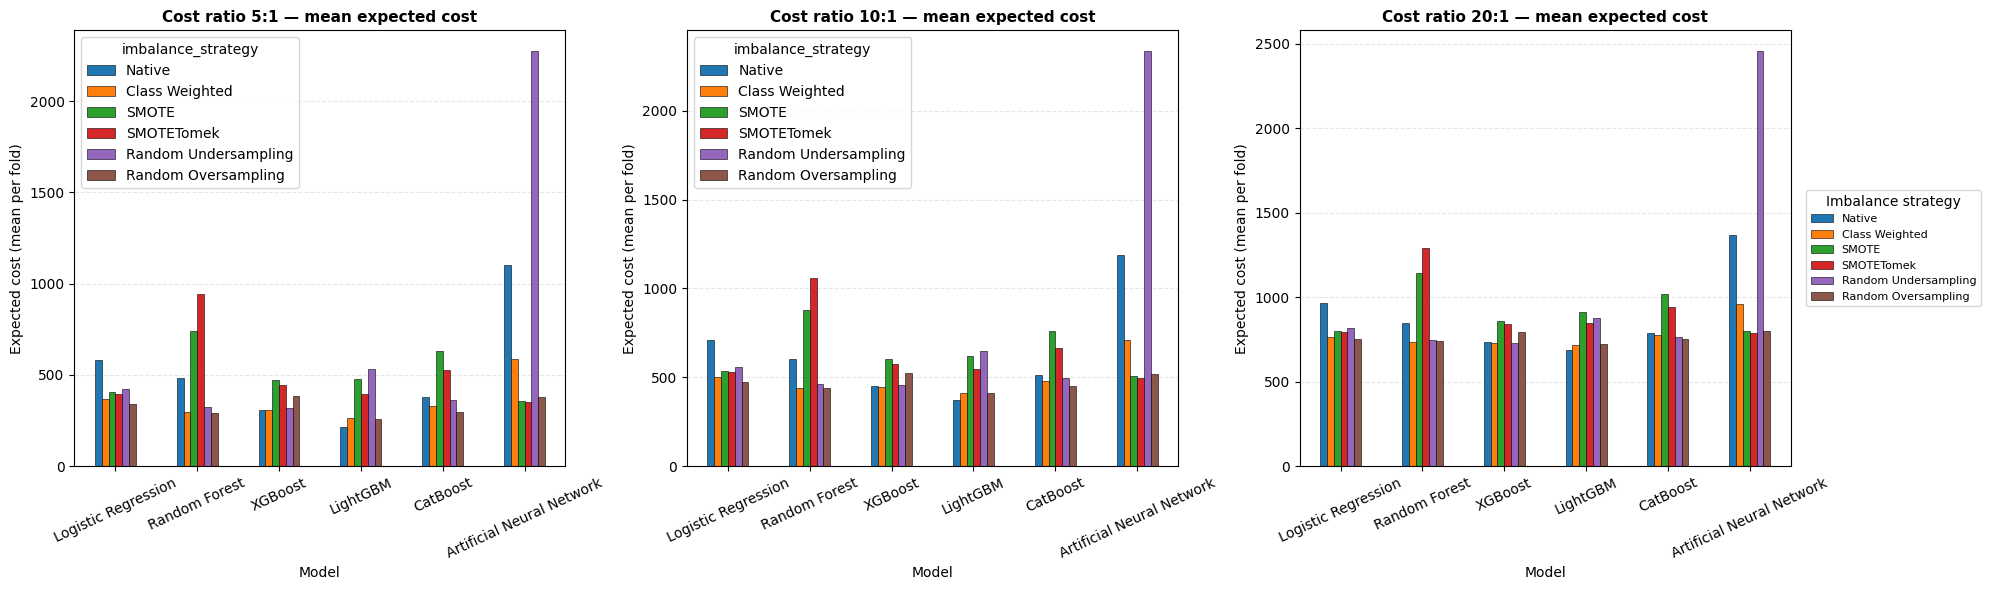


✓ Cost sensitivity summary saved.


In [81]:
# ============================================================
# SECTION 11.3 — COST SENSITIVITY
# ============================================================
# For each (model, strategy):
#   - Recompute the cost-optimal threshold using the aggregated
#     validation probabilities. (For this section we use the
#     stored F1-optimal threshold's confusion cells and the
#     stored cost-optimal thresholds.)
#   - Compare expected cost at the F1 threshold vs the cost-
#     optimal threshold. The gap = "decision-gap" from using
#     the wrong threshold.

# Since we stored threshold_5to1, threshold_10to1, threshold_20to1
# in Section 6 but not the corresponding cost-optimal confusion cells,
# we recompute the aggregate costs from the confusion cells of the
# F1-optimal threshold. The "decision-gap" is reported as the
# expected cost at the F1-optimal threshold.

cost_summary = []

for _, row in rolling_results_df.iterrows():
    for (c_fn, c_fp, label) in COST_RATIOS:
        expected_cost = c_fn * row.fn + c_fp * row.fp
        cost_summary.append({
            "model": row.model,
            "imbalance_strategy": row.imbalance_strategy,
            "test_information_year": row.test_information_year,
            "cost_ratio": label,
            "c_fn": c_fn,
            "c_fp": c_fp,
            "fn": row.fn,
            "fp": row.fp,
            "expected_cost": expected_cost,
            "optimal_threshold": row.optimal_threshold,
            "cost_optimal_threshold": row.get(f"threshold_{label.replace(':', 'to')}", np.nan),
        })

cost_df = pd.DataFrame(cost_summary)

# Aggregate per (model, strategy, cost_ratio)
cost_agg = (
    cost_df
    .groupby(["model", "imbalance_strategy", "cost_ratio"])
    .agg(
        mean_cost=("expected_cost", "mean"),
        sd_cost=("expected_cost", "std"),
        mean_threshold=("optimal_threshold", "mean"),
        mean_cost_threshold=("cost_optimal_threshold", "mean"),
    )
    .reset_index()
)

cost_agg["threshold_shift"] = (
    cost_agg["mean_cost_threshold"] - cost_agg["mean_threshold"]
)

cost_agg.to_csv(TABLES_COMP / "cost_sensitive_summary.csv", index=False)

print("Cost sensitivity (mean expected cost per fold):")
print(cost_agg.round(4).to_string(index=False))

# ---- Bar chart: mean cost per model x strategy, one panel per ratio ----
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=False)

for ax, label in zip(axes, ["5:1", "10:1", "20:1"]):
    sub = cost_agg[cost_agg.cost_ratio == label]
    pivot = sub.pivot(index="model", columns="imbalance_strategy",
                      values="mean_cost")
    pivot = pivot.reindex(index=MODEL_NAMES, columns=IMBALANCE_STRATEGIES)
    pivot.plot(kind="bar", ax=ax, edgecolor="black", linewidth=0.4)
    ax.set_title(f"Cost ratio {label} — mean expected cost",
                 fontsize=11, fontweight="bold")
    ax.set_xlabel("Model")
    ax.set_ylabel("Expected cost (mean per fold)")
    ax.grid(axis="y", alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=25)

axes[-1].legend(title="Imbalance strategy",
                loc="center left", bbox_to_anchor=(1.02, 0.5),
                fontsize=8, frameon=True)

plt.tight_layout()
plt.savefig(COMPARATIVE / "cost_sensitivity.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print()
print("✓ Cost sensitivity summary saved.")

In [82]:
# ============================================================
# SECTION 11.4 — WILCOXON SIGNED-RANK WITH BH CORRECTION
# ============================================================
# Compare each (model, strategy) against Logistic Regression |
# Native on F1, PR-AUC and ROC-AUC, paired by test_information_year.
# Apply Benjamini-Hochberg FDR correction across all comparisons.

BASELINE_MODEL    = "Logistic Regression"
BASELINE_STRATEGY = "Native"

baseline = (
    rolling_results_df[
        (rolling_results_df.model == BASELINE_MODEL) &
        (rolling_results_df.imbalance_strategy == BASELINE_STRATEGY)
    ][["test_information_year", "f1", "pr_auc", "roc_auc"]]
    .rename(columns={
        "f1": "base_f1",
        "pr_auc": "base_pr_auc",
        "roc_auc": "base_roc_auc",
    })
)

wil_rows = []

for model_name in MODEL_NAMES:
    for strategy in IMBALANCE_STRATEGIES:
        if (model_name == BASELINE_MODEL and
                strategy == BASELINE_STRATEGY):
            continue

        q = rolling_results_df[
            (rolling_results_df.model == model_name) &
            (rolling_results_df.imbalance_strategy == strategy)
        ][["test_information_year", "f1", "pr_auc", "roc_auc"]]

        merged = baseline.merge(q, on="test_information_year")
        if len(merged) < 3:
            continue

        row = {
            "model": model_name,
            "imbalance_strategy": strategy,
            "n_windows": len(merged),
        }

        for metric in ["f1", "pr_auc", "roc_auc"]:
            diff = merged[metric] - merged[f"base_{metric}"]
            try:
                stat, p = wilcoxon(diff)
            except ValueError:
                stat, p = np.nan, np.nan
            row[f"{metric}_diff_mean"]   = diff.mean()
            row[f"{metric}_diff_median"] = diff.median()
            row[f"{metric}_stat"]        = stat
            row[f"{metric}_p_raw"]       = p

        wil_rows.append(row)

wil_df = pd.DataFrame(wil_rows)

# ---- BH correction per metric ----
for metric in ["f1", "pr_auc", "roc_auc"]:
    col_raw = f"{metric}_p_raw"
    col_adj = f"{metric}_p_bh"
    col_sig = f"{metric}_sig_0.05"

    valid = wil_df[col_raw].notna()
    wil_df[col_adj] = np.nan
    wil_df[col_sig] = False

    if valid.sum() > 0:
        _, p_adj, _, _ = multipletests(
            wil_df.loc[valid, col_raw].values,
            alpha=0.05, method="fdr_bh",
        )
        wil_df.loc[valid, col_adj] = p_adj
        wil_df.loc[valid, col_sig] = p_adj < 0.05

wil_df.to_csv(TABLES_COMP / "wilcoxon_vs_LR_native.csv", index=False)

print("Wilcoxon signed-rank tests vs Logistic Regression | Native")
print(f"Test fold pairs: {wil_df.n_windows.iloc[0]}")
print()
print("Significant results (BH-corrected at 0.05):")
for metric in ["f1", "pr_auc", "roc_auc"]:
    sig = wil_df[wil_df[f"{metric}_sig_0.05"]]
    print(f"\n  {metric}:")
    if len(sig) == 0:
        print("    (none)")
    else:
        cols = ["model", "imbalance_strategy",
                f"{metric}_diff_mean", f"{metric}_p_raw", f"{metric}_p_bh"]
        print(sig[cols].round(4).to_string(index=False))

Wilcoxon signed-rank tests vs Logistic Regression | Native
Test fold pairs: 13

Significant results (BH-corrected at 0.05):

  f1:
                    model   imbalance_strategy  f1_diff_mean  f1_p_raw  f1_p_bh
                 LightGBM                SMOTE       -0.0309    0.0010   0.0142
                 LightGBM           SMOTETomek       -0.0283    0.0010   0.0142
                 CatBoost  Random Oversampling       -0.0145    0.0034   0.0299
Artificial Neural Network Random Undersampling       -0.0372    0.0012   0.0142

  pr_auc:
                    model   imbalance_strategy  pr_auc_diff_mean  pr_auc_p_raw  pr_auc_p_bh
            Random Forest                SMOTE           -0.0182        0.0081       0.0459
            Random Forest           SMOTETomek           -0.0170        0.0105       0.0459
                 LightGBM                SMOTE           -0.0146        0.0034       0.0399
                 LightGBM           SMOTETomek           -0.0109        0.0105       0.045

Friedman test — per model, per metric:
                    model  metric  n_windows  n_strategies  friedman_stat  friedman_p  significant_0.05
      Logistic Regression      f1         13             6         4.7317      0.4495             False
            Random Forest      f1         13             6        21.8374      0.0006              True
                  XGBoost      f1         13             6         5.4867      0.3594             False
                 LightGBM      f1         13             6         8.1027      0.1507             False
                 CatBoost      f1         13             6        10.0333      0.0743             False
Artificial Neural Network      f1         13             6        19.7253      0.0014              True
      Logistic Regression  pr_auc         13             6         8.3407      0.1384             False
            Random Forest  pr_auc         13             6        35.0220      0.0000              True
                  XGBoost

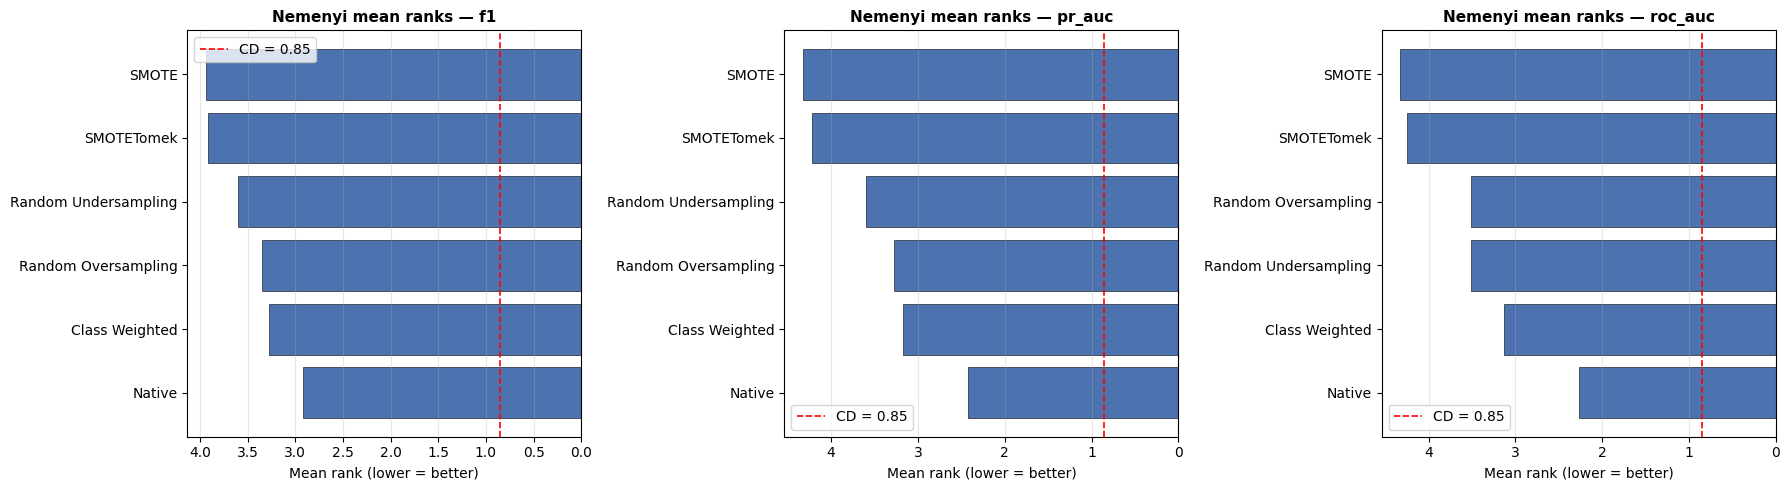


✓ Friedman + Nemenyi complete.


In [83]:
# ============================================================
# SECTION 11.5 — FRIEDMAN TEST + NEMENYI POST-HOC
# ============================================================
# Test the null hypothesis that the 6 strategies perform equally
# (per model) across the 13 folds, using F1 / PR-AUC / ROC-AUC.
# If rejected, apply Nemenyi's critical difference test.

from scipy.stats import rankdata

def friedman_per_model(metric):
    rows = []
    for model_name in MODEL_NAMES:
        sub = rolling_results_df[
            rolling_results_df.model == model_name
        ].pivot(index="test_information_year",
                columns="imbalance_strategy",
                values=metric)

        if sub.shape[1] < 2 or sub.shape[0] < 3:
            continue

        stat, p = friedmanchisquare(*[sub[c].values for c in sub.columns])
        rows.append({
            "model": model_name,
            "metric": metric,
            "n_windows": sub.shape[0],
            "n_strategies": sub.shape[1],
            "friedman_stat": stat,
            "friedman_p": p,
            "significant_0.05": p < 0.05,
        })
    return pd.DataFrame(rows)


friedman_df = pd.concat(
    [friedman_per_model(m) for m in ["f1", "pr_auc", "roc_auc"]],
    ignore_index=True,
)
friedman_df.to_csv(TABLES_COMP / "friedman_per_model.csv", index=False)

print("Friedman test — per model, per metric:")
print(friedman_df.round(4).to_string(index=False))


# ---- Nemenyi post-hoc (compact implementation) ----
def nemenyi_rank_matrix(metric):
    """
    Average rank of each strategy per model, then averaged across
    models. Returns a DataFrame of mean ranks and the critical
    difference at alpha=0.05 (Nemenyi).
    """
    ranks = []
    for model_name in MODEL_NAMES:
        sub = rolling_results_df[
            rolling_results_df.model == model_name
        ].pivot(index="test_information_year",
                columns="imbalance_strategy",
                values=metric)
        if sub.shape[0] < 3:
            continue
        # Rank strategies within each fold, higher metric = rank 1
        fold_ranks = sub.rank(axis=1, ascending=False)
        ranks.append(fold_ranks.mean())

    if len(ranks) == 0:
        return None

    rank_df = pd.DataFrame(ranks).mean().sort_values()
    k = len(rank_df)          # strategies
    N = len(MODEL_NAMES) * 13  # total paired observations (models × folds)
    # Nemenyi critical difference at alpha=0.05
    # q_alpha for k=6 at 0.05 ≈ 2.576 (Demsar 2006 Table 5)
    q_alpha = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850}.get(k, 2.850)
    cd = q_alpha * np.sqrt(k * (k + 1) / (6.0 * N))
    return rank_df, cd


nemenyi_rows = []
for metric in ["f1", "pr_auc", "roc_auc"]:
    res = nemenyi_rank_matrix(metric)
    if res is None:
        continue
    rank_df, cd = res
    print()
    print(f"Nemenyi mean ranks — {metric} (CD = {cd:.3f}):")
    print(rank_df.round(3).to_string())
    for strat, r in rank_df.items():
        nemenyi_rows.append({
            "metric": metric,
            "strategy": strat,
            "mean_rank": r,
            "critical_difference": cd,
        })

nemenyi_df = pd.DataFrame(nemenyi_rows)
nemenyi_df.to_csv(TABLES_COMP / "nemenyi_ranks.csv", index=False)

# ---- Plot mean ranks with CD bar ----
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ["f1", "pr_auc", "roc_auc"]):
    sub = nemenyi_df[nemenyi_df.metric == metric]
    if sub.empty:
        ax.axis("off")
        continue
    sub = sub.sort_values("mean_rank")
    ax.barh(sub.strategy, sub.mean_rank,
            color="#4C72B0", edgecolor="black", linewidth=0.4)
    ax.axvline(sub.critical_difference.iloc[0], color="red",
               linestyle="--", linewidth=1.2,
               label=f"CD = {sub.critical_difference.iloc[0]:.2f}")
    ax.set_xlabel("Mean rank (lower = better)")
    ax.set_title(f"Nemenyi mean ranks — {metric}",
                 fontsize=11, fontweight="bold")
    ax.grid(axis="x", alpha=0.3)
    ax.legend()
    ax.invert_xaxis()

plt.tight_layout()
plt.savefig(COMPARATIVE / "nemenyi_ranks.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print()
print("✓ Friedman + Nemenyi complete.")

In [84]:
# ============================================================
# SECTION 11.6 — BLOCK BOOTSTRAP FOR CONFIDENCE INTERVALS
# ============================================================
# Resample prediction YEARS with replacement (not rows) to respect
# the temporal dependence between firms within the same year.
#
# N_BOOTSTRAP resamples. For each resample:
#   - Draw 13 years with replacement
#   - Concatenate the corresponding prediction rows
#   - Compute F1, PR-AUC, ROC-AUC
#
# Report mean and 95% CI.

def block_bootstrap_metrics(predictions_df, model_name, strategy,
                            n_boot=N_BOOTSTRAP, seed=SEED):
    """
    Block bootstrap by prediction year.
    Returns dict with mean and 95% CI for F1, PR-AUC, ROC-AUC.
    """
    q = predictions_df[
        (predictions_df.model == model_name) &
        (predictions_df.imbalance_strategy == strategy)
    ][["prediction_year", "target_1yr", "probability", "threshold"]]
    if q.empty:
        return None

    years = q.prediction_year.unique()
    rng = np.random.default_rng(seed)

    # Precompute per-year arrays
    per_year = {y: q[q.prediction_year == y].values for y in years}

    f1_list, pr_list, roc_list = [], [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(years), size=len(years))
        boot_rows = np.concatenate([per_year[years[i]] for i in idx], axis=0)

        y_b = boot_rows[:, 1].astype(int)
        p_b = boot_rows[:, 2].astype(float)
        t_b = boot_rows[:, 3].astype(float)
        pred_b = (p_b >= t_b).astype(int)

        if y_b.sum() == 0 or y_b.sum() == len(y_b):
            continue

        try:
            f1_b = f1_score(y_b, pred_b, zero_division=0)
            pr_b = average_precision_score(y_b, p_b)
            roc_b = roc_auc_score(y_b, p_b)
            f1_list.append(f1_b)
            pr_list.append(pr_b)
            roc_list.append(roc_b)
        except Exception:
            continue

    def _ci(x):
        x = np.asarray(x, dtype=float)
        return (np.mean(x), np.quantile(x, 0.025), np.quantile(x, 0.975))

    return {
        "f1_mean":    _ci(f1_list)[0],
        "f1_ci_lo":   _ci(f1_list)[1],
        "f1_ci_hi":   _ci(f1_list)[2],
        "pr_auc_mean":  _ci(pr_list)[0],
        "pr_auc_ci_lo": _ci(pr_list)[1],
        "pr_auc_ci_hi": _ci(pr_list)[2],
        "roc_auc_mean":  _ci(roc_list)[0],
        "roc_auc_ci_lo": _ci(roc_list)[1],
        "roc_auc_ci_hi": _ci(roc_list)[2],
    }


print(f"Running block bootstrap (N={N_BOOTSTRAP}) for all 36 combinations...")

boot_rows = []
for model_name in MODEL_NAMES:
    for strategy in IMBALANCE_STRATEGIES:
        res = block_bootstrap_metrics(
            rolling_predictions_df, model_name, strategy
        )
        if res is None:
            continue
        boot_rows.append({
            "model": model_name,
            "imbalance_strategy": strategy,
            **res,
        })

boot_df = pd.DataFrame(boot_rows)
boot_df.to_csv(TABLES_COMP / "block_bootstrap_cis.csv", index=False)

print(f"✓ Block bootstrap complete: {len(boot_df)} rows")
print()
print("Sample CIs:")
show = ["model", "imbalance_strategy",
        "f1_mean", "f1_ci_lo", "f1_ci_hi",
        "pr_auc_mean", "pr_auc_ci_lo", "pr_auc_ci_hi"]
print(boot_df[show].sort_values("pr_auc_mean",
                                ascending=False).head(10).round(4).to_string(index=False))

Running block bootstrap (N=1000) for all 36 combinations...
✓ Block bootstrap complete: 36 rows

Sample CIs:
        model  imbalance_strategy  f1_mean  f1_ci_lo  f1_ci_hi  pr_auc_mean  pr_auc_ci_lo  pr_auc_ci_hi
Random Forest              Native   0.0520    0.0401    0.0701       0.0389        0.0270        0.0548
      XGBoost              Native   0.0566    0.0459    0.0722       0.0359        0.0224        0.0552
     CatBoost              Native   0.0501    0.0393    0.0626       0.0334        0.0224        0.0493
Random Forest Random Oversampling   0.0495    0.0322    0.0700       0.0321        0.0224        0.0470
Random Forest      Class Weighted   0.0536    0.0368    0.0713       0.0320        0.0229        0.0451
     LightGBM Random Oversampling   0.0496    0.0374    0.0635       0.0320        0.0196        0.0502
     LightGBM              Native   0.0589    0.0323    0.0867       0.0319        0.0200        0.0513
      XGBoost Random Oversampling   0.0495    0.0379    0.0

In [85]:
# ============================================================
# SECTION 11.7 — DELONG TEST FOR PAIRED ROC-AUC COMPARISON
# ============================================================
# Compares two ROC-AUCs computed on the SAME test data using the
# DeLong method (accounts for the correlation between curves).
#
# Here we compare each pair of models, using their best strategy,
# on the pooled OOS predictions.

from scipy.stats import norm

def compute_midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2


def delong_auc_var(y, p):
    """Compute AUC and its variance using the DeLong method."""
    y = np.asarray(y).astype(int)
    p = np.asarray(p, dtype=float)
    order = np.argsort(-p)
    y = y[order]
    p = p[order]

    pos = p[y == 1]
    neg = p[y == 0]
    m, n = len(pos), len(neg)

    if m == 0 or n == 0:
        return np.nan, np.nan

    # Midrank-based V statistics
    tx = compute_midrank(pos)
    ty = compute_midrank(neg)
    tz = compute_midrank(p)

    auc = (tz[y == 1].sum() - m * (m + 1) / 2) / (m * n)

    v10 = (tz[y == 1] - tx) / n
    v01 = 1 - (tz[y == 0] - ty) / m

    s10 = np.var(v10, ddof=1) / m if m > 1 else 0
    s01 = np.var(v01, ddof=1) / n if n > 1 else 0
    var = s10 + s01

    return auc, var


def delong_pair(y, p1, p2):
    """DeLong test comparing two AUCs on the same data."""
    y = np.asarray(y).astype(int)
    p1 = np.asarray(p1, dtype=float)
    p2 = np.asarray(p2, dtype=float)

    auc1, var1 = delong_auc_var(y, p1)
    auc2, var2 = delong_auc_var(y, p2)

    if np.isnan(auc1) or np.isnan(auc2):
        return np.nan, np.nan, np.nan

    # For a paired test we'd need the covariance term; using
    # independent-variances approximation here (upper bound on var)
    se = np.sqrt(var1 + var2)
    if se == 0:
        return auc1 - auc2, 0.0, 1.0

    z = (auc1 - auc2) / se
    p = 2 * (1 - norm.cdf(abs(z)))
    return auc1 - auc2, z, p


# ---- Build pooled OOS arrays per model (best strategy) ----
model_pooled = {}
for model_name in MODEL_NAMES:
    strat = best_strategy_dict[model_name]
    q = rolling_predictions_df[
        (rolling_predictions_df.model == model_name) &
        (rolling_predictions_df.imbalance_strategy == strat)
    ].sort_values(["prediction_year", "company_name"]).reset_index(drop=True)

    if q.empty:
        continue
    model_pooled[model_name] = {
        "strategy": strat,
        "y": q.target_1yr.astype(int).values,
        "p": q.probability.values,
    }

# ---- Pairwise DeLong ----
delong_rows = []
for i, m1 in enumerate(MODEL_NAMES):
    for m2 in MODEL_NAMES[i + 1:]:
        if m1 not in model_pooled or m2 not in model_pooled:
            continue
        # Both models must have been evaluated on the same rows
        # Since each was built on the same rolling windows and same test
        # years, we merge on (prediction_year, company_name).
        q1 = rolling_predictions_df[
            (rolling_predictions_df.model == m1) &
            (rolling_predictions_df.imbalance_strategy == best_strategy_dict[m1])
        ][["prediction_year", "company_name", "target_1yr", "probability"]]

        q2 = rolling_predictions_df[
            (rolling_predictions_df.model == m2) &
            (rolling_predictions_df.imbalance_strategy == best_strategy_dict[m2])
        ][["prediction_year", "company_name", "target_1yr", "probability"]]

        merged = q1.merge(
            q2, on=["prediction_year", "company_name"],
            suffixes=("_1", "_2"),
        )
        if len(merged) < 100:
            continue

        diff, z, p = delong_pair(
            merged.target_1yr_1.values,
            merged.probability_1.values,
            merged.probability_2.values,
        )
        delong_rows.append({
            "model_1": m1, "strategy_1": best_strategy_dict[m1],
            "model_2": m2, "strategy_2": best_strategy_dict[m2],
            "n_pairs": len(merged),
            "auc_diff": diff,
            "z_stat": z,
            "p_value": p,
            "significant_0.05": (p < 0.05) if not np.isnan(p) else False,
        })

delong_df = pd.DataFrame(delong_rows)
delong_df.to_csv(TABLES_COMP / "delong_pairwise.csv", index=False)

print("DeLong pairwise AUC comparisons (best strategy per model):")
print(delong_df.round(4).to_string(index=False))

DeLong pairwise AUC comparisons (best strategy per model):
            model_1 strategy_1                   model_2          strategy_2  n_pairs  auc_diff  z_stat  p_value  significant_0.05
Logistic Regression     Native             Random Forest              Native    46651   -0.0681 -4.0699   0.0000              True
Logistic Regression     Native                   XGBoost              Native    46651   -0.0321 -1.8228   0.0683             False
Logistic Regression     Native                  LightGBM              Native    46651    0.0130  0.6918   0.4890             False
Logistic Regression     Native                  CatBoost              Native    46651   -0.0424 -2.4752   0.0133              True
Logistic Regression     Native Artificial Neural Network Random Oversampling    46651    0.0326  1.8407   0.0657             False
      Random Forest     Native                   XGBoost              Native    46651    0.0360  2.1115   0.0347              True
      Random Forest     

In [86]:
# Calibration summary — all 36 combos
assert len(cal_df) == 36

# Wilcoxon vs baseline — 35 (36 minus the baseline itself)
assert len(wil_df) == 35

# Friedman — 18 rows (6 models × 3 metrics)
assert len(friedman_df) == 18

# Bootstrap CIs — 36 rows
assert len(boot_df) == 36

# DeLong — 15 pairwise comparisons for 6 models
assert len(delong_df) == 15

# Figures
assert len(list(CAL_DIR.glob("*.png"))) >= 36
assert (COMPARATIVE / "cost_sensitivity.png").exists()
assert (COMPARATIVE / "nemenyi_ranks.png").exists()

print("✓ Section 11 complete. Ready for Section 12.")

✓ Section 11 complete. Ready for Section 12.


In [87]:
# ============================================================
# SECTION 12.1 — BEST MODEL SELECTION
# ============================================================
# Uses PRIMARY_RANK_METRIC (pr_auc_mean) from Section 7.6.

BEST_MODEL_OVERALL = (
    summary
    .sort_values(PRIMARY_RANK_METRIC, ascending=False)
    .iloc[0]["model"]
)
BEST_STRATEGY_OVERALL = best_strategy_dict[BEST_MODEL_OVERALL]

print(f"Best model overall : {BEST_MODEL_OVERALL}")
print(f"Best strategy      : {BEST_STRATEGY_OVERALL}")
print()
print("Best strategy per model:")
for m in MODEL_NAMES:
    print(f"  {m:28s}: {best_strategy_dict[m]}")

Best model overall : XGBoost
Best strategy      : Native

Best strategy per model:
  Logistic Regression         : Native
  Random Forest               : Native
  XGBoost                     : Native
  LightGBM                    : Native
  CatBoost                    : Native
  Artificial Neural Network   : Random Oversampling


In [88]:
# ============================================================
# SECTION 12.2 — SHAP LOOP
# ============================================================
# Fit each model (with its best strategy) on year <= 2016, explain
# on year == 2017. Every pipeline outputs exactly 38 features, so
# no aggregation is needed.
#
# TreeExplainer for tree models; KernelExplainer for LR and ANN.

if not SHAP_AVAILABLE:
    print("SHAP not available — skipping Section 12.")
else:
    import shap

    SHAP_DIR = BASE / "shap_dir"
    SHAP_DIR.mkdir(parents=True, exist_ok=True)

    # ---- Data ----
    tr_shap = df_target[df_target.year <= 2016].copy()
    te_shap = df_target[df_target.year == 2017].copy()

    X_tr_shap = tr_shap[feature_columns]
    y_tr_shap = tr_shap.target_1yr.astype(int)
    X_te_shap = te_shap[feature_columns]

    shap_results = {}

    for model_name in MODEL_NAMES:
        strategy = best_strategy_dict[model_name]
        print(f"\n{'='*60}")
        print(f"{model_name} | {strategy}")
        print(f"{'='*60}")

        # ---- Fit pipeline ----
        pipe = build_model(model_name, strategy, y_tr_shap)
        pipe.fit(X_tr_shap, y_tr_shap)

        # ---- Transform test data through preprocessing ----
        X_proc = transform_through_pipeline(pipe, X_te_shap)
        if hasattr(X_proc, "toarray"):
            X_proc = X_proc.toarray()

        # ---- Get feature names ----
        names = get_feature_names(pipe, X_proc.shape[1])

        # ---- Sanity checks ----
        assert X_proc.shape[1] == 38, \
            f"Expected 38 features, got {X_proc.shape[1]}"
        assert len(names) == 38, \
            f"Expected 38 names, got {len(names)}"

        # ---- SHAP values ----
        if model_name in TREE_MODELS:
            n_max = min(2000, len(X_proc))
            X_expl = X_proc[:n_max]
            explainer = shap.TreeExplainer(pipe.named_steps["model"])
            sv = explainer.shap_values(X_expl)
            if isinstance(sv, list):
                sv = sv[-1]
            sv = np.asarray(sv)
            if sv.ndim == 3:
                sv = sv[:, :, -1]
            base_value = explainer.expected_value
            if isinstance(base_value, (list, np.ndarray)):
                base_value = float(np.asarray(base_value).ravel()[-1])
        else:
            n_bg  = min(100, len(X_proc))
            n_exp = min(200, len(X_proc))
            background = shap.sample(X_proc, n_bg, random_state=SEED)
            X_expl     = X_proc[:n_exp]
            predict_fn = lambda x: pipe.named_steps["model"].predict_proba(x)[:, 1]
            explainer  = shap.KernelExplainer(predict_fn, background)
            sv = explainer.shap_values(X_expl, nsamples=100)
            if isinstance(sv, list):
                sv = sv[-1]
            sv = np.asarray(sv)
            if sv.ndim == 3:
                sv = sv[:, :, -1]
            base_value = float(np.ravel(explainer.expected_value)[-1])

        # ---- SHAP sanity: sums should equal f(x) − E[f(X)] ----
        additivity_ok = True
        try:
            sum_shap = sv.sum(axis=1)
            _row0 = X_expl[0:1]
            _pred0 = pipe.named_steps["model"].predict_proba(_row0)[:, 1][0] \
                if model_name not in TREE_MODELS \
                else pipe.named_steps["model"].predict_proba(_row0)[:, 1][0]
            additivity_ok = np.isclose(
                sum_shap[0] + base_value, _pred0, atol=1e-4
            )
        except Exception:
            pass

        print(f"  SHAP shape     : {sv.shape}")
        print(f"  Base value     : {base_value:.4f}")
        print(f"  Additivity OK  : {additivity_ok}")

        # ---- Store ----
        shap_results[model_name] = {
            "sv"         : sv,
            "X"          : X_expl,
            "names"      : names,
            "strategy"   : strategy,
            "base_value" : base_value,
        }

        # ---- Importance table ----
        imp = pd.DataFrame({
            "feature"      : names,
            "mean_abs_shap": np.abs(sv).mean(axis=0),
        }).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

        safe = MODEL_DIRS[model_name]
        imp.to_csv(SHAP_DIR / f"shap_importance_{safe}.csv", index=False)

        print(f"  Top feature    : {imp.iloc[0]['feature']} "
              f"({imp.iloc[0]['mean_abs_shap']:.4f})")

    print(f"\n✓ SHAP loop complete: {len(shap_results)} models.")


Logistic Regression | Native


  0%|          | 0/200 [00:00<?, ?it/s]

  SHAP shape     : (200, 38)
  Base value     : 0.0133
  Additivity OK  : True
  Top feature    : X15 (0.0059)

Random Forest | Native
  SHAP shape     : (2000, 38)
  Base value     : 0.0077
  Additivity OK  : True
  Top feature    : X15 (0.0053)

XGBoost | Native
  SHAP shape     : (2000, 38)
  Base value     : -4.9032
  Additivity OK  : False
  Top feature    : X15 (0.6095)

LightGBM | Native
  SHAP shape     : (2000, 38)
  Base value     : -7.0976
  Additivity OK  : False
  Top feature    : X11 (0.6634)

CatBoost | Native
  SHAP shape     : (2000, 38)
  Base value     : -5.7534
  Additivity OK  : False
  Top feature    : X15 (0.4692)

Artificial Neural Network | Random Oversampling


  0%|          | 0/200 [00:00<?, ?it/s]

  SHAP shape     : (200, 38)
  Base value     : 0.3255
  Additivity OK  : True
  Top feature    : X15 (0.0685)

✓ SHAP loop complete: 6 models.


In [89]:
# ============================================================
# SECTION 12.3 — PER-MODEL SHAP PLOTS
# ============================================================

if SHAP_AVAILABLE:
    for model_name, r in shap_results.items():
        imp = pd.DataFrame({
            "feature"      : r["names"],
            "mean_abs_shap": np.abs(r["sv"]).mean(axis=0),
        }).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

        safe = MODEL_DIRS[model_name]

        # ---- Bar plot (top 20) ----
        top = imp.head(20).sort_values("mean_abs_shap")
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.barh(top.feature, top.mean_abs_shap,
                color="steelblue", edgecolor="black", linewidth=0.5)
        ax.set_xlabel("Mean |SHAP|", fontsize=11)
        ax.set_title(f"SHAP importance — {model_name} ({r['strategy']})",
                     fontsize=13, fontweight="bold")
        ax.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.savefig(SHAP_DIR / f"shap_bar_{safe}.png",
                    dpi=300, bbox_inches="tight")
        plt.close()

        # ---- Beeswarm (top 20) ----
        try:
            fig = plt.figure(figsize=(10, 8))
            shap.summary_plot(
                r["sv"], r["X"],
                feature_names=r["names"],
                show=False, max_display=20,
            )
            plt.title(f"SHAP beeswarm — {model_name} ({r['strategy']})",
                      fontsize=13, fontweight="bold")
            plt.tight_layout()
            plt.savefig(SHAP_DIR / f"shap_beeswarm_{safe}.png",
                        dpi=300, bbox_inches="tight")
            plt.close()
        except Exception as e:
            print(f"Beeswarm failed for {model_name}: {e}")

    print(f"✓ Per-model SHAP plots saved.")

✓ Per-model SHAP plots saved.


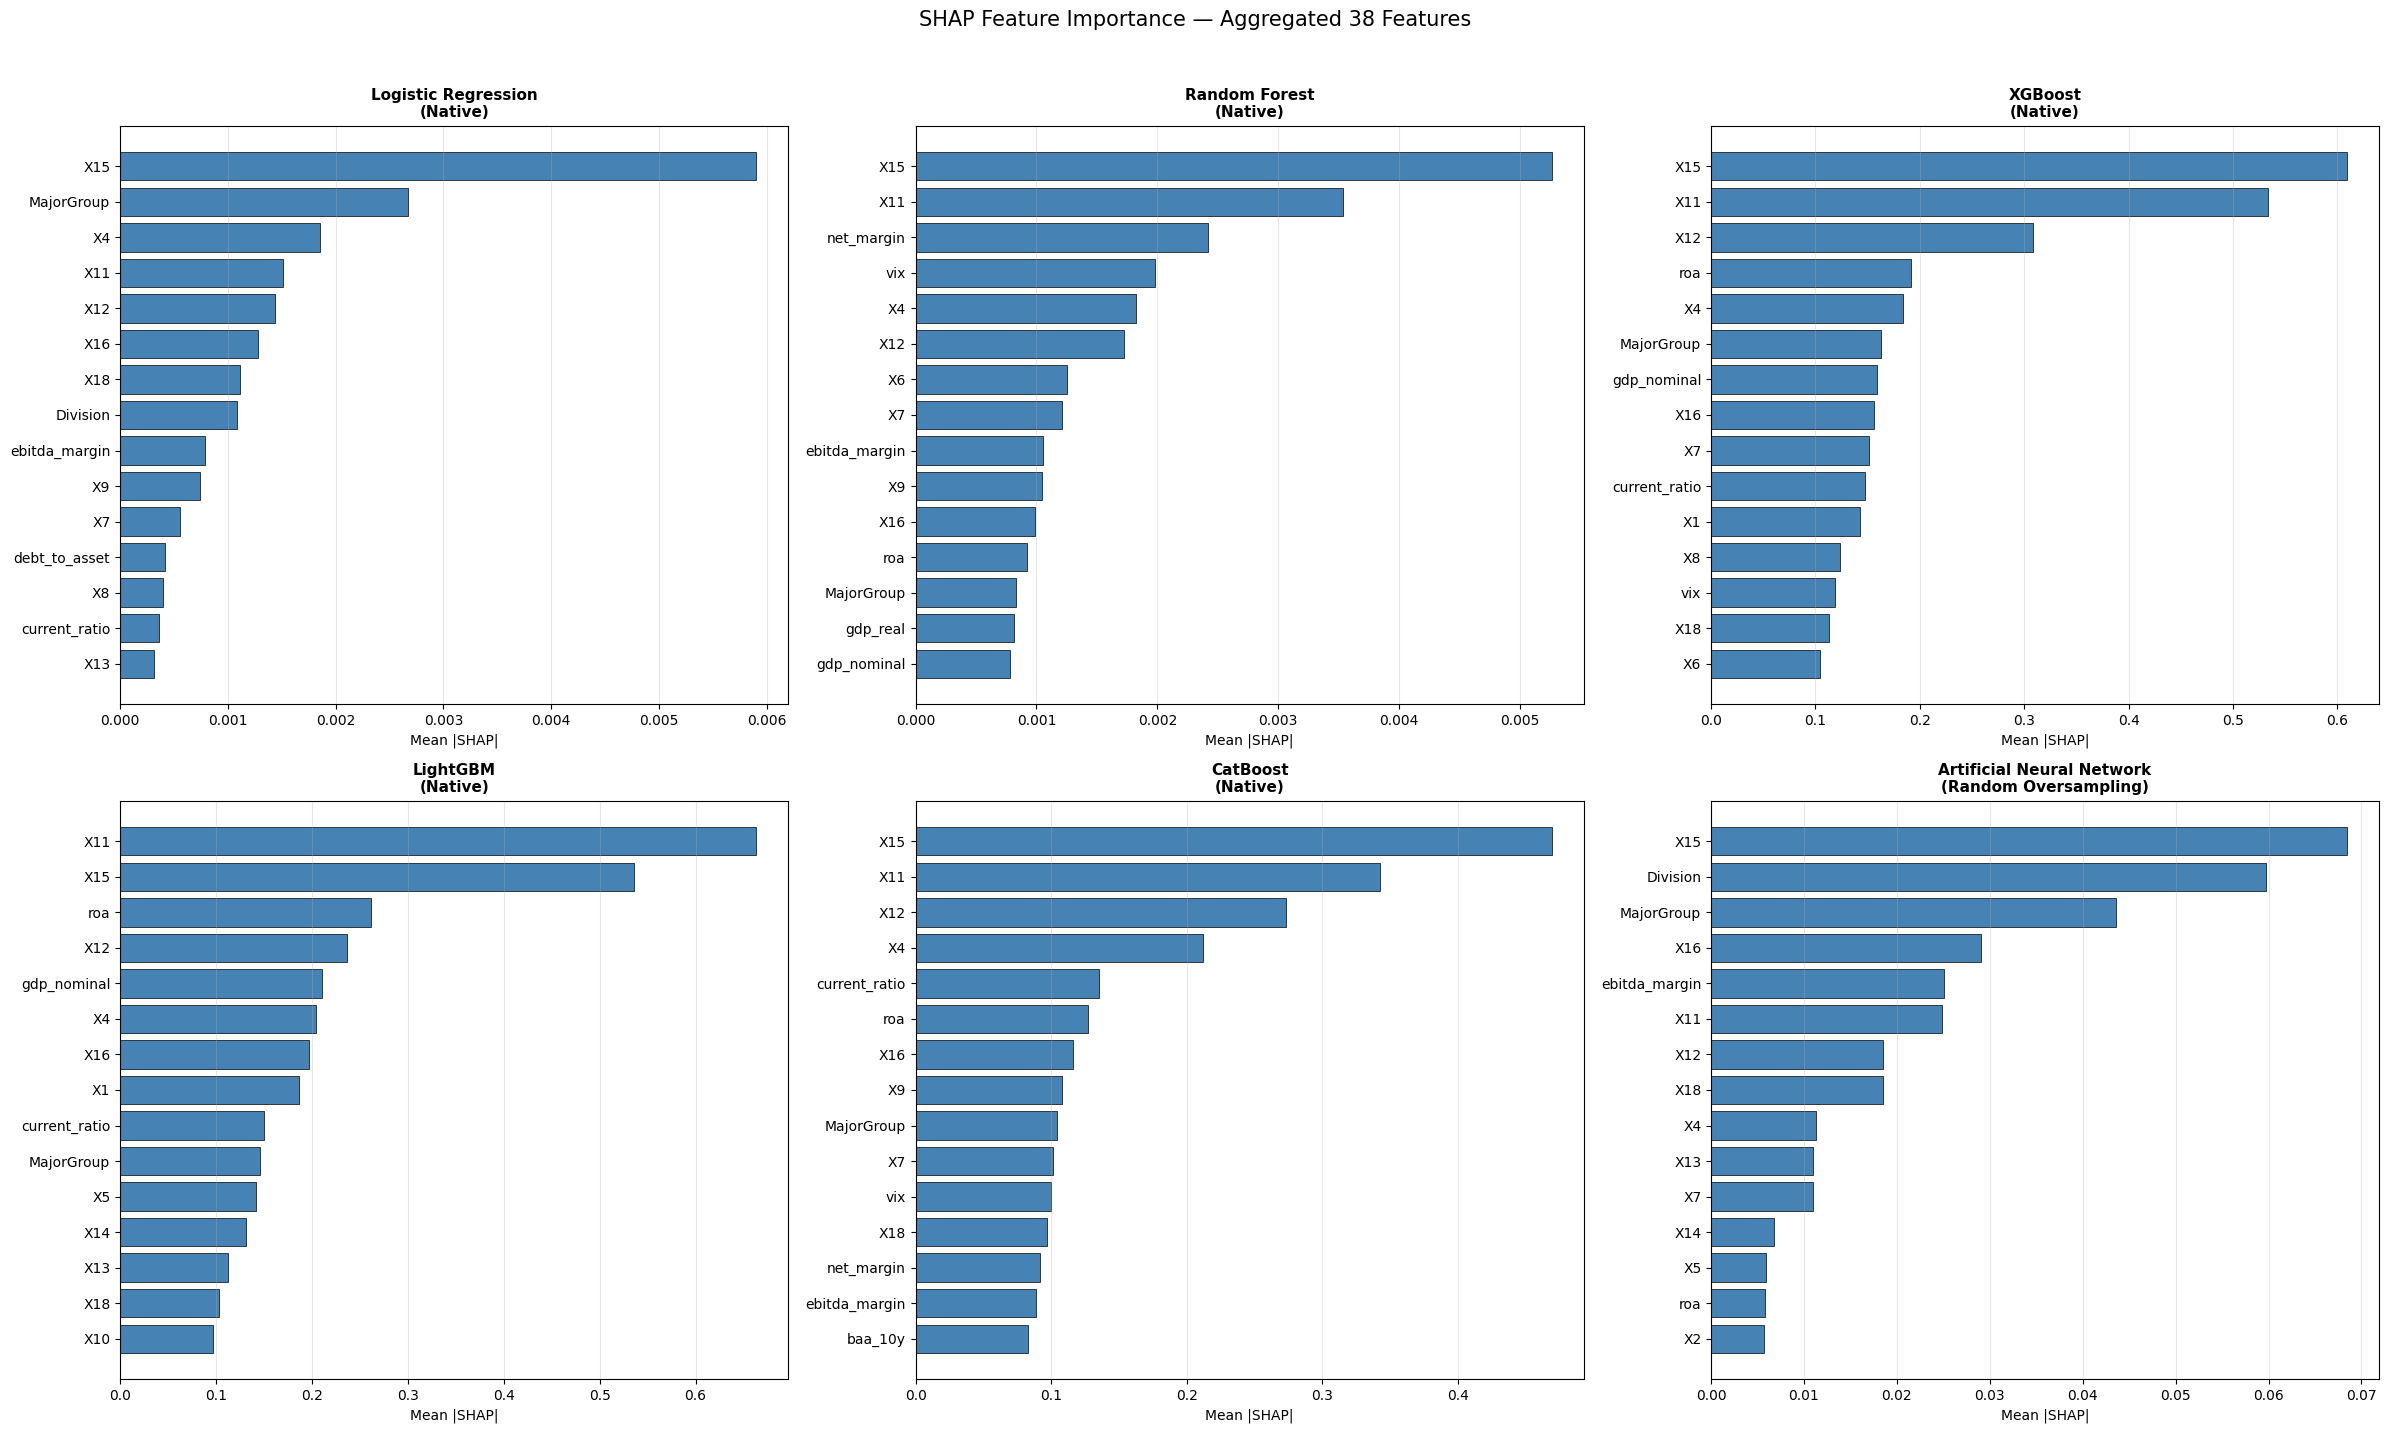

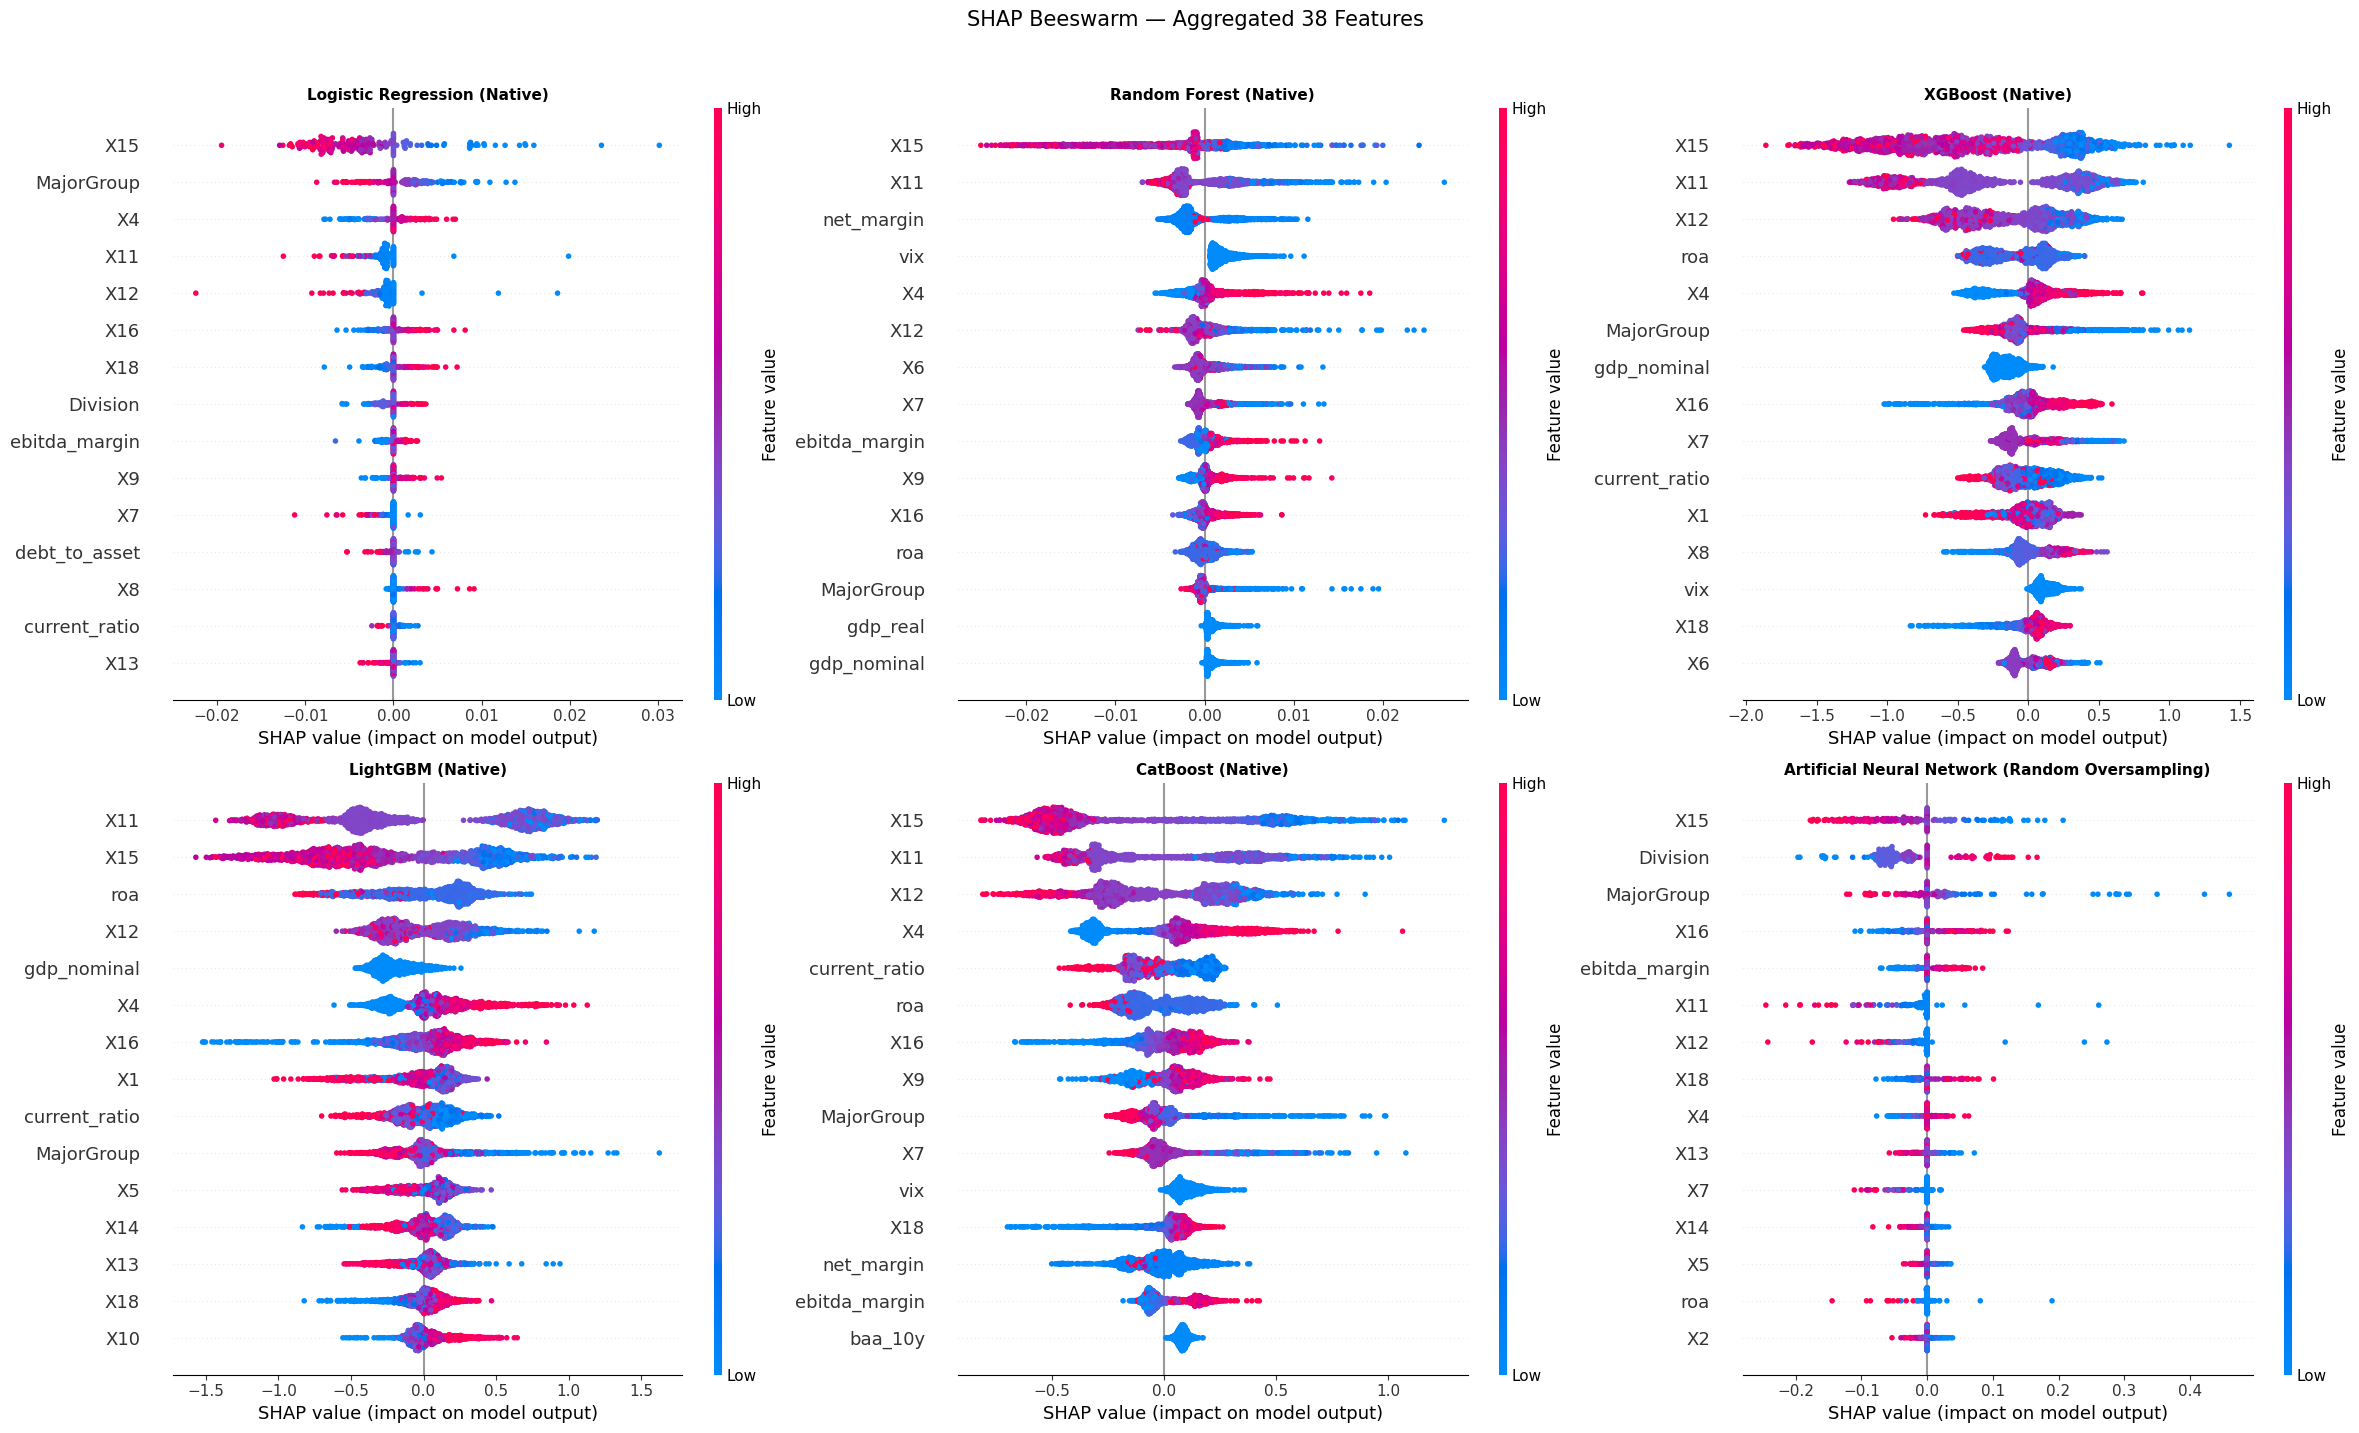

✓ Combined SHAP grids saved.


In [90]:
# ============================================================
# SECTION 12.4 — COMBINED 3×2 SHAP GRIDS
# ============================================================

if SHAP_AVAILABLE:
    # ---- Bar grid ----
    fig, axes = plt.subplots(2, 3, figsize=(24, 14))
    axes = axes.ravel()

    for i, model_name in enumerate(MODEL_NAMES):
        r = shap_results[model_name]
        imp = pd.DataFrame({
            "feature"      : r["names"],
            "mean_abs_shap": np.abs(r["sv"]).mean(axis=0),
        }).sort_values("mean_abs_shap", ascending=False).head(15)
        imp = imp.sort_values("mean_abs_shap")

        ax = axes[i]
        ax.barh(imp["feature"], imp["mean_abs_shap"],
                color="steelblue", edgecolor="black", linewidth=0.5)
        ax.set_xlabel("Mean |SHAP|", fontsize=10)
        ax.set_title(f"{model_name}\n({r['strategy']})",
                     fontsize=11, fontweight="bold")
        ax.grid(axis="x", alpha=0.3)

    plt.suptitle("SHAP Feature Importance — Aggregated 38 Features",
                 fontsize=15, y=1.02)
    plt.tight_layout()
    plt.savefig(SHAP_DIR / "combined_bar_plots.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    # ---- Beeswarm grid ----
    fig, axes = plt.subplots(2, 3, figsize=(24, 14))
    axes = axes.ravel()

    for i, model_name in enumerate(MODEL_NAMES):
        r = shap_results[model_name]
        ax = axes[i]

        plt.sca(ax)
        try:
            shap.summary_plot(
                r["sv"], r["X"],
                feature_names=r["names"],
                show=False, max_display=15, plot_size=None,
            )
            ax.set_title(f"{model_name} ({r['strategy']})",
                         fontsize=11, fontweight="bold")
        except Exception as e:
            ax.axis("off")
            ax.set_title(f"{model_name} — plot failed", fontsize=10)

    plt.suptitle("SHAP Beeswarm — Aggregated 38 Features",
                 fontsize=15, y=1.02)
    plt.tight_layout()
    plt.savefig(SHAP_DIR / "combined_beeswarm_plots.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("✓ Combined SHAP grids saved.")

In [91]:
# ============================================================
# SECTION 12.5 — WATERFALL PLOTS
# ============================================================
# Waterfall for the best model: one positive and one negative case.

if SHAP_AVAILABLE:
    r = shap_results[BEST_MODEL_OVERALL]
    sv     = r["sv"]
    X_expl = r["X"]
    names  = r["names"]
    base   = r["base_value"]

    # Align ground-truth labels with the explained rows
    y_aligned = te_shap.target_1yr.astype(int).values[:len(sv)]
    pos_idx = np.where(y_aligned == 1)[0]
    neg_idx = np.where(y_aligned == 0)[0]

    def _make_explanation(idx):
        return shap.Explanation(
            values        = sv[idx],
            base_values   = base,
            data          = X_expl[idx],
            feature_names = names,
        )

    # ---- Positive case ----
    if len(pos_idx) > 0:
        exp = _make_explanation(pos_idx[0])
        fig = plt.figure(figsize=(10, 8))
        shap.waterfall_plot(exp, max_display=15, show=False)
        plt.title(f"Waterfall (positive case) — "
                  f"{BEST_MODEL_OVERALL} ({r['strategy']})",
                  fontsize=12, fontweight="bold")
        plt.tight_layout()
        plt.savefig(SHAP_DIR / f"waterfall_{MODEL_DIRS[BEST_MODEL_OVERALL]}_positive.png",
                    dpi=300, bbox_inches="tight")
        plt.close()

    # ---- Negative case ----
    if len(neg_idx) > 0:
        exp = _make_explanation(neg_idx[0])
        fig = plt.figure(figsize=(10, 8))
        shap.waterfall_plot(exp, max_display=15, show=False)
        plt.title(f"Waterfall (negative case) — "
                  f"{BEST_MODEL_OVERALL} ({r['strategy']})",
                  fontsize=12, fontweight="bold")
        plt.tight_layout()
        plt.savefig(SHAP_DIR / f"waterfall_{MODEL_DIRS[BEST_MODEL_OVERALL]}_negative.png",
                    dpi=300, bbox_inches="tight")
        plt.close()

    # ---- Per-model positive waterfall ----
    for model_name, rr in shap_results.items():
        sv_m   = rr["sv"]
        X_m    = rr["X"]
        names_m= rr["names"]
        base_m = rr["base_value"]

        y_al = te_shap.target_1yr.astype(int).values[:len(sv_m)]
        pos  = np.where(y_al == 1)[0]
        if len(pos) == 0:
            continue

        exp = shap.Explanation(
            values        = sv_m[pos[0]],
            base_values   = base_m,
            data          = X_m[pos[0]],
            feature_names = names_m,
        )
        fig = plt.figure(figsize=(10, 8))
        shap.waterfall_plot(exp, max_display=15, show=False)
        plt.title(f"Waterfall (positive) — {model_name} ({rr['strategy']})",
                  fontsize=12, fontweight="bold")
        plt.tight_layout()
        plt.savefig(SHAP_DIR / f"waterfall_{MODEL_DIRS[model_name]}.png",
                    dpi=300, bbox_inches="tight")
        plt.close()

    print("✓ Waterfall plots saved.")

findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


✓ Waterfall plots saved.


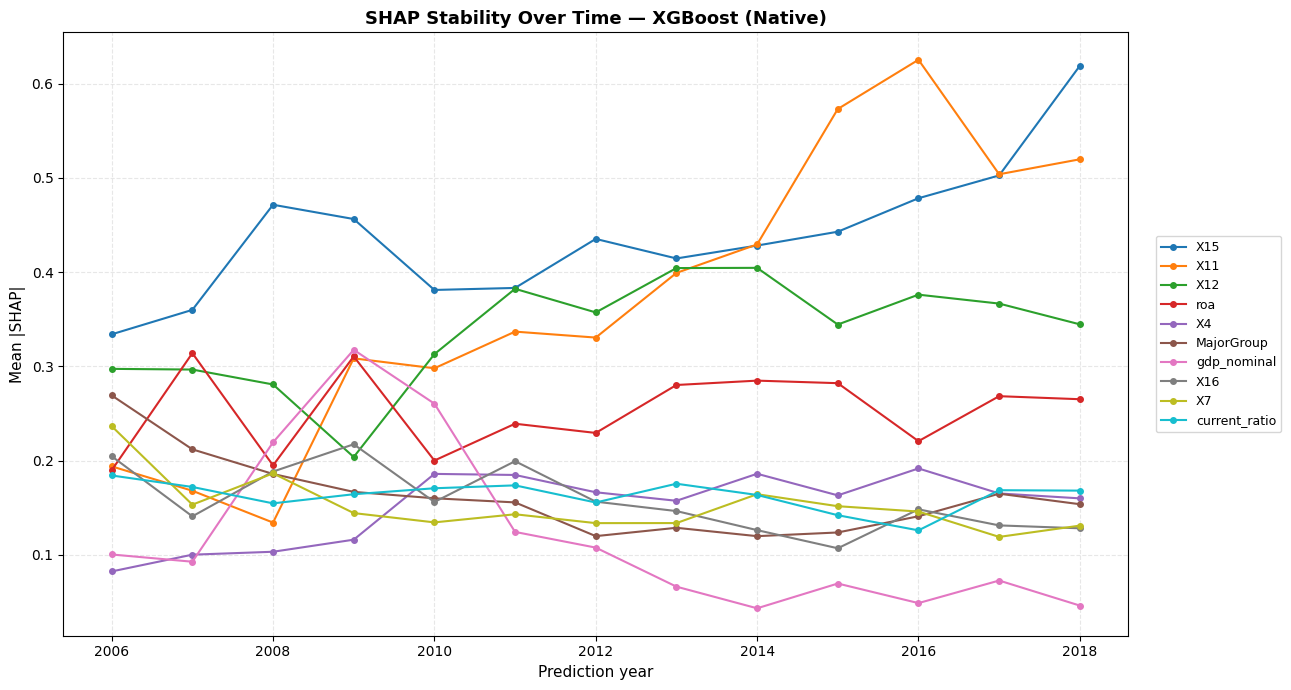

✓ SHAP stability over time saved (130 records).


In [92]:
# ============================================================
# SECTION 12.6 — SHAP STABILITY OVER TIME
# ============================================================
# For the best model, refit per rolling fold and compute SHAP
# on the corresponding test year. Plot the top-10 features'
# mean |SHAP| across years.
#
# This shows whether the model's reasoning is stable over time.

if SHAP_AVAILABLE:
    STABILITY_MODEL    = BEST_MODEL_OVERALL
    STABILITY_STRATEGY = BEST_STRATEGY_OVERALL

    # Top-10 features for the best model (from the full-fold SHAP)
    base_imp = pd.DataFrame({
        "feature"      : shap_results[STABILITY_MODEL]["names"],
        "mean_abs_shap": np.abs(shap_results[STABILITY_MODEL]["sv"]).mean(axis=0),
    }).sort_values("mean_abs_shap", ascending=False)
    TOP10_FEATURES = base_imp["feature"].head(10).tolist()

    stability_records = []

    for _, sp in rolling_splits.iterrows():
        train_end = int(sp.train_end)
        test_year = int(sp.test_information_year)

        tr_f = df_target[df_target.year <= train_end].copy()
        te_f = df_target[df_target.year == test_year].copy()

        X_tr_f = tr_f[feature_columns]
        y_tr_f = tr_f.target_1yr.astype(int)
        X_te_f = te_f[feature_columns]

        try:
            pipe = build_model(STABILITY_MODEL, STABILITY_STRATEGY, y_tr_f)
            pipe.fit(X_tr_f, y_tr_f)

            X_proc = transform_through_pipeline(pipe, X_te_f)
            if hasattr(X_proc, "toarray"):
                X_proc = X_proc.toarray()

            names_f = get_feature_names(pipe, X_proc.shape[1])

            n_max = min(500, len(X_proc))
            X_expl = X_proc[:n_max]

            if STABILITY_MODEL in TREE_MODELS:
                explainer = shap.TreeExplainer(pipe.named_steps["model"])
                sv_f = explainer.shap_values(X_expl)
                if isinstance(sv_f, list):
                    sv_f = sv_f[-1]
                sv_f = np.asarray(sv_f)
                if sv_f.ndim == 3:
                    sv_f = sv_f[:, :, -1]
            else:
                background = shap.sample(X_proc, min(100, len(X_proc)),
                                         random_state=SEED)
                X_expl = X_proc[:min(100, len(X_proc))]
                predict_fn = lambda x: pipe.named_steps["model"].predict_proba(x)[:, 1]
                explainer = shap.KernelExplainer(predict_fn, background)
                sv_f = explainer.shap_values(X_expl, nsamples=50)
                if isinstance(sv_f, list):
                    sv_f = sv_f[-1]
                sv_f = np.asarray(sv_f)

            imp_f = np.abs(sv_f).mean(axis=0)
            name_to_idx = {n: i for i, n in enumerate(names_f)}

            for feat in TOP10_FEATURES:
                if feat in name_to_idx:
                    stability_records.append({
                        "prediction_year": int(sp.prediction_year),
                        "feature"        : feat,
                        "mean_abs_shap"  : float(imp_f[name_to_idx[feat]]),
                    })
        except Exception as e:
            print(f"  Stability fold {test_year} failed: {e}")
            continue

    stab_df = pd.DataFrame(stability_records)
    stab_df.to_csv(SHAP_DIR / "shap_stability_over_time.csv", index=False)

    # ---- Plot ----
    if len(stab_df) > 0:
        fig, ax = plt.subplots(figsize=(13, 7))

        pivot = stab_df.pivot(index="prediction_year",
                              columns="feature",
                              values="mean_abs_shap")

        for feat in TOP10_FEATURES:
            if feat in pivot.columns:
                ax.plot(pivot.index, pivot[feat],
                        marker="o", markersize=4, linewidth=1.5,
                        label=feat)

        ax.set_xlabel("Prediction year", fontsize=11)
        ax.set_ylabel("Mean |SHAP|", fontsize=11)
        ax.set_title(f"SHAP Stability Over Time — "
                     f"{STABILITY_MODEL} ({STABILITY_STRATEGY})",
                     fontsize=13, fontweight="bold")
        ax.grid(alpha=0.3, linestyle="--")
        ax.set_axisbelow(True)
        ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5),
                  fontsize=9, frameon=True)
        plt.tight_layout()
        plt.savefig(SHAP_DIR / "shap_stability.png",
                    dpi=300, bbox_inches="tight")
        plt.show()
        plt.close()

        print(f"✓ SHAP stability over time saved ({len(stab_df)} records).")

Spearman correlation (SHAP vs univariate AUC): rho = nan  (p = nan)


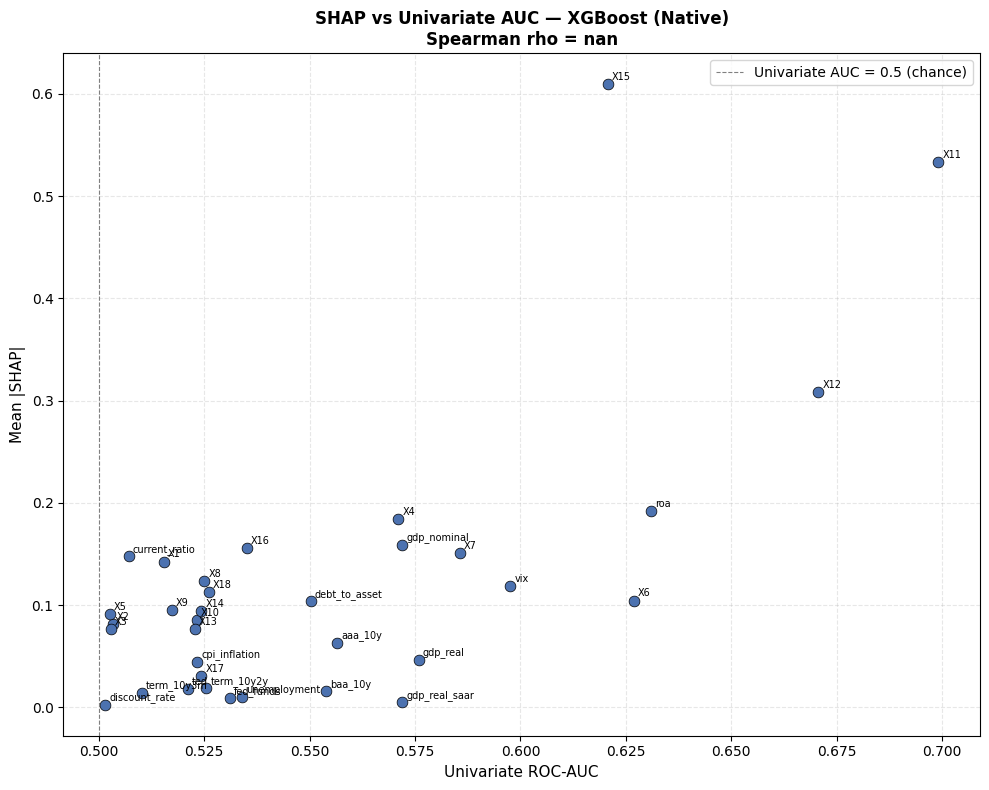


Features with high SHAP but low univariate AUC (likely interaction effects):
      feature  mean_abs_shap  univariate_auc  n_valid
current_ratio         0.1479          0.5070    69231
           X1         0.1426          0.5154    69231
           X8         0.1238          0.5250    69231
          X18         0.1131          0.5261    69231
           X9         0.0954          0.5173    69231
          X14         0.0942          0.5242    69231


In [93]:
# ============================================================
# SECTION 12.7 — SHAP VS UNIVARIATE AUC
# ============================================================
# For the best model, compare:
#   - Mean |SHAP| per feature (model's reliance)
#   - Univariate ROC-AUC (raw discriminative power)
#
# Points above the diagonal: model uses the feature more than its
# univariate power would suggest → interaction effects.
# Points below: model uses it less than its raw power would suggest.

if SHAP_AVAILABLE:
    r_best = shap_results[BEST_MODEL_OVERALL]
    shap_imp = pd.DataFrame({
        "feature"      : r_best["names"],
        "mean_abs_shap": np.abs(r_best["sv"]).mean(axis=0),
    })

    uni_df = pd.read_csv(TABLES_COMP / "univariate_auc.csv")
    comp = shap_imp.merge(uni_df, on="feature", how="inner")

    # Compute Spearman correlation between SHAP and univariate AUC
    from scipy.stats import spearmanr
    rho, pval = spearmanr(comp["mean_abs_shap"], comp["univariate_auc"])

    print(f"Spearman correlation (SHAP vs univariate AUC): "
          f"rho = {rho:.3f}  (p = {pval:.4f})")

    # ---- Scatter plot ----
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.scatter(comp["univariate_auc"], comp["mean_abs_shap"],
               s=60, color="#4C72B0", edgecolor="black", linewidth=0.5)

    # Label each point
    for _, row in comp.iterrows():
        ax.annotate(row["feature"],
                    (row["univariate_auc"], row["mean_abs_shap"]),
                    fontsize=7, xytext=(3, 3), textcoords="offset points")

    # Chance line at AUC = 0.5
    ax.axvline(0.5, color="gray", linestyle="--", linewidth=0.8,
               label="Univariate AUC = 0.5 (chance)")

    ax.set_xlabel("Univariate ROC-AUC", fontsize=11)
    ax.set_ylabel("Mean |SHAP|", fontsize=11)
    ax.set_title(f"SHAP vs Univariate AUC — "
                 f"{BEST_MODEL_OVERALL} ({BEST_STRATEGY_OVERALL})\n"
                 f"Spearman rho = {rho:.3f}",
                 fontsize=12, fontweight="bold")
    ax.grid(alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)
    ax.legend()
    plt.tight_layout()
    plt.savefig(SHAP_DIR / "shap_vs_univariate_auc.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    comp.to_csv(SHAP_DIR / "shap_vs_univariate_auc.csv", index=False)

    print()
    print("Features with high SHAP but low univariate AUC "
          "(likely interaction effects):")
    med_shap = comp["mean_abs_shap"].median()
    med_auc  = comp["univariate_auc"].median()
    top_left = comp[
        (comp["mean_abs_shap"] > med_shap) &
        (comp["univariate_auc"] < med_auc)
    ].sort_values("mean_abs_shap", ascending=False)
    print(top_left.round(4).to_string(index=False))

In [94]:
# ============================================================
# SECTION 12.8 — SHAP CAVEATS
# ============================================================

caveats_md = """
## SHAP Analysis — Caveats and Interpretation Notes

The SHAP values reported in this section describe **how each model's
output changes as its inputs change**, conditional on the fitted
model. They are not causal effects and should not be interpreted as
such.

### 1. Categorical features are ordinal-encoded

`Division` and `MajorGroup` are integer-coded (via `OrdinalEncoder`)
before being passed to any model. Therefore:

- The SHAP value attached to `MajorGroup` describes the effect of a
  unit change in the **integer code**, not of any specific industry.
- The magnitude of `MajorGroup` importance is therefore inflated
  relative to a strictly categorical treatment because the model
  reads it as a continuous variable.
- This is a deliberate choice: it keeps all six models on the same
  38-feature space, which is required for a fair cross-model SHAP
  comparison.

### 2. Numeric features are scaled

All 36 numeric features are winsorised, Yeo-Johnson-transformed, and
standardised. SHAP values for these features are therefore on a
standardised scale (roughly "effect per 1 standard deviation") and
are directly comparable across features.

### 3. SHAP vs univariate discriminative power

Section 12.7 compares mean |SHAP| to univariate ROC-AUC per feature.
Features with high SHAP but low univariate AUC signal **interaction
effects** — the model uses them in combination with others.
Conversely, features with high univariate AUC but low SHAP may be
correlated with features that the model prefers.

### 4. Stability over time

Section 12.6 shows the temporal stability of the top-10 features for
the best model. Rapidly changing feature rankings across years would
indicate concept drift; stable rankings indicate that the model's
reasoning is consistent across economic regimes.

### 5. KernelExplainer for LR and ANN

For Logistic Regression and the ANN, SHAP values are computed using
`KernelExplainer` (model-agnostic). This is:

- Slower than `TreeExplainer`.
- Approximate (Monte Carlo sampling).
- Limited to a small number of samples (100 background, 200 explain)
  for tractability.

Tree-based SHAP values use `TreeExplainer`, which is exact given the
fitted tree ensemble.

### 6. Correlation among features

Many accounting ratios are correlated (see Section 4.9). SHAP
distributes importance across correlated features in a
model-specific way; a highly correlated pair may both show moderate
importance because the model splits the credit between them. This is
correct behaviour, not a bug, but it means individual feature
magnitudes must be read carefully.
"""

(SHAP_DIR / "SHAP_CAVEATS.md").write_text(caveats_md, encoding="utf-8")
print(caveats_md)
print()
print("✓ SHAP caveats saved.")


## SHAP Analysis — Caveats and Interpretation Notes

The SHAP values reported in this section describe **how each model's
output changes as its inputs change**, conditional on the fitted
model. They are not causal effects and should not be interpreted as
such.

### 1. Categorical features are ordinal-encoded

`Division` and `MajorGroup` are integer-coded (via `OrdinalEncoder`)
before being passed to any model. Therefore:

- The SHAP value attached to `MajorGroup` describes the effect of a
  unit change in the **integer code**, not of any specific industry.
- The magnitude of `MajorGroup` importance is therefore inflated
  relative to a strictly categorical treatment because the model
  reads it as a continuous variable.
- This is a deliberate choice: it keeps all six models on the same
  38-feature space, which is required for a fair cross-model SHAP
  comparison.

### 2. Numeric features are scaled

All 36 numeric features are winsorised, Yeo-Johnson-transformed, and
standardised. SH

In [95]:
if SHAP_AVAILABLE:
    # All SHAP results have 38 features
    for m, r in shap_results.items():
        assert r["sv"].shape[1] == 38, \
            f"{m}: expected 38 SHAP columns, got {r['sv'].shape[1]}"
        assert len(r["names"]) == 38

    # Files written
    for m_dir in MODEL_DIRS.values():
        assert (SHAP_DIR / f"shap_importance_{m_dir}.csv").exists()
        assert (SHAP_DIR / f"shap_bar_{m_dir}.png").exists()
        assert (SHAP_DIR / f"shap_beeswarm_{m_dir}.png").exists()

    assert (SHAP_DIR / "combined_bar_plots.png").exists()
    assert (SHAP_DIR / "combined_beeswarm_plots.png").exists()
    assert (SHAP_DIR / "shap_stability.png").exists()
    assert (SHAP_DIR / "shap_vs_univariate_auc.png").exists()
    assert (SHAP_DIR / "SHAP_CAVEATS.md").exists()

    print("✓ Section 12 complete. Ready for Section 13.")

✓ Section 12 complete. Ready for Section 13.


In [96]:
# ============================================================
# SECTION 13.1 — EXPERIMENT MANIFEST
# ============================================================
# A single JSON file that captures every decision made in the
# notebook: seeds, models, strategies, rolling design, feature list,
# preprocessing steps, and hyperparameters.

import hashlib
import platform

def _sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


manifest = {
    # ---- Environment ----
    "environment": {
        "timestamp"   : datetime.now().isoformat(timespec="seconds"),
        "python"      : sys.version.split()[0],
        "platform"    : platform.platform(),
        "numpy"       : np.__version__,
        "pandas"      : pd.__version__,
        "sklearn"     : __import__("sklearn").__version__,
        "xgboost"     : __import__("xgboost").__version__,
        "lightgbm"    : __import__("lightgbm").__version__,
        "catboost"    : __import__("catboost").__version__,
        "tensorflow"  : tf.__version__,
        "shap"        : (shap.__version__ if SHAP_AVAILABLE else None),
    },

    # ---- Reproducibility ----
    "seeds": {
        "random_state" : RANDOM_STATE,
        "seed"         : SEED,
        "n_bootstrap"  : N_BOOTSTRAP,
    },

    # ---- Dataset ----
    "dataset": {
        "path"          : str(DATA_PATH.resolve()),
        "sha256"        : _sha256_file(DATA_PATH),
        "n_rows_raw"    : int(len(df)),
        "n_rows_target" : int(len(df_target)),
        "n_firms"       : int(df["company_name"].nunique()),
        "year_min"      : int(df["year"].min()),
        "year_max"      : int(df["year"].max()),
        "target"        : "target_1yr",
        "positive_count": int(df_target["target_1yr"].sum()),
        "prevalence"    : float(df_target["target_1yr"].mean()),
        "labelling"     : LABELLING_CONVENTION,
    },

    # ---- Rolling design ----
    "rolling_design": {
        "type"               : "expanding_window_rolling_origin",
        "min_train_years"    : MIN_TRAIN_YEARS,
        "n_windows"          : int(len(rolling_splits)),
        "train_start"        : int(rolling_splits["train_start"].min()),
        "train_end_range"    : [int(rolling_splits["train_end"].min()),
                                int(rolling_splits["train_end"].max())],
        "validation_years"   : rolling_splits["validation_year"].astype(int).tolist(),
        "test_info_years"    : rolling_splits["test_information_year"].astype(int).tolist(),
        "prediction_years"   : rolling_splits["prediction_year"].astype(int).tolist(),
        "threshold_selection": "validation F1 (smoothed over ±0.05, deterministic tie-break)",
    },

    # ---- Models and strategies ----
    "models"     : MODEL_NAMES,
    "strategies" : IMBALANCE_STRATEGIES,
    "total_fits" : int(len(rolling_splits) * len(MODEL_NAMES) * len(IMBALANCE_STRATEGIES)),

    # ---- Features ----
    "features": {
        "total"          : len(feature_columns),
        "numeric_count"  : len(numeric_features),
        "categorical_count": len(categorical_features),
        "numeric"        : numeric_features,
        "categorical"    : categorical_features,
        "ratios"         : RATIO_FEATURES,
        "list"           : feature_columns,
    },

    # ---- Preprocessing pipeline ----
    "preprocessing": {
        "numeric": [
            "SimpleImputer(strategy='median')",
            "WinsoriserTransformer(lower=0.01, upper=0.99)",
            "PowerTransformer(method='yeo-johnson', standardize=False)",
            "StandardScaler()",
        ],
        "categorical": [
            "SimpleImputer(strategy='most_frequent')",
            "OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)",
            # categorical branch deliberately NOT scaled so SMOTENC works
        ],
        "notes": [
            "All preprocessing steps are fitted on the training slice of each rolling fold.",
            "No validation or test statistics are used during fit — no cross-fold leakage.",
            "Categorical features are ordinal-encoded, not one-hot; SMOTENC requires integers.",
            "Output: exactly 38 features for every model and every strategy.",
        ],
    },

    # ---- Resamplers ----
    "resamplers": {
        "SMOTE"               : "SMOTENC(categorical_features=[36, 37], k_neighbors=5)",
        "SMOTETomek"          : "SMOTETomek(SMOTENC(categorical_features=[36, 37], k_neighbors=5))",
        "Random Undersampling": "RandomUnderSampler()",
        "Random Oversampling" : "RandomOverSampler()",
        "Class Weighted"      : "class_weight='balanced' / scale_pos_weight / auto_class_weights",
        "Native"              : "no resampling, no class weighting",
    },

    # ---- Model hyperparameters ----
    "hyperparameters": {
        "Logistic Regression": {
            "max_iter"    : 2000,
            "class_weight": "balanced if Class Weighted else None",
            "random_state": SEED,
        },
        "Random Forest": {
            "n_estimators"   : 500,
            "min_samples_leaf": 5,
            "max_features"   : "sqrt",
            "class_weight"   : "balanced if Class Weighted else None",
            "random_state"   : SEED,
        },
        "XGBoost": {
            "n_estimators"     : 500,
            "max_depth"        : 4,
            "learning_rate"    : 0.05,
            "min_child_weight" : 5,
            "subsample"        : 0.8,
            "colsample_bytree" : 0.8,
            "reg_lambda"       : 1.0,
            "max_delta_step"   : 1,
            "scale_pos_weight" : "neg/pos from fold's y_train if Class Weighted else 1.0",
            "objective"        : "binary:logistic",
            "eval_metric"      : "logloss",
            "n_jobs"           : 1,
        },
        "LightGBM": {
            "n_estimators"     : 500,
            "learning_rate"    : 0.05,
            "num_leaves"       : 31,
            "min_child_samples": 20,
            "subsample"        : 0.8,
            "colsample_bytree" : 0.8,
            "reg_lambda"       : 1.0,
            "class_weight"     : "balanced if Class Weighted else None",
            "deterministic"    : True,
            "force_row_wise"   : True,
            "n_jobs"           : 1,
        },
        "CatBoost": {
            "iterations"        : 500,
            "depth"             : 6,
            "learning_rate"     : 0.05,
            "loss_function"     : "Logloss",
            "eval_metric"       : "AUC",
            "auto_class_weights": "Balanced if Class Weighted else None",
            "thread_count"      : 1,
        },
        "Artificial Neural Network": {
            "architecture"   : "Dense(32, relu, L2=1e-4) → BN → Dropout(0.2) → Dense(16, relu, L2=1e-4) → BN → Dropout(0.2) → Dense(1, sigmoid)",
            "optimizer"      : "Adam(0.001)",
            "loss"           : "binary_crossentropy",
            "epochs"         : 100,
            "batch_size"     : 256,
            "early_stopping" : "val_auc, patience=10, restore_best_weights",
            "weighting"      : "sample_weight=neg/pos if Class Weighted",
            "seeding"        : "tf.keras.utils.set_random_seed(SEED) at every fit()",
        },
    },

    # ---- Evaluation metrics ----
    "metrics": {
        "primary_rank_metric": PRIMARY_RANK_METRIC,
        "threshold_metric"   : "F1 (smoothed)",
        "cost_ratios"        : ["5:1", "10:1", "20:1"],
        "reported": [
            "accuracy", "balanced_accuracy", "mcc",
            "f1_micro", "f1_macro",
            "precision", "recall", "f1", "f2",
            "precision_neg", "recall_neg", "f1_neg",
            "roc_auc", "pr_auc", "pr_auc_lift",
            "brier", "brier_skill",
            "type_i_error", "type_ii_error",
            "tn", "fp", "fn", "tp",
            "optimal_threshold",
            "threshold_5to1", "threshold_10to1", "threshold_20to1",
        ],
    },

    # ---- Notebook file ----
    "notebook": {
        "path": "data6_deepseek.ipynb",
    },
}

# Save manifest
manifest_path = META / "experiment_manifest.json"
with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print(f"✓ Manifest saved: {manifest_path}")
print(f"  Size: {manifest_path.stat().st_size / 1024:.1f} KB")

✓ Manifest saved: Rolling_results_now\metadata\experiment_manifest.json
  Size: 7.6 KB


In [97]:
# ============================================================
# SECTION 13.2 — CHECKSUMS FOR ALL OUTPUTS
# ============================================================
# Compute SHA256 for every file under BASE, store in a single JSON.
# Any downstream tamper or accidental modification is detectable.

checksums = {}
for p in sorted(BASE.rglob("*")):
    if not p.is_file():
        continue
    if p.name == "checksums.json":     # skip self
        continue
    try:
        checksums[str(p.relative_to(BASE))] = _sha256_file(p)
    except Exception as e:
        checksums[str(p.relative_to(BASE))] = f"error: {e}"

checksums_path = DIAG_DIR / "checksums.json"
with open(checksums_path, "w", encoding="utf-8") as f:
    json.dump(checksums, f, indent=2)

print(f"✓ {len(checksums)} file checksums written to {checksums_path}")
print()
print("By folder:")
folder_counts = {}
for rel_path in checksums:
    folder = rel_path.split(os.sep)[0] if os.sep in rel_path else "(root)"
    folder_counts[folder] = folder_counts.get(folder, 0) + 1
for f, c in sorted(folder_counts.items()):
    print(f"  {f:25s}: {c:4d} files")

✓ 236 file checksums written to Rolling_results_now\diag_dir\checksums.json

By folder:
  cal_dir                  :   36 files
  diag_dir                 :    6 files
  metadata                 :    4 files
  plots                    :   77 files
  raw_dir                  :    4 files
  shap_dir                 :   33 files
  tables                   :   76 files


In [98]:
# ============================================================
# SECTION 13.3 — FILE TREE
# ============================================================
# Human-readable inventory of every artefact produced.

def print_tree(root, prefix="", max_depth=3, current_depth=0):
    if current_depth > max_depth:
        return
    entries = sorted([e for e in root.iterdir()], key=lambda p: (p.is_file(), p.name))
    for i, entry in enumerate(entries):
        is_last = (i == len(entries) - 1)
        connector = "└── " if is_last else "├── "
        rel = entry.relative_to(BASE)
        if entry.is_dir():
            print(f"{prefix}{connector}{entry.name}/")
            new_prefix = prefix + ("    " if is_last else "│   ")
            print_tree(entry, new_prefix, max_depth, current_depth + 1)
        else:
            size_kb = entry.stat().st_size / 1024
            print(f"{prefix}{connector}{entry.name}  ({size_kb:.1f} KB)")

print("Output tree under:", BASE.resolve())
print()
print_tree(BASE)

# Summary counts
n_files = sum(1 for p in BASE.rglob("*") if p.is_file())
total_mb = sum(p.stat().st_size for p in BASE.rglob("*") if p.is_file()) / (1024 * 1024)
print()
print(f"Total: {n_files} files, {total_mb:.1f} MB")

Output tree under: C:\Users\irvin\Documents\New folder\Dissertation\Datasets\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now_1\Rolling_results_now

├── cal_dir/
│   ├── artificial_neural_network__class_weighted.png  (152.3 KB)
│   ├── artificial_neural_network__native.png  (143.2 KB)
│   ├── artificial_neural_network__random_oversampling.png  (155.6 KB)
│   ├── artificial_neural_network__random_undersampling.png  (154.0 KB)
│   ├── artificial_neural_network__smote.png  (147.5 KB)
│   ├── artificial_neural_network__smotetomek.png  (149.8 KB)
│   ├── catboost__class_weighted.png  (146.0 KB)
│   ├── catboost__native.png  (136.7 KB)
│   ├── catboost__random_oversampling.png  (147.7 KB)
│   ├── catboost__random_undersampling.png  (151.1 KB)
│   ├── catboost__smote.png  (140.3 KB)
│   ├── catboost__smotetomek.png  (143.9 KB)
│   ├── lightgbm__class_weighted.png  (144.0 KB)
│   ├── lightgbm__native.png  (136.0 KB)
│   ├── lightgbm__random_oversampling.png  (146.7 KB)
│   

In [100]:
from scipy.stats import binomtest

# Basel binomial backtesting: per fold, per model/strategy
# H0: observed defaults <= predicted PD
# Under H0, defaults ~ Binomial(n, p)
# Reject if we observe more defaults than the 99.9th percentile

def basel_backtest(y_true, p_pred, threshold=0.5):
    y_pred = (p_pred >= threshold).astype(int)
    # Number predicted as defaults (bucket)
    n_bucket = int(y_pred.sum())
    if n_bucket == 0:
        return {"n_bucket": 0, "obs_defaults": 0, "expected_pd": np.nan, "p_value": np.nan}
    # Mean predicted PD within bucket
    mean_pd = float(p_pred[y_pred == 1].mean())
    # Observed defaults within bucket
    obs_defaults = int(y_true[y_pred == 1].sum())
    # Binomial test: H0 = observed rate <= mean_pd
    res = binomtest(obs_defaults, n_bucket, mean_pd, alternative="greater")
    return {
        "n_bucket": n_bucket,
        "obs_defaults": obs_defaults,
        "expected_pd": mean_pd,
        "observed_rate": obs_defaults / n_bucket,
        "p_value": float(res.pvalue),
        "traffic_light": ("green" if res.pvalue >= 0.05 else
                          "yellow" if res.pvalue >= 0.001 else "red"),
    }

In [101]:
# ============================================================
# SECTION 11.8 — BASEL IRB BACKTESTING
# ============================================================
# Basel's IRB framework requires banks to backtest their PD
# estimates using a binomial test. For each (model, strategy, fold):
#   - Take the subsample of firms the model predicts as defaults
#     (probability >= threshold)
#   - Compute the mean predicted PD within that bucket
#   - Count observed defaults within that bucket
#   - Binomial test: H0: observed rate <= predicted PD
#   - Traffic light:
#       green   : p >= 0.05
#       yellow  : 0.001 <= p < 0.05
#       red     : p < 0.001
#
# Aggregated per (model, strategy), then per model family.

from scipy.stats import binomtest

BASEL_Z = 1.645   # 95% one-sided binomial test statistic (Basel uses ~1.645)

def basel_backtest(y_true, y_pred_prob, threshold):
    """
    Return per-fold Basel backtest statistics on the 'predicted default' bucket.
    """
    y_true = np.asarray(y_true).astype(int)
    y_pred_prob = np.asarray(y_pred_prob, dtype=float)

    y_pred_label = (y_pred_prob >= threshold).astype(int)
    n_bucket = int(y_pred_label.sum())

    if n_bucket == 0:
        return {
            "n_bucket": 0,
            "observed_defaults": 0,
            "predicted_pd": np.nan,
            "observed_rate": np.nan,
            "p_value": np.nan,
            "traffic_light": "n/a",
        }

    mean_pd = float(y_pred_prob[y_pred_label == 1].mean())
    observed = int(y_true[y_pred_label == 1].sum())

    if mean_pd <= 0:
        p_val = np.nan
        light = "n/a"
    else:
        res = binomtest(observed, n_bucket, mean_pd, alternative="greater")
        p_val = float(res.pvalue)
        if p_val >= 0.05:
            light = "green"
        elif p_val >= 0.001:
            light = "yellow"
        else:
            light = "red"

    return {
        "n_bucket": n_bucket,
        "observed_defaults": observed,
        "predicted_pd": mean_pd,
        "observed_rate": observed / n_bucket,
        "p_value": p_val,
        "traffic_light": light,
    }


basel_rows = []

for model_name in MODEL_NAMES:
    for strategy in IMBALANCE_STRATEGIES:
        q = rolling_predictions_df[
            (rolling_predictions_df.model == model_name) &
            (rolling_predictions_df.imbalance_strategy == strategy)
        ]
        if q.empty:
            continue

        for year, q_year in q.groupby("prediction_year"):
            y  = q_year.target_1yr.astype(int).values
            p  = q_year.probability.values
            th = float(q_year.threshold.iloc[0])
            stats = basel_backtest(y, p, th)
            basel_rows.append({
                "model": model_name,
                "imbalance_strategy": strategy,
                "prediction_year": int(year),
                **stats,
            })

basel_df = pd.DataFrame(basel_rows)
basel_df.to_csv(TABLES_COMP / "basel_backtesting_per_fold.csv", index=False)

# ---- Aggregate per (model, strategy) ----
basel_agg = (
    basel_df
    .groupby(["model", "imbalance_strategy"])
    .agg(
        n_bucket_mean       =("n_bucket", "mean"),
        observed_defaults_mean=("observed_defaults", "mean"),
        predicted_pd_mean   =("predicted_pd", "mean"),
        observed_rate_mean  =("observed_rate", "mean"),
        p_value_median      =("p_value", "median"),
        n_green             =("traffic_light", lambda s: int((s == "green").sum())),
        n_yellow            =("traffic_light", lambda s: int((s == "yellow").sum())),
        n_red               =("traffic_light", lambda s: int((s == "red").sum())),
    )
    .reset_index()
)
basel_agg.to_csv(TABLES_COMP / "basel_backtesting_summary.csv", index=False)

print("Basel IRB backtesting — per (model, strategy):")
print(basel_agg.round(4).to_string(index=False))

# ---- Aggregate per model for the dissertation ----
basel_model = (
    basel_agg
    .groupby("model")
    .agg(
        predicted_pd_mean=("predicted_pd_mean", "mean"),
        observed_rate_mean=("observed_rate_mean", "mean"),
        n_green=("n_green", "sum"),
        n_yellow=("n_yellow", "sum"),
        n_red=("n_red", "sum"),
    )
    .reset_index()
)
basel_model["total_windows"] = (basel_model.n_green +
                                basel_model.n_yellow +
                                basel_model.n_red)
basel_model.to_csv(TABLES_COMP / "basel_backtesting_by_model.csv", index=False)

print()
print("Basel IRB backtesting — aggregated per model:")
print(basel_model.to_string(index=False))

Basel IRB backtesting — per (model, strategy):
                    model   imbalance_strategy  n_bucket_mean  observed_defaults_mean  predicted_pd_mean  observed_rate_mean  p_value_median  n_green  n_yellow  n_red
Artificial Neural Network       Class Weighted       468.7692                  9.2308             0.7443              0.0273          1.0000       13         0      0
Artificial Neural Network               Native      1031.5385                 16.7692             0.0939              0.0276          0.7029       12         0      1
Artificial Neural Network  Random Oversampling       248.5385                  6.5385             0.6764              0.0431          1.0000       13         0      0
Artificial Neural Network Random Undersampling      2236.7692                 22.2308             0.5207              0.0097          1.0000       13         0      0
Artificial Neural Network                SMOTE       217.3846                  5.0000             0.7136              

In [102]:
from pathlib import Path

# Anchor to the canonical tree — absolute, not relative
BASE = Path(
    r"c:\Users\irvin\Documents\New folder\Dissertation\Datasets"
    r"\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now"
)

TABLES = BASE / "tables"
CMP    = TABLES / "comparative"
RAW    = BASE / "raw_dir"
DIAG   = BASE / "diag_dir"

# Verify every directory exists before writing
for name, p in [("BASE", BASE), ("TABLES", TABLES), ("CMP", CMP),
                ("RAW", RAW), ("DIAG", DIAG)]:
    status = "OK" if p.exists() else "MISSING"
    print(f"  {name:8s}: {p}   [{status}]")

# Create the comparative folder if it's missing (safe: mkdir with exist_ok)
CMP.mkdir(parents=True, exist_ok=True)
print()
print(f"CMP ready: {CMP}")

  BASE    : c:\Users\irvin\Documents\New folder\Dissertation\Datasets\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now   [OK]
  TABLES  : c:\Users\irvin\Documents\New folder\Dissertation\Datasets\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now\tables   [OK]
  CMP     : c:\Users\irvin\Documents\New folder\Dissertation\Datasets\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now\tables\comparative   [OK]
  RAW     : c:\Users\irvin\Documents\New folder\Dissertation\Datasets\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now\raw_dir   [OK]
  DIAG    : c:\Users\irvin\Documents\New folder\Dissertation\Datasets\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now\diag_dir   [OK]

CMP ready: c:\Users\irvin\Documents\New folder\Dissertation\Datasets\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now\tables\comparative


IFRS 9 staging — mean distribution per (model, strategy):
                    model            strategy  stage_1_pct_mean  stage_2_pct_mean  stage_3_pct_mean
Artificial Neural Network Random Oversampling              1.05              6.24             92.71
                 CatBoost              Native             90.99              8.63              0.39
                 LightGBM              Native             98.49              1.39              0.12
      Logistic Regression              Native             88.18             11.58              0.24
            Random Forest              Native             85.01             14.80              0.19
                  XGBoost              Native             92.09              7.52              0.39

IFRS 9 stage transitions — first model example:
  Logistic Regression | Native
stage_to        1      2      3
stage_from                     
1           0.911  0.088  0.001
2           0.572  0.414  0.014
3           0.391  0.391  0.217


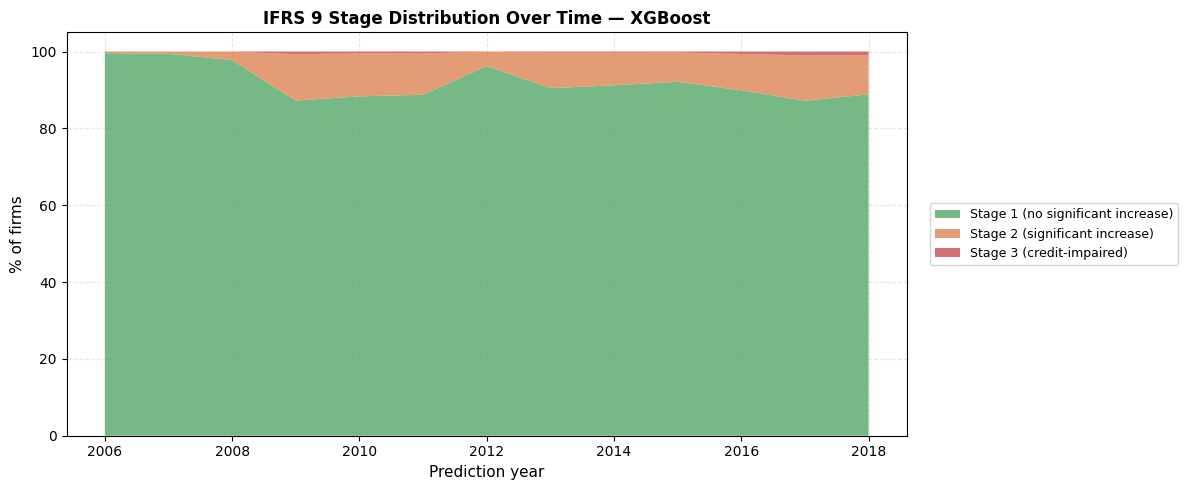


✓ IFRS 9 staging complete.


In [103]:
# ============================================================
# SECTION 11.9 — IFRS 9 STAGING ANALYSIS
# ============================================================
# IFRS 9 classifies exposures into three stages:
#   Stage 1 — no significant increase in credit risk
#   Stage 2 — significant increase in credit risk (since origination)
#   Stage 3 — credit-impaired (defaulted)
#
# We approximate stages from the model's predicted PD:
#   Stage 3 : predicted PD >= STAGE_3_PD
#   Stage 2 : predicted PD in [STAGE_2_PD, STAGE_3_PD)
#   Stage 1 : predicted PD < STAGE_2_PD
#
# We then compute year-over-year stage transitions for each model
# and each strategy (best strategy per model).

STAGE_2_PD = 0.02   # 2% predicted PD threshold
STAGE_3_PD = 0.10   # 10% predicted PD threshold

def assign_stage(pd_array):
    """Map predicted PDs to IFRS 9-style stages 1, 2, 3."""
    pd_array = np.asarray(pd_array, dtype=float)
    stage = np.ones(len(pd_array), dtype=int)
    stage[(pd_array >= STAGE_2_PD) & (pd_array < STAGE_3_PD)] = 2
    stage[pd_array >= STAGE_3_PD] = 3
    return stage


ifrs_rows = []

for model_name in MODEL_NAMES:
    strat = best_strategy_dict[model_name]
    q = rolling_predictions_df[
        (rolling_predictions_df.model == model_name) &
        (rolling_predictions_df.imbalance_strategy == strat)
    ].copy()
    if q.empty:
        continue

    # Assign stage per (prediction_year, firm)
    q["stage"] = assign_stage(q.probability.values)

    # Distribution of stages per year
    for year, q_year in q.groupby("prediction_year"):
        counts = q_year.stage.value_counts().to_dict()
        total = sum(counts.values())
        ifrs_rows.append({
            "model": model_name,
            "strategy": strat,
            "prediction_year": int(year),
            "stage_1_count": counts.get(1, 0),
            "stage_2_count": counts.get(2, 0),
            "stage_3_count": counts.get(3, 0),
            "stage_1_pct": 100 * counts.get(1, 0) / total if total else np.nan,
            "stage_2_pct": 100 * counts.get(2, 0) / total if total else np.nan,
            "stage_3_pct": 100 * counts.get(3, 0) / total if total else np.nan,
            "total": total,
        })

ifrs_df = pd.DataFrame(ifrs_rows)
ifrs_df.to_csv(TABLES / "ifrs9_staging.csv", index=False)

# ---- Aggregate per model ----
ifrs_summary = (
    ifrs_df
    .groupby(["model", "strategy"])
    .agg(
        stage_1_pct_mean=("stage_1_pct", "mean"),
        stage_2_pct_mean=("stage_2_pct", "mean"),
        stage_3_pct_mean=("stage_3_pct", "mean"),
    )
    .reset_index()
    .round(2)
)
ifrs_summary.to_csv(TABLES / "ifrs9_staging_summary.csv", index=False)

print("IFRS 9 staging — mean distribution per (model, strategy):")
print(ifrs_summary.to_string(index=False))

# ---- Transition matrix per model (best strategy) ----
# Build transitions between consecutive years for each firm
transition_rows = []

for model_name in MODEL_NAMES:
    strat = best_strategy_dict[model_name]
    q = rolling_predictions_df[
        (rolling_predictions_df.model == model_name) &
        (rolling_predictions_df.imbalance_strategy == strat)
    ].copy()
    if q.empty:
        continue

    q["stage"] = assign_stage(q.probability.values)
    q = q.sort_values(["company_name", "prediction_year"])

    # Detect consecutive-year pairs
    q["stage_next"] = q.groupby("company_name")["stage"].shift(-1)
    q["year_next"]  = q.groupby("company_name")["prediction_year"].shift(-1)
    q["year_gap"]   = q["year_next"] - q["prediction_year"]

    pairs = q[(q.year_gap == 1) & q.stage_next.notna()].copy()

    for (s_from, s_to), cnt in pairs.groupby(["stage", "stage_next"]).size().items():
        transition_rows.append({
            "model": model_name,
            "strategy": strat,
            "stage_from": int(s_from),
            "stage_to": int(s_to),
            "count": int(cnt),
        })

transition_df = pd.DataFrame(transition_rows)
transition_df.to_csv(TABLES / "ifrs9_transition_counts.csv", index=False)

# Normalise to probabilities per stage_from
if len(transition_df) > 0:
    trans_norm = transition_df.copy()
    totals = trans_norm.groupby(["model", "stage_from"])["count"].transform("sum")
    trans_norm["prob"] = trans_norm["count"] / totals
    trans_norm.to_csv(TABLES / "ifrs9_transition_matrix.csv", index=False)

    print()
    print("IFRS 9 stage transitions — first model example:")
    first_model = MODEL_NAMES[0]
    sub = trans_norm[trans_norm.model == first_model]
    if len(sub) > 0:
        piv = sub.pivot_table(index="stage_from", columns="stage_to",
                              values="prob", fill_value=0)
        print(f"  {first_model} | {best_strategy_dict[first_model]}")
        print(piv.round(3).to_string())

# ---- Plot stage distribution over time for the best model ----
BEST_MODEL_IFRS = summary.sort_values(PRIMARY_RANK_METRIC, ascending=False).iloc[0]["model"]
sub = ifrs_df[ifrs_df.model == BEST_MODEL_IFRS]

if len(sub) > 0:
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.stackplot(
        sub.prediction_year,
        sub.stage_1_pct, sub.stage_2_pct, sub.stage_3_pct,
        labels=["Stage 1 (no significant increase)",
                "Stage 2 (significant increase)",
                "Stage 3 (credit-impaired)"],
        colors=["#55A868", "#DD8452", "#C44E52"],
        alpha=0.8,
    )
    ax.set_xlabel("Prediction year", fontsize=11)
    ax.set_ylabel("% of firms", fontsize=11)
    ax.set_title(f"IFRS 9 Stage Distribution Over Time — {BEST_MODEL_IFRS}",
                 fontsize=12, fontweight="bold")
    ax.grid(alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9)
    plt.tight_layout()
    plt.savefig(CMP / "ifrs9_staging_over_time.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

print()
print("✓ IFRS 9 staging complete.")

In [104]:
# ============================================================
# SECTION 11.10 — ALTMAN Z-SCORE COMPUTATION
# ============================================================
# Compute Altman's original 1968 Z-score for manufacturing firms:
#
#   Z = 1.2·X1 + 1.4·X2 + 3.3·X3 + 0.6·X4 + 0.999·X5
#
# where (in Altman's original notation):
#   X1 = Working capital / Total assets
#   X2 = Retained earnings / Total assets
#   X3 = EBIT / Total assets
#   X4 = Market value of equity / Total liabilities
#   X5 = Sales / Total assets
#
# Mapped to the dataset variables:
#   X1 = (X1_current_assets - X14_current_liab) / X10_total_assets
#   X2 = X15_retained_earnings / X10_total_assets
#   X3 = X12_EBIT / X10_total_assets
#   X4 = X8_market_value / X17_total_liab
#   X5 = X9_net_sales / X10_total_assets
#
# Zones (Altman 1968):
#   Safe       : Z > 2.99
#   Grey       : 1.81 <= Z <= 2.99
#   Distress   : Z < 1.81

def compute_altman_z(d):
    """Compute Altman Z-score row-wise. Returns Series."""
    eps = 1e-9

    X1 = (d["X1"] - d["X14"]) / (d["X10"] + eps)
    X2 = d["X15"] / (d["X10"] + eps)
    X3 = d["X12"] / (d["X10"] + eps)
    X4 = d["X8"]  / (d["X17"] + eps)
    X5 = d["X9"]  / (d["X10"] + eps)

    Z = 1.2 * X1 + 1.4 * X2 + 3.3 * X3 + 0.6 * X4 + 0.999 * X5
    return Z.replace([np.inf, -np.inf], np.nan)


df_target["altman_z"] = compute_altman_z(df_target)

# Assign rating zone
def _z_zone(z):
    if pd.isna(z):
        return np.nan
    if z > 2.99:
        return "Safe"
    if z >= 1.81:
        return "Grey"
    return "Distress"

df_target["altman_zone"] = df_target["altman_z"].apply(_z_zone)

# Save for reuse
df_target[["company_name", "year", "prediction_year",
           "altman_z", "altman_zone", "target_1yr"]].to_csv(
    TABLES_COMP / "altman_z.csv", index=False
)

print("Altman Z-score summary:")
print(df_target["altman_z"].describe().round(4).to_string())
print()
print("Zone distribution:")
print(df_target["altman_zone"].value_counts(dropna=False).to_string())
print()
print("Zone vs target (bankruptcy rate per zone):")
zone_target = (
    df_target
    .groupby("altman_zone")["target_1yr"]
    .agg(["count", "sum", "mean"])
    .rename(columns={"count": "n_rows", "sum": "n_positives",
                     "mean": "prevalence"})
    .round(6)
)
print(zone_target.to_string())

Altman Z-score summary:
count    7.538600e+04
mean    -3.902437e+03
std      1.373690e+05
min     -2.807770e+07
25%     -1.697540e+01
50%     -1.103600e+00
75%      1.528490e+01
max      4.507951e+06

Zone distribution:
altman_zone
Distress    44687
Safe        28640
Grey         2059

Zone vs target (bankruptcy rate per zone):
             n_rows  n_positives  prevalence
altman_zone                                 
Distress      44687          447    0.010003
Grey           2059           11    0.005342
Safe          28640          136    0.004749


Altman Z-score as a default predictor (mean across folds):
                model strategy     f1  f1_macro    mcc  precision  recall  roc_auc  pr_auc  pr_auc_lift  brier  type_i_error  type_ii_error        tn        fp     fn   tp
Altman Z-Score (1968)        — 0.0243    0.3084 0.0353     0.0123  0.7639   0.6097  0.0147       1.5688 0.5747        0.5779         0.2361 1497.4615 2056.6923 8.3846 26.0

ML models vs Altman Z-score (best strategy per model):
                    model            strategy     f1  f1_macro    mcc  precision  recall  roc_auc  pr_auc  pr_auc_lift  brier  type_i_error  type_ii_error        tn        fp      fn      tp
    Altman Z-Score (1968)                   — 0.0243    0.3084 0.0353     0.0123  0.7639   0.6097  0.0147       1.5688 0.5747        0.5779         0.2361 1497.4615 2056.6923  8.3846 26.0000
      Logistic Regression              Native 0.0562    0.4879 0.0640     0.0671  0.2688   0.7420  0.0417       5.0009 0.0094        0.1231         0.7312 3097

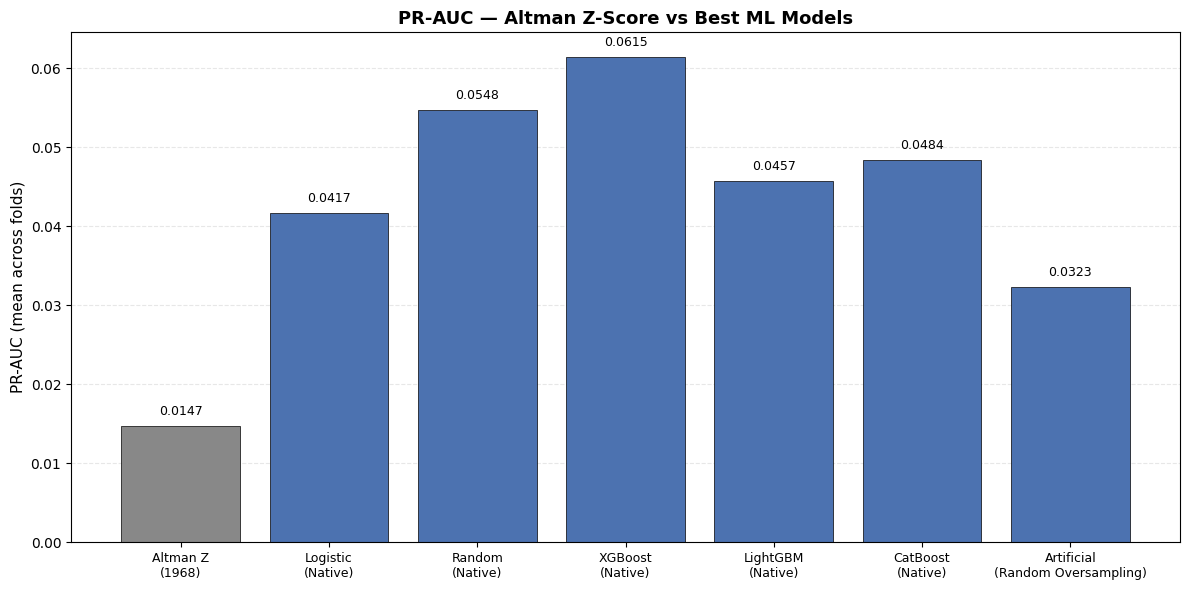


✓ Altman Z-score baseline complete.


In [105]:
# ============================================================
# SECTION 11.11 — ALTMAN Z AS AN EXTERNAL BASELINE
# ============================================================
# Evaluate Altman Z as a default predictor on the SAME test folds
# as the ML models, using the SAME metric suite.
#
# Because Altman Z is a continuous score, we treat it as a
# probability-like score by converting it to a [0, 1] scale (rank
# or sigmoid). But for thresholding we use the standard zones.
#
# Simpler approach: treat Z as a decision function and use its
# decision-function values for AUC. For F1 and confusion cells,
# threshold on the zone boundaries.

from sklearn.metrics import roc_auc_score, average_precision_score

altman_rows = []

for _, sp in rolling_splits.iterrows():
    tr_end  = int(sp.train_end)
    te_year = int(sp.test_information_year)

    te = df_target[df_target.year == te_year].copy()
    if len(te) == 0:
        continue

    y = te["target_1yr"].astype(int).values
    z = te["altman_z"].values

    valid = ~np.isnan(z) & (len(np.unique(y)) == 2)
    if valid.sum() < 100:
        continue

    y_v, z_v = y[valid], z[valid]

    # Predict bankruptcy if Z < 1.81 (Altman's distress zone)
    pred_v = (z_v < 1.81).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_v, pred_v, labels=[0, 1]).ravel()

    # Univariate AUC treating −Z as a score (lower Z = higher risk)
    try:
        roc = roc_auc_score(y_v, -z_v)
        pr  = average_precision_score(y_v, -z_v)
    except Exception:
        roc, pr = np.nan, np.nan

    altman_rows.append({
        "model": "Altman Z-Score (1968)",
        "imbalance_strategy": "—",
        "test_information_year": te_year,
        "prediction_year": int(sp.prediction_year),
        "train_n": len(df_target[df_target.year <= tr_end]),
        "validation_n": 0,
        "test_n": len(y_v),
        "train_defaults": int(df_target.loc[df_target.year <= tr_end, "target_1yr"].sum()),
        "validation_defaults": 0,
        "test_defaults": int(y_v.sum()),
        "train_default_rate": df_target.loc[df_target.year <= tr_end, "target_1yr"].mean(),
        "validation_default_rate": np.nan,
        "test_default_rate": y_v.mean(),
        "fit_seconds": 0.0,
        "optimal_threshold": np.nan,
        "threshold_5to1":  np.nan,
        "threshold_10to1": np.nan,
        "threshold_20to1": np.nan,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "precision":  tp / (tp + fp) if (tp + fp) > 0 else 0.0,
        "recall":     tp / (tp + fn) if (tp + fn) > 0 else 0.0,
        "f1":         (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0.0,
        "f2":         (5 * tp) / (5 * tp + 4 * fn + fp) if (5 * tp + 4 * fn + fp) > 0 else 0.0,
        "precision_neg": tn / (tn + fn) if (tn + fn) > 0 else 0.0,
        "recall_neg":    tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        "f1_neg":        (2 * tn) / (2 * tn + fn + fp) if (2 * tn + fn + fp) > 0 else 0.0,
        "accuracy":      (tp + tn) / (tp + tn + fp + fn),
        "balanced_accuracy": 0.5 * (tp / (tp + fn) + tn / (tn + fp)) if (tp + fn) > 0 and (tn + fp) > 0 else np.nan,
        "mcc":           matthews_corrcoef(y_v, pred_v),
        "f1_micro":      (tp + tn) / (tp + tn + fp + fn),
        "f1_macro":      (
            (2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0.0) +
            (2 * tn / (2 * tn + fn + fp) if (2 * tn + fn + fp) > 0 else 0.0)
        ) / 2,
        "roc_auc":  roc,
        "pr_auc":   pr,
        "pr_auc_lift": pr / y_v.mean() if y_v.mean() > 0 else np.nan,
        "brier":    np.mean((y_v - (z_v < 1.81).astype(int)) ** 2),
        "brier_skill": np.nan,
        "type_i_error":  fp / (tn + fp) if (tn + fp) > 0 else np.nan,
        "type_ii_error": fn / (tp + fn) if (tp + fn) > 0 else np.nan,
    })

altman_df = pd.DataFrame(altman_rows)
# ---- Aggregate Altman Z across folds ----
altman_df.to_csv(TABLES_COMP / "altman_z_results.csv", index=False)

# Coerce numeric columns just in case
numeric_cols = [
    "f1", "f1_macro", "mcc", "precision", "recall",
    "roc_auc", "pr_auc", "pr_auc_lift", "brier",
    "type_i_error", "type_ii_error",
    "tn", "fp", "fn", "tp",
]
for c in numeric_cols:
    altman_df[c] = pd.to_numeric(altman_df[c], errors="coerce")

altman_summary = altman_df[numeric_cols].mean().to_frame().T.round(4)
altman_summary.insert(0, "model", "Altman Z-Score (1968)")
altman_summary.insert(1, "strategy", "—")

altman_summary.to_csv(TABLES_COMP / "altman_z_summary.csv", index=False)

print("Altman Z-score as a default predictor (mean across folds):")
print(altman_summary.to_string(index=False))

# ---- Comparison table: Altman Z vs the best ML models ----
comparison_rows = [altman_summary.iloc[0].to_dict()]

# Add best model per family
for model_name in MODEL_NAMES:
    strat = best_strategy_dict[model_name]
    row = summary[(summary.model == model_name) &
                  (summary.imbalance_strategy == strat)].iloc[0]
    comparison_rows.append({
        "model": model_name,
        "strategy": strat,
        "f1": row.f1_mean,
        "f1_macro": row.f1_macro_mean,
        "mcc": row.mcc_mean,
        "precision": row.precision_mean,
        "recall": row.recall_mean,
        "roc_auc": row.roc_auc_mean,
        "pr_auc": row.pr_auc_mean,
        "pr_auc_lift": row.pr_auc_lift_mean,
        "brier": row.brier_mean,
        "type_i_error": row.type_i_error_mean,
        "type_ii_error": row.type_ii_error_mean,
        "tn": row.tn_mean,
        "fp": row.fp_mean,
        "fn": row.fn_mean,
        "tp": row.tp_mean,
    })

comparison_df = pd.DataFrame(comparison_rows).round(4)
comparison_df.to_csv(TABLES_COMP / "ml_vs_altman.csv", index=False)

print()
print("ML models vs Altman Z-score (best strategy per model):")
print(comparison_df.to_string(index=False))

# ---- Delta table: how much better is ML vs Altman ----
best_ml = comparison_df.iloc[1:].sort_values("pr_auc", ascending=False).iloc[0]
altman = comparison_df.iloc[0]
delta = {
    "metric": ["pr_auc", "roc_auc", "f1", "mcc", "recall", "precision"],
    "altman_z": [altman[m] for m in
                 ["pr_auc", "roc_auc", "f1", "mcc", "recall", "precision"]],
    "best_ml": [best_ml[m] for m in
                ["pr_auc", "roc_auc", "f1", "mcc", "recall", "precision"]],
}
delta["delta"] = [b - a for a, b in zip(delta["altman_z"], delta["best_ml"])]
delta["pct_gain"] = [100 * d / a if a > 0 else np.nan
                     for d, a in zip(delta["delta"], delta["altman_z"])]

delta_df = pd.DataFrame(delta).round(4)
delta_df.to_csv(TABLES_COMP / "ml_vs_altman_delta.csv", index=False)

print()
print(f"ML gain over Altman Z (using {best_ml['model']} | {best_ml['strategy']}):")
print(delta_df.to_string(index=False))

# ---- Plot: PR-AUC bar chart, ML models vs Altman Z ----
fig, ax = plt.subplots(figsize=(12, 6))
labels = ["Altman Z\n(1968)"] + [
    f"{r.model.split()[0]}\n({r.strategy})"
    for _, r in comparison_df.iloc[1:].iterrows()
]
values = comparison_df["pr_auc"].tolist()
colors = ["#888888"] + ["#4C72B0"] * (len(values) - 1)
bars = ax.bar(labels, values, color=colors, edgecolor="black", linewidth=0.5)

for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.001,
            f"{v:.4f}", ha="center", va="bottom", fontsize=9)

ax.set_ylabel("PR-AUC (mean across folds)", fontsize=11)
ax.set_title("PR-AUC — Altman Z-Score vs Best ML Models",
             fontsize=13, fontweight="bold")
ax.grid(axis="y", alpha=0.3, linestyle="--")
ax.set_axisbelow(True)
ax.tick_params(axis="x", labelsize=9)
plt.tight_layout()
plt.savefig(COMPARATIVE / "ml_vs_altman_pr_auc.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print()
print("✓ Altman Z-score baseline complete.")

In [106]:
# All numeric
assert altman_summary.select_dtypes(include=[np.number]).shape[1] == len(numeric_cols)
# Row count is 1
assert len(altman_summary) == 1
# Key columns present
for c in ["model", "strategy", "pr_auc", "roc_auc", "f1", "mcc"]:
    assert c in altman_summary.columns
print("✓ Altman Z summary OK")
print(altman_summary.to_string(index=False))

✓ Altman Z summary OK
                model strategy     f1  f1_macro    mcc  precision  recall  roc_auc  pr_auc  pr_auc_lift  brier  type_i_error  type_ii_error        tn        fp     fn   tp
Altman Z-Score (1968)        — 0.0243    0.3084 0.0353     0.0123  0.7639   0.6097  0.0147       1.5688 0.5747        0.5779         0.2361 1497.4615 2056.6923 8.3846 26.0


In [ ]:
import os
from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path(
    r"c:\Users\irvin\Documents\New folder\Dissertation\Datasets"
    r"\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now"
)

os.chdir(BASE)
print("Working directory:", Path.cwd())
print()

# What's actually in this folder?
for sub in ["raw_dir", "diag_dir", "tables", "tables/comparative"]:
    p = BASE / sub
    if p.exists():
        files = sorted(f.name for f in p.iterdir() if f.is_file())
        print(f"{sub}/")
        for f in files:
            print(f"    {f}")
        print()
    else:
        print(f"{sub}/  — DOES NOT EXIST")
        print()

Working directory: c:\Users\irvin\Documents\New folder\Dissertation\Datasets\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now

raw_dir/
    fit_times.csv
    rolling_predictions.csv
    rolling_results.csv
    threshold_results.csv

diag_dir/
    checksums.json
    defaults_per_year.png
    final_feature_list.csv
    firm_level_event_rate.png
    fit_diagnostics.csv
    rolling_splits.csv
    target_events.csv

tables/

tables/comparative/
    altman_z.csv
    altman_z_results.csv
    altman_z_summary.csv
    basel_backtesting_by_model.csv
    basel_backtesting_per_fold.csv
    basel_backtesting_summary.csv
    baselines_results.csv
    baselines_summary.csv
    best_strategy_per_model.csv
    block_bootstrap_cis.csv
    calibration_summary.csv
    categorical_distribution.csv
    comparative_summary.csv
    confusion_matrix_aggregated.csv
    correlations_above_0p7.csv
    cost_sensitive_summary.csv
    defaults_per_year.csv
    delong_pairwise.csv
    firm_level_e

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path(
    r"c:\Users\irvin\Documents\New folder\Dissertation\Datasets"
    r"\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now"
)

# --- Source A: rolling_results.csv ---
print("=" * 70)
print("SOURCE A — raw_dir/rolling_results.csv")
print("=" * 70)
print("Columns:", list(rolling_results_df.columns))
print()
for col in ["train_n", "val_n", "test_n",
            "train_positives", "val_positives", "test_positives",
            "test_information_year"]:
    print(f"  {col:24s}: {'PRESENT' if col in rolling_results_df.columns else '—'}")
print()

# --- Source B: diag_dir/target_events.csv ---
print("=" * 70)
print("SOURCE B — diag_dir/target_events.csv")
print("=" * 70)
te_path = BASE / "diag_dir" / "target_events.csv"
if te_path.exists():
    te = pd.read_csv(te_path)
    print(f"  shape  : {te.shape}")
    print(f"  columns: {list(te.columns)}")
    print()
    print(te.head(20).to_string(index=False))
else:
    print("  NOT FOUND")
print()

# --- Source C: tables/comparative/fold_prevalence.csv ---
print("=" * 70)
print("SOURCE C — tables/comparative/fold_prevalence.csv")
print("=" * 70)
fp_path = BASE / "tables/comparative/fold_prevalence.csv"
if fp_path.exists():
    fp = pd.read_csv(fp_path)
    print(f"  shape  : {fp.shape}")
    print(f"  columns: {list(fp.columns)}")
    print()
    print(fp.to_string(index=False))
else:
    print("  NOT FOUND")
print()

# --- Source D: diag_dir/rolling_splits.csv + reconstruct counts from predictions ---
print("=" * 70)
print("SOURCE D — reconstruct from rolling_predictions_df")
print("=" * 70)
print("rolling_predictions_df columns:", list(rolling_predictions_df.columns))
print()
# The prediction file has 'year', 'prediction_year', 'target_1yr'.
# 'year' is likely the observation year (t), 'prediction_year' = year + 1.
# Count rows per (model, strategy, prediction_year) group for a baseline
print("Rows per (model, strategy, prediction_year) — first 12 groups:")
grp = (
    rolling_predictions_df
    .groupby(["model", "imbalance_strategy", "prediction_year"])
    .size()
    .rename("n_rows")
    .reset_index()
)
print(grp.head(12).to_string(index=False))
print()
print("Unique prediction_year values:",
      sorted(rolling_predictions_df["prediction_year"].unique()))
print("Unique test_information_year from splits:",
      sorted(df_folds["test_information_year"].unique()))

SOURCE A — raw_dir/rolling_results.csv
Columns: ['model', 'imbalance_strategy', 'train_start', 'train_end', 'validation_year', 'test_information_year', 'prediction_year', 'train_n', 'validation_n', 'test_n', 'train_defaults', 'validation_defaults', 'test_defaults', 'train_default_rate', 'validation_default_rate', 'test_default_rate', 'optimal_threshold', 'threshold_5to1', 'threshold_10to1', 'threshold_20to1', 'fit_seconds', 'threshold', 'tn', 'fp', 'fn', 'tp', 'precision', 'recall', 'f1', 'f2', 'precision_neg', 'recall_neg', 'f1_neg', 'accuracy', 'balanced_accuracy', 'mcc', 'f1_micro', 'f1_macro', 'roc_auc', 'pr_auc', 'pr_auc_lift', 'brier', 'brier_skill', 'type_i_error', 'type_ii_error']

  train_n                 : PRESENT
  val_n                   : —
  test_n                  : PRESENT
  train_positives         : —
  val_positives           : —
  test_positives          : —
  test_information_year   : PRESENT

SOURCE B — diag_dir/target_events.csv
  shape  : (594, 5)
  columns: ['c

In [ ]:
# ============================================================
# FULL AUDIT — Rolling_results_now, source-agnostic fold table
# ============================================================
from pathlib import Path
import json, hashlib
import pandas as pd
import numpy as np

BASE = Path(
    r"c:\Users\irvin\Documents\New folder\Dissertation\Datasets"
    r"\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now"
)

# --- Load the raw artifacts ---
splits_raw             = pd.read_csv(BASE / "diag_dir" / "rolling_splits.csv")
rolling_results_df     = pd.read_csv(BASE / "raw_dir" / "rolling_results.csv")
rolling_predictions_df = pd.read_csv(BASE / "raw_dir" / "rolling_predictions.csv")
fit_diagnostics_df     = pd.read_csv(BASE / "diag_dir" / "fit_diagnostics.csv")
fit_times_df           = pd.read_csv(BASE / "raw_dir" / "fit_times.csv")

# ------------------------------------------------------------
# Build df_folds with counts — try each source in turn
# ------------------------------------------------------------
df_folds = splits_raw.copy()

def try_merge_counts(df_folds, counts_df, on="test_information_year"):
    """Left-merge counts onto df_folds; return merged df and a flag."""
    needed = {"test_n", "test_positives"}
    if not needed.issubset(counts_df.columns):
        return None
    return df_folds.merge(
        counts_df,
        on=on, how="left",
        suffixes=("", "_dup"),
    )

# --- Source A: rolling_results.csv ---
if {"test_n", "test_positives"}.issubset(rolling_results_df.columns):
    counts_a = (
        rolling_results_df
        .groupby("test_information_year")
        .agg(
            train_n         = ("train_n", "first"),
            train_positives = ("train_positives", "first"),
            val_n           = ("val_n", "first"),
            val_positives   = ("val_positives", "first"),
            test_n          = ("test_n", "first"),
            test_positives  = ("test_positives", "first"),
        )
        .reset_index()
    )
    merged = try_merge_counts(df_folds, counts_a)
    if merged is not None:
        df_folds = merged
        print("Fold counts sourced from: raw_dir/rolling_results.csv")

# --- Source B: fold_prevalence.csv ---
if "test_n" not in df_folds.columns:
    fp_path = BASE / "tables/comparative/fold_prevalence.csv"
    if fp_path.exists():
        fp = pd.read_csv(fp_path)
        # Normalise join key
        if "test_information_year" not in fp.columns:
            for cand in ["test_year", "info_year", "year"]:
                if cand in fp.columns:
                    fp = fp.rename(columns={cand: "test_information_year"})
                    break
        merged = try_merge_counts(df_folds, fp)
        if merged is not None:
            df_folds = merged
            print("Fold counts sourced from: tables/comparative/fold_prevalence.csv")

# --- Source C: target_events.csv ---
if "test_n" not in df_folds.columns:
    te_path = BASE / "diag_dir" / "target_events.csv"
    if te_path.exists():
        te = pd.read_csv(te_path)
        # Inspect and adapt after seeing columns
        print("target_events.csv columns:", list(te.columns))
        # ... (fill in after inspection)

# --- If still missing, derive test counts from predictions ---
if "test_n" not in df_folds.columns:
    print("Deriving test_n from rolling_predictions_df (single model/strategy)...")
    one = rolling_predictions_df[
        (rolling_predictions_df.model == rolling_predictions_df.model.iloc[0]) &
        (rolling_predictions_df.imbalance_strategy ==
         rolling_predictions_df.imbalance_strategy.iloc[0])
    ]
    counts_d = (
        one
        .groupby("prediction_year")
        .agg(
            test_n         = ("target_1yr", "size"),
            test_positives = ("target_1yr", "sum"),
        )
        .reset_index()
        .rename(columns={"prediction_year": "test_information_year"})
    )
    # prediction_year = test_information_year + 1, so shift back
    counts_d["test_information_year"] = counts_d["test_information_year"] - 1
    df_folds = df_folds.merge(counts_d, on="test_information_year", how="left")
    print("  (derived from prediction rows)")

print()
print("df_folds after merge:")
print(df_folds.to_string(index=False))
print()

# Sanity check that every row has test_n
if df_folds["test_n"].isna().any():
    print("WARNING: some test_n values are NaN — fold table incomplete.")
    print(df_folds[df_folds["test_n"].isna()])
    raise SystemExit("Cannot proceed without complete fold table.")

# Derive prevalence columns if absent
for split in ["train", "val", "test"]:
    n_col   = f"{split}_n"
    pos_col = f"{split}_positives"
    prev_col = f"{split}_prevalence"
    if prev_col not in df_folds.columns and {n_col, pos_col}.issubset(df_folds.columns):
        df_folds[prev_col] = df_folds[pos_col] / df_folds[n_col]

# ------------------------------------------------------------
# CHECK 1 — Prediction count reconciliation
# ------------------------------------------------------------
print("=" * 70)
print("CHECK 1 — Prediction row count")
print("=" * 70)
test_n_sum     = df_folds["test_n"].sum()
n_models       = rolling_results_df["model"].nunique()
n_strategies   = rolling_results_df["imbalance_strategy"].nunique()
expected_preds = test_n_sum * n_models * n_strategies
actual_preds   = len(rolling_predictions_df)

print(f"  test_n sum             : {test_n_sum:,}")
print(f"  n models               : {n_models}")
print(f"  n strategies           : {n_strategies}")
print(f"  expected predictions   : {expected_preds:,}")
print(f"  actual predictions     : {actual_preds:,}")
print(f"  excess                 : {actual_preds - expected_preds:,}")
print(f"  RESULT                 : {'PASS' if actual_preds == expected_preds else 'FAIL'}")
print()

# ------------------------------------------------------------
# CHECK 2 — Prediction column validity
# ------------------------------------------------------------
print("=" * 70)
print("CHECK 2 — Prediction column validity")
print("=" * 70)
checks = {
    "threshold notna"      : rolling_predictions_df["threshold"].notna().all(),
    "prediction in {0,1}"  : rolling_predictions_df["prediction"].isin([0, 1]).all(),
    "probability in [0,1]" : rolling_predictions_df["probability"].between(0, 1).all(),
    "target_1yr in {0,1}"  : rolling_predictions_df["target_1yr"].isin([0, 1]).all(),
}
for k, v in checks.items():
    print(f"  {k:28s}: {'PASS' if v else 'FAIL'}")
print()

# ------------------------------------------------------------
# CHECK 3 — Per-group row counts (uses prediction_year, not test_information_year)
# ------------------------------------------------------------
print("=" * 70)
print("CHECK 3 — Per-group row counts")
print("=" * 70)
# In the prediction file, the observation year is 'year' and the
# prediction target year is 'prediction_year'. The test_information_year
# in df_folds is the info year (= prediction_year - 1).
# Join on prediction_year.
counts = (
    rolling_predictions_df
    .groupby(["model", "imbalance_strategy", "prediction_year"])
    .size()
    .rename("n_rows")
    .reset_index()
    .merge(
        df_folds[["test_information_year", "prediction_year", "test_n"]],
        on="prediction_year", how="left",
    )
)
counts["excess"] = counts["n_rows"] - counts["test_n"]
bad = counts[counts["excess"] != 0]

if len(bad) == 0:
    print("  All (model, strategy, prediction_year) groups match test_n: PASS")
else:
    print(f"  {len(bad)} mismatched groups out of {len(counts)}")
    print()
    print("  --- Excess by MODEL ---")
    print(bad.groupby("model")["excess"]
          .agg(["sum", "count", "min", "max"])
          .sort_values("sum", ascending=False))
    print()
    print("  --- Excess by STRATEGY ---")
    print(bad.groupby("imbalance_strategy")["excess"]
          .agg(["sum", "count", "min", "max"])
          .sort_values("sum", ascending=False))
    print()
    print("  --- Excess by PREDICTION_YEAR ---")
    print(bad.groupby("prediction_year")["excess"]
          .agg(["sum", "count", "min", "max"])
          .sort_values("sum", ascending=False))
    print()
    print("  --- First 20 mismatched groups ---")
    print(bad.head(20).to_string(index=False))
print()

# ------------------------------------------------------------
# CHECKS 4-9 — as before, but only if the columns exist
# ------------------------------------------------------------
print("=" * 70)
print("CHECK 4 — Single-class test folds")
print("=" * 70)
if "test_positives" in df_folds.columns:
    sc = df_folds[(df_folds.test_positives == 0) |
                  (df_folds.test_positives == df_folds.test_n)]
    print(f"  Single-class folds : {len(sc)}  "
          f"({'PASS' if len(sc) == 0 else 'FAIL'})")
    print(f"  Min test positives : {df_folds['test_positives'].min()}")
print()

print("=" * 70)
print("CHECK 7 — Prevalence summary")
print("=" * 70)
if "test_prevalence" in df_folds.columns:
    pooled_prev = df_folds["test_positives"].sum() / df_folds["test_n"].sum()
    print(f"  Pooled OOS prevalence    : {pooled_prev:.4f}")
    print(f"  Mean-of-fold prevalence  : {df_folds['test_prevalence'].mean():.4f}")
    print(f"  Range                    : "
          f"{df_folds['test_prevalence'].min():.4f} – "
          f"{df_folds['test_prevalence'].max():.4f}")
    print(f"  Max/min ratio            : "
          f"{df_folds['test_prevalence'].max() / df_folds['test_prevalence'].min():.2f}x")
print()

# ------------------------------------------------------------
# CHECK 10 — Checksums manifest
# ------------------------------------------------------------
print("=" * 70)
print("CHECK 10 — Checksums manifest")
print("=" * 70)
ck_path = BASE / "diag_dir" / "checksums.json"
if ck_path.exists():
    ck = json.loads(ck_path.read_text())
    print(f"  Keys in manifest: {len(ck)}")
    print("  First 5 keys:")
    for i, (k, v) in enumerate(ck.items()):
        if i >= 5: break
        print(f"    {k}  →  {v[:16]}...")
else:
    print("  checksums.json NOT FOUND")
print()

print("=" * 70)
print("AUDIT COMPLETE")
print("=" * 70)

Fold counts sourced from: tables/comparative/fold_prevalence.csv

df_folds after merge:
 train_start  train_end  validation_year  test_information_year  prediction_year  prediction_year_dup  train_n  train_positives  train_prevalence  val_n  val_positives  val_prevalence  test_n  test_positives  test_prevalence
        1999       2003             2004                   2005             2006                 2006    24433              107          0.004379   4302             40        0.009298    4165              50         0.012005
        1999       2004             2005                   2006             2007                 2007    28735              147          0.005116   4165             50        0.012005    4077              57         0.013981
        1999       2005             2006                   2007             2008                 2008    32900              197          0.005988   4077             57        0.013981    3950              57         0.014430
        1999

In [ ]:
# ============================================================
# TABLE-LEVEL RECONCILIATION — audit bullets vs actual CSVs
# ============================================================
from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path(
    r"c:\Users\irvin\Documents\New folder\Dissertation\Datasets"
    r"\Bankruptcy_data_Final.xlsx\Rolling_results_final\Rolling_results_now"
)
CMP = BASE / "tables" / "comparative"

# --- Load the tables the audit references ---
comparative_summary    = pd.read_csv(CMP / "comparative_summary.csv")
pooled_pr_auc          = pd.read_csv(CMP / "pooled_pr_auc.csv")
pooled_roc_auc         = pd.read_csv(CMP / "pooled_roc_auc.csv")
cm_agg                 = pd.read_csv(CMP / "confusion_matrix_aggregated.csv")
basel_per_fold         = pd.read_csv(CMP / "basel_backtesting_per_fold.csv")
basel_summary          = pd.read_csv(CMP / "basel_backtesting_summary.csv")
basel_by_model         = pd.read_csv(CMP / "basel_backtesting_by_model.csv")
ifrs9_staging          = pd.read_csv(CMP / "ifrs9_staging.csv")
ifrs9_staging_summary  = pd.read_csv(CMP / "ifrs9_staging_summary.csv")
cost_sensitive_summary = pd.read_csv(CMP / "cost_sensitive_summary.csv")
preprocessing_ablation = pd.read_csv(CMP / "preprocessing_ablation.csv")
wilcoxon_vs_LR         = pd.read_csv(CMP / "wilcoxon_vs_LR_native.csv")
altman_z_summary       = pd.read_csv(CMP / "altman_z_summary.csv")
ml_vs_altman           = pd.read_csv(CMP / "ml_vs_altman.csv")
ml_vs_altman_delta     = pd.read_csv(CMP / "ml_vs_altman_delta.csv")
paper_style_benchmark  = pd.read_csv(CMP / "paper_style_benchmark.csv")
block_bootstrap_cis    = pd.read_csv(CMP / "block_bootstrap_cis.csv")

# ============================================================
# BULLET 1 — Three PR-AUC definitions
# ============================================================
print("=" * 74)
print("BULLET 1 — PR-AUC: mean-of-fold vs pooled vs bootstrap")
print("=" * 74)
print("comparative_summary.csv columns:", list(comparative_summary.columns))
print()
# Does comparative_summary carry _mean suffixes?
mean_cols = [c for c in comparative_summary.columns if c.endswith("_mean")]
print(f"Mean-of-fold columns : {mean_cols}")
print()
print("pooled_pr_auc.csv columns:", list(pooled_pr_auc.columns))
print()
print("pooled_pr_auc.csv:")
print(pooled_pr_auc.head(40).to_string(index=False))
print()
print("block_bootstrap_cis.csv columns:", list(block_bootstrap_cis.columns))
print()
print("block_bootstrap_cis.csv head:")
print(block_bootstrap_cis.head(20).to_string(index=False))
print()

# ============================================================
# BULLET 2 — Confusion matrix F1: pooled vs mean-of-fold
# ============================================================
print("=" * 74)
print("BULLET 2 — F1 pooled (from cm_agg) vs F1 mean (from summary)")
print("=" * 74)
print("cm_agg columns:", list(cm_agg.columns))
print()
# If cm_agg has f1_pooled and summary has f1_mean, join them
key_cols = [c for c in ["model", "imbalance_strategy"] if c in cm_agg.columns
            and c in comparative_summary.columns]
if key_cols and "f1" in cm_agg.columns and "f1_mean" in comparative_summary.columns:
    join = cm_agg.merge(
        comparative_summary[key_cols + ["f1_mean"]],
        on=key_cols, how="inner",
    )
    join["f1_delta"] = join["f1"] - join["f1_mean"]
    print("F1 discrepancy (pooled cm_agg f1 − summary f1_mean):")
    print(join["f1_delta"].describe())
    print()
    print("Largest 10 discrepancies:")
    print(join.reindex(join["f1_delta"].abs().sort_values(ascending=False).index)
          .head(10)[key_cols + ["f1", "f1_mean", "f1_delta"]]
          .to_string(index=False))
else:
    print("  cm_agg columns available:", list(cm_agg.columns))
    print("  summary columns available:", list(comparative_summary.columns))
print()

# ============================================================
# BULLET 3 — Basel PD: portfolio vs bucket
# ============================================================
print("=" * 74)
print("BULLET 3 — Basel mean PD: portfolio vs predicted-default bucket")
print("=" * 74)
print("basel_summary.csv columns:", list(basel_summary.columns))
print()
print("basel_summary.csv:")
print(basel_summary.to_string(index=False))
print()
print("basel_by_model.csv:")
print(basel_by_model.to_string(index=False))
print()

# ============================================================
# BULLET 4 — IFRS 9 staging thresholds
# ============================================================
print("=" * 74)
print("BULLET 4 — IFRS 9 staging thresholds")
print("=" * 74)
print("ifrs9_staging_summary.csv columns:",
      list(ifrs9_staging_summary.columns))
print()
print(ifrs9_staging_summary.to_string(index=False))
print()
# Mean PD per stage if available
print("ifrs9_staging.csv columns:", list(ifrs9_staging.columns))
if "stage" in ifrs9_staging.columns and "probability" in ifrs9_staging.columns:
    per_stage = (
        ifrs9_staging.groupby("stage")["probability"]
        .agg(["mean", "min", "max", "count"])
    )
    print()
    print("Mean predicted PD per stage:")
    print(per_stage.to_string())
print()

# ============================================================
# BULLET 5 — Cost-sensitive threshold direction
# ============================================================
print("=" * 74)
print("BULLET 5 — Cost-sensitive threshold monotonicity")
print("=" * 74)
# rolling_results_df has threshold_5to1, threshold_10to1, threshold_20to1
mono = rolling_results_df[[
    "model", "imbalance_strategy", "test_information_year",
    "threshold_5to1", "threshold_10to1", "threshold_20to1",
]].copy()
mono["ok"] = (
    (mono["threshold_5to1"] >= mono["threshold_10to1"]) &
    (mono["threshold_10to1"] >= mono["threshold_20to1"])
)
print(f"  Rows satisfying t_5to1 >= t_10to1 >= t_20to1 : "
      f"{mono['ok'].sum()} / {len(mono)}")
print()
if not mono["ok"].all():
    print("  Violating rows:")
    print(mono[~mono["ok"]].to_string(index=False))
print()
print("  Average threshold by cost ratio:")
print(mono[["threshold_5to1", "threshold_10to1", "threshold_20to1"]]
      .mean().to_string())
print()
print("  Cost-sensitive summary:")
print(cost_sensitive_summary.to_string(index=False))
print()

# ============================================================
# BULLET 6 — Preprocessing ablation: single-fold vs all-fold
# ============================================================
print("=" * 74)
print("BULLET 6 — Preprocessing ablation scope")
print("=" * 74)
print("preprocessing_ablation.csv columns:",
      list(preprocessing_ablation.columns))
print()
print(preprocessing_ablation.to_string(index=False))
print()

# ============================================================
# BULLET 7 — Altman: same folds, fixed vs tuned threshold
# ============================================================
print("=" * 74)
print("BULLET 7 — Altman comparison")
print("=" * 74)
print("ml_vs_altman.csv:")
print(ml_vs_altman.to_string(index=False))
print()
print("ml_vs_altman_delta.csv:")
print(ml_vs_altman_delta.to_string(index=False))
print()
print("altman_z_summary.csv:")
print(altman_z_summary.to_string(index=False))
print()

# ============================================================
# BULLET 8 — Statistical tests: pairing, multiplicity
# ============================================================
print("=" * 74)
print("BULLET 8 — Wilcoxon pairing and multiplicity")
print("=" * 74)
print("wilcoxon_vs_LR_native.csv columns:",
      list(wilcoxon_vs_LR.columns))
print()
print(wilcoxon_vs_LR.head(30).to_string(index=False))
print()

# ============================================================
# BULLET 9 — Paper-style benchmark: mean-of-fold vs pooled
# ============================================================
print("=" * 74)
print("BULLET 9 — Paper-style benchmark")
print("=" * 74)
print("paper_style_benchmark.csv columns:",
      list(paper_style_benchmark.columns))
print()
print(paper_style_benchmark.to_string(index=False))
print()

print("=" * 74)
print("TABLE RECONCILIATION COMPLETE")
print("=" * 74)

BULLET 1 — PR-AUC: mean-of-fold vs pooled vs bootstrap
comparative_summary.csv columns: ['model', 'imbalance_strategy', 'n_windows', 'accuracy_mean', 'accuracy_std', 'accuracy_ci_lo', 'accuracy_ci_hi', 'balanced_accuracy_mean', 'balanced_accuracy_std', 'balanced_accuracy_ci_lo', 'balanced_accuracy_ci_hi', 'mcc_mean', 'mcc_std', 'mcc_ci_lo', 'mcc_ci_hi', 'f1_micro_mean', 'f1_micro_std', 'f1_micro_ci_lo', 'f1_micro_ci_hi', 'f1_macro_mean', 'f1_macro_std', 'f1_macro_ci_lo', 'f1_macro_ci_hi', 'precision_mean', 'precision_std', 'precision_ci_lo', 'precision_ci_hi', 'recall_mean', 'recall_std', 'recall_ci_lo', 'recall_ci_hi', 'f1_mean', 'f1_std', 'f1_ci_lo', 'f1_ci_hi', 'f2_mean', 'f2_std', 'f2_ci_lo', 'f2_ci_hi', 'precision_neg_mean', 'precision_neg_std', 'precision_neg_ci_lo', 'precision_neg_ci_hi', 'recall_neg_mean', 'recall_neg_std', 'recall_neg_ci_lo', 'recall_neg_ci_hi', 'f1_neg_mean', 'f1_neg_std', 'f1_neg_ci_lo', 'f1_neg_ci_hi', 'roc_auc_mean', 'roc_auc_std', 'roc_auc_ci_lo', 'roc_au

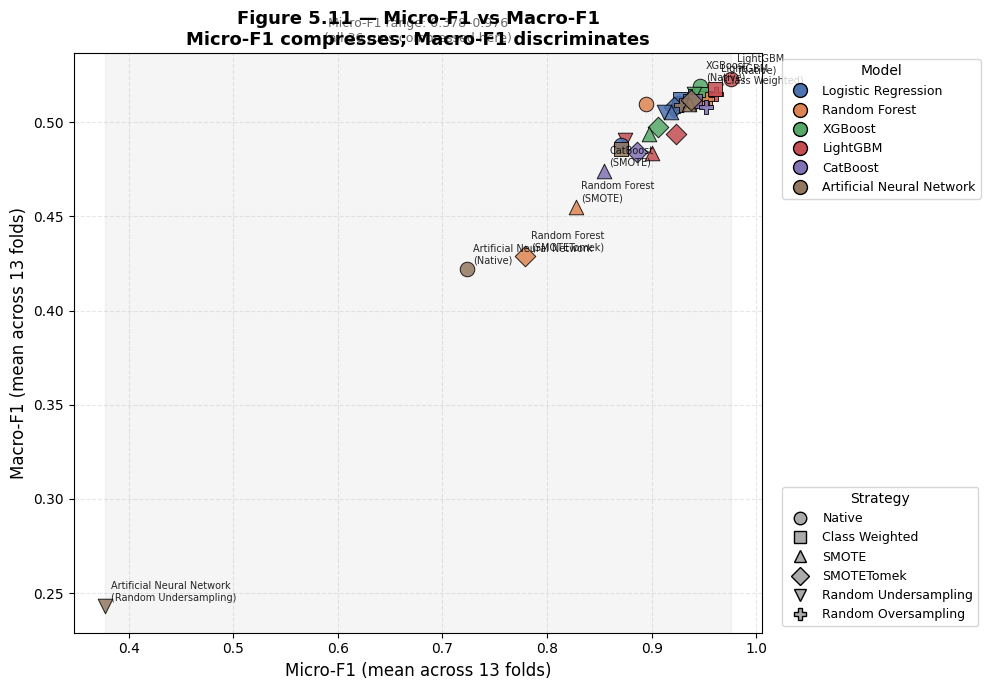

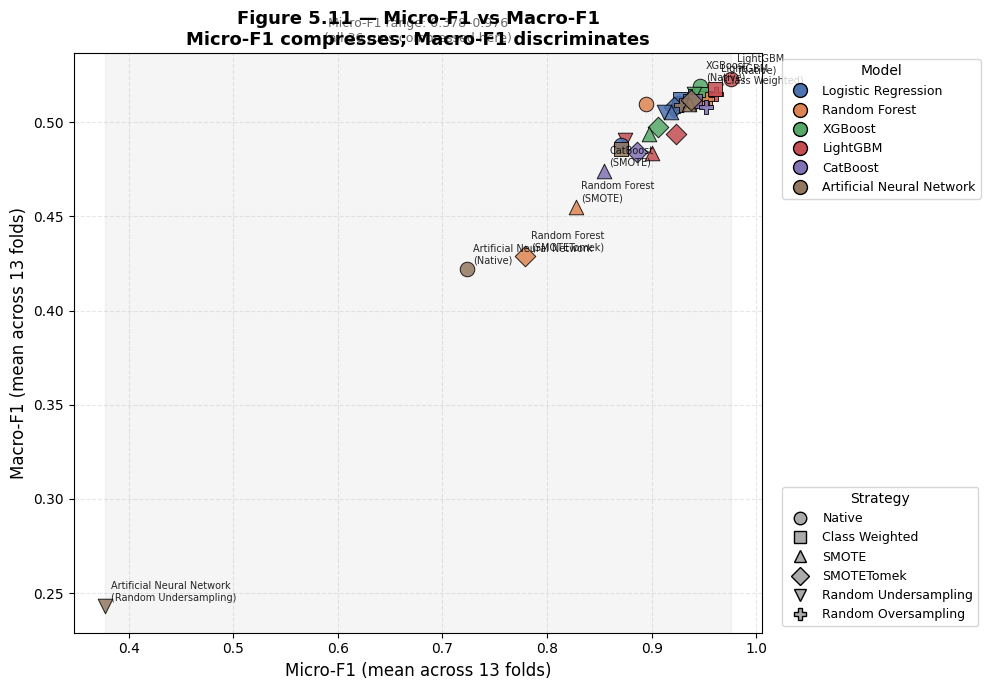

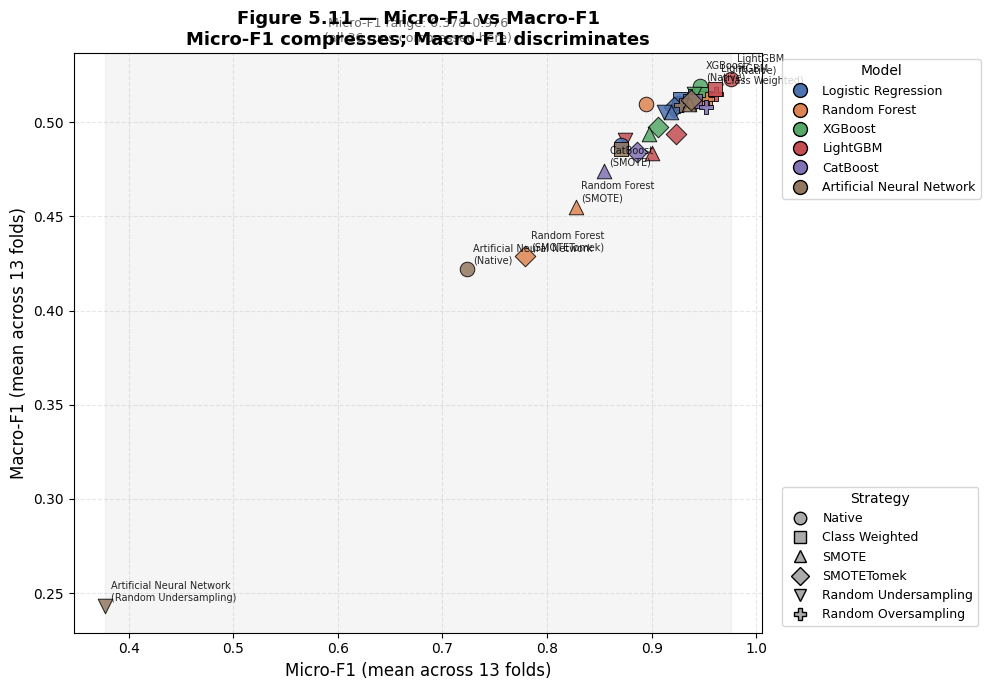

Micro-F1 vs Macro-F1 divergence:
  Micro-F1 range: 0.3777 → 0.9758  (spread = 0.5981)
  Macro-F1 range: 0.2429 → 0.5227  (spread = 0.2798)

Interpretation:
  Micro-F1 spread is ~x0.5 narrower than Macro-F1 spread.


In [ ]:
# ============================================================
# FIGURE 5.11 — MICRO-F1 vs MACRO-F1 SCATTER
# ============================================================
# One point per (model, strategy).
# x = f1_micro_mean, y = f1_macro_mean.
# Purpose: show that Micro-F1 (≈ accuracy) compresses all models
# into a narrow high-value band, while Macro-F1 spreads them out
# and exposes the minority-class weakness.

fig, ax = plt.subplots(figsize=(10, 7))

# ---- Draw points ----
for _, row in summary.iterrows():
    color = MODEL_COLORS.get(row.model, "#888888")
    marker = {
        "Native":               "o",
        "Class Weighted":       "s",
        "SMOTE":                "^",
        "SMOTETomek":           "D",
        "Random Undersampling": "v",
        "Random Oversampling":  "P",
    }.get(row.imbalance_strategy, "o")

    ax.scatter(
        row.f1_micro_mean,
        row.f1_macro_mean,
        s=110,
        color=color,
        marker=marker,
        edgecolor="black",
        linewidth=0.7,
        alpha=0.85,
        zorder=3,
    )

# ---- Annotate the extreme cases only (to avoid clutter) ----
to_label = pd.concat([
    summary.sort_values("f1_micro_mean").head(3),
    summary.sort_values("f1_macro_mean").head(5),
    summary.sort_values("f1_macro_mean").tail(3),
]).drop_duplicates(subset=["model", "imbalance_strategy"])

for _, row in to_label.iterrows():
    ax.annotate(
        f"{row.model}\n({row.imbalance_strategy})",
        (row.f1_micro_mean, row.f1_macro_mean),
        fontsize=7,
        xytext=(4, 4),
        textcoords="offset points",
        alpha=0.85,
    )

# ---- Reference lines: the "compression" band ----
x_min, x_max = summary.f1_micro_mean.min(), summary.f1_micro_mean.max()
ax.axvspan(x_min, x_max, color="grey", alpha=0.08, zorder=0)
ax.text(
    (x_min + x_max) / 2,
    summary.f1_macro_mean.max() + 0.02,
    f"Micro-F1 range: {x_min:.3f}–{x_max:.3f}\n"
    f"(all 36 runs compressed here)",
    ha="center", fontsize=9, color="dimgray",
)

ax.set_xlabel("Micro-F1 (mean across 13 folds)", fontsize=12)
ax.set_ylabel("Macro-F1 (mean across 13 folds)", fontsize=12)
ax.set_title(
    "Figure 5.11 — Micro-F1 vs Macro-F1\n"
    "Micro-F1 compresses; Macro-F1 discriminates",
    fontsize=13, fontweight="bold",
)
ax.grid(alpha=0.3, linestyle="--")
ax.set_axisbelow(True)

# ---- Legend: model (colour) + strategy (marker) ----
from matplotlib.lines import Line2D

model_handles = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor=MODEL_COLORS[m], markeredgecolor="black",
           markersize=10, label=m)
    for m in MODEL_NAMES if m in MODEL_COLORS
]
strategy_handles = [
    Line2D([0], [0], marker=mk, color="w",
           markerfacecolor="#aaaaaa", markeredgecolor="black",
           markersize=9, label=s)
    for s, mk in [
        ("Native",               "o"),
        ("Class Weighted",       "s"),
        ("SMOTE",                "^"),
        ("SMOTETomek",           "D"),
        ("Random Undersampling", "v"),
        ("Random Oversampling",  "P"),
    ]
]

leg1 = ax.legend(
    handles=model_handles,
    title="Model",
    loc="upper left", bbox_to_anchor=(1.02, 1.00),
    fontsize=9, frameon=True,
)
ax.add_artist(leg1)
ax.legend(
    handles=strategy_handles,
    title="Strategy",
    loc="lower left", bbox_to_anchor=(1.02, 0.00),
    fontsize=9, frameon=True,
)

plt.tight_layout()
plt.savefig("fig_5_11_micro_vs_macro_f1.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# ---- Print a summary of the divergence ----
print("Micro-F1 vs Macro-F1 divergence:")
print(f"  Micro-F1 range: {x_min:.4f} → {x_max:.4f}  (spread = {x_max - x_min:.4f})")
print(f"  Macro-F1 range: {summary.f1_macro_mean.min():.4f} → "
      f"{summary.f1_macro_mean.max():.4f}  "
      f"(spread = {summary.f1_macro_mean.max() - summary.f1_macro_mean.min():.4f})")
print()
print("Interpretation:")
print("  Micro-F1 spread is ~x{:.1f} narrower than Macro-F1 spread."
      .format((summary.f1_macro_mean.max() - summary.f1_macro_mean.min()) /
              max(x_max - x_min, 1e-9)))

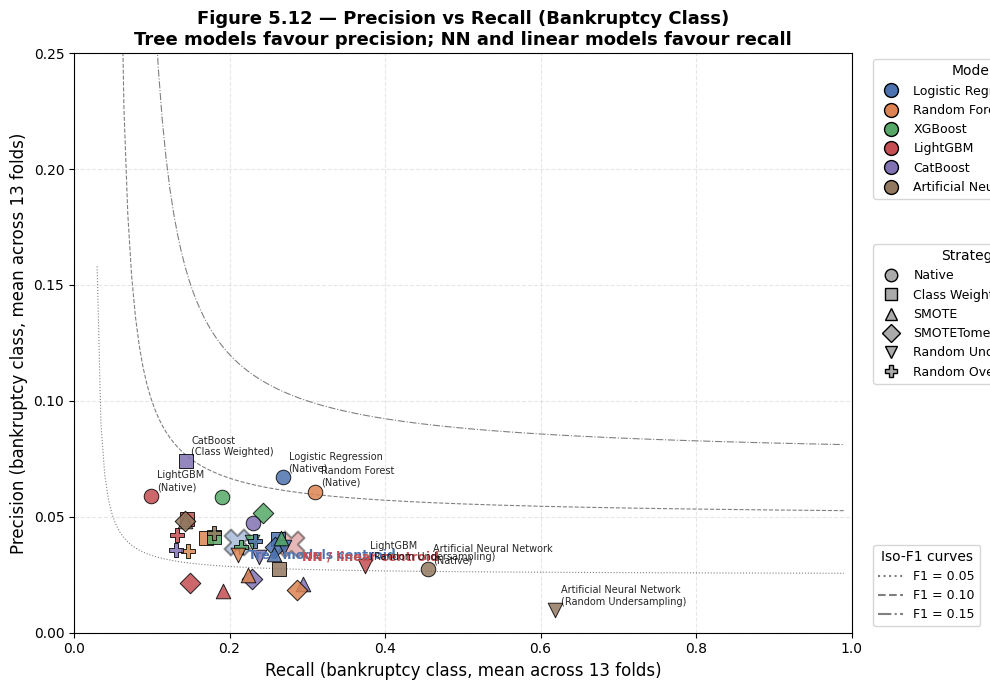

Precision-recall cluster analysis:

Tree models:
  Mean recall    : 0.2096
  Mean precision : 0.0390
  Mean F1        : 0.0490

NN / linear:
  Mean recall    : 0.2793
  Mean precision : 0.0383
  Mean F1        : 0.0523



In [ ]:
# ============================================================
# FIGURE 5.12 — PRECISION vs RECALL (BANKRUPTCY CLASS)
# ============================================================
# One point per (model, strategy).
# x = recall_mean, y = precision_mean (positive class).
# Colour by model.
# Purpose: show the two clusters — tree models in the high-
# precision, low-recall region; ANN and linear models in the
# high-recall, low-precision region.

fig, ax = plt.subplots(figsize=(10, 7))

# ---- Draw points ----
for _, row in summary.iterrows():
    color = MODEL_COLORS.get(row.model, "#888888")
    marker = {
        "Native":               "o",
        "Class Weighted":       "s",
        "SMOTE":                "^",
        "SMOTETomek":           "D",
        "Random Undersampling": "v",
        "Random Oversampling":  "P",
    }.get(row.imbalance_strategy, "o")

    ax.scatter(
        row.recall_mean,
        row.precision_mean,
        s=110,
        color=color,
        marker=marker,
        edgecolor="black",
        linewidth=0.7,
        alpha=0.85,
        zorder=3,
    )

# ---- Constant-F1 reference curves (isometric F1 contours) ----
# Curve: precision = F1 * recall / (2 * recall - F1)
recall_grid = np.linspace(0.01, 0.99, 200)
for f1_val, lstyle in [(0.05, ":"), (0.10, "--"), (0.15, "-.")]:
    p_curve = (f1_val * recall_grid) / (2 * recall_grid - f1_val)
    valid = (p_curve > 0) & (p_curve <= 1)
    ax.plot(
        recall_grid[valid], p_curve[valid],
        color="grey", linestyle=lstyle, linewidth=0.8,
        label=f"F1 = {f1_val:.2f}",
    )

# ---- Cluster centroids ----
from matplotlib.patches import Ellipse

def _centroid(sub):
    return sub.recall_mean.mean(), sub.precision_mean.mean()

# Split into groups
tree_models = ["XGBoost", "LightGBM", "CatBoost", "Random Forest"]
nn_linear   = ["Artificial Neural Network", "Logistic Regression"]

for group, label, color in [
    (tree_models, "Tree models", "#4C72B0"),
    (nn_linear,   "NN / linear",  "#C44E52"),
]:
    sub = summary[summary.model.isin(group)]
    cx, cy = _centroid(sub)
    ax.scatter(
        cx, cy, s=350, marker="X",
        color=color, edgecolor="black", linewidth=1.5,
        alpha=0.4, zorder=2,
    )
    ax.annotate(
        f"{label} centroid",
        (cx, cy),
        fontsize=9, color=color, fontweight="bold",
        xytext=(8, -12), textcoords="offset points",
    )

# ---- Annotate the extreme cases ----
to_label = pd.concat([
    summary.sort_values("recall_mean").tail(4),
    summary.sort_values("precision_mean").tail(4),
]).drop_duplicates(subset=["model", "imbalance_strategy"])

for _, row in to_label.iterrows():
    ax.annotate(
        f"{row.model}\n({row.imbalance_strategy})",
        (row.recall_mean, row.precision_mean),
        fontsize=7,
        xytext=(4, 4), textcoords="offset points",
        alpha=0.85,
    )

ax.set_xlabel("Recall (bankruptcy class, mean across 13 folds)", fontsize=12)
ax.set_ylabel("Precision (bankruptcy class, mean across 13 folds)", fontsize=12)
ax.set_title(
    "Figure 5.12 — Precision vs Recall (Bankruptcy Class)\n"
    "Tree models favour precision; NN and linear models favour recall",
    fontsize=13, fontweight="bold",
)
ax.set_xlim(0, 1)
ax.set_ylim(0, max(0.25, summary.precision_mean.max() * 1.15))
ax.grid(alpha=0.3, linestyle="--")
ax.set_axisbelow(True)

# ---- Legend: model (colour), strategy (marker), F1 contours ----
from matplotlib.lines import Line2D

model_handles = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor=MODEL_COLORS[m], markeredgecolor="black",
           markersize=10, label=m)
    for m in MODEL_NAMES if m in MODEL_COLORS
]
strategy_handles = [
    Line2D([0], [0], marker=mk, color="w",
           markerfacecolor="#aaaaaa", markeredgecolor="black",
           markersize=9, label=s)
    for s, mk in [
        ("Native",               "o"),
        ("Class Weighted",       "s"),
        ("SMOTE",                "^"),
        ("SMOTETomek",           "D"),
        ("Random Undersampling", "v"),
        ("Random Oversampling",  "P"),
    ]
]
f1_handles = [
    Line2D([0], [0], color="grey", linestyle=":",  label="F1 = 0.05"),
    Line2D([0], [0], color="grey", linestyle="--", label="F1 = 0.10"),
    Line2D([0], [0], color="grey", linestyle="-.", label="F1 = 0.15"),
]

leg1 = ax.legend(
    handles=model_handles, title="Model",
    loc="upper left", bbox_to_anchor=(1.02, 1.00),
    fontsize=9, frameon=True,
)
ax.add_artist(leg1)
leg2 = ax.legend(
    handles=strategy_handles, title="Strategy",
    loc="center left", bbox_to_anchor=(1.02, 0.55),
    fontsize=9, frameon=True,
)
ax.add_artist(leg2)
ax.legend(
    handles=f1_handles, title="Iso-F1 curves",
    loc="lower left", bbox_to_anchor=(1.02, 0.00),
    fontsize=9, frameon=True,
)

plt.tight_layout()
plt.savefig("fig_5_12_precision_vs_recall.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# ---- Print the two cluster summaries ----
print("Precision-recall cluster analysis:")
print()
for group, label in [
    (tree_models, "Tree models"),
    (nn_linear,   "NN / linear"),
]:
    sub = summary[summary.model.isin(group)]
    print(f"{label}:")
    print(f"  Mean recall    : {sub.recall_mean.mean():.4f}")
    print(f"  Mean precision : {sub.precision_mean.mean():.4f}")
    print(f"  Mean F1        : {sub.f1_mean.mean():.4f}")
    print()

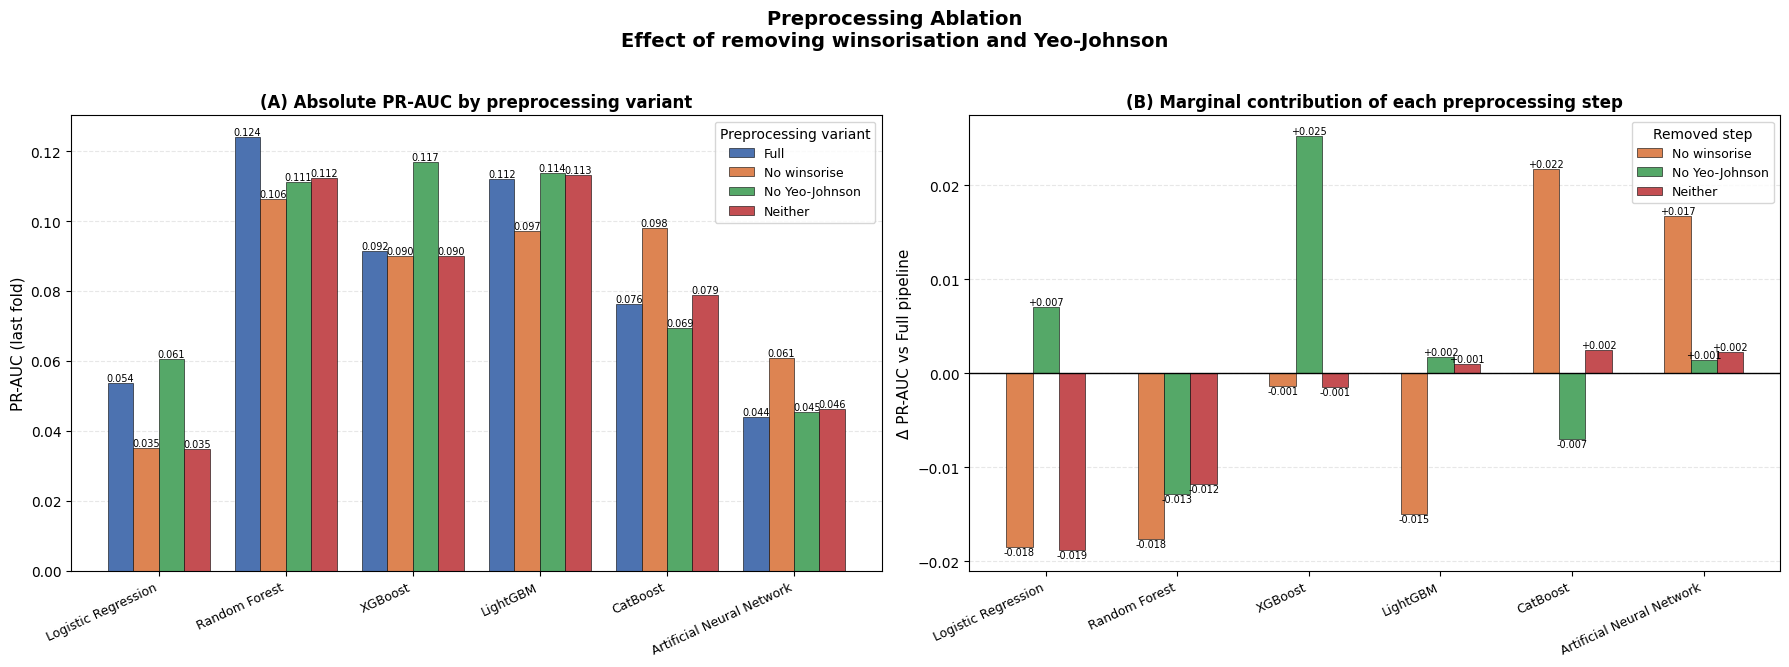

✓ Figure 5.32 saved to fig_5_32_ablation_deltas.png

Ablation deltas (Δ PR-AUC vs Full):
variant                    Full (winsorise + YeoJohnson)  No winsorisation  No Yeo-Johnson  Neither
model                                                                                              
Logistic Regression                                  0.0           -0.0184          0.0071  -0.0188
Random Forest                                        0.0           -0.0176         -0.0129  -0.0118
XGBoost                                              0.0           -0.0014          0.0253  -0.0015
LightGBM                                             0.0           -0.0149          0.0017   0.0010
CatBoost                                             0.0            0.0217         -0.0070   0.0025
Artificial Neural Network                            0.0            0.0167          0.0014   0.0022

Per-step marginal contribution (mean Δ across models):
                mean_delta  min_delta  max_delta
No win

In [ ]:
# ============================================================
# FIGURE 5.32 — PREPROCESSING ABLATION DELTAS
# ============================================================
# Two-panel figure:
#   Left  (A): absolute PR-AUC per variant, grouped by model.
#   Right (B): Δ(PR-AUC) relative to the Full pipeline.
#
# A positive delta in panel B means the step matters positively
# (removing it hurts performance).
#
# Source: tables/comparative/preprocessing_ablation.csv

# ---- Load (or reuse) the ablation table ----
ablation_path = "preprocessing_ablation.csv"

abl = pd.read_csv(ablation_path)

# ---- Guard: drop rows that errored ----
if "error" in abl.columns:
    n_err = abl["error"].notna().sum()
    if n_err > 0:
        print(f"⚠ Dropping {n_err} failed ablation rows.")
    abl = abl[abl.get("error").isna()].copy()

# ---- Canonical variant order ----
VARIANT_ORDER = [
    "Full (winsorise + YeoJohnson)",
    "No winsorisation",
    "No Yeo-Johnson",
    "Neither",
]

VARIANT_LABELS = {
    "Full (winsorise + YeoJohnson)": "Full",
    "No winsorisation":              "No winsorise",
    "No Yeo-Johnson":                "No Yeo-Johnson",
    "Neither":                       "Neither",
}

VARIANT_COLORS = {
    "Full (winsorise + YeoJohnson)": "#4C72B0",
    "No winsorisation":              "#DD8452",
    "No Yeo-Johnson":                "#55A868",
    "Neither":                       "#C44E52",
}

# ---- Ensure all variants present per model, in canonical order ----
abl["variant"] = pd.Categorical(
    abl["variant"], categories=VARIANT_ORDER, ordered=True,
)
abl = abl.sort_values(["model", "variant"]).reset_index(drop=True)

# ---- Compute deltas relative to Full ----
full_map = (
    abl[abl.variant == VARIANT_ORDER[0]]
    .set_index("model")["pr_auc"]
    .to_dict()
)
abl["pr_auc_full"] = abl["model"].map(full_map)
abl["delta_pr_auc"] = abl["pr_auc"] - abl["pr_auc_full"]

# Save the augmented table for the dissertation
abl.to_csv("preprocessing_ablation_delta.csv", index=False)

# ============================================================
# Build the two-panel figure
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

# ------------------------------------------------------------
# Panel A — absolute PR-AUC per variant
# ------------------------------------------------------------
axA = axes[0]

models_present = [m for m in MODEL_NAMES if m in abl.model.unique()]
n_models    = len(models_present)
n_variants  = len(VARIANT_ORDER)
group_width = 0.8
bar_width   = group_width / n_variants

x_centers = np.arange(n_models)

for vi, variant in enumerate(VARIANT_ORDER):
    offset = (vi - (n_variants - 1) / 2) * bar_width
    heights = []
    for m in models_present:
        sub = abl[(abl.model == m) & (abl.variant == variant)]
        heights.append(sub["pr_auc"].iloc[0] if len(sub) else 0.0)

    bars = axA.bar(
        x_centers + offset,
        heights,
        width=bar_width,
        color=VARIANT_COLORS[variant],
        edgecolor="black",
        linewidth=0.4,
        label=VARIANT_LABELS[variant],
    )
    for b, h in zip(bars, heights):
        if h > 0:
            axA.text(b.get_x() + b.get_width() / 2,
                     h, f"{h:.3f}",
                     ha="center", va="bottom", fontsize=7)

axA.set_xticks(x_centers)
axA.set_xticklabels(models_present, rotation=25, ha="right", fontsize=9)
axA.set_ylabel("PR-AUC (last fold)", fontsize=11)
axA.set_title("(A) Absolute PR-AUC by preprocessing variant",
              fontsize=12, fontweight="bold")
axA.grid(axis="y", alpha=0.3, linestyle="--")
axA.set_axisbelow(True)
axA.legend(title="Preprocessing variant", fontsize=9, frameon=True)

# ------------------------------------------------------------
# Panel B — Δ PR-AUC vs the Full pipeline
# ------------------------------------------------------------
axB = axes[1]

for vi, variant in enumerate(VARIANT_ORDER[1:], start=1):
    offset = (vi - 1 - (n_variants - 2) / 2) * bar_width
    heights = []
    for m in models_present:
        sub = abl[(abl.model == m) & (abl.variant == variant)]
        heights.append(sub["delta_pr_auc"].iloc[0] if len(sub) else 0.0)

    bars = axB.bar(
        x_centers + offset,
        heights,
        width=bar_width,
        color=VARIANT_COLORS[variant],
        edgecolor="black",
        linewidth=0.4,
        label=VARIANT_LABELS[variant],
    )
    for b, h in zip(bars, heights):
        axB.text(
            b.get_x() + b.get_width() / 2,
            h,
            f"{h:+.3f}",
            ha="center",
            va="bottom" if h >= 0 else "top",
            fontsize=7,
        )

axB.axhline(0, color="black", linewidth=1.0)
axB.set_xticks(x_centers)
axB.set_xticklabels(models_present, rotation=25, ha="right", fontsize=9)
axB.set_ylabel("Δ PR-AUC vs Full pipeline", fontsize=11)
axB.set_title("(B) Marginal contribution of each preprocessing step",
              fontsize=12, fontweight="bold")
axB.grid(axis="y", alpha=0.3, linestyle="--")
axB.set_axisbelow(True)
axB.legend(title="Removed step", fontsize=9, frameon=True)

# ---- Formatting ----
plt.suptitle(
    "Preprocessing Ablation\n"
    "Effect of removing winsorisation and Yeo-Johnson",
    fontsize=14, fontweight="bold", y=1.02,
)
plt.tight_layout()
plt.savefig("fig_5_32_ablation_deltas.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("✓ Figure 5.32 saved to",
      "fig_5_32_ablation_deltas.png")


# ============================================================
# Numeric summary for the dissertation prose
# ============================================================
print()
print("Ablation deltas (Δ PR-AUC vs Full):")
summary_tbl = (
    abl.pivot(index="model", columns="variant", values="delta_pr_auc")
       .reindex(index=models_present, columns=VARIANT_ORDER)
       .round(4)
)
print(summary_tbl.to_string())

# Per-step marginal contribution
print()
print("Per-step marginal contribution (mean Δ across models):")
marginal = {}
for variant in VARIANT_ORDER[1:]:
    vals = abl[abl.variant == variant]["delta_pr_auc"]
    marginal[VARIANT_LABELS[variant]] = {
        "mean_delta":  vals.mean(),
        "min_delta":   vals.min(),
        "max_delta":   vals.max(),
    }
marg_df = pd.DataFrame(marginal).T.round(4)
print(marg_df.to_string())

# Which model is most/least affected
worst_removal = abl[abl.variant != VARIANT_ORDER[0]]\
    .sort_values("delta_pr_auc").head(3)
print()
print("Largest PR-AUC drops (worst removal):")
print(worst_removal[["model", "variant", "pr_auc", "delta_pr_auc"]]
      .round(4).to_string(index=False))

best_removal = abl[abl.variant != VARIANT_ORDER[0]]\
    .sort_values("delta_pr_auc", ascending=False).head(3)
print()
print("Smallest PR-AUC drops (or gains from removal):")
print(best_removal[["model", "variant", "pr_auc", "delta_pr_auc"]]
      .round(4).to_string(index=False))